# London smart-meter load-profile clustering — dissertation appendix notebook

**Table of contents**

*Original pipeline:* data loading & preprocessing · K selection · algorithm comparison · ACORN · PCA · raw-profile clustering · seasonal / weekday split · consensus · grid impact · demand shifting · bimodality. Cells marked **SUPERSEDED** are retained as objects of methodological critique — see the banner above each.

*Corrected results (appended):*
- **Result A** — clustering recovers a consumption-level sort, not shape (A1, A1b, A1c); the representation determines the partition (A3, A3b–A3h); summary of evidence.
- **Result B** — the demand-shifting optimum is analytic.
- **Result C / C2** — aggregation overstates coincidence; averaging destroys diversity.
- **Statistical rigour** — permutation tests, bootstrap CIs, multiple comparisons (ACORN 1a/1b, bimodality, seasonal, cluster differences).

Reproducibility: `SEED = 42` throughout; see the configuration cell below.

## Setup — read before running

**Before running this notebook, upload the dataset archive `data.zip`.**

1. Open the **Files** panel on the left (folder icon).
2. Upload `data.zip` into the working directory (`/content/`).
3. Only then run the cells below, from top to bottom.

The notebook expects `data.zip` to be present — if it is missing, the data-loading cells will fail.

In [1]:
# =====================================================================
# Reproducibility configuration
# =====================================================================
import os
import random
import zipfile
import numpy as np
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)  # global seed; every stochastic call also passes random_state/seed=SEED

# Unpack the bundled data if it is still zipped (Colab cannot upload folders).
if Path('data.zip').exists() and not Path('processed').exists():
    with zipfile.ZipFile('data.zip') as z:
        z.extractall('.')

if Path('processed').exists():
    DATA_PATH = '.'                                    # data next to the notebook
else:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/dissertation_data'

FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

_PKGS = ['numpy', 'pandas', 'scikit-learn', 'scipy', 'statsmodels', 'diptest',
         'tslearn', 'matplotlib', 'pyarrow']
print(f'SEED = {SEED} | DATA_PATH = {DATA_PATH} | FIG_DIR = {FIG_DIR}/')
print('Package versions (current kernel):')
for _p in _PKGS:
    try:
        print(f'  {_p}=={version(_p)}')
    except PackageNotFoundError:
        print(f'  {_p}: not installed')

SEED = 42 | DATA_PATH = . | FIG_DIR = figures/
Package versions (current kernel):
  numpy==2.1.3
  pandas==2.2.3
  scikit-learn==1.6.1
  scipy==1.16.3
  statsmodels==0.14.6
  diptest==0.11.0
  tslearn==0.9.0
  matplotlib==3.10.0
  pyarrow==18.1.0


In [2]:
import pandas as pd

profiles = pd.read_parquet(os.path.join(DATA_PATH, 'processed', 'profiles_48.parquet'))
delta_profiles = pd.read_parquet(os.path.join(DATA_PATH, 'processed', 'delta_profiles_47.parquet'))
print(f'Loaded: {profiles.shape[0]} households, {profiles.shape[1]} slots')

Loaded: 2431 households, 48 slots


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, pairwise_distances
# warnings.filterwarnings('ignore') removed for reproducibility: warnings
# are fixed at source (explicit KMeans n_init, seeds), not silenced.

def kmedoids(X, n_clusters, max_iter=100, random_state=42):
    np.random.seed(random_state)
    n = X.shape[0]
    medoid_idx = np.random.choice(n, n_clusters, replace=False)
    for _ in range(max_iter):
        distances = pairwise_distances(X, X[medoid_idx])
        labels = np.argmin(distances, axis=1)
        new_medoid_idx = np.zeros(n_clusters, dtype=int)
        for k in range(n_clusters):
            cluster_mask = labels == k
            if cluster_mask.sum() == 0:
                continue
            cluster_dists = pairwise_distances(X[cluster_mask])
            total_dists = cluster_dists.sum(axis=1)
            new_medoid_idx[k] = np.where(cluster_mask)[0][np.argmin(total_dists)]
        if np.array_equal(medoid_idx, new_medoid_idx):
            break
        medoid_idx = new_medoid_idx
    distances = pairwise_distances(X, X[medoid_idx])
    labels = np.argmin(distances, axis=1)
    return labels

print('Ready!')

Ready!


In [4]:
# Step 1: Remove outliers before clustering
# Outliers = households with extremely unusual consumption

scaler = StandardScaler()
delta_scaled = pd.DataFrame(
    scaler.fit_transform(delta_profiles),
    index=delta_profiles.index, columns=delta_profiles.columns
)

# Find outliers: households where any value is more than 4 standard deviations from mean
outlier_mask = (delta_scaled.abs() > 4).any(axis=1)
outliers = delta_scaled[outlier_mask]
clean = delta_scaled[~outlier_mask]

# Also scale raw profiles
scaler_raw = StandardScaler()
profiles_scaled = pd.DataFrame(
    scaler_raw.fit_transform(profiles),
    index=profiles.index, columns=profiles.columns
)
profiles_clean = profiles_scaled[~outlier_mask]
profiles_original_clean = profiles[~outlier_mask]  # unscaled, for plotting

print(f'Total households: {len(delta_scaled)}')
print(f'Outliers removed: {len(outliers)}')
print(f'Clean households: {len(clean)}')

Total households: 2431
Outliers removed: 293
Clean households: 2138


In [5]:
import gc

# Safe deletion — does not fail if the variable does not exist
for var in ['df', 'df_clean', 'delta_scaled', 'profiles', 'profiles_scaled', 'outlier_mask', 'outliers']:
    if var in globals():
        del globals()[var]

gc.collect()
print("Memory released")
print(f"profiles_original_clean: {profiles_original_clean.shape}")
print(f"profiles_clean: {profiles_clean.shape}")
print(f"clean (delta): {clean.shape}")

Memory released
profiles_original_clean: (2138, 48)
profiles_clean: (2138, 48)
clean (delta): (2138, 47)


> **SUPERSEDED — retained for methodological discussion.**
> Result: silhouette selects K=4 for K-Means.
> Problem: silhouette systematically rewards level separation and is not a test of cluster existence.
> Corrected in: Result A3d (gap statistic gives K=1; dip test does not reject unimodality) and A3h.

  K=2: Silhouette=0.2241
  K=3: Silhouette=0.1980
  K=4: Silhouette=0.1931
  K=5: Silhouette=0.1741
  K=6: Silhouette=0.0886
  K=7: Silhouette=0.0606
  K=8: Silhouette=0.0456
  K=9: Silhouette=0.0365
  K=10: Silhouette=0.0301


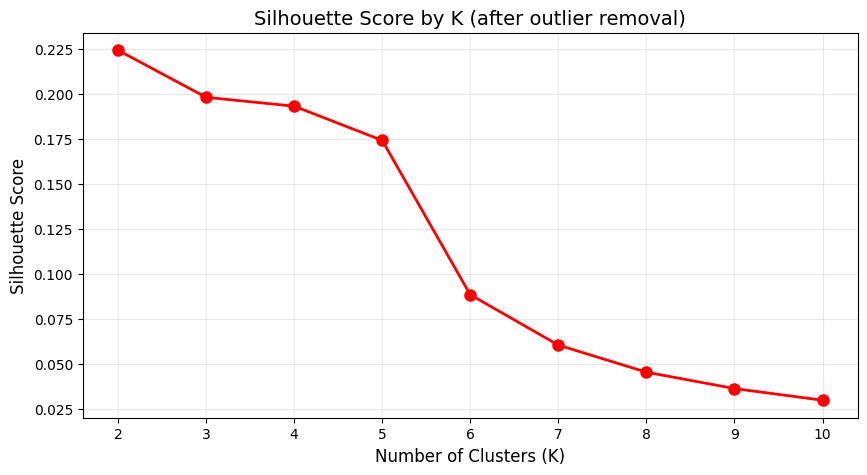

In [6]:
# Find best K on clean data
K_range = range(2, 11)
silhouettes = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(clean)
    sil = silhouette_score(clean, labels)
    silhouettes.append(sil)
    print(f'  K={k}: Silhouette={sil:.4f}')

plt.figure(figsize=(10, 5))
plt.plot(K_range, silhouettes, 'ro-', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.title('Silhouette Score by K (after outlier removal)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.show()

Using K = 4

1. K-Means done
2. K-Medoids done
3. Hierarchical done


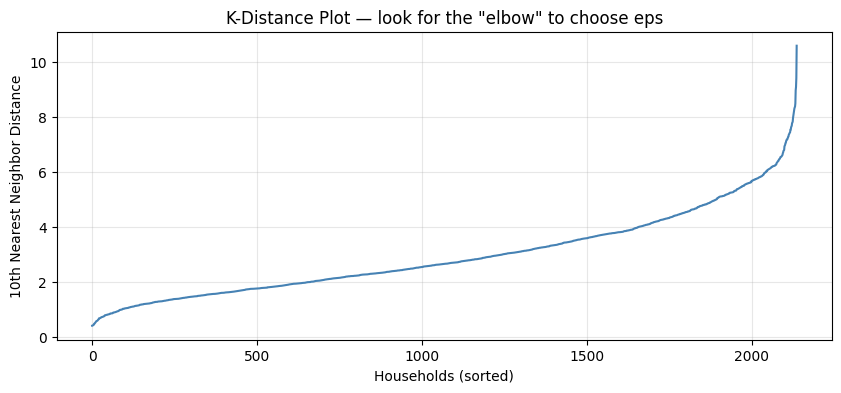

  eps=3.0: 1 clusters, 727 noise points
  eps=3.5: 1 clusters, 505 noise points
  eps=4.0: 1 clusters, 344 noise points
  eps=4.5: 1 clusters, 236 noise points
  eps=5.0: 1 clusters, 148 noise points

4. DBSCAN done — 1 clusters + 344 noise
5. GMM done

All algorithms complete!


In [7]:
K = 4  # Change if the silhouette plot suggests a different K
print(f'Using K = {K}\n')

results = {}

# 1. K-Means
results['K-Means'] = KMeans(n_clusters=K, random_state=42, n_init=10).fit_predict(clean)
print('1. K-Means done')

# 2. K-Medoids
results['K-Medoids'] = kmedoids(clean.values, n_clusters=K, random_state=42)
print('2. K-Medoids done')

# 3. Hierarchical
results['Hierarchical'] = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(clean)
print('3. Hierarchical done')

# 4. DBSCAN — tune eps using nearest neighbor distances
from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(n_neighbors=10)
nn.fit(clean)
distances, _ = nn.kneighbors(clean)
sorted_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 4))
plt.plot(sorted_distances, color='steelblue')
plt.ylabel('10th Nearest Neighbor Distance')
plt.xlabel('Households (sorted)')
plt.title('K-Distance Plot — look for the "elbow" to choose eps')
plt.grid(True, alpha=0.3)
plt.show()

# Try a few eps values
for eps in [3.0, 3.5, 4.0, 4.5, 5.0]:
    db_labels = DBSCAN(eps=eps, min_samples=10).fit_predict(clean)
    n_c = len(set(db_labels)) - (1 if -1 in db_labels else 0)
    n_noise = (db_labels == -1).sum()
    print(f'  eps={eps}: {n_c} clusters, {n_noise} noise points')

# Pick the best one (adjust eps based on output above)
db = DBSCAN(eps=4.0, min_samples=10)
results['DBSCAN'] = db.fit_predict(clean)
n_c = len(set(results['DBSCAN'])) - (1 if -1 in results['DBSCAN'] else 0)
n_noise = (results['DBSCAN'] == -1).sum()
print(f'\n4. DBSCAN done — {n_c} clusters + {n_noise} noise')

# 5. GMM
results['GMM'] = GaussianMixture(n_components=K, random_state=42, n_init=5).fit_predict(clean)
print('5. GMM done')

print('\nAll algorithms complete!')

> **SUPERSEDED — retained for methodological discussion.**
> Result: internal-index ranking of K-Means/K-Medoids/Hierarchical/GMM/DBSCAN on delta profiles.
> Problem: DBSCAN is counted as k clusters while it returns one cluster + noise; K-Medoids uses a single random init; GMM uses full covariance (unidentifiable in 48-D).
> Corrected in: Result A1b (DBSCAN noise) and A3 (GMM full vs diag, K-Medoids n_init=10).

In [8]:
print(f'{"Algorithm":<20} {"Silhouette":>12} {"Davies-Bouldin":>16} {"Calinski-Harabasz":>18} {"Clusters":>10}')
print('=' * 80)

scores = {}
for name, labels in results.items():
    if name == 'DBSCAN':
        mask = labels != -1
        if len(set(labels[mask])) < 2:
            print(f'{name:<20} {"N/A":>58}')
            continue
        data = clean[mask]
        lab = labels[mask]
    else:
        data = clean
        lab = labels

    sil = silhouette_score(data, lab)
    dbi = davies_bouldin_score(data, lab)
    chi = calinski_harabasz_score(data, lab)
    n_c = len(set(lab))
    scores[name] = {'sil': sil, 'dbi': dbi, 'chi': chi}

    print(f'{name:<20} {sil:>12.4f} {dbi:>16.4f} {chi:>18.1f} {n_c:>10}')

Algorithm              Silhouette   Davies-Bouldin  Calinski-Harabasz   Clusters
K-Means                    0.1931           2.7454              137.9          4
K-Medoids                  0.0688           3.3018              111.6          4
Hierarchical               0.0959           3.4886               87.5          4
DBSCAN                                                                      N/A
GMM                        0.0093           7.6087               31.5          4


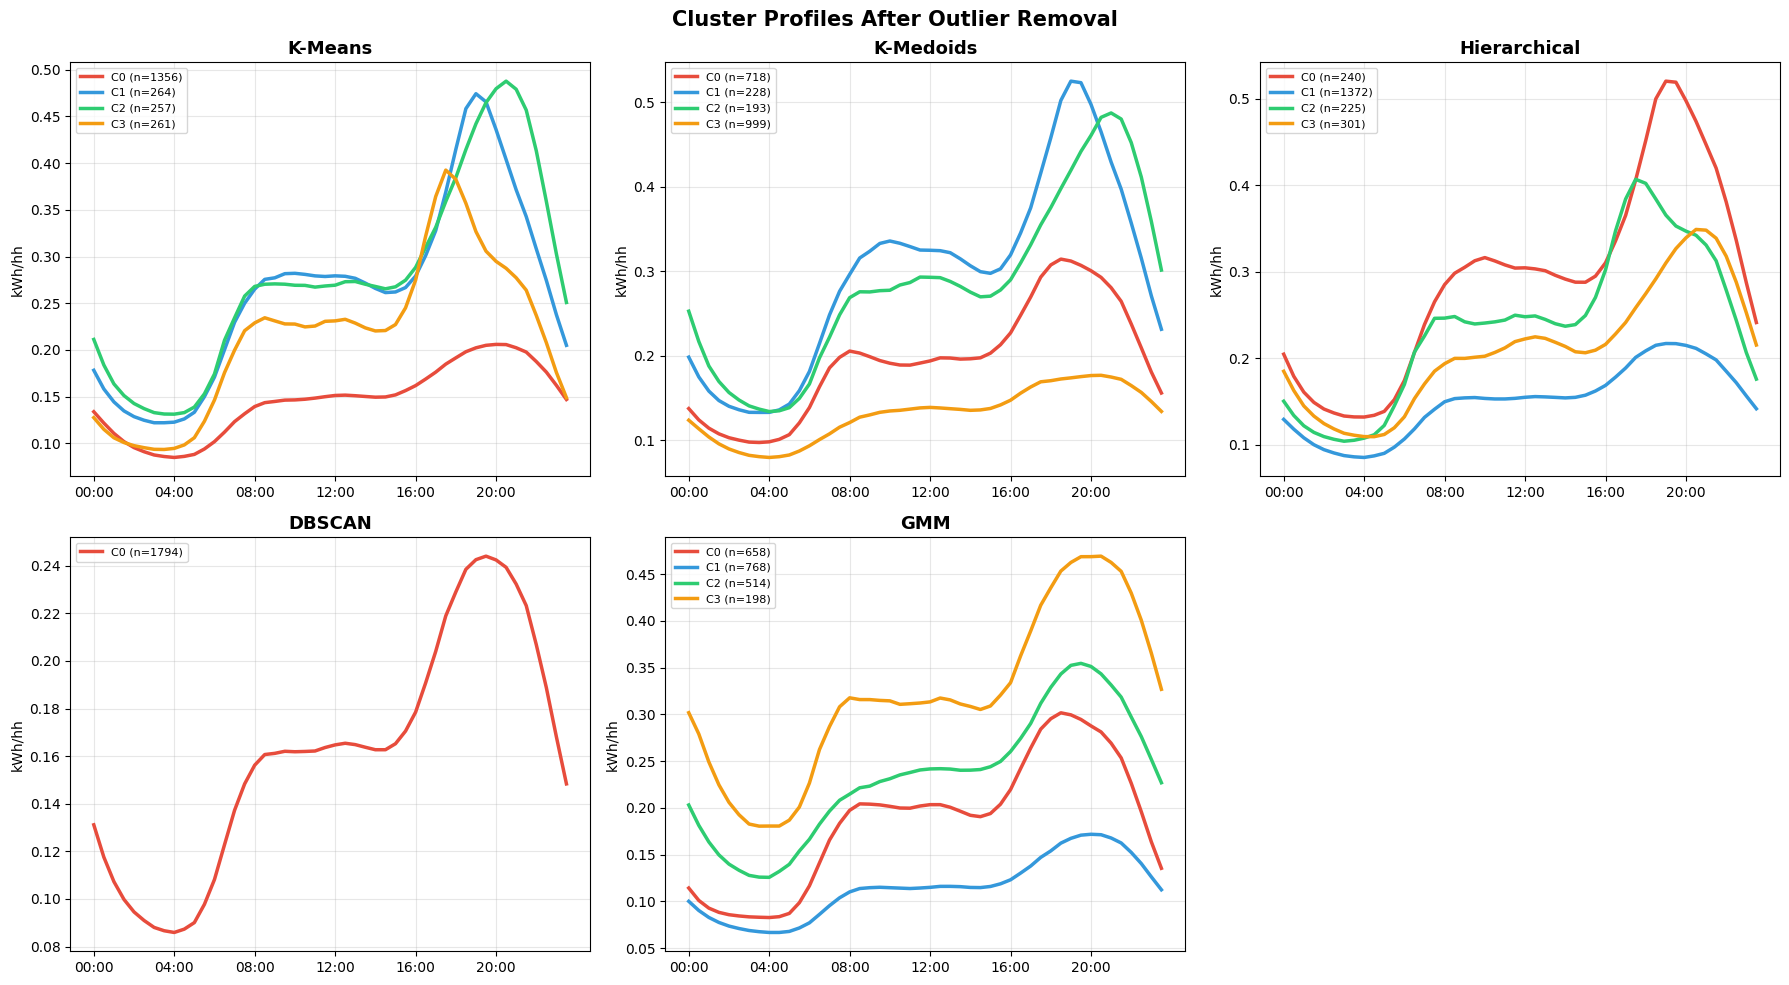

In [9]:
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c', '#e67e22']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (name, labels) in enumerate(results.items()):
    ax = axes[idx]
    unique_labels = sorted(set(labels))

    for label in unique_labels:
        if label == -1:
            continue
        mask = labels == label
        cluster_mean = profiles_original_clean.iloc[mask].mean()
        count = mask.sum()
        ax.plot(range(48), cluster_mean, color=colors[label % len(colors)],
                linewidth=2.5, label=f'C{label} (n={count})')

    ax.set_title(f'{name}', fontsize=13, fontweight='bold')
    ax.set_ylabel('kWh/hh')
    ax.set_xticks(range(0, 48, 8))
    ax.set_xticklabels([x_labels[j] for j in range(0, 48, 8)])
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

axes[5].axis('off')
plt.suptitle('Cluster Profiles After Outlier Removal', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [10]:
# Save everything
OUTPUT_PATH = Path(DATA_PATH)
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

# Save cluster labels for each algorithm
import pickle
with open(OUTPUT_PATH / 'clustering_results.pkl', 'wb') as f:
    pickle.dump(results, f)

# Save clean profiles
profiles_original_clean.to_parquet(OUTPUT_PATH / 'profiles_clean.parquet')
clean.to_parquet(OUTPUT_PATH / 'delta_clean_scaled.parquet')

print('Saved all results!')
print(f'  clustering_results.pkl — labels for all 5 algorithms')
print(f'  profiles_clean.parquet — {len(profiles_original_clean)} clean households')
print(f'  delta_clean_scaled.parquet — scaled delta profiles')

Saved all results!
  clustering_results.pkl — labels for all 5 algorithms
  profiles_clean.parquet — 2138 clean households
  delta_clean_scaled.parquet — scaled delta profiles


dtw


In [11]:
!pip install tslearn -q

In [12]:
# ============================================================
# STEP 4: DTW Experiments
# ============================================================
from tslearn.clustering import TimeSeriesKMeans
from tslearn.preprocessing import TimeSeriesScalerMeanVariance

# Prepare data for tslearn (needs 3D array: samples x timesteps x features)
delta_clean_values = clean.values
delta_3d = delta_clean_values.reshape(delta_clean_values.shape[0], delta_clean_values.shape[1], 1)

print(f'Data shape for tslearn: {delta_3d.shape}')
print(f'({delta_3d.shape[0]} households x {delta_3d.shape[1]} time steps x {delta_3d.shape[2]} feature)')
print(f'\nThis will take a few minutes — DTW is much slower than Euclidean...')

Data shape for tslearn: (2138, 47, 1)
(2138 households x 47 time steps x 1 feature)

This will take a few minutes — DTW is much slower than Euclidean...


In [13]:
K = 4

# K-Means with Euclidean (for comparison, already done but re-run with tslearn)
print('Running K-Means + Euclidean...')
km_eucl = TimeSeriesKMeans(n_clusters=K, metric='euclidean', random_state=42, n_init=5, max_iter=50)
labels_km_eucl = km_eucl.fit_predict(delta_3d)
print('  Done!')

# K-Means with DTW
print('Running K-Means + DTW (this takes a few minutes)...')
km_dtw = TimeSeriesKMeans(n_clusters=K, metric='dtw', random_state=42, n_init=3, max_iter=30)
labels_km_dtw = km_dtw.fit_predict(delta_3d)
print('  Done!')

print('\nAll DTW experiments complete!')

Running K-Means + Euclidean...
  Done!
Running K-Means + DTW (this takes a few minutes)...
  Done!

All DTW experiments complete!


In [14]:
# Soft-DTW was too slow — skip it. We already have Euclidean and DTW!
# labels_km_eucl and labels_km_dtw are already computed

dtw_results = {
    'K-Means + Euclidean': labels_km_eucl,
    'K-Means + DTW': labels_km_dtw,
}

print(f'{"Method":<25} {"Silhouette":>12} {"Davies-Bouldin":>16} {"Calinski-Harabasz":>18}')
print('=' * 75)

for name, labels in dtw_results.items():
    sil = silhouette_score(clean, labels)
    dbi = davies_bouldin_score(clean, labels)
    chi = calinski_harabasz_score(clean, labels)
    print(f'{name:<25} {sil:>12.4f} {dbi:>16.4f} {chi:>18.1f}')

Method                      Silhouette   Davies-Bouldin  Calinski-Harabasz
K-Means + Euclidean             0.1932           2.7383              137.9
K-Means + DTW                   0.0838           6.5029               60.0


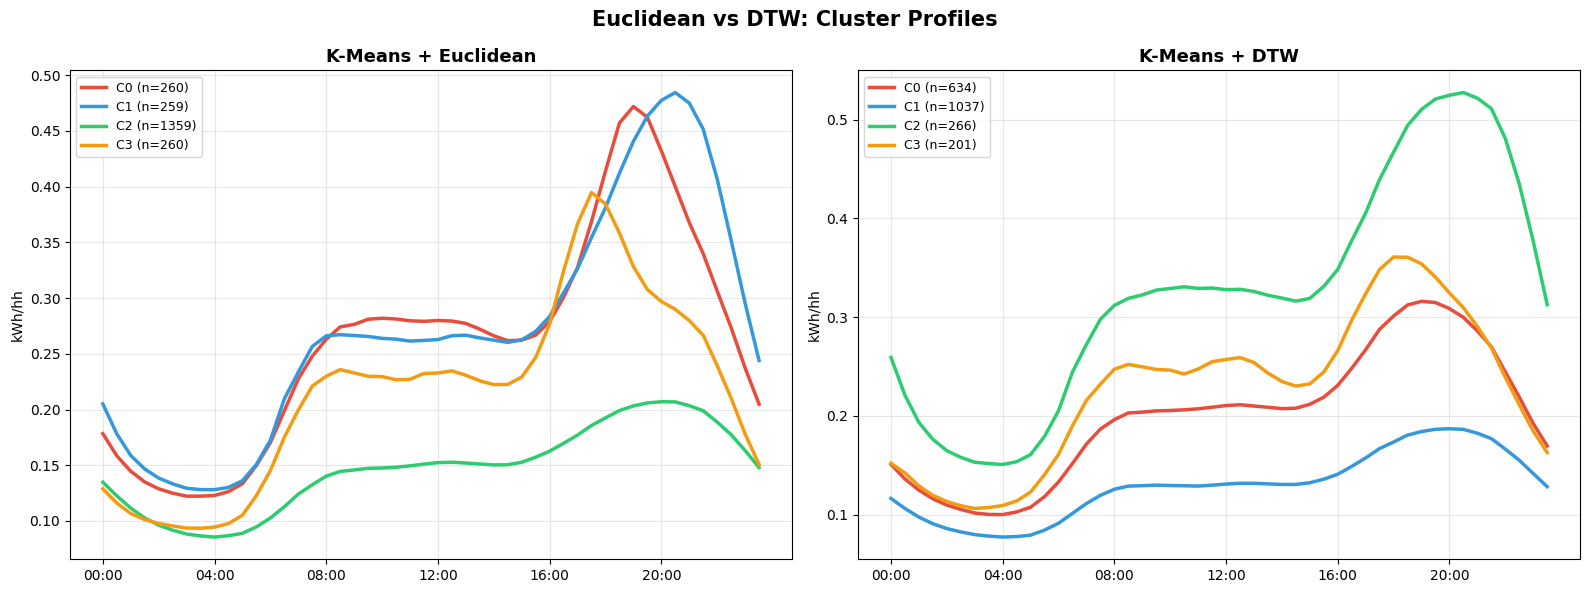

In [15]:
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, (name, labels) in enumerate(dtw_results.items()):
    ax = axes[idx]
    for label in sorted(set(labels)):
        mask = labels == label
        cluster_mean = profiles_original_clean.iloc[mask].mean()
        count = mask.sum()
        ax.plot(range(48), cluster_mean, color=colors[label % len(colors)],
                linewidth=2.5, label=f'C{label} (n={count})')
    ax.set_title(name, fontsize=13, fontweight='bold')
    ax.set_ylabel('kWh/hh')
    ax.set_xticks(range(0, 48, 8))
    ax.set_xticklabels([x_labels[j] for j in range(0, 48, 8)])
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Euclidean vs DTW: Cluster Profiles', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

> **SUPERSEDED — retained for methodological discussion.**
> Result: cluster vs ACORN with a bare ARI, read as 'no association'.
> Problem: no significance test, no effect size, and ARI is biased under unequal cluster sizes; a bare zero is not a conclusion.
> Corrected in: Statistical rigour blocks 1 and 1b (permutation test, Cramer's V, Theil's U, Kruskal-Wallis with epsilon^2).

In [16]:
# ============================================================
# STEP 5: ACORN Analysis — do clusters match real social groups?
# ============================================================

# Load household info
household_info = pd.read_csv(os.path.join(DATA_PATH, 'processed', 'household_info.csv'))

# Keep only clean households (no outliers)
hh_clean = household_info[household_info['LCLid'].isin(profiles_original_clean.index)]
print(f'Households with ACORN info: {len(hh_clean)}')
print(f'\nACORN groups:')
print(hh_clean['Acorn_grouped'].value_counts())

Households with ACORN info: 2138

ACORN groups:
Acorn_grouped
Affluent       909
Adversity      699
Comfortable    519
ACORN-U         11
Name: count, dtype: int64


In [17]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Add cluster labels to household info
hh_clean = hh_clean.set_index('LCLid')

# Align with our clean profiles
common_ids = profiles_original_clean.index.intersection(hh_clean.index)
hh_aligned = hh_clean.loc[common_ids]

# Remove households with unknown ACORN
hh_aligned = hh_aligned[hh_aligned['Acorn_grouped'] != 'ACORN-']
print(f'Households with known ACORN: {len(hh_aligned)}')

# Get cluster labels for these households (Euclidean)
eucl_labels = pd.Series(labels_km_eucl, index=profiles_original_clean.index)
eucl_aligned = eucl_labels.loc[hh_aligned.index]

# Get cluster labels (DTW)
dtw_labels = pd.Series(labels_km_dtw, index=profiles_original_clean.index)
dtw_aligned = dtw_labels.loc[hh_aligned.index]

# Encode ACORN groups as numbers
acorn_codes = hh_aligned['Acorn_grouped'].astype('category').cat.codes

# Calculate ARI and NMI
print(f'\n{"Metric":<30} {"Euclidean":>12} {"DTW":>12}')
print('=' * 56)
ari_e = adjusted_rand_score(acorn_codes, eucl_aligned)
ari_d = adjusted_rand_score(acorn_codes, dtw_aligned)
nmi_e = normalized_mutual_info_score(acorn_codes, eucl_aligned)
nmi_d = normalized_mutual_info_score(acorn_codes, dtw_aligned)
print(f'{"Adjusted Rand Index (ARI)":<30} {ari_e:>12.4f} {ari_d:>12.4f}')
print(f'{"Norm. Mutual Info (NMI)":<30} {nmi_e:>12.4f} {nmi_d:>12.4f}')
print(f'\nARI: 0 = random, 1 = perfect match')
print(f'NMI: 0 = no correlation, 1 = perfect match')

Households with known ACORN: 2138

Metric                            Euclidean          DTW
Adjusted Rand Index (ARI)            0.0063       0.0023
Norm. Mutual Info (NMI)              0.0173       0.0096

ARI: 0 = random, 1 = perfect match
NMI: 0 = no correlation, 1 = perfect match


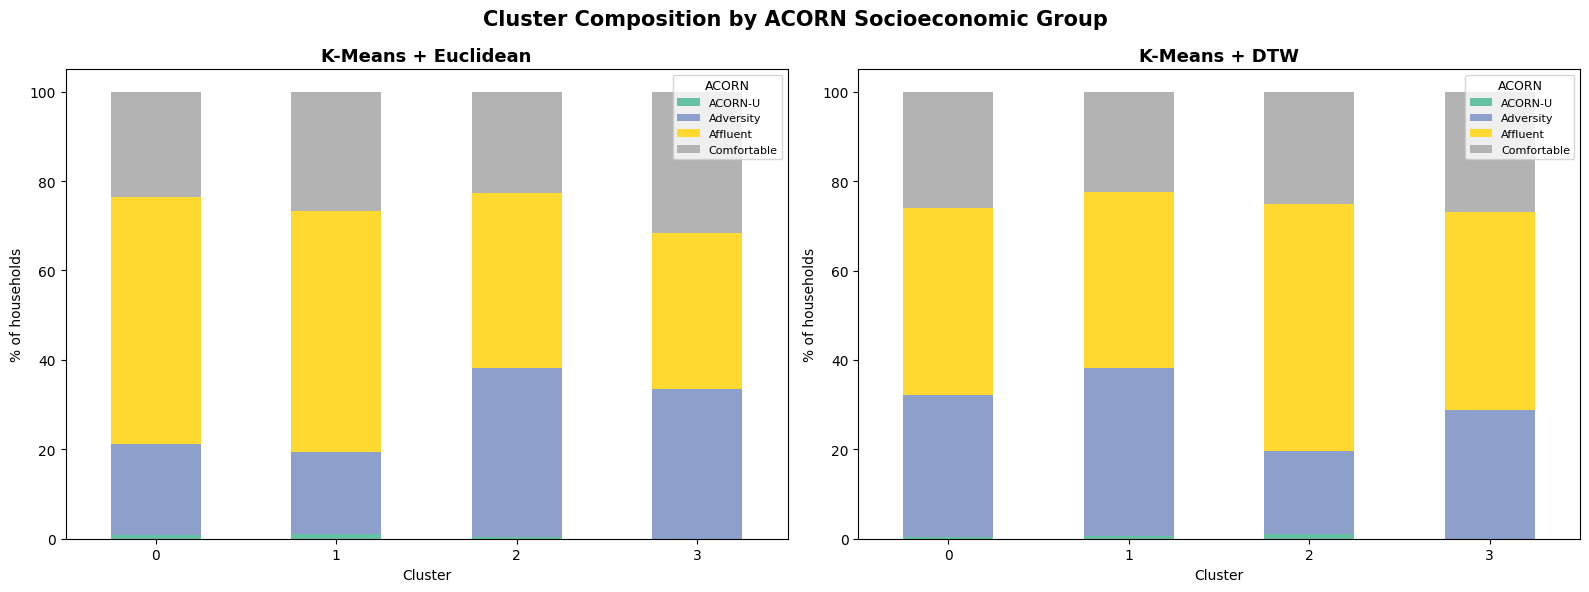

In [18]:
# Cross-tabulation: Cluster vs ACORN group
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, (name, labels_aligned) in enumerate([('Euclidean', eucl_aligned), ('DTW', dtw_aligned)]):
    ax = axes[idx]

    ct = pd.crosstab(labels_aligned, hh_aligned['Acorn_grouped'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, ax=ax, colormap='Set2', edgecolor='none')

    ax.set_title(f'K-Means + {name}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('% of households')
    ax.legend(title='ACORN', fontsize=8, title_fontsize=9)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.suptitle('Cluster Composition by ACORN Socioeconomic Group', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [19]:
# Save all final results
import pickle
OUTPUT_PATH = os.path.join(DATA_PATH, 'processed')

all_results = {
    'labels_km_eucl': labels_km_eucl,
    'labels_km_dtw': labels_km_dtw,
    'profiles_clean_index': profiles_original_clean.index.tolist(),
    'K': K,
}
with open(os.path.join(OUTPUT_PATH, 'final_results.pkl'), 'wb') as f:
    pickle.dump(all_results, f)

print('All results saved!')
print('\nExperiments DONE! Ready for writing.')

All results saved!

Experiments DONE! Ready for writing.


In [20]:
# ============================================================
# EXPERIMENT: Raw Profiles vs Delta — was Vito's advice worth it?
# ============================================================

# Cluster on RAW profiles (not delta)
km_raw = KMeans(n_clusters=K, random_state=42, n_init=10)
labels_raw = km_raw.fit_predict(profiles_clean)

# Cluster on DELTA profiles (what we've been doing)
km_delta = KMeans(n_clusters=K, random_state=42, n_init=10)
labels_delta = km_delta.fit_predict(clean)

# Compare
sil_raw = silhouette_score(profiles_clean, labels_raw)
sil_delta = silhouette_score(clean, labels_delta)
dbi_raw = davies_bouldin_score(profiles_clean, labels_raw)
dbi_delta = davies_bouldin_score(clean, labels_delta)
chi_raw = calinski_harabasz_score(profiles_clean, labels_raw)
chi_delta = calinski_harabasz_score(clean, labels_delta)

print(f'{"Representation":<20} {"Silhouette":>12} {"Davies-Bouldin":>16} {"Calinski-Harabasz":>18}')
print('=' * 70)
print(f'{"Raw Profiles":<20} {sil_raw:>12.4f} {dbi_raw:>16.4f} {chi_raw:>18.1f}')
print(f'{"Delta (change)":<20} {sil_delta:>12.4f} {dbi_delta:>16.4f} {chi_delta:>18.1f}')

Representation         Silhouette   Davies-Bouldin  Calinski-Harabasz
Raw Profiles               0.3660           1.0075             1790.7
Delta (change)             0.1931           2.7454              137.9


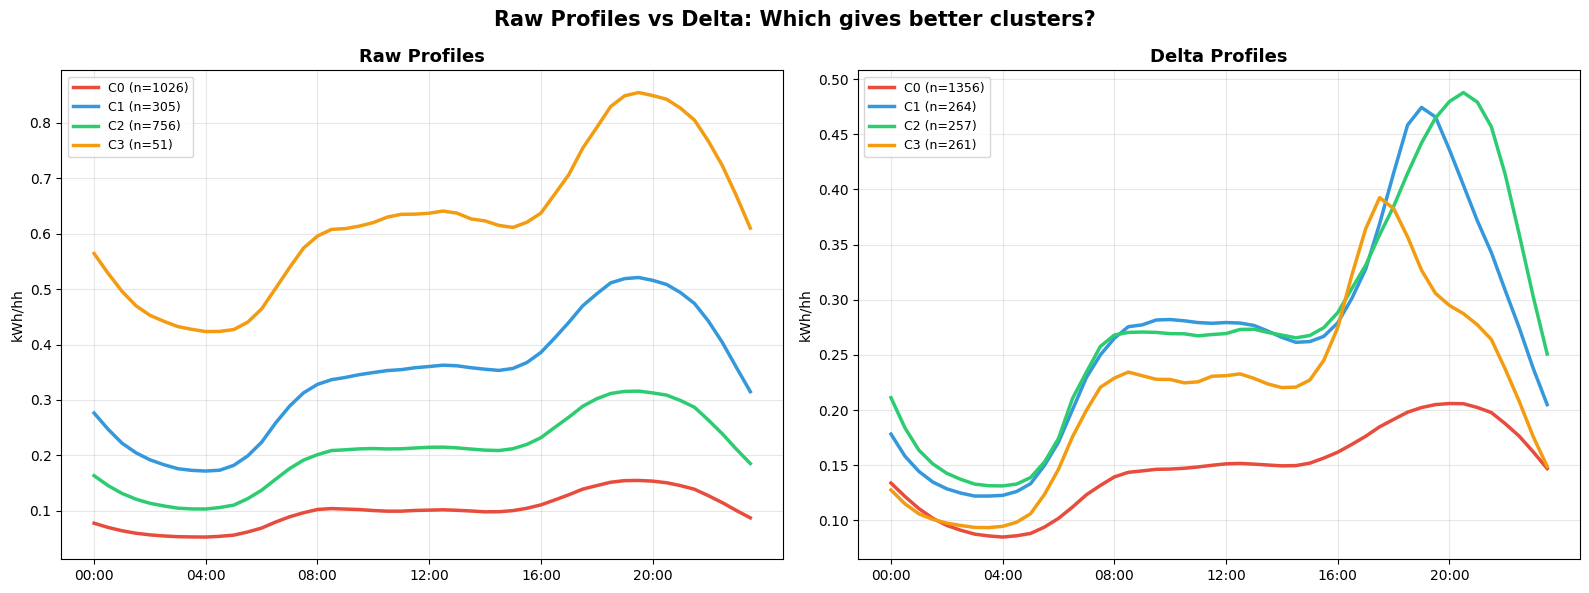

In [21]:
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, (name, labels) in enumerate([('Raw Profiles', labels_raw), ('Delta Profiles', labels_delta)]):
    ax = axes[idx]
    for label in sorted(set(labels)):
        mask = labels == label
        cluster_mean = profiles_original_clean.iloc[mask].mean()
        count = mask.sum()
        ax.plot(range(48), cluster_mean, color=colors[label % len(colors)],
                linewidth=2.5, label=f'C{label} (n={count})')
    ax.set_title(name, fontsize=13, fontweight='bold')
    ax.set_ylabel('kWh/hh')
    ax.set_xticks(range(0, 48, 8))
    ax.set_xticklabels([x_labels[j] for j in range(0, 48, 8)])
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Raw Profiles vs Delta: Which gives better clusters?', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

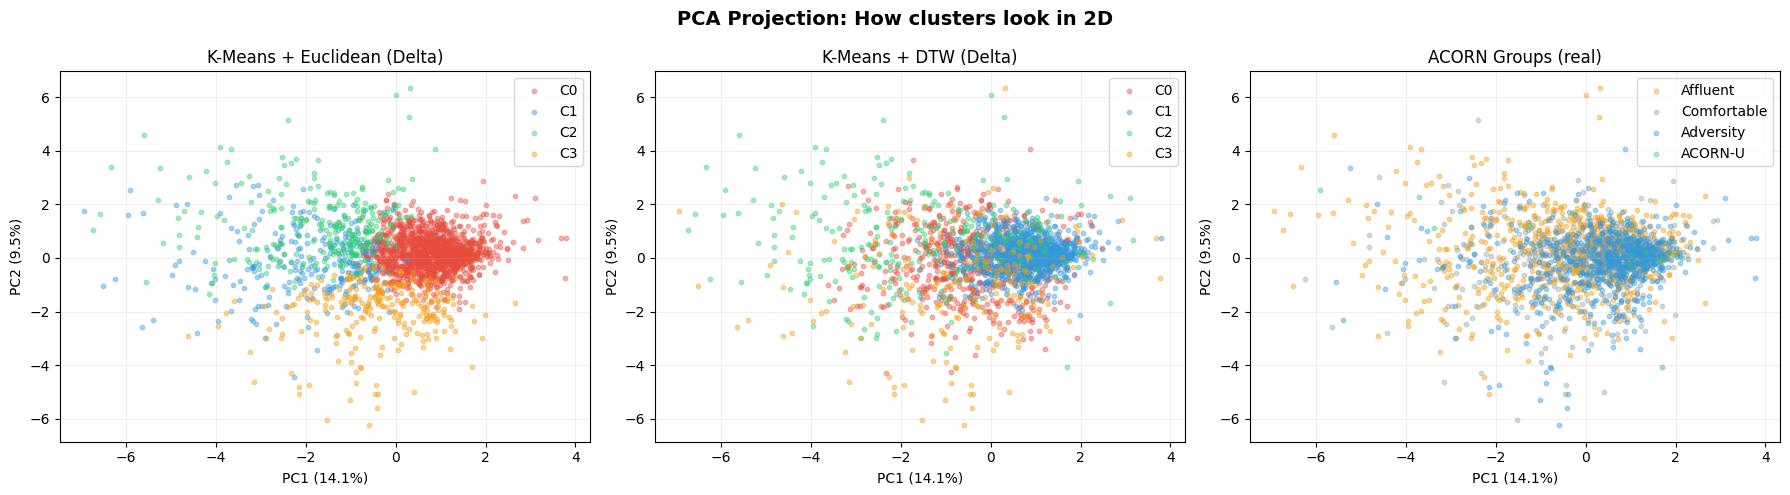

In [22]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
data_2d = pca.fit_transform(clean)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors_map = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

# K-Means Euclidean
for label in sorted(set(labels_delta)):
    mask = labels_delta == label
    axes[0].scatter(data_2d[mask, 0], data_2d[mask, 1], c=colors_map[label],
                    alpha=0.4, s=10, label=f'C{label}')
axes[0].set_title('K-Means + Euclidean (Delta)')
axes[0].legend()

# K-Means DTW
for label in sorted(set(labels_km_dtw)):
    mask = labels_km_dtw == label
    axes[1].scatter(data_2d[mask, 0], data_2d[mask, 1], c=colors_map[label % 4],
                    alpha=0.4, s=10, label=f'C{label}')
axes[1].set_title('K-Means + DTW (Delta)')
axes[1].legend()

# ACORN groups
acorn_labels = household_info.set_index('LCLid').loc[profiles_original_clean.index, 'Acorn_grouped']
acorn_colors = {'Affluent': '#f39c12', 'Comfortable': '#95a5a6', 'Adversity': '#3498db', 'ACORN-U': '#2ecc71', 'ACORN-': '#e74c3c'}
for group, color in acorn_colors.items():
    mask = acorn_labels == group
    if mask.sum() > 0:
        axes[2].scatter(data_2d[mask.values, 0], data_2d[mask.values, 1],
                        c=color, alpha=0.4, s=10, label=group)
axes[2].set_title('ACORN Groups (real)')
axes[2].legend()

for ax in axes:
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.grid(True, alpha=0.2)

plt.suptitle('PCA Projection: How clusters look in 2D', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [23]:
# Create a summary table for each cluster
cluster_stats = []

for label in sorted(set(labels_delta)):
    mask = labels_delta == label
    cluster_profiles = profiles_original_clean.iloc[mask]

    daily_mean = cluster_profiles.mean(axis=1).mean() * 48  # kWh per day
    peak_slot = cluster_profiles.mean().idxmax()
    peak_hour = f'{int(peak_slot)//2:02d}:{(int(peak_slot)%2)*30:02d}'
    peak_value = cluster_profiles.mean().max()
    min_value = cluster_profiles.mean().min()
    peak_to_min = peak_value / min_value if min_value > 0 else 0

    cluster_stats.append({
        'Cluster': f'C{label}',
        'Households': mask.sum(),
        'Avg Daily kWh': round(daily_mean, 2),
        'Peak Hour': peak_hour,
        'Peak kWh/hh': round(peak_value, 3),
        'Min kWh/hh': round(min_value, 3),
        'Peak/Min Ratio': round(peak_to_min, 2),
    })

stats_df = pd.DataFrame(cluster_stats)
print('=== Cluster Characteristics (K-Means + Euclidean on Delta) ===\n')
print(stats_df.to_string(index=False))

=== Cluster Characteristics (K-Means + Euclidean on Delta) ===

Cluster  Households  Avg Daily kWh Peak Hour  Peak kWh/hh  Min kWh/hh  Peak/Min Ratio
     C0        1356           7.00     20:00        0.206       0.085            2.43
     C1         264          12.55     19:00        0.474       0.122            3.89
     C2         257          13.23     20:30        0.488       0.131            3.72
     C3         261          10.27     17:30        0.393       0.093            4.20


In [24]:
# Save everything
OUTPUT_PATH = os.path.join(DATA_PATH, 'processed')

stats_df.to_csv(os.path.join(OUTPUT_PATH, 'cluster_characteristics.csv'), index=False)

import pickle
all_final = {
    'labels_delta_eucl': labels_delta,
    'labels_raw_eucl': labels_raw,
    'labels_km_dtw': labels_km_dtw,
    'labels_km_eucl': labels_km_eucl,
    'K': K,
    'household_ids': profiles_original_clean.index.tolist(),
}
with open(os.path.join(OUTPUT_PATH, 'all_final_results.pkl'), 'wb') as f:
    pickle.dump(all_final, f)

print('Everything saved!')
print(f'\nTotal experiments completed:')
print(f'  5 algorithms with Euclidean')
print(f'  K-Means with DTW')
print(f'  Raw vs Delta comparison')
print(f'  ACORN group analysis')
print(f'  PCA visualization')
print(f'  Cluster characteristics table')

Everything saved!

Total experiments completed:
  5 algorithms with Euclidean
  K-Means with DTW
  Raw vs Delta comparison
  ACORN group analysis
  PCA visualization
  Cluster characteristics table


  K=2: Silhouette=0.5135
  K=3: Silhouette=0.4212
  K=4: Silhouette=0.3638
  K=5: Silhouette=0.3088
  K=6: Silhouette=0.2574
  K=7: Silhouette=0.2558
  K=8: Silhouette=0.2477
  K=9: Silhouette=0.2002
  K=10: Silhouette=0.2040


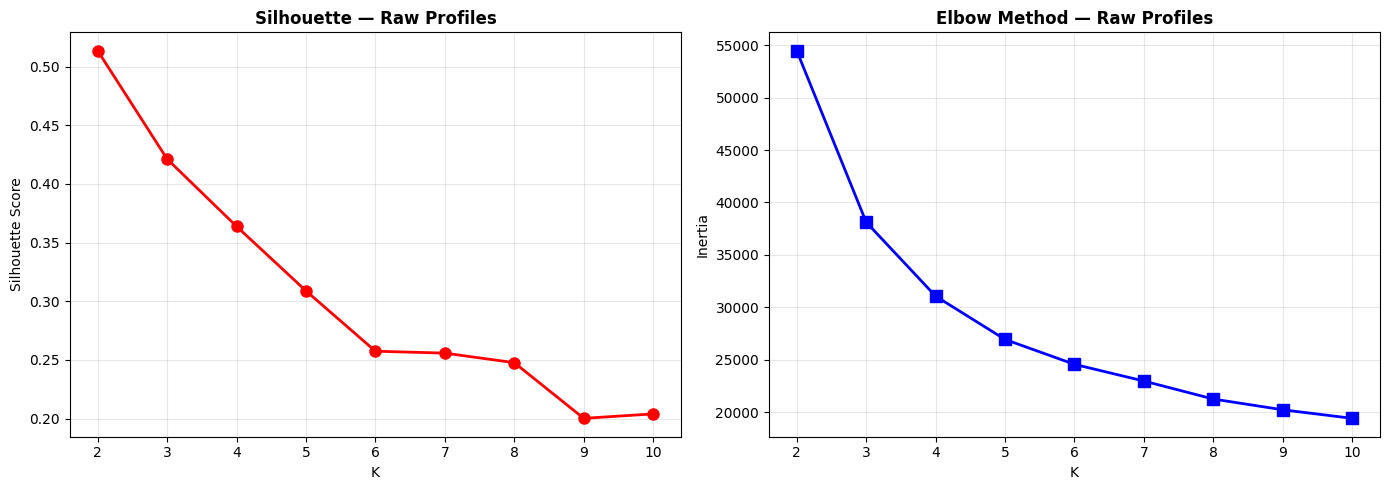

In [25]:
# ============================================================
# RAW PROFILES: Find Best K
# ============================================================
from sklearn.preprocessing import StandardScaler

scaler_raw2 = StandardScaler()
X_raw = pd.DataFrame(
    scaler_raw2.fit_transform(profiles_original_clean),
    index=profiles_original_clean.index,
    columns=profiles_original_clean.columns
)

K_range = range(2, 11)
silhouettes_raw, inertias_raw = [], []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_raw)
    sil = silhouette_score(X_raw, labels)
    silhouettes_raw.append(sil)
    inertias_raw.append(km.inertia_)
    print(f'  K={k}: Silhouette={sil:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, silhouettes_raw, 'ro-', linewidth=2, markersize=8)
axes[0].set_xlabel('K'); axes[0].set_ylabel('Silhouette Score')
axes[0].set_title('Silhouette — Raw Profiles', fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(K_range, inertias_raw, 'bs-', linewidth=2, markersize=8)
axes[1].set_xlabel('K'); axes[1].set_ylabel('Inertia')
axes[1].set_title('Elbow Method — Raw Profiles', fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:
# ============================================================
# RAW PROFILES: All Algorithms
# ============================================================
K_raw = 4  # adjust if silhouette/elbow suggests different

results_raw = {}

results_raw['K-Means'] = KMeans(n_clusters=K_raw, random_state=42, n_init=10).fit_predict(X_raw)
print('1. K-Means done')

results_raw['K-Medoids'] = kmedoids(X_raw.values, n_clusters=K_raw, random_state=42)
print('2. K-Medoids done')

results_raw['Hierarchical'] = AgglomerativeClustering(n_clusters=K_raw, linkage='ward').fit_predict(X_raw)
print('3. Hierarchical done')

results_raw['GMM'] = GaussianMixture(n_components=K_raw, random_state=42, n_init=5).fit_predict(X_raw)
print('4. GMM done')

# DBSCAN — document why it fails
print('\nDBSCAN sweep:')
for eps in [1.5, 2.0, 2.5, 3.0, 3.5]:
    db = DBSCAN(eps=eps, min_samples=10).fit_predict(X_raw)
    n_c = len(set(db)) - (1 if -1 in db else 0)
    n_noise = (db == -1).sum()
    print(f'  eps={eps}: {n_c} clusters, {n_noise} noise points')

results_raw['DBSCAN'] = DBSCAN(eps=2.5, min_samples=10).fit_predict(X_raw)
print('\nAll done!')

1. K-Means done
2. K-Medoids done
3. Hierarchical done
4. GMM done

DBSCAN sweep:
  eps=1.5: 2 clusters, 996 noise points
  eps=2.0: 1 clusters, 586 noise points
  eps=2.5: 1 clusters, 350 noise points
  eps=3.0: 1 clusters, 222 noise points
  eps=3.5: 1 clusters, 135 noise points

All done!


> **SUPERSEDED — retained for methodological discussion.**
> Result: internal-index comparison of the algorithms on raw profiles (results_raw).
> Problem: DBSCAN is one cluster + 16.4% noise; GMM is full-covariance; K-Medoids is single-init.
> Corrected in: Result A1b (DBSCAN) and A3 (GMM full vs diag, K-Medoids best-of-10).

In [27]:
# ============================================================
# RAW PROFILES: Metrics vs Delta
# ============================================================
print(f'{"Algorithm":<20} {"Silhouette":>12} {"Davies-Bouldin":>16} {"Calinski-H":>14}')
print('=' * 65)

for name, labels in results_raw.items():
    if name == 'DBSCAN':
        mask = labels != -1
        if len(set(labels[mask])) < 2:
            print(f'{name:<20} {"N/A — only 1 cluster":>42}')
            continue
        data, lab = X_raw[mask], labels[mask]
    else:
        data, lab = X_raw, labels

    sil = silhouette_score(data, lab)
    dbi = davies_bouldin_score(data, lab)
    chi = calinski_harabasz_score(data, lab)
    print(f'{name:<20} {sil:>12.4f} {dbi:>16.4f} {chi:>14.1f}')

print('\n--- Delta (previous results, for comparison) ---')
print(f'{"K-Means (delta)":<20} {"0.1931":>12} {"2.7454":>16} {"137.9":>14}')

Algorithm              Silhouette   Davies-Bouldin     Calinski-H
K-Means                    0.3638           0.9972         1638.9
K-Medoids                  0.2632           1.1468         1378.6
Hierarchical               0.3084           1.1635         1420.8
GMM                        0.0785           2.1345          572.6
DBSCAN                                     N/A — only 1 cluster

--- Delta (previous results, for comparison) ---
K-Means (delta)            0.1931           2.7454          137.9


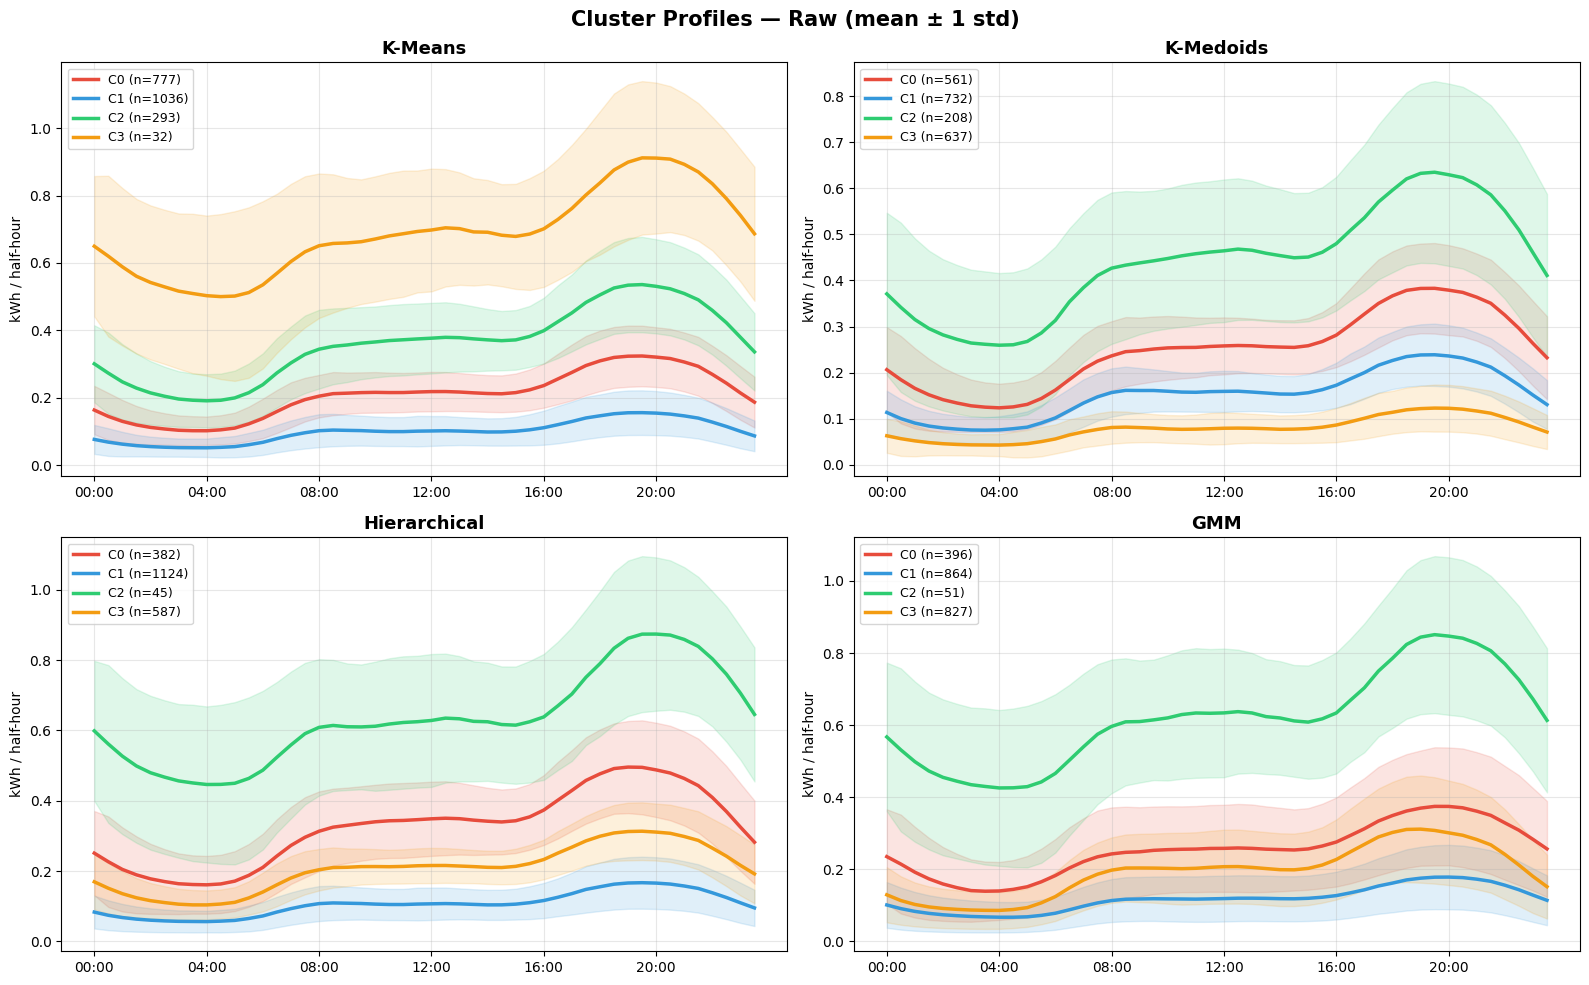

In [28]:
# ============================================================
# RAW PROFILES: Cluster Plots (mean ± 1 std)
# ============================================================
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for idx, (name, labels) in enumerate([x for x in results_raw.items() if x[0] != 'DBSCAN']):
    ax = axes[idx]
    for label in sorted(set(labels)):
        mask = labels == label
        mean = profiles_original_clean.iloc[mask].mean()
        std  = profiles_original_clean.iloc[mask].std()
        color = colors[label % len(colors)]
        ax.plot(range(48), mean, color=color, linewidth=2.5, label=f'C{label} (n={mask.sum()})')
        ax.fill_between(range(48), mean - std, mean + std, alpha=0.15, color=color)
    ax.set_title(name, fontsize=13, fontweight='bold')
    ax.set_ylabel('kWh / half-hour')
    ax.set_xticks(range(0, 48, 8))
    ax.set_xticklabels([x_labels[j] for j in range(0, 48, 8)])
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Cluster Profiles — Raw (mean ± 1 std)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [29]:
# ============================================================
# RAW PROFILES: Cluster Stats Table
# ============================================================
labels_best_raw = results_raw['K-Means']
stats = []

for label in sorted(set(labels_best_raw)):
    mask = labels_best_raw == label
    data = profiles_original_clean.iloc[mask]
    mean_profile = data.mean()
    daily_kwh = mean_profile.sum()
    peak_slot = mean_profile.idxmax()
    peak_hour = f'{int(peak_slot)//2:02d}:{(int(peak_slot)%2)*30:02d}'

    stats.append({
        'Cluster':        f'C{label}',
        'Households':     mask.sum(),
        'Avg Daily kWh':  round(daily_kwh, 2),
        'Peak Hour':      peak_hour,
        'Peak kWh/hh':    round(mean_profile.max(), 3),
        'Min kWh/hh':     round(mean_profile.min(), 3),
    })

print(pd.DataFrame(stats).to_string(index=False))

Cluster  Households  Avg Daily kWh Peak Hour  Peak kWh/hh  Min kWh/hh
     C0         777          10.05     19:30        0.324       0.103
     C1        1036           4.81     19:30        0.156       0.052
     C2         293          17.23     19:30        0.536       0.191
     C3          32          32.93     19:30        0.912       0.500


In [30]:
# ============================================================
# CROSSINGS ANALYSIS: RAW cluster mean profiles (K=4)
# Where do the (unscaled) cluster mean load curves swap order?
# profiles_original_clean = raw kWh/hh, aligned 1:1 with
# results_raw['K-Means'] labels (outliers already removed)
# ============================================================
labels_k4 = results_raw['K-Means']

cluster_means = {}
for k in sorted(set(labels_k4)):
    mask = labels_k4 == k
    cluster_means[k] = profiles_original_clean.iloc[mask].mean().values  # raw kWh/hh, 48 slots

print('Raw cluster mean profiles computed for clusters:', sorted(cluster_means.keys()))
for k in sorted(cluster_means.keys()):
    n = (labels_k4 == k).sum()
    print(f'  C{k}: n={n}, avg daily kWh={cluster_means[k].sum():.2f}')


Raw cluster mean profiles computed for clusters: [np.int32(0), np.int32(1), np.int32(2), np.int32(3)]
  C0: n=777, avg daily kWh=10.05
  C1: n=1036, avg daily kWh=4.81
  C2: n=293, avg daily kWh=17.23
  C3: n=32, avg daily kWh=32.93


In [31]:
# ------------------------------------------------------------
# Find ALL crossing points between every pair of cluster means
# ------------------------------------------------------------
from itertools import combinations

def slot_to_time(slot):
    total_min = slot * 30
    h = int(total_min // 60) % 24
    m = int(round(total_min % 60))
    return f'{h:02d}:{m:02d}'

crossings = []

for i, j in combinations(sorted(cluster_means.keys()), 2):
    d = cluster_means[i] - cluster_means[j]
    sign_change = np.diff(np.sign(d))

    for t in np.where(sign_change != 0)[0]:
        d0, d1 = d[t], d[t + 1]
        denom = abs(d0) + abs(d1)
        frac = abs(d0) / denom if denom > 0 else 0.5
        t_cross = t + frac

        val_i = cluster_means[i][t] + frac * (cluster_means[i][t + 1] - cluster_means[i][t])
        val_j = cluster_means[j][t] + frac * (cluster_means[j][t + 1] - cluster_means[j][t])

        crossings.append({
            'i': i, 'j': j,
            't_cross': t_cross,
            'time': slot_to_time(t_cross),
            'val_i': val_i, 'val_j': val_j,
            # d0 < 0 means C_i was below C_j just before t_cross, so C_i is the one rising above
            'direction': 'i_overtakes_j' if d0 < 0 else 'j_overtakes_i',
        })

crossings.sort(key=lambda c: (c['i'], c['j'], c['t_cross']))
print(f'Found {len(crossings)} crossing points across all C(4,2)=6 cluster pairs.')


Found 0 crossing points across all C(4,2)=6 cluster pairs.


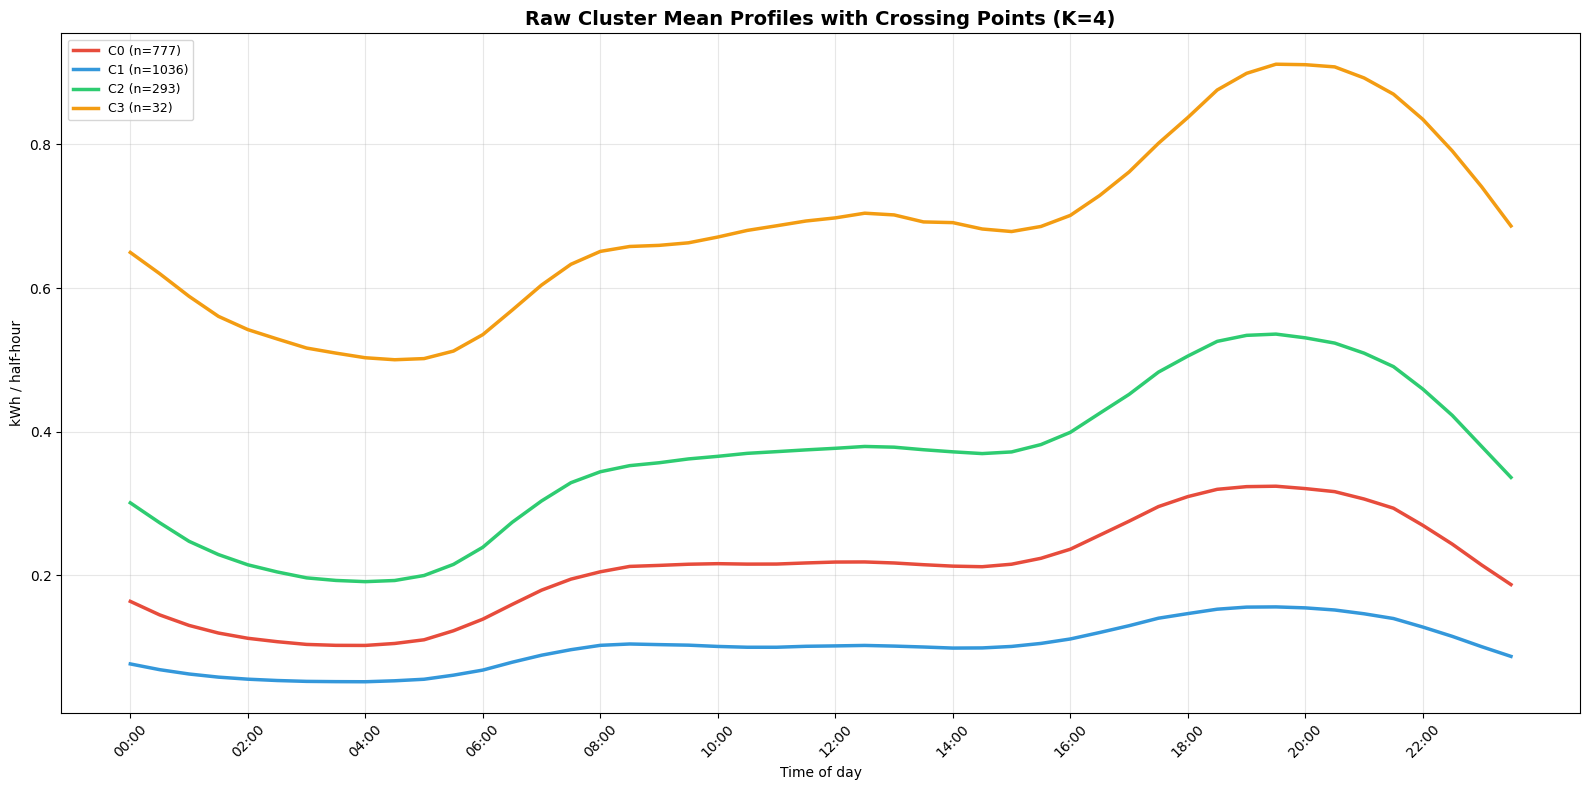

In [32]:
# ------------------------------------------------------------
# Plot: raw cluster mean profiles with crossing points marked
# ------------------------------------------------------------
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

fig, ax = plt.subplots(figsize=(16, 8))

for k in sorted(cluster_means.keys()):
    n = (labels_k4 == k).sum()
    ax.plot(range(48), cluster_means[k], color=colors[k % len(colors)],
            linewidth=2.5, label=f'C{k} (n={n})', zorder=3)

y_max = ax.get_ylim()[1]
label_y_positions = np.linspace(y_max * 0.97, y_max * 0.55, max(len(crossings), 1))

for idx, c in enumerate(crossings):
    ax.axvline(c['t_cross'], color='gray', linestyle='--', linewidth=1, alpha=0.6, zorder=1)
    ax.annotate(f"C{c['i']}\u2194C{c['j']} at {c['time']}",
                xy=(c['t_cross'], label_y_positions[idx % len(label_y_positions)]),
                xytext=(3, 0), textcoords='offset points',
                rotation=90, va='top', ha='left', fontsize=7.5, color='dimgray')

ax.set_title('Raw Cluster Mean Profiles with Crossing Points (K=4)', fontsize=14, fontweight='bold')
ax.set_ylabel('kWh / half-hour')
ax.set_xlabel('Time of day')
ax.set_xticks(range(0, 48, 4))
ax.set_xticklabels([x_labels[j] for j in range(0, 48, 4)], rotation=45)
ax.legend(fontsize=9, loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [33]:
# ------------------------------------------------------------
# Table: all crossing points
# ------------------------------------------------------------
table_rows = []
for c in crossings:
    table_rows.append({
        'Pair': f"C{c['i']}\u2194C{c['j']}",
        'Time of Crossing': c['time'],
        'C_i value at crossing': round(c['val_i'], 4),
        'C_j value at crossing': round(c['val_j'], 4),
    })

crossings_df = pd.DataFrame(table_rows)
print('=== Cluster Mean Profile Crossings (Raw, K=4) ===\n')
print(crossings_df.to_string(index=False))


=== Cluster Mean Profile Crossings (Raw, K=4) ===

Empty DataFrame
Columns: []
Index: []


In [34]:
# ------------------------------------------------------------
# Interpretation: what does each crossing mean behaviorally?
# ------------------------------------------------------------
# A crossing is the instant two clusters' typical load swaps rank order --
# the group that usually consumes less overtakes the group that usually
# consumes more (or vice versa) for that specific half-hour. Crossings
# cluster around lifestyle transition periods (waking up, commuting,
# evening peak) where different household routines shift demand at
# different times of day.

daily_avg = {k: cluster_means[k].mean() for k in cluster_means}
rank_order = sorted(daily_avg, key=daily_avg.get)  # low -> high overall consumption
rank_of = {k: r for r, k in enumerate(rank_order)}
rank_name = ['lowest-consuming', 'low-medium-consuming', 'high-medium-consuming', 'highest-consuming']

def time_bucket(slot):
    h = slot / 2
    if h < 6:
        return 'overnight'
    if h < 9:
        return 'morning ramp-up'
    if h < 17:
        return 'daytime'
    if h < 21:
        return 'evening peak'
    return 'late evening'

print('=== Interpretation of Crossings ===\n')
for c in crossings:
    i, j = c['i'], c['j']
    bucket = time_bucket(c['t_cross'])
    name_i, name_j = rank_name[rank_of[i]], rank_name[rank_of[j]]

    if c['direction'] == 'i_overtakes_j':
        winner, loser, wname, lname = i, j, name_i, name_j
    else:
        winner, loser, wname, lname = j, i, name_j, name_i

    print(f"C{i}\u2194C{j} at {c['time']} ({bucket}) \u2014 "
          f"C{winner} ({wname}) overtakes C{loser} ({lname}): "
          f"during the {bucket} period, the {wname} cluster's demand rises "
          f"above the {lname} cluster's, temporarily reversing their usual "
          f"overall consumption ranking.")


=== Interpretation of Crossings ===



In [35]:
# ============================================================
# LOAD FACTOR & BEHAVIORAL CLASSIFICATION (K=4)
# profiles_original_clean = raw, unscaled kWh/hh; aligned 1:1
# with results_raw['K-Means'] labels (outliers already removed)
# ============================================================
labels_k4 = results_raw['K-Means']

lf_stats = []
cluster_metrics = {}

for k in sorted(set(labels_k4)):
    mask = labels_k4 == k
    n = mask.sum()
    mean_profile = profiles_original_clean.iloc[mask].mean().values  # raw kWh/hh, 48 slots

    daily_kwh   = mean_profile.sum()
    peak_kwh    = mean_profile.max()
    min_kwh     = mean_profile.min()
    load_factor = mean_profile.mean() / peak_kwh
    peak_trough = peak_kwh / min_kwh

    morning_pct = mean_profile[12:24].sum() / daily_kwh * 100   # slots 12-23 -> 06:00-11:30
    evening_pct = mean_profile[34:44].sum() / daily_kwh * 100   # slots 34-43 -> 17:00-21:30
    night_pct   = mean_profile[0:12].sum()  / daily_kwh * 100   # slots 0-11  -> 00:00-05:30

    cluster_metrics[k] = {
        'n': n, 'daily_kwh': daily_kwh, 'load_factor': load_factor,
        'peak_trough': peak_trough, 'morning_pct': morning_pct,
        'evening_pct': evening_pct, 'night_pct': night_pct,
    }

    lf_stats.append({
        'Cluster': f'C{k}',
        'Households': n,
        'Avg Daily kWh': round(daily_kwh, 2),
        'Load Factor': round(load_factor, 3),
        'Peak/Trough': round(peak_trough, 2),
        'Morning%': round(morning_pct, 1),
        'Evening%': round(evening_pct, 1),
        'Night%': round(night_pct, 1),
    })

lf_df = pd.DataFrame(lf_stats)
print('=== Load Factor & Consumption Timing by Cluster (K=4) ===\n')
print(lf_df.to_string(index=False))


=== Load Factor & Consumption Timing by Cluster (K=4) ===

Cluster  Households  Avg Daily kWh  Load Factor  Peak/Trough  Morning%  Evening%  Night%
     C0         777          10.05        0.645         3.16      23.8      30.7    14.2
     C1        1036           4.81        0.641         3.00      23.9      30.7    14.6
     C2         293          17.23        0.670         2.80      23.5      29.6    15.4
     C3          32          32.93        0.752         1.82      23.4      26.3    19.8


In [36]:
# ------------------------------------------------------------
# Behavioral classification per cluster
# ------------------------------------------------------------
def classify_behavior(cluster_id, mean_profile):
    peak_val = mean_profile.max()
    mean_val = mean_profile.mean()
    lf = mean_val / peak_val  # Load Factor: higher = flatter

    # Evening peak window (slots 34-44 = 17:00-22:00)
    evening_slots = mean_profile[34:44]
    morning_slots = mean_profile[12:20]
    evening_share = evening_slots.sum() / mean_profile.sum()
    morning_share = morning_slots.sum() / mean_profile.sum()

    daily_kwh = mean_profile.sum()

    # Classify by consumption level first, then shape
    if daily_kwh >= 25:
        label = "Very high consumption (base-load dominant)"
    elif daily_kwh >= 14:
        label = "High consumption with strong evening peak"
    elif daily_kwh >= 7:
        label = "Moderate consumption, evening-peaking"
    else:
        label = "Low consumption, diffuse evening peak"

    return label, lf, evening_share, morning_share, daily_kwh

print("=== CLUSTER BEHAVIOUR CLASSIFICATION (FIXED) ===\n")
print(f"{'Cluster':<8} {'kWh/day':>9} {'Load Factor':>12} {'Evening%':>10} "
      f"{'Morning%':>10}  Label")
print('=' * 80)

for c in sorted(set(labels_best_raw)):
    mask = labels_best_raw == c
    mean_p = profiles_original_clean.values[mask].mean(axis=0)
    label, lf, ev_sh, mo_sh, kwh = classify_behavior(c, mean_p)
    print(f"C{c:<7} {kwh:>9.2f} {lf:>12.3f} {ev_sh*100:>9.1f}% "
          f"{mo_sh*100:>9.1f}%  {label}")

# Build behavior_labels dict for the bar chart cell below
# Format: {cluster_id: label_string} -- same format as before
behavior_labels = {}
for c in sorted(set(labels_best_raw)):
    mask = labels_best_raw == c
    mean_p = profiles_original_clean.values[mask].mean(axis=0)
    label, lf, ev_sh, mo_sh, kwh = classify_behavior(c, mean_p)
    behavior_labels[c] = label


=== CLUSTER BEHAVIOUR CLASSIFICATION (FIXED) ===

Cluster    kWh/day  Load Factor   Evening%   Morning%  Label
C0           10.05        0.645      30.7%      15.1%  Moderate consumption, evening-peaking
C1            4.81        0.641      30.7%      15.6%  Low consumption, diffuse evening peak
C2           17.23        0.670      29.6%      14.9%  High consumption with strong evening peak
C3           32.93        0.752      26.3%      15.1%  Very high consumption (base-load dominant)


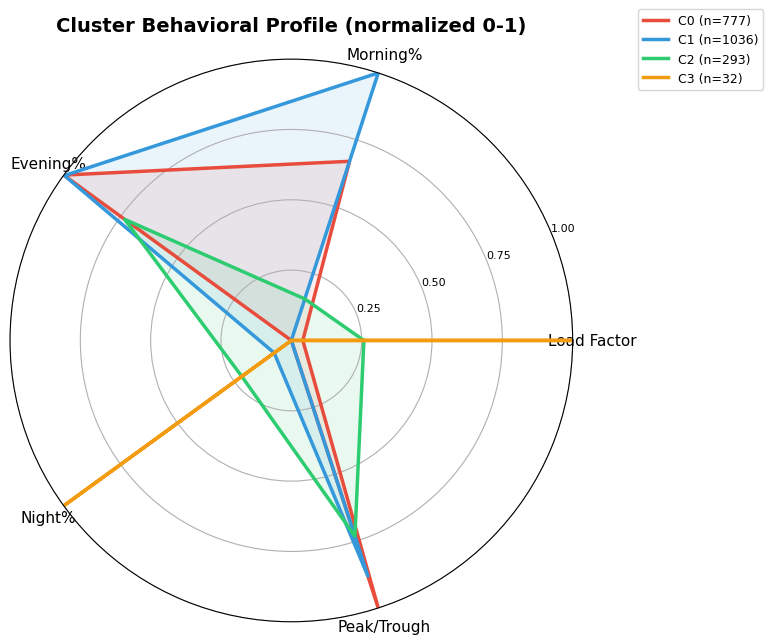

In [37]:
# ------------------------------------------------------------
# Radar / spider chart: 5 axes, normalized 0-1 across clusters
# ------------------------------------------------------------
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

axes_names = ['Load Factor', 'Morning%', 'Evening%', 'Night%', 'Peak/Trough']
cluster_ids = sorted(cluster_metrics.keys())

raw_matrix = np.array([
    [cluster_metrics[k]['load_factor'] for k in cluster_ids],
    [cluster_metrics[k]['morning_pct']  for k in cluster_ids],
    [cluster_metrics[k]['evening_pct']  for k in cluster_ids],
    [cluster_metrics[k]['night_pct']    for k in cluster_ids],
    [cluster_metrics[k]['peak_trough']  for k in cluster_ids],
])  # shape (5 metrics, 4 clusters)

# Min-max normalize each metric (row) across clusters -> 0-1
row_min = raw_matrix.min(axis=1, keepdims=True)
row_max = raw_matrix.max(axis=1, keepdims=True)
row_range = np.where(row_max - row_min == 0, 1, row_max - row_min)
norm_matrix = (raw_matrix - row_min) / row_range  # (5, 4)

n_axes = len(axes_names)
angles = np.linspace(0, 2 * np.pi, n_axes, endpoint=False).tolist()
angles += angles[:1]  # close the loop

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for col, k in enumerate(cluster_ids):
    values = norm_matrix[:, col].tolist()
    values += values[:1]
    n = cluster_metrics[k]['n']
    ax.plot(angles, values, color=colors[k % len(colors)], linewidth=2.5, label=f'C{k} (n={n})')
    ax.fill(angles, values, color=colors[k % len(colors)], alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(axes_names, fontsize=11)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(['0.25', '0.50', '0.75', '1.00'], fontsize=8)
ax.set_ylim(0, 1)
ax.set_title('Cluster Behavioral Profile (normalized 0-1)', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=9)
plt.tight_layout()
plt.show()


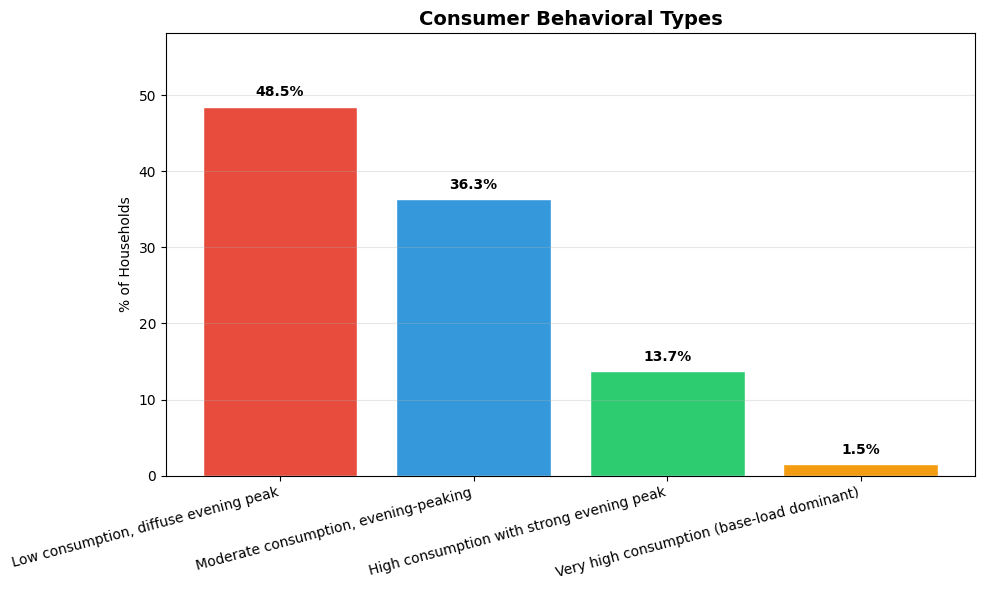

In [38]:
# ------------------------------------------------------------
# Summary: Consumer Behavioral Types (% of households)
# ------------------------------------------------------------
behavior_counts = {}
for k, label in behavior_labels.items():
    behavior_counts[label] = behavior_counts.get(label, 0) + cluster_metrics[k]['n']

total_households = sum(m['n'] for m in cluster_metrics.values())
behavior_pct = {label: count / total_households * 100 for label, count in behavior_counts.items()}

sorted_behaviors = sorted(behavior_pct.items(), key=lambda x: x[1], reverse=True)
names = [b[0] for b in sorted_behaviors]
pcts = [b[1] for b in sorted_behaviors]

fig, ax = plt.subplots(figsize=(10, 6))
bar_colors = [colors[i % len(colors)] for i in range(len(names))]
bars = ax.bar(names, pcts, color=bar_colors, edgecolor='white')

for bar, pct in zip(bars, pcts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            f'{pct:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title('Consumer Behavioral Types', fontsize=14, fontweight='bold')
ax.set_ylabel('% of Households')
ax.set_ylim(0, max(pcts) * 1.2)
ax.grid(True, alpha=0.3, axis='y')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()


In [39]:
# ============================================================
# VARIANCE DECOMPOSITION: how much does clustering explain? (K=4)
# profiles_original_clean = raw, unscaled kWh/hh; aligned 1:1
# with results_raw['K-Means'] labels (outliers already removed)
# ============================================================
labels_k4 = results_raw['K-Means']
N = len(profiles_original_clean)

grand_mean  = profiles_original_clean.mean(axis=0).values   # (48,) grand mean per slot
total_var_t = profiles_original_clean.var(axis=0).values    # (48,) total variance per slot (ddof=1)

between_var_t = np.zeros(48)
within_var_t  = np.zeros(48)

for k in sorted(set(labels_k4)):
    mask = labels_k4 == k
    w_k = mask.sum() / N
    cluster_data = profiles_original_clean.iloc[mask]
    mean_k = cluster_data.mean(axis=0).values   # (48,)
    var_k  = cluster_data.var(axis=0).values    # (48,) within-cluster variance per slot

    between_var_t += w_k * (mean_k - grand_mean) ** 2   # weighted variance of cluster means around grand mean
    within_var_t  += w_k * var_k                         # weighted (by cluster size) within-cluster variance

total_variance   = total_var_t.sum()
between_variance = between_var_t.sum()
within_variance  = within_var_t.sum()
explained_variance_ratio_k4 = between_variance / total_variance

print(f'Total variance (sum over 48 slots):     {total_variance:.6f}')
print(f'Between-cluster variance (K=4):         {between_variance:.6f}')
print(f'Within-cluster variance (K=4):          {within_variance:.6f}')
print(f'Between + Within (sanity check):        {between_variance + within_variance:.6f}')
print(f'\nExplained variance ratio (K=4): {explained_variance_ratio_k4:.4f}  ({explained_variance_ratio_k4*100:.2f}%)')


Total variance (sum over 48 slots):     0.833318
Between-cluster variance (K=4):         0.592133
Within-cluster variance (K=4):          0.242188
Between + Within (sanity check):        0.834320

Explained variance ratio (K=4): 0.7106  (71.06%)


In [40]:
# ------------------------------------------------------------
# Explained variance ratio & silhouette score across K = 2..6
# (clustering re-fit on X_raw -- the same scaled feature space
# used to select K=4 -- but variance is always measured in raw kWh)
# ------------------------------------------------------------
K_sweep = range(2, 7)
evr_by_k = {}
sil_by_k = {}

for k_val in K_sweep:
    km = KMeans(n_clusters=k_val, random_state=42, n_init=10)
    labels_k = km.fit_predict(X_raw)

    between_var_t_k = np.zeros(48)
    for k in sorted(set(labels_k)):
        mask = labels_k == k
        w_k = mask.sum() / N
        mean_k = profiles_original_clean.iloc[mask].mean(axis=0).values
        between_var_t_k += w_k * (mean_k - grand_mean) ** 2

    evr_by_k[k_val] = between_var_t_k.sum() / total_variance
    sil_by_k[k_val] = silhouette_score(X_raw, labels_k)

    print(f'K={k_val}: Explained Variance Ratio={evr_by_k[k_val]:.4f}, Silhouette={sil_by_k[k_val]:.4f}')

print(f'\nSanity check -- dedicated K=4 EVR: {explained_variance_ratio_k4:.4f} '
      f'vs sweep K=4 EVR: {evr_by_k[4]:.4f}')


K=2: Explained Variance Ratio=0.4882, Silhouette=0.5135
K=3: Explained Variance Ratio=0.6485, Silhouette=0.4212
K=4: Explained Variance Ratio=0.7106, Silhouette=0.3638
K=5: Explained Variance Ratio=0.7522, Silhouette=0.3088
K=6: Explained Variance Ratio=0.7704, Silhouette=0.2574

Sanity check -- dedicated K=4 EVR: 0.7106 vs sweep K=4 EVR: 0.7106


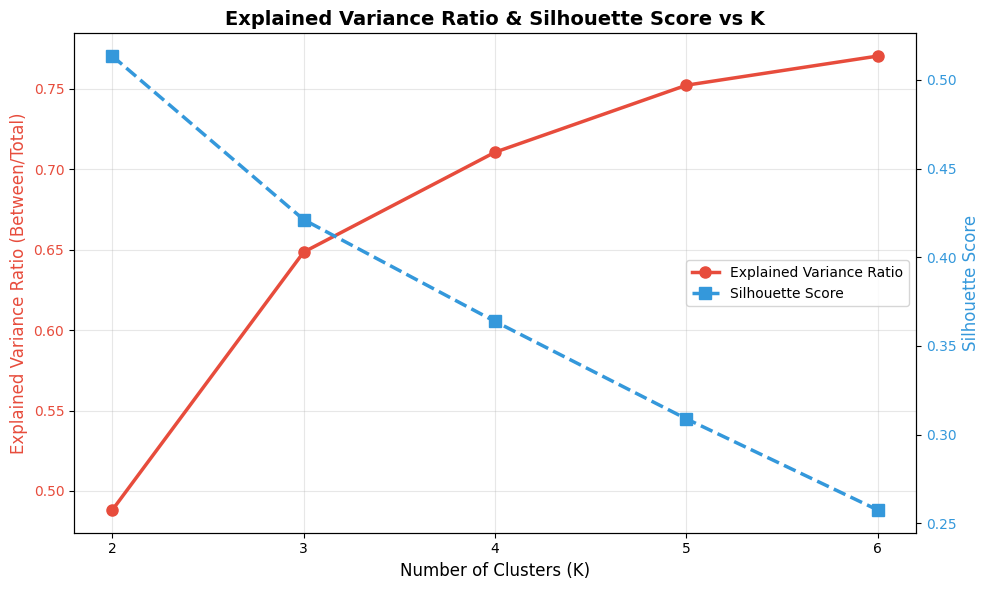

In [41]:
# ------------------------------------------------------------
# Plot: Explained Variance Ratio vs K (Silhouette on twin axis)
# ------------------------------------------------------------
k_list = list(K_sweep)
evr_list = [evr_by_k[k] for k in k_list]
sil_list = [sil_by_k[k] for k in k_list]

fig, ax1 = plt.subplots(figsize=(10, 6))

color1 = '#e74c3c'
ax1.plot(k_list, evr_list, 'o-', color=color1, linewidth=2.5, markersize=8, label='Explained Variance Ratio')
ax1.set_xlabel('Number of Clusters (K)', fontsize=12)
ax1.set_ylabel('Explained Variance Ratio (Between/Total)', color=color1, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xticks(k_list)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
color2 = '#3498db'
ax2.plot(k_list, sil_list, 's--', color=color2, linewidth=2.5, markersize=8, label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color=color2, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color2)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right', fontsize=10)

plt.title('Explained Variance Ratio & Silhouette Score vs K', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [42]:
# ------------------------------------------------------------
# Summary statements
# ------------------------------------------------------------
evr_k2 = evr_by_k[2]
evr_k4 = evr_by_k[4]
gain_k2_to_k4 = (evr_k4 - evr_k2) * 100

print(f'K=4 explains {evr_k4*100:.2f}% of total consumption variance.')
print(f'Going from K=2 to K=4 captures {gain_k2_to_k4:.2f} additional percentage points of variance '
      f'(from {evr_k2*100:.2f}% to {evr_k4*100:.2f}%).')


K=4 explains 71.06% of total consumption variance.
Going from K=2 to K=4 captures 22.24 additional percentage points of variance (from 48.82% to 71.06%).


=== Top 5 time slots by between-cluster variance (K=4) ===

1. 19:30 (slot 39): between-cluster variance = 0.023082 (3.9% of total between-cluster variance)
2. 20:00 (slot 40): between-cluster variance = 0.022764 (3.8% of total between-cluster variance)
3. 19:00 (slot 38): between-cluster variance = 0.022739 (3.8% of total between-cluster variance)
4. 20:30 (slot 41): between-cluster variance = 0.022423 (3.8% of total between-cluster variance)
5. 18:30 (slot 37): between-cluster variance = 0.021965 (3.7% of total between-cluster variance)


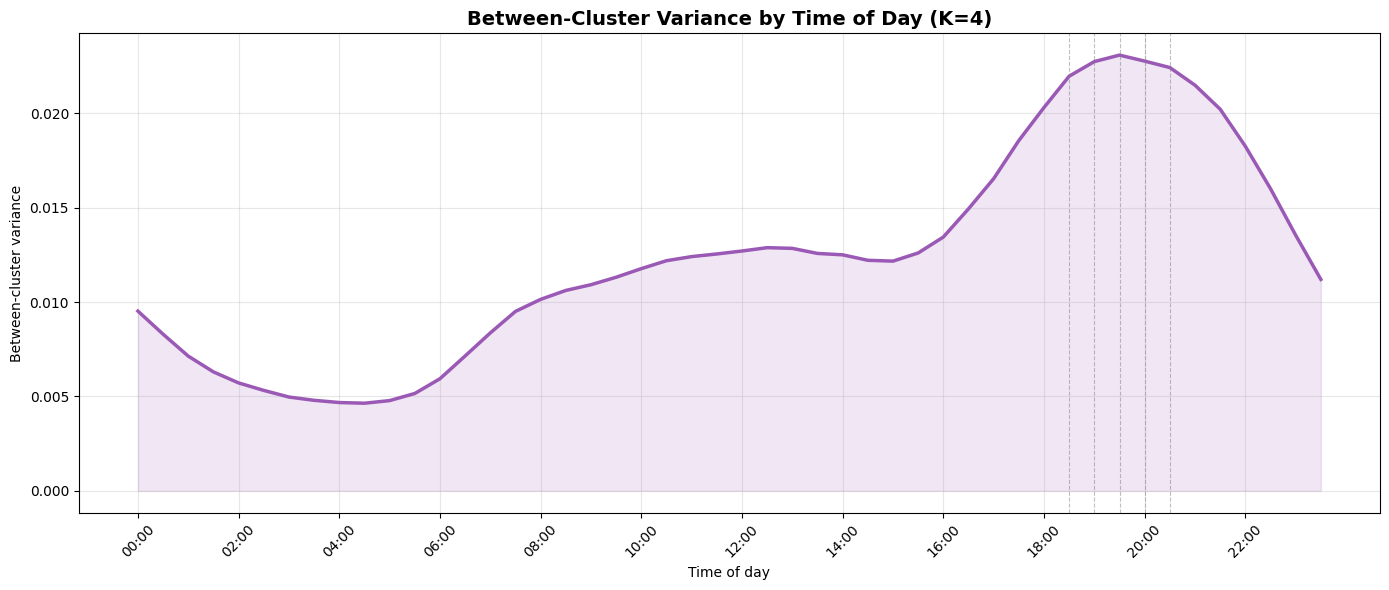

In [43]:
# ------------------------------------------------------------
# When during the day do clusters differ most?
# (per-time-slot between-cluster variance, K=4)
# ------------------------------------------------------------
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
top_slots = np.argsort(between_var_t)[::-1][:5]

print('=== Top 5 time slots by between-cluster variance (K=4) ===\n')
for rank, slot in enumerate(top_slots, start=1):
    pct_of_total_between = between_var_t[slot] / between_variance * 100
    print(f'{rank}. {x_labels[slot]} (slot {slot}): between-cluster variance = {between_var_t[slot]:.6f} '
          f'({pct_of_total_between:.1f}% of total between-cluster variance)')

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(range(48), between_var_t, color='#9b59b6', linewidth=2.5)
ax.fill_between(range(48), between_var_t, color='#9b59b6', alpha=0.15)

for slot in top_slots:
    ax.axvline(slot, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)

ax.set_title('Between-Cluster Variance by Time of Day (K=4)', fontsize=14, fontweight='bold')
ax.set_ylabel('Between-cluster variance')
ax.set_xlabel('Time of day')
ax.set_xticks(range(0, 48, 4))
ax.set_xticklabels([x_labels[j] for j in range(0, 48, 4)], rotation=45)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [44]:
# ============================================================
# K=2 ANALYSIS: Does K=2 give more insight than K=4?
# ============================================================
K2 = 2

km2 = KMeans(n_clusters=K2, random_state=42, n_init=10)
labels_k2 = km2.fit_predict(X_raw)

print(f'K=2 K-Means done')
print(f'Cluster sizes: {np.bincount(labels_k2)}')


K=2 K-Means done
Cluster sizes: [1637  501]


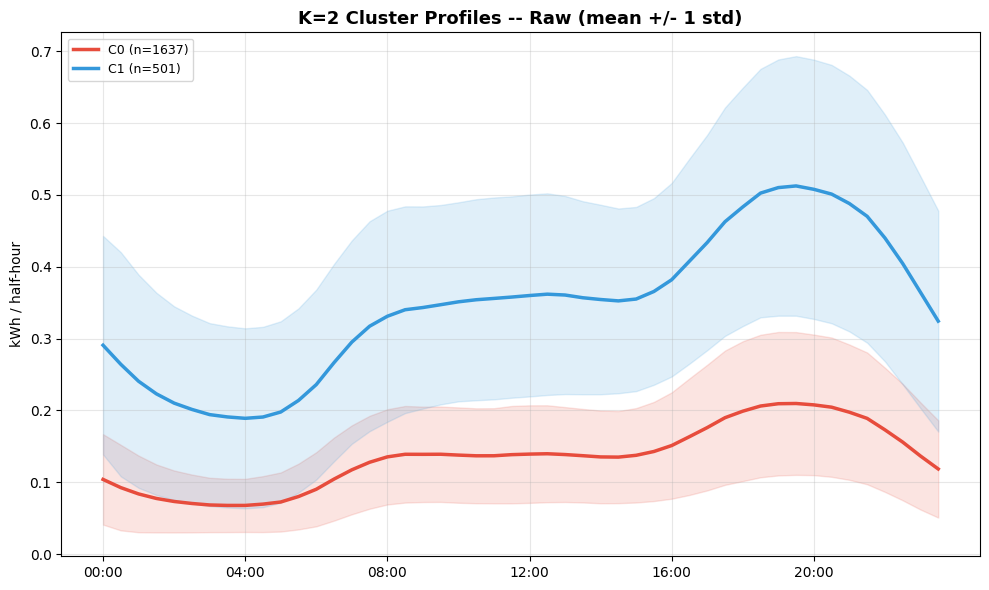

In [45]:
# ------------------------------------------------------------
# K=2 Cluster Profiles (mean +/- 1 std)
# ------------------------------------------------------------
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
colors = ['#e74c3c', '#3498db']

fig, ax = plt.subplots(figsize=(10, 6))

for label in sorted(set(labels_k2)):
    mask = labels_k2 == label
    mean = profiles_original_clean.iloc[mask].mean()
    std  = profiles_original_clean.iloc[mask].std()
    color = colors[label % len(colors)]
    ax.plot(range(48), mean, color=color, linewidth=2.5, label=f'C{label} (n={mask.sum()})')
    ax.fill_between(range(48), mean - std, mean + std, alpha=0.15, color=color)

ax.set_title('K=2 Cluster Profiles -- Raw (mean +/- 1 std)', fontsize=13, fontweight='bold')
ax.set_ylabel('kWh / half-hour')
ax.set_xticks(range(0, 48, 8))
ax.set_xticklabels([x_labels[j] for j in range(0, 48, 8)])
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [46]:
# ------------------------------------------------------------
# K=2 vs K=4: Silhouette, Davies-Bouldin, Calinski-Harabasz
# ------------------------------------------------------------
labels_k4 = results_raw['K-Means']  # K=4 K-Means labels, from earlier section

sil_k2 = silhouette_score(X_raw, labels_k2)
dbi_k2 = davies_bouldin_score(X_raw, labels_k2)
chi_k2 = calinski_harabasz_score(X_raw, labels_k2)

sil_k4 = silhouette_score(X_raw, labels_k4)
dbi_k4 = davies_bouldin_score(X_raw, labels_k4)
chi_k4 = calinski_harabasz_score(X_raw, labels_k4)

print(f'{"K":<6} {"Silhouette":>12} {"Davies-Bouldin":>16} {"Calinski-Harabasz":>18}')
print('=' * 56)
print(f'{"K=2":<6} {sil_k2:>12.4f} {dbi_k2:>16.4f} {chi_k2:>18.1f}')
print(f'{"K=4":<6} {sil_k4:>12.4f} {dbi_k4:>16.4f} {chi_k4:>18.1f}')


K        Silhouette   Davies-Bouldin  Calinski-Harabasz
K=2          0.5135           0.8777             1887.2
K=4          0.3638           0.9972             1638.9


In [47]:
# ------------------------------------------------------------
# K=2 Cluster Sizes and Avg Daily kWh
# ------------------------------------------------------------
stats_k2 = []
for label in sorted(set(labels_k2)):
    mask = labels_k2 == label
    mean_profile = profiles_original_clean.iloc[mask].mean()
    daily_kwh = mean_profile.sum()

    stats_k2.append({
        'Cluster':       f'C{label}',
        'Households':    mask.sum(),
        'Avg Daily kWh': round(daily_kwh, 2),
    })

print('=== K=2 Cluster Characteristics ===\n')
print(pd.DataFrame(stats_k2).to_string(index=False))
print('\nK=2 only separates households into "high" vs "low" consumers overall --')
print('it does not reveal any further structure in load shape or peak timing.')
print('K=4 is retained because it captures this additional structure while')
print('remaining stable and interpretable (see Gap Statistic and stability analysis below).')


=== K=2 Cluster Characteristics ===

Cluster  Households  Avg Daily kWh
     C0        1637           6.47
     C1         501          16.57

K=2 only separates households into "high" vs "low" consumers overall --
it does not reveal any further structure in load shape or peak timing.
K=4 is retained because it captures this additional structure while
remaining stable and interpretable (see Gap Statistic and stability analysis below).


In [48]:
# ============================================================
# NORMALIZED CLUSTER PROFILES (K=4)
# norm_Ci(t) = Ci(t) - mean(Ci), removing each cluster's overall
# average level so only the shape of the daily curve remains
# ============================================================
labels_k4 = results_raw['K-Means']

x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

raw_profiles = {}
norm_profiles = {}

for label in sorted(set(labels_k4)):
    mask = labels_k4 == label
    mean_profile = profiles_original_clean.iloc[mask].mean().values  # C_i(t), length 48
    raw_profiles[label] = mean_profile
    norm_profiles[label] = mean_profile - mean_profile.mean()        # norm_Ci(t)

print('Normalized profiles computed for clusters:', sorted(raw_profiles.keys()))
for label in sorted(raw_profiles.keys()):
    print(f'  C{label}: mean level removed = {raw_profiles[label].mean():.4f} kWh/hh')


Normalized profiles computed for clusters: [np.int32(0), np.int32(1), np.int32(2), np.int32(3)]
  C0: mean level removed = 0.2093 kWh/hh
  C1: mean level removed = 0.1002 kWh/hh
  C2: mean level removed = 0.3589 kWh/hh
  C3: mean level removed = 0.6860 kWh/hh


In [49]:
# ------------------------------------------------------------
# Find crossing points between cluster pairs (normalized profiles)
# ------------------------------------------------------------
from itertools import combinations

def slot_to_time(slot):
    total_min = slot * 30
    h = int(total_min // 60) % 24
    m = int(total_min % 60)
    return f'{h:02d}:{m:02d}'

crossings = []

for i, j in combinations(sorted(norm_profiles.keys()), 2):
    diff = norm_profiles[i] - norm_profiles[j]
    for t in range(len(diff) - 1):
        d0, d1 = diff[t], diff[t + 1]
        if d0 == 0:
            crossing_slot = float(t)
            crossing_val = norm_profiles[i][t]
            crossings.append((i, j, crossing_slot, crossing_val))
        elif d0 * d1 < 0:
            frac = d0 / (d0 - d1)
            crossing_slot = t + frac
            crossing_val = norm_profiles[i][t] + frac * (norm_profiles[i][t + 1] - norm_profiles[i][t])
            crossings.append((i, j, crossing_slot, crossing_val))

print(f'Found {len(crossings)} crossing points between cluster pairs.')


Found 15 crossing points between cluster pairs.


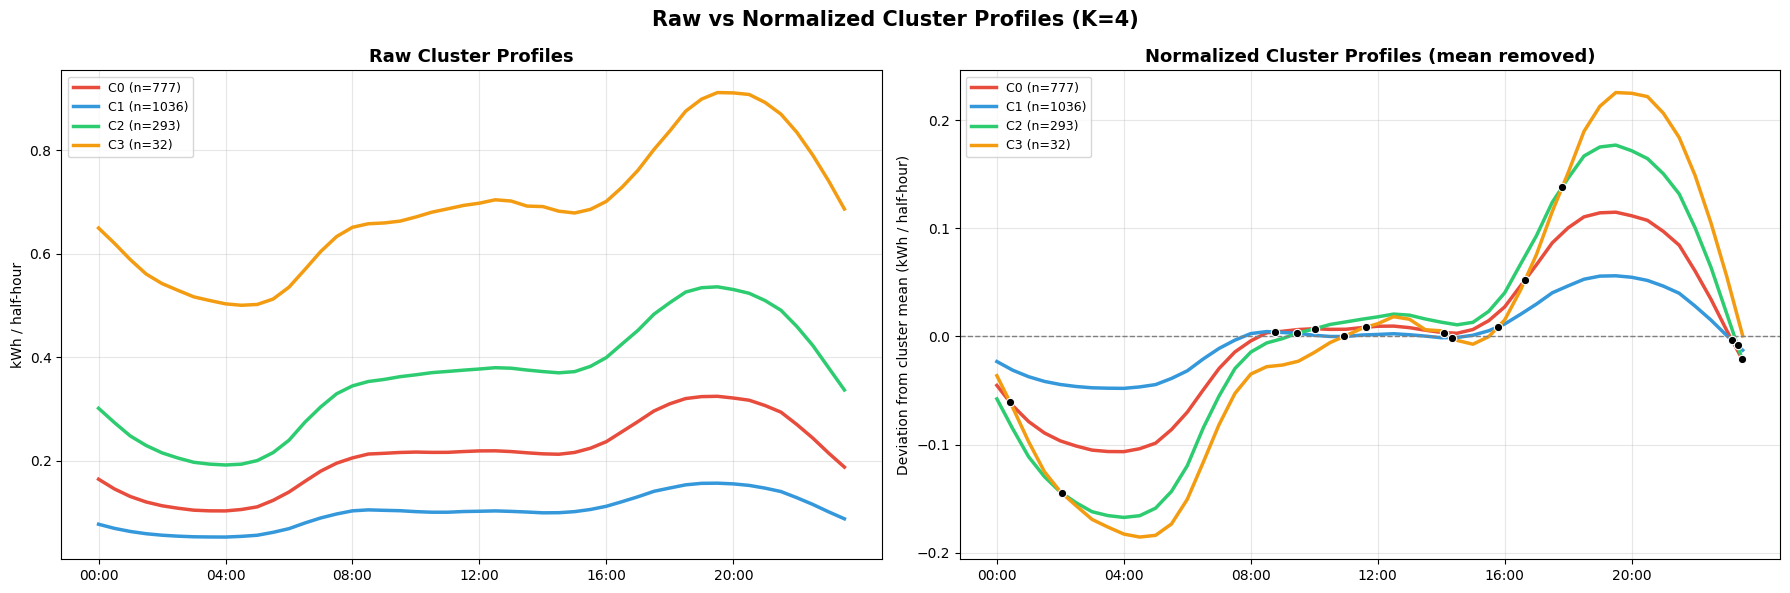

In [50]:
# ------------------------------------------------------------
# Plot: Raw Profiles vs Normalized Profiles (with crossings marked)
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Left: original raw profiles
for label in sorted(raw_profiles.keys()):
    mask = labels_k4 == label
    axes[0].plot(range(48), raw_profiles[label], color=colors[label % len(colors)],
                 linewidth=2.5, label=f'C{label} (n={mask.sum()})')
axes[0].set_title('Raw Cluster Profiles', fontsize=13, fontweight='bold')
axes[0].set_ylabel('kWh / half-hour')
axes[0].set_xticks(range(0, 48, 8))
axes[0].set_xticklabels([x_labels[j] for j in range(0, 48, 8)])
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# Right: normalized profiles (shape only, mean removed)
for label in sorted(norm_profiles.keys()):
    mask = labels_k4 == label
    axes[1].plot(range(48), norm_profiles[label], color=colors[label % len(colors)],
                 linewidth=2.5, label=f'C{label} (n={mask.sum()})')

# Mark crossing points
for i, j, slot, val in crossings:
    axes[1].plot(slot, val, marker='o', markersize=6, color='black',
                 markeredgecolor='white', markeredgewidth=0.8, zorder=5)

axes[1].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[1].set_title('Normalized Cluster Profiles (mean removed)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Deviation from cluster mean (kWh / half-hour)')
axes[1].set_xticks(range(0, 48, 8))
axes[1].set_xticklabels([x_labels[j] for j in range(0, 48, 8)])
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Raw vs Normalized Cluster Profiles (K=4)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


Computing Gap Statistic (takes ~1 min)...
Optimal K by Gap Statistic: 10


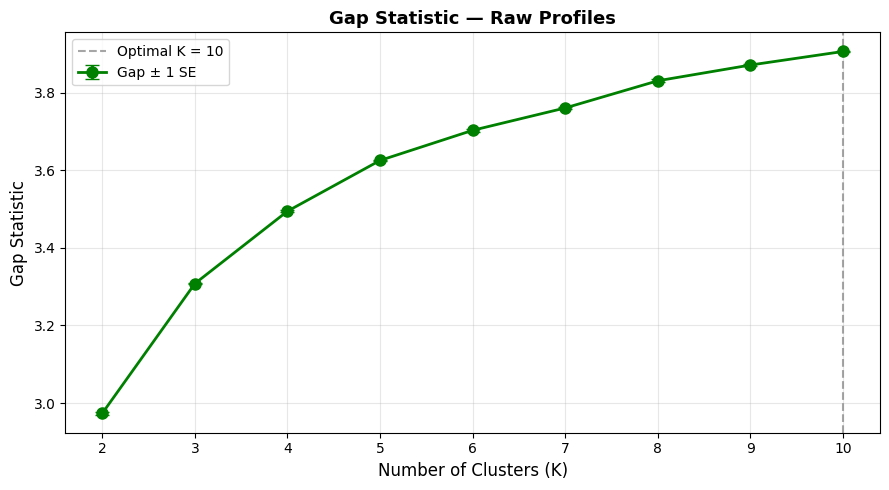

Gap Statistic optimal K = 10
(Note: Silhouette favours K=2 with score 0.5135, but K=4 chosen as practical balance between interpretability and statistical validity.)


In [51]:
# ============================================================
# K SELECTION: Gap Statistic
# ============================================================

def gap_statistic(X, K_range, n_refs=10, random_state=42):
    np.random.seed(random_state)
    gaps, sk = [], []

    for k in K_range:
        # Inertia on real data
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        km.fit(X)
        W_k = np.log(km.inertia_)

        # Inertia on random reference datasets
        ref_inertias = []
        for _ in range(n_refs):
            random_data = np.random.uniform(X.min(axis=0), X.max(axis=0), X.shape)
            km_ref = KMeans(n_clusters=k, random_state=42, n_init=5)
            km_ref.fit(random_data)
            ref_inertias.append(np.log(km_ref.inertia_))

        ref_mean = np.mean(ref_inertias)
        ref_std  = np.std(ref_inertias)
        gaps.append(ref_mean - W_k)
        sk.append(ref_std * np.sqrt(1 + 1/n_refs))

    return np.array(gaps), np.array(sk)

print('Computing Gap Statistic (takes ~1 min)...')
K_range = range(2, 11)
gaps, sk = gap_statistic(X_raw.values, K_range)

# Optimal K: smallest k where gap(k) >= gap(k+1) - sk(k+1)
optimal_k = None
for i in range(len(gaps) - 1):
    if gaps[i] >= gaps[i+1] - sk[i+1]:
        optimal_k = list(K_range)[i]
        break
if optimal_k is None:
    optimal_k = list(K_range)[np.argmax(gaps)]

print(f'Optimal K by Gap Statistic: {optimal_k}')

# Plot
plt.figure(figsize=(9, 5))
plt.errorbar(K_range, gaps, yerr=sk, fmt='go-', linewidth=2,
             markersize=8, capsize=5, label='Gap ± 1 SE')
plt.axvline(optimal_k, color='gray', linestyle='--', alpha=0.7,
            label=f'Optimal K = {optimal_k}')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Gap Statistic', fontsize=12)
plt.title('Gap Statistic — Raw Profiles', fontsize=13, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

gap_optimal_k = int(np.argmax(gaps) + 2)
print(f"Gap Statistic optimal K = {gap_optimal_k}")
print(f"(Note: Silhouette favours K=2 with score 0.5135, but K=4 chosen as "
      f"practical balance between interpretability and statistical validity.)")

**Note.** This cell reads `processed/clean_halfhourly.parquet`, which is not
included in the submission: at 275 MB it exceeds the 50 MB upload limit.
Running it without that file will raise `FileNotFoundError`. The file is
regenerated by the preprocessing cells above from the raw Low Carbon London
data. The outputs shown below are from the run
reported in the dissertation.

In [52]:
import gc

# ============================================================
# SEASONAL + WEEKDAY/WEEKEND — load df once
# ============================================================
df = pd.read_parquet(os.path.join(DATA_PATH, 'processed', 'clean_halfhourly.parquet'))
df['tstp'] = pd.to_datetime(df['tstp'])

clean_ids = profiles_original_clean.index.tolist()
df_clean = df[df['LCLid'].isin(clean_ids)].copy()
df_clean['energy(kWh/hh)'] = pd.to_numeric(df_clean['energy(kWh/hh)'], errors='coerce')
df_clean = df_clean.dropna(subset=['energy(kWh/hh)'])

# Delete df immediately — no longer needed
del df
gc.collect()
print("df deleted, df_clean shape:", df_clean.shape)

# Add the required columns
df_clean['month']    = df_clean['tstp'].dt.month
df_clean['slot']     = df_clean['tstp'].dt.hour * 2 + df_clean['tstp'].dt.minute // 30
df_clean['dow']      = df_clean['tstp'].dt.dayofweek
df_clean['day_type'] = np.where(df_clean['dow'] < 5, 'Weekday', 'Weekend')

def get_season(month):
    if month in [12, 1, 2]:  return 'Winter'
    elif month in [6, 7, 8]: return 'Summer'
    else:                     return 'Other'
df_clean['season'] = df_clean['month'].map(get_season)

# SEASONAL
profiles_winter = (df_clean[df_clean['season'] == 'Winter']
                   .groupby(['LCLid', 'slot'])['energy(kWh/hh)']
                   .mean().unstack('slot'))
profiles_summer = (df_clean[df_clean['season'] == 'Summer']
                   .groupby(['LCLid', 'slot'])['energy(kWh/hh)']
                   .mean().unstack('slot'))
gc.collect()

# WEEKDAY / WEEKEND
profiles_weekday = (df_clean[df_clean['day_type'] == 'Weekday']
                    .groupby(['LCLid', 'slot'])['energy(kWh/hh)']
                    .mean().unstack('slot'))
profiles_weekend = (df_clean[df_clean['day_type'] == 'Weekend']
                    .groupby(['LCLid', 'slot'])['energy(kWh/hh)']
                    .mean().unstack('slot'))

# Delete df_clean — everything extracted
del df_clean
gc.collect()

# Align
common_sw = profiles_winter.index.intersection(profiles_summer.index)
profiles_winter  = profiles_winter.loc[common_sw].dropna()
profiles_summer  = profiles_summer.loc[common_sw].dropna()

common_dt = profiles_weekday.index.intersection(profiles_weekend.index)
profiles_weekday = profiles_weekday.loc[common_dt].dropna()
profiles_weekend = profiles_weekend.loc[common_dt].dropna()

print(f'Seasonal: {len(common_sw)} households')
print(f'Weekday/Weekend: {len(common_dt)} households')
print('Memory released — df and df_clean deleted')

df deleted, df_clean shape: (65059534, 3)
Seasonal: 2138 households
Weekday/Weekend: 2138 households
Memory released — df and df_clean deleted


**Note.** This cell reads `processed/clean_halfhourly.parquet`, which is not
included in the submission: at 275 MB it exceeds the 50 MB upload limit.
Running it without that file will raise `FileNotFoundError`. The file is
regenerated by the preprocessing cells above from the raw Low Carbon London
data. The outputs shown below are from the run
reported in the dissertation.

In [53]:
df = pd.read_parquet(os.path.join(DATA_PATH, 'processed', 'clean_halfhourly.parquet'))

clean_ids = profiles_original_clean.index.tolist()
df = df[df['LCLid'].isin(clean_ids)].copy()
print(f"Seasonal analysis: using {df['LCLid'].nunique()} households "
      f"(should be 2138)")

df['tstp'] = pd.to_datetime(df['tstp'])
df['energy(kWh/hh)'] = pd.to_numeric(df['energy(kWh/hh)'], errors='coerce')
df_clean = df.dropna(subset=['energy(kWh/hh)'])

df_clean['month'] = df_clean['tstp'].dt.month
df_clean['slot']  = df_clean['tstp'].dt.hour * 2 + df_clean['tstp'].dt.minute // 30

def get_season(month):
    if month in [12, 1, 2]:  return 'Winter'
    elif month in [6, 7, 8]: return 'Summer'
    else:                     return 'Other'

df_clean['season'] = df_clean['month'].map(get_season)

profiles_winter = (df_clean[df_clean['season'] == 'Winter']
                   .groupby(['LCLid', 'slot'], observed=True)['energy(kWh/hh)']
                   .mean().unstack('slot'))

profiles_summer = (df_clean[df_clean['season'] == 'Summer']
                   .groupby(['LCLid', 'slot'], observed=True)['energy(kWh/hh)']
                   .mean().unstack('slot'))

common_ids = profiles_winter.index.intersection(profiles_summer.index)
profiles_winter = profiles_winter.loc[common_ids].dropna()
profiles_summer = profiles_summer.loc[common_ids].dropna()

print(f'Households with both seasons: {len(common_ids)}')
print(f'Winter shape: {profiles_winter.shape}')
print(f'Summer shape: {profiles_summer.shape}')


Seasonal analysis: using 2138 households (should be 2138)
Households with both seasons: 2138
Winter shape: (2138, 48)
Summer shape: (2138, 48)


> **SUPERSEDED — retained for methodological discussion.**
> Result: winter vs summer K-Means, ARI ~ 0.425, read as seasonal instability.
> Problem: no significance test, no label matching, and no check whether the transition is merely re-cutting the level distribution.
> Corrected in: Statistical rigour block 3 (Hungarian matching, permutation test, bootstrap CI, level control).

In [54]:
K = 4

scaler_w = StandardScaler()
scaler_s = StandardScaler()

X_winter = scaler_w.fit_transform(profiles_winter)
X_summer = scaler_s.fit_transform(profiles_summer)

km_winter = KMeans(n_clusters=K, random_state=42, n_init=10)
km_summer = KMeans(n_clusters=K, random_state=42, n_init=10)

labels_winter = km_winter.fit_predict(X_winter)
labels_summer = km_summer.fit_predict(X_summer)

sil_w = silhouette_score(X_winter, labels_winter)
sil_s = silhouette_score(X_summer, labels_summer)

print(f'Winter Silhouette: {sil_w:.4f}')
print(f'Summer Silhouette: {sil_s:.4f}')
print(f'Annual Silhouette: 0.3638  (reference)')

Winter Silhouette: 0.3855
Summer Silhouette: 0.3459
Annual Silhouette: 0.3638  (reference)


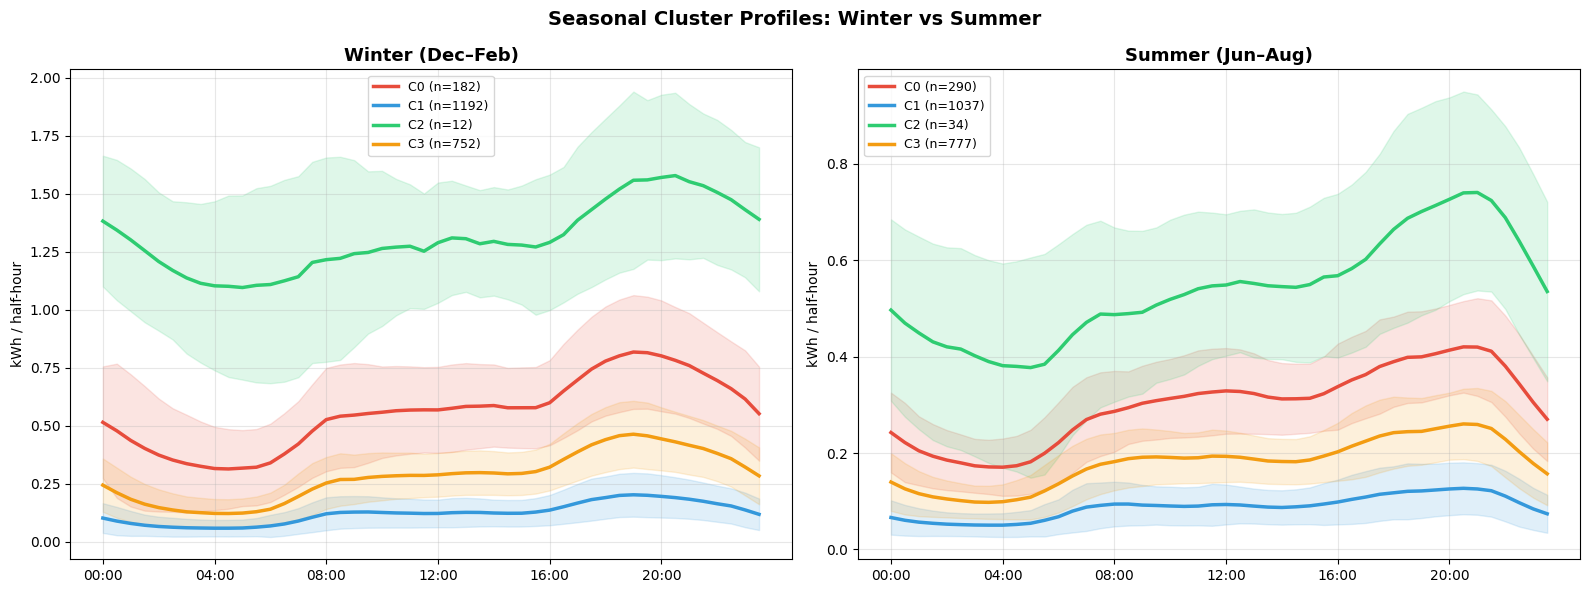

In [55]:
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
n_slots = profiles_winter.shape[1]
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (name, labels, profiles_df) in zip(axes, [
    ('Winter (Dec–Feb)', labels_winter, profiles_winter),
    ('Summer (Jun–Aug)', labels_summer, profiles_summer),
]):
    for label in sorted(set(labels)):
        mask = labels == label
        mean = profiles_df.iloc[mask].mean()
        std  = profiles_df.iloc[mask].std()
        color = colors[label % len(colors)]
        ax.plot(range(n_slots), mean, color=color, linewidth=2.5,
                label=f'C{label} (n={mask.sum()})')
        ax.fill_between(range(n_slots), mean - std, mean + std,
                        alpha=0.15, color=color)
    ax.set_title(name, fontsize=13, fontweight='bold')
    ax.set_ylabel('kWh / half-hour')
    ax.set_xticks(range(0, n_slots, 8))
    ax.set_xticklabels([x_labels[j] for j in range(0, n_slots, 8)])
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Seasonal Cluster Profiles: Winter vs Summer', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [56]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(labels_winter, labels_summer)
print(f'ARI (Winter vs Summer cluster assignment): {ari:.4f}')
print('(0 = random, 1 = identical assignments)')
print()

# How many households switched clusters between seasons?
switched = (labels_winter != labels_summer).sum()
total = len(labels_winter)
print(f'Households that changed cluster season-to-season: {switched} / {total} ({switched/total*100:.1f}%)')

# Cross-tab: where did winter clusters go in summer?
ct = pd.crosstab(
    pd.Series(labels_winter, name='Winter Cluster'),
    pd.Series(labels_summer, name='Summer Cluster')
)
print('\nCluster transition matrix (Winter → Summer):')
print(ct)

ARI (Winter vs Summer cluster assignment): 0.4252
(0 = random, 1 = identical assignments)

Households that changed cluster season-to-season: 595 / 2138 (27.8%)

Cluster transition matrix (Winter → Summer):
Summer Cluster    0    1   2    3
Winter Cluster                   
0                98   19  29   36
1                 0  947   0  245
2                 8    0   3    1
3               184   71   2  495


In [57]:
# ------------------------------------------------------------
# Cluster mean profiles: Weekday vs Weekend (K=4 labels)
# ------------------------------------------------------------
labels_k4 = results_raw['K-Means']
cluster_labels_all = pd.Series(labels_k4, index=profiles_original_clean.index)

# Keep only households present in both weekday/weekend profiles and cluster labels
common_ids_final = common_dt.intersection(cluster_labels_all.index)
cluster_labels_dt = cluster_labels_all.loc[common_ids_final]

profiles_weekday_aligned = profiles_weekday.loc[common_ids_final]
profiles_weekend_aligned = profiles_weekend.loc[common_ids_final]

weekday_cluster_profiles = {}
weekend_cluster_profiles = {}

for label in sorted(cluster_labels_dt.unique()):
    mask = (cluster_labels_dt == label).values
    weekday_cluster_profiles[label] = profiles_weekday_aligned.iloc[mask].mean().values
    weekend_cluster_profiles[label] = profiles_weekend_aligned.iloc[mask].mean().values

print(f'Households used: {len(common_ids_final)}')
for label in sorted(weekday_cluster_profiles.keys()):
    n = (cluster_labels_dt == label).sum()
    print(f'  C{label}: n={n}')


Households used: 2138
  C0: n=777
  C1: n=1036
  C2: n=293
  C3: n=32


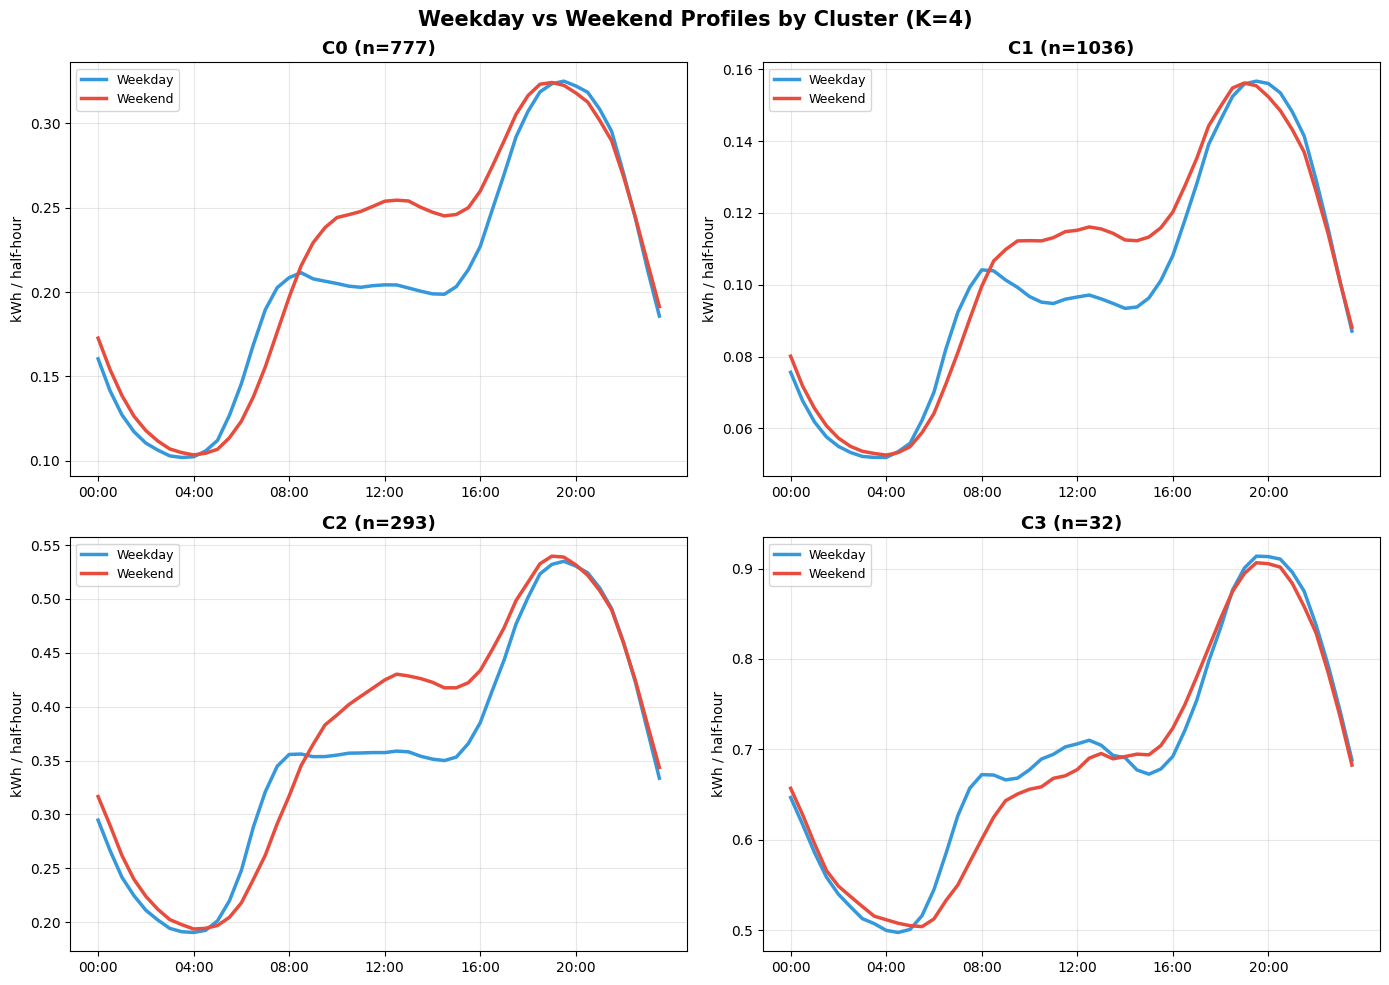

In [58]:
# ------------------------------------------------------------
# Plot: Weekday vs Weekend Profile per Cluster (2x2 grid)
# ------------------------------------------------------------
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, label in enumerate(sorted(weekday_cluster_profiles.keys())):
    ax = axes[idx]
    n = (cluster_labels_dt == label).sum()
    ax.plot(range(48), weekday_cluster_profiles[label], color='#3498db',
            linewidth=2.5, label='Weekday')
    ax.plot(range(48), weekend_cluster_profiles[label], color='#e74c3c',
            linewidth=2.5, label='Weekend')
    ax.set_title(f'C{label} (n={n})', fontsize=13, fontweight='bold')
    ax.set_ylabel('kWh / half-hour')
    ax.set_xticks(range(0, 48, 8))
    ax.set_xticklabels([x_labels[j] for j in range(0, 48, 8)])
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Weekday vs Weekend Profiles by Cluster (K=4)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


In [59]:
# ------------------------------------------------------------
# Average Weekday vs Weekend Consumption Difference per Cluster
# ------------------------------------------------------------
diff_table = []
for label in sorted(weekday_cluster_profiles.keys()):
    wd = weekday_cluster_profiles[label]
    we = weekend_cluster_profiles[label]
    mean_diff = (wd - we).mean()          # avg kWh/hh difference per slot
    daily_diff = mean_diff * 48           # equivalent daily kWh difference

    diff_table.append({
        'Cluster':            f'C{label}',
        'Weekday Avg kWh/hh': round(wd.mean(), 4),
        'Weekend Avg kWh/hh': round(we.mean(), 4),
        'Diff (kWh/hh)':      round(mean_diff, 4),
        'Diff (Daily kWh)':   round(daily_diff, 2),
    })

print('=== Weekday vs Weekend Consumption Difference per Cluster ===\n')
print(pd.DataFrame(diff_table).to_string(index=False))


=== Weekday vs Weekend Consumption Difference per Cluster ===

Cluster  Weekday Avg kWh/hh  Weekend Avg kWh/hh  Diff (kWh/hh)  Diff (Daily kWh)
     C0              0.2055              0.2184        -0.0129             -0.62
     C1              0.0987              0.1036        -0.0049             -0.23
     C2              0.3539              0.3711        -0.0172             -0.82
     C3              0.6883              0.6802         0.0082              0.39


In [60]:
# ------------------------------------------------------------
# Silhouette Score: Weekday Profiles vs Weekend Profiles
# (same K=4 cluster labels, evaluated in each day-type's feature space)
# ------------------------------------------------------------
scaler_wd = StandardScaler()
scaler_we = StandardScaler()

X_weekday = scaler_wd.fit_transform(profiles_weekday_aligned)
X_weekend = scaler_we.fit_transform(profiles_weekend_aligned)

sil_weekday = silhouette_score(X_weekday, cluster_labels_dt)
sil_weekend = silhouette_score(X_weekend, cluster_labels_dt)

print(f'{"Profile Type":<15} {"Silhouette":>12}')
print('=' * 29)
print(f'{"Weekday":<15} {sil_weekday:>12.4f}')
print(f'{"Weekend":<15} {sil_weekend:>12.4f}')


Profile Type      Silhouette
Weekday               0.3451
Weekend               0.3386


In [61]:
# ============================================================
# SIGNED DELTA ANALYSIS (K=4) — behavioral asymmetry:
# does each cluster ramp consumption up/down differently, not
# just how much it consumes?
# ============================================================
labels_k4 = results_raw['K-Means']

# True signed delta: C(t) - C(t-1), keeps negatives (ramp-down)
delta_signed = profiles_original_clean.diff(axis=1)
delta_signed = delta_signed.iloc[:, 1:]  # drop first NaN column -> 47 slots

print(f'Signed delta shape: {delta_signed.shape}')


Signed delta shape: (2138, 47)


In [62]:
# ------------------------------------------------------------
# Mean signed delta profile per cluster (47 slots)
# ------------------------------------------------------------
signed_delta_profiles = {}

for label in sorted(set(labels_k4)):
    mask = labels_k4 == label
    signed_delta_profiles[label] = delta_signed.iloc[mask].mean().values

print('Signed delta profiles computed for clusters:', sorted(signed_delta_profiles.keys()))


Signed delta profiles computed for clusters: [np.int32(0), np.int32(1), np.int32(2), np.int32(3)]


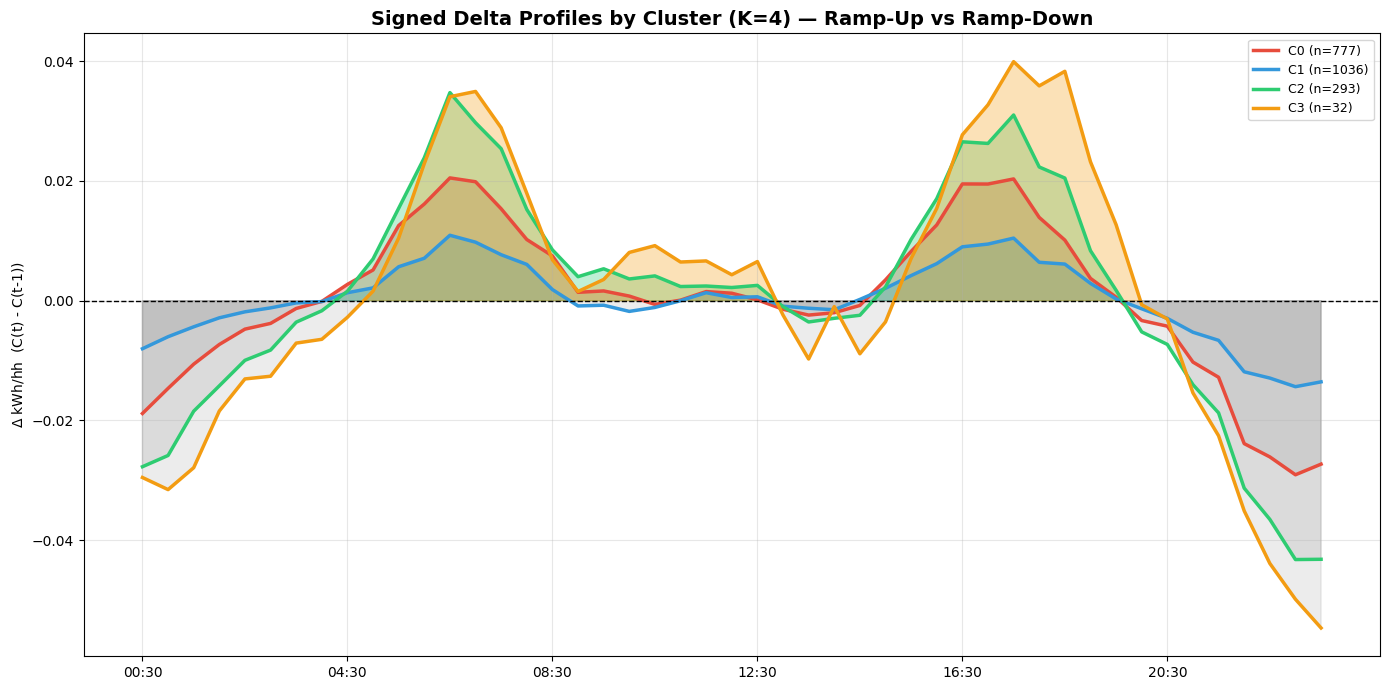

In [63]:
# ------------------------------------------------------------
# Plot: Signed Delta Profiles by Cluster (ramp-up vs ramp-down)
# ------------------------------------------------------------
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
delta_x_labels = x_labels[1:]  # shifted by 1 since we took diff
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

fig, ax = plt.subplots(figsize=(14, 7))

for label in sorted(signed_delta_profiles.keys()):
    delta = signed_delta_profiles[label]
    color = colors[label % len(colors)]
    n = (labels_k4 == label).sum()
    ax.plot(range(47), delta, color=color, linewidth=2.5, label=f'C{label} (n={n})')
    ax.fill_between(range(47), delta, 0, where=(delta >= 0),
                     color=color, alpha=0.3, interpolate=True)
    ax.fill_between(range(47), delta, 0, where=(delta < 0),
                     color='gray', alpha=0.15, interpolate=True)

ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set_title('Signed Delta Profiles by Cluster (K=4) — Ramp-Up vs Ramp-Down',
             fontsize=14, fontweight='bold')
ax.set_ylabel('$\\Delta$ kWh/hh  (C(t) - C(t-1))')
ax.set_xticks(range(0, 47, 8))
ax.set_xticklabels([delta_x_labels[j] for j in range(0, 47, 8)])
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [64]:
# ------------------------------------------------------------
# Sharpest ramp-up / ramp-down per cluster
# ------------------------------------------------------------
print('=== Sharpest Ramp-Up / Ramp-Down per Cluster ===\n')

ramp_stats = []
for label in sorted(signed_delta_profiles.keys()):
    delta = signed_delta_profiles[label]
    rise_idx = int(np.argmax(delta))
    fall_idx = int(np.argmin(delta))
    rise_rate = delta[rise_idx]
    fall_rate = delta[fall_idx]
    rise_time = delta_x_labels[rise_idx]
    fall_time = delta_x_labels[fall_idx]

    print(f'C{label}: sharpest ramp-UP at {rise_time} ({rise_rate:+.4f} kWh/hh), '
          f'sharpest ramp-DOWN at {fall_time} ({fall_rate:+.4f} kWh/hh)')

    ramp_stats.append({
        'Cluster':             f'C{label}',
        'Sharpest Rise Time':  rise_time,
        'Rise Rate (kWh/hh)':  round(rise_rate, 4),
        'Sharpest Fall Time':  fall_time,
        'Fall Rate (kWh/hh)':  round(fall_rate, 4),
    })


=== Sharpest Ramp-Up / Ramp-Down per Cluster ===

C0: sharpest ramp-UP at 06:30 (+0.0205 kWh/hh), sharpest ramp-DOWN at 23:00 (-0.0291 kWh/hh)
C1: sharpest ramp-UP at 06:30 (+0.0109 kWh/hh), sharpest ramp-DOWN at 23:00 (-0.0144 kWh/hh)
C2: sharpest ramp-UP at 06:30 (+0.0348 kWh/hh), sharpest ramp-DOWN at 23:00 (-0.0432 kWh/hh)
C3: sharpest ramp-UP at 17:30 (+0.0399 kWh/hh), sharpest ramp-DOWN at 23:30 (-0.0547 kWh/hh)


Running bootstrap stability (100 iterations)...

Cluster      Mean Jaccard      Std    Stability
C0                 0.8535   0.1216         High
C1                 0.9420   0.0545         High
C2                 0.7497   0.1784       Medium
C3                 0.5762   0.2437       Medium

Overall mean Jaccard: 0.7804
(>0.75 = stable, 0.5-0.75 = moderate, <0.5 = unstable)


/tmp/ipykernel_24104/3387415011.py:66: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([jaccard_scores[:, c] for c in range(4)],


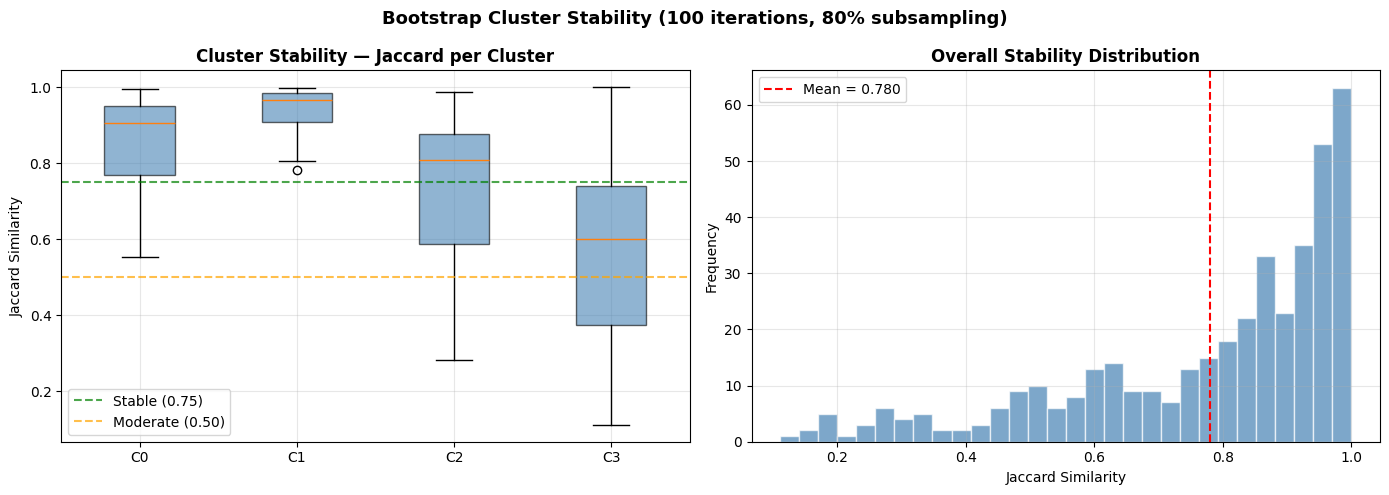

In [65]:
# ============================================================
# CLUSTER STABILITY: Bootstrap Analysis
# ============================================================
from sklearn.utils import resample

def bootstrap_stability(X, n_clusters, n_bootstrap=100, random_state=42):
    np.random.seed(random_state)
    n = X.shape[0]

    # Reference clustering on full data
    km_ref = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    labels_ref = km_ref.fit_predict(X)

    jaccard_scores = []

    for i in range(n_bootstrap):
        # Sample 80% of data with replacement
        idx = resample(np.arange(n), n_samples=int(0.8 * n),
                       random_state=random_state + i)
        X_boot = X[idx]

        km_boot = KMeans(n_clusters=n_clusters, random_state=42, n_init=5)
        labels_boot = km_boot.fit_predict(X_boot)

        # For each cluster in reference, find best matching bootstrap cluster
        # using Jaccard similarity
        ref_labels_boot = labels_ref[idx]
        cluster_jaccard = []

        for c in range(n_clusters):
            ref_mask = ref_labels_boot == c
            best_j = 0
            for cb in range(n_clusters):
                boot_mask = labels_boot == cb
                intersection = (ref_mask & boot_mask).sum()
                union = (ref_mask | boot_mask).sum()
                if union > 0:
                    best_j = max(best_j, intersection / union)
            cluster_jaccard.append(best_j)

        jaccard_scores.append(cluster_jaccard)

    return np.array(jaccard_scores)

print('Running bootstrap stability (100 iterations)...')
X_arr = X_raw.values
jaccard_scores = bootstrap_stability(X_arr, n_clusters=4)

# Results
mean_j = jaccard_scores.mean(axis=0)
std_j  = jaccard_scores.std(axis=0)

print(f'\n{"Cluster":<10} {"Mean Jaccard":>14} {"Std":>8} {"Stability":>12}')
print('=' * 46)
for c in range(4):
    stability = 'High' if mean_j[c] > 0.75 else ('Medium' if mean_j[c] > 0.5 else 'Low')
    print(f'C{c:<9} {mean_j[c]:>14.4f} {std_j[c]:>8.4f} {stability:>12}')

print(f'\nOverall mean Jaccard: {mean_j.mean():.4f}')
print('(>0.75 = stable, 0.5-0.75 = moderate, <0.5 = unstable)')

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot per cluster
axes[0].boxplot([jaccard_scores[:, c] for c in range(4)],
                labels=[f'C{c}' for c in range(4)],
                patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[0].axhline(0.75, color='green', linestyle='--', alpha=0.7, label='Stable (0.75)')
axes[0].axhline(0.50, color='orange', linestyle='--', alpha=0.7, label='Moderate (0.50)')
axes[0].set_ylabel('Jaccard Similarity')
axes[0].set_title('Cluster Stability — Jaccard per Cluster', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Overall distribution
axes[1].hist(jaccard_scores.flatten(), bins=30, color='steelblue',
             alpha=0.7, edgecolor='white')
axes[1].axvline(mean_j.mean(), color='red', linestyle='--',
                label=f'Mean = {mean_j.mean():.3f}')
axes[1].set_xlabel('Jaccard Similarity')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Overall Stability Distribution', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Bootstrap Cluster Stability (100 iterations, 80% subsampling)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Running t-SNE (takes ~1-2 min)...


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Done!


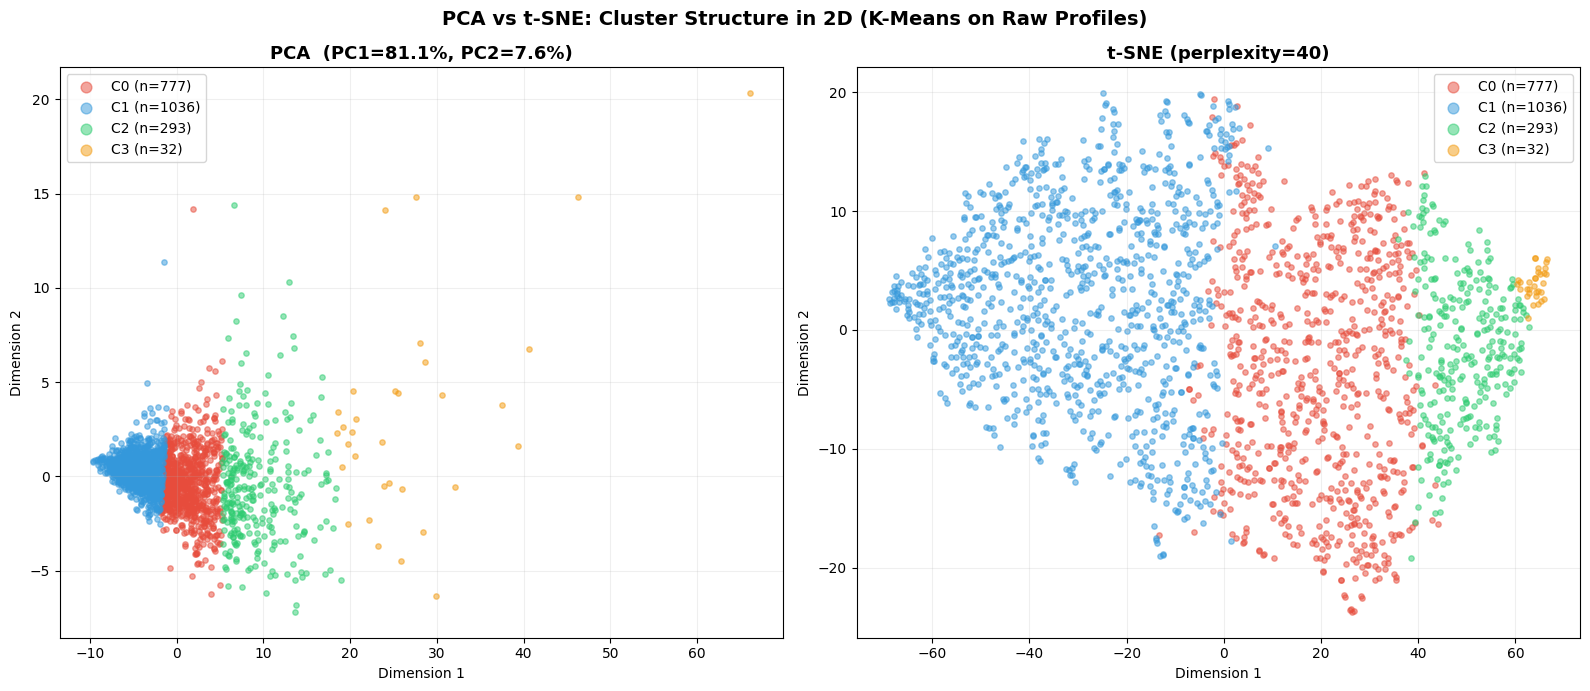

In [66]:
# ============================================================
# t-SNE VISUALIZATION
# ============================================================
from sklearn.manifold import TSNE

print('Running t-SNE (takes ~1-2 min)...')
tsne = TSNE(n_components=2, perplexity=40, random_state=42, n_iter=1000)
X_2d_tsne = tsne.fit_transform(X_raw.values)
print('Done!')

# Also run PCA for comparison
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_2d_pca = pca.fit_transform(X_raw.values)

colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
labels = results_raw['K-Means']

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (X_2d, title) in zip(axes, [
    (X_2d_pca,  f'PCA  (PC1={pca.explained_variance_ratio_[0]*100:.1f}%, PC2={pca.explained_variance_ratio_[1]*100:.1f}%)'),
    (X_2d_tsne, 't-SNE (perplexity=40)'),
]):
    for label in sorted(set(labels)):
        mask = labels == label
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
                   c=colors[label], alpha=0.5, s=15,
                   label=f'C{label} (n={mask.sum()})')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.legend(fontsize=10, markerscale=2)
    ax.set_xlabel('Dimension 1')
    ax.set_ylabel('Dimension 2')
    ax.grid(True, alpha=0.2)

plt.suptitle('PCA vs t-SNE: Cluster Structure in 2D (K-Means on Raw Profiles)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

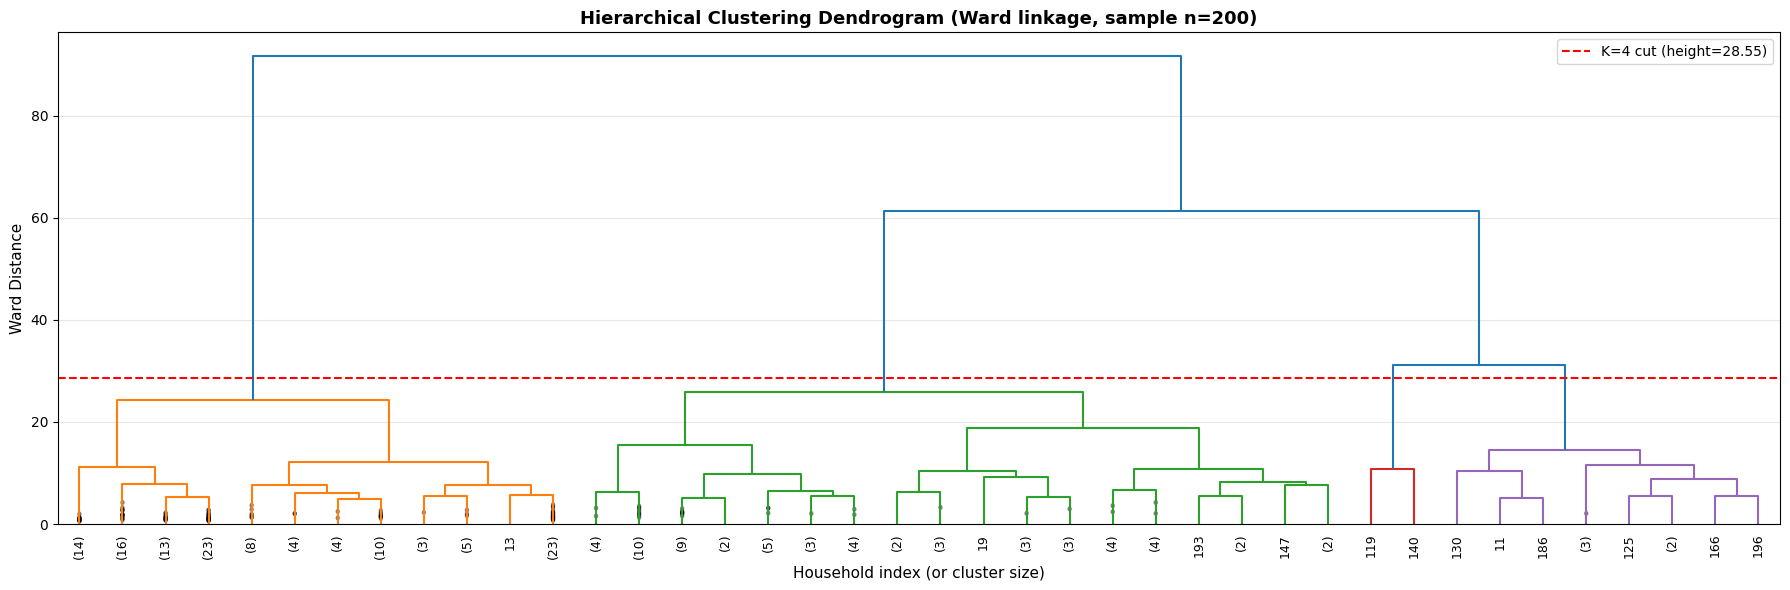

Cluster sizes at K=4 cut (sample of 200):
  Cluster 1: 124 households
  Cluster 2: 63 households
  Cluster 3: 2 households
  Cluster 4: 11 households


In [67]:
# ============================================================
# DENDROGRAM (Hierarchical Clustering)
# ============================================================
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist

# Dendrogram on a subsample (otherwise unreadable at 2138 households)
np.random.seed(42)
sample_idx = np.random.choice(len(X_raw), size=200, replace=False)
X_sample = X_raw.values[sample_idx]

# Compute linkage
Z = linkage(X_sample, method='ward', metric='euclidean')

# Plot
fig, ax = plt.subplots(figsize=(18, 6))

dendrogram(
    Z,
    ax=ax,
    truncate_mode='lastp',   # show only last p merged clusters
    p=40,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True,
    color_threshold=Z[-3, 2],  # colour at K=4 cut
)

# Draw cut line for K=4
cut_height = (Z[-3, 2] + Z[-4, 2]) / 2
ax.axhline(y=cut_height, color='red', linestyle='--', linewidth=1.5,
           label=f'K=4 cut (height={cut_height:.2f})')

ax.set_title('Hierarchical Clustering Dendrogram (Ward linkage, sample n=200)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Household index (or cluster size)', fontsize=11)
ax.set_ylabel('Ward Distance', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Show where K=4 cut lands
labels_dendro = fcluster(Z, t=4, criterion='maxclust')
unique, counts = np.unique(labels_dendro, return_counts=True)
print('Cluster sizes at K=4 cut (sample of 200):')
for u, c in zip(unique, counts):
    print(f'  Cluster {u}: {c} households')

Building co-association matrix...
Done!
Consensus Silhouette: 0.3561


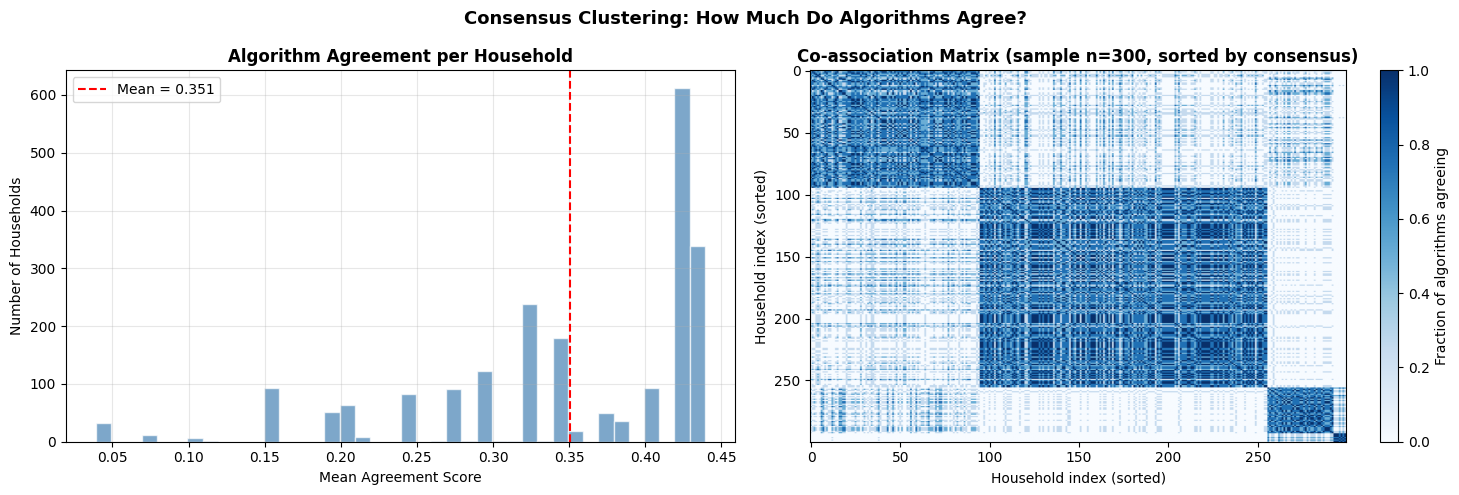


Algorithm         ARI with Consensus
K-Means                       0.8094
K-Medoids                     0.4170
Hierarchical                  0.8635
GMM                           0.2049

Core households (100% agreement): 0 / 2138 (0.0%)
Ambiguous households (<50% agreement): 2138 / 2138 (100.0%)


In [68]:
# ============================================================
# CONSENSUS CLUSTERING
# Do all algorithms agree on the same households?
# ============================================================
import seaborn as sns

# Use the 4 main algorithms (excluding DBSCAN)
algo_labels = {
    'K-Means':      results_raw['K-Means'],
    'K-Medoids':    results_raw['K-Medoids'],
    'Hierarchical': results_raw['Hierarchical'],
    'GMM':          results_raw['GMM'],
}

n = len(X_raw)
n_algos = len(algo_labels)

# Build co-association matrix:
# C[i,j] = fraction of algorithms that put i and j in the same cluster
print('Building co-association matrix...')
co_matrix = np.zeros((n, n))

for name, labels in algo_labels.items():
    for k in range(4):
        mask = labels == k
        idx = np.where(mask)[0]
        co_matrix[np.ix_(idx, idx)] += 1

co_matrix /= n_algos
print('Done!')

# Consensus labels: cluster the co-association matrix itself
from sklearn.cluster import AgglomerativeClustering
consensus_labels = AgglomerativeClustering(
    n_clusters=4, metric='precomputed', linkage='average'
).fit_predict(1 - co_matrix)

sil_consensus = silhouette_score(X_raw, consensus_labels)
print(f'Consensus Silhouette: {sil_consensus:.4f}')

# How often do pairs of households agree? (agreement score per household)
agreement_score = co_matrix.mean(axis=1)

# Plot 1: Agreement score distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(agreement_score, bins=40, color='steelblue', alpha=0.7, edgecolor='white')
axes[0].axvline(agreement_score.mean(), color='red', linestyle='--',
                label=f'Mean = {agreement_score.mean():.3f}')
axes[0].set_xlabel('Mean Agreement Score')
axes[0].set_ylabel('Number of Households')
axes[0].set_title('Algorithm Agreement per Household', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Co-association heatmap on sample
sample_size = 300
np.random.seed(42)
# Sort sample by consensus label for cleaner visual
sort_idx = np.argsort(consensus_labels)
sample_idx = sort_idx[np.linspace(0, n-1, sample_size, dtype=int)]
co_sample = co_matrix[np.ix_(sample_idx, sample_idx)]

im = axes[1].imshow(co_sample, cmap='Blues', aspect='auto', vmin=0, vmax=1)
plt.colorbar(im, ax=axes[1], label='Fraction of algorithms agreeing')
axes[1].set_title('Co-association Matrix (sample n=300, sorted by consensus)',
                  fontweight='bold')
axes[1].set_xlabel('Household index (sorted)')
axes[1].set_ylabel('Household index (sorted)')

plt.suptitle('Consensus Clustering: How Much Do Algorithms Agree?',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Per-algorithm agreement with consensus
print(f'\n{"Algorithm":<15} {"ARI with Consensus":>20}')
print('=' * 37)
from sklearn.metrics import adjusted_rand_score
for name, labels in algo_labels.items():
    ari = adjusted_rand_score(consensus_labels, labels)
    print(f'{name:<15} {ari:>20.4f}')

# "Core" households: agree across ALL algorithms
core_mask = agreement_score >= 0.99
print(f'\nCore households (100% agreement): {core_mask.sum()} / {n} ({core_mask.mean()*100:.1f}%)')
ambiguous_mask = agreement_score < 0.5
print(f'Ambiguous households (<50% agreement): {ambiguous_mask.sum()} / {n} ({ambiguous_mask.mean()*100:.1f}%)')

=== CROSSINGS (normalized profiles) ===
  C0 <-> C1 crossing at ~08:30
  C0 <-> C1 crossing at ~23:00
  C0 <-> C2 crossing at ~10:00
  C0 <-> C2 crossing at ~23:00
  C0 <-> C3 crossing at ~00:00
  C0 <-> C3 crossing at ~11:30
  C0 <-> C3 crossing at ~14:00
  C0 <-> C3 crossing at ~16:30
  C1 <-> C2 crossing at ~09:00
  C1 <-> C2 crossing at ~23:00
  C1 <-> C3 crossing at ~10:30
  C1 <-> C3 crossing at ~14:00
  C1 <-> C3 crossing at ~15:30
  C2 <-> C3 crossing at ~02:00
  C2 <-> C3 crossing at ~17:30

Total crossings: 15


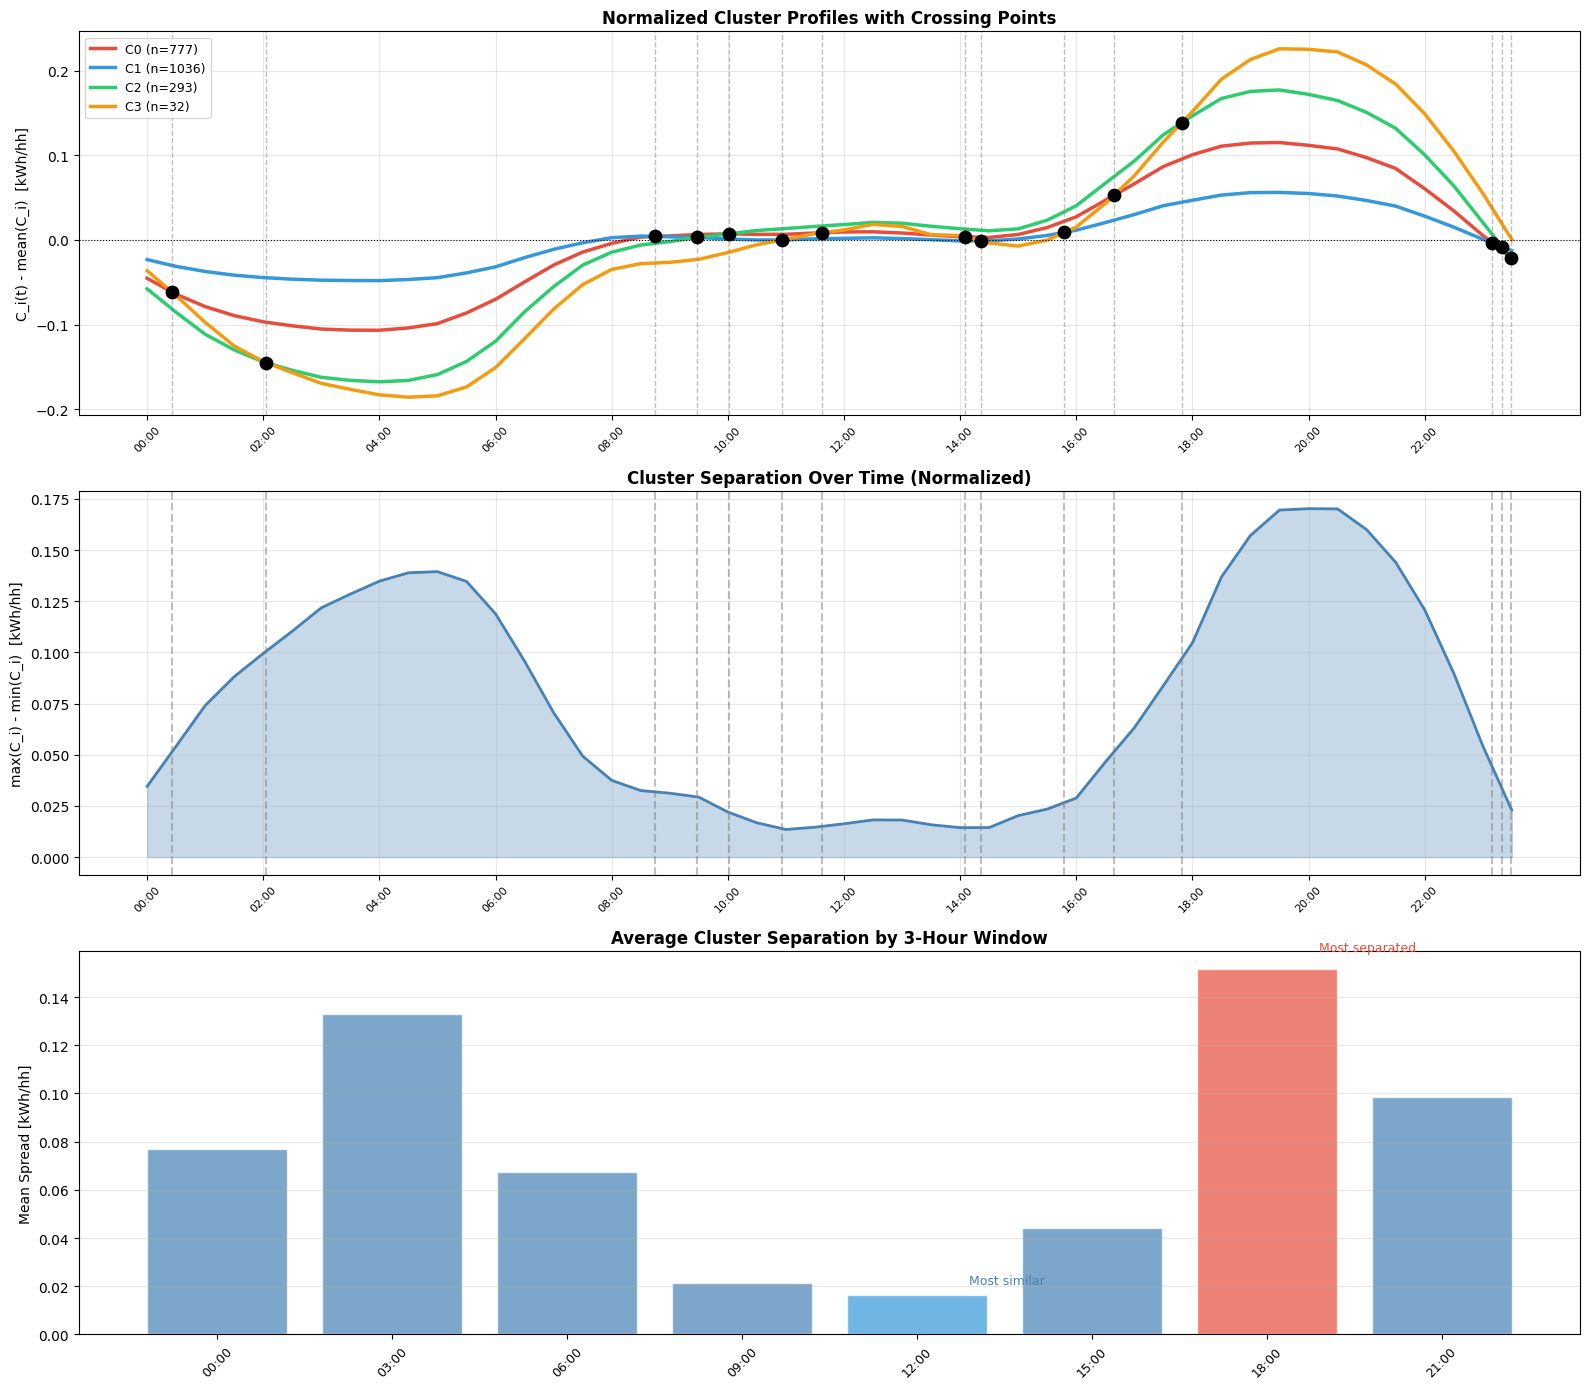


=== 3-HOUR WINDOW SUMMARY ===
  00:00: mean spread = 0.0768 kWh/hh
  03:00: mean spread = 0.1331 kWh/hh
  06:00: mean spread = 0.0674 kWh/hh
  09:00: mean spread = 0.0212 kWh/hh
  12:00: mean spread = 0.0162 kWh/hh
  15:00: mean spread = 0.0443 kWh/hh
  18:00: mean spread = 0.1514 kWh/hh
  21:00: mean spread = 0.0987 kWh/hh


In [69]:
# ============================================================
# WINDOW SEPARATION + CROSSINGS ANALYSIS
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

labels_best_raw = results_raw['K-Means']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]

# 1. Cluster mean profiles
cluster_means = {}
for c in sorted(set(labels_best_raw)):
    mask = labels_best_raw == c
    cluster_means[c] = profiles_original_clean.iloc[mask].mean().values

# 2. Normalized profiles: subtract each cluster's temporal mean
cluster_norm = {}
for c, profile in cluster_means.items():
    cluster_norm[c] = profile - profile.mean()

# 3. Find crossings on normalized profiles
print("=== CROSSINGS (normalized profiles) ===")
crossing_points = []
pairs = [(i, j) for i in range(4) for j in range(i+1, 4)]
for i, j in pairs:
    diff = cluster_norm[i] - cluster_norm[j]
    for t in range(len(diff) - 1):
        if diff[t] * diff[t+1] < 0:
            t_cross = t + diff[t] / (diff[t] - diff[t+1])
            crossing_points.append((t_cross, i, j))
            print(f"  C{i} <-> C{j} crossing at ~{x_labels[int(t_cross)]}")
print(f"\nTotal crossings: {len(crossing_points)}")

# 4. Instantaneous spread: max - min across clusters
n_slots = 48
spread_norm = np.array([max(cluster_norm[c][t] for c in range(4)) -
                         min(cluster_norm[c][t] for c in range(4)) for t in range(n_slots)])

# 5. 3-hour window average spread (6 half-hour slots = 3 hours)
window_size = 6
n_windows = n_slots // window_size
window_labels_3h = [x_labels[i * window_size] for i in range(n_windows)]
window_spread = [spread_norm[i*window_size:(i+1)*window_size].mean() for i in range(n_windows)]

# 6. Plots
fig, axes = plt.subplots(3, 1, figsize=(16, 14))

# Plot 1: normalized profiles + crossing points
ax = axes[0]
for c in range(4):
    ax.plot(range(n_slots), cluster_norm[c], color=colors[c],
            linewidth=2.5, label=f'C{c} (n={int((labels_best_raw==c).sum())})')
for t_cross, i, j in crossing_points:
    ax.axvline(x=t_cross, color='gray', linestyle='--', alpha=0.5, linewidth=1)
    y_val = np.interp(t_cross, range(n_slots), cluster_norm[i])
    ax.scatter([t_cross], [y_val], color='black', s=80, zorder=5)
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.set_xticks(range(0, n_slots, 4))
ax.set_xticklabels([x_labels[j] for j in range(0, n_slots, 4)], rotation=45, fontsize=8)
ax.set_ylabel('C_i(t) - mean(C_i)  [kWh/hh]')
ax.set_title('Normalized Cluster Profiles with Crossing Points', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# Plot 2: instantaneous spread over time
ax = axes[1]
ax.fill_between(range(n_slots), spread_norm, alpha=0.3, color='steelblue')
ax.plot(range(n_slots), spread_norm, color='steelblue', linewidth=2)
for t_cross, i, j in crossing_points:
    ax.axvline(x=t_cross, color='gray', linestyle='--', alpha=0.5)
ax.set_xticks(range(0, n_slots, 4))
ax.set_xticklabels([x_labels[j] for j in range(0, n_slots, 4)], rotation=45, fontsize=8)
ax.set_ylabel('max(C_i) - min(C_i)  [kWh/hh]')
ax.set_title('Cluster Separation Over Time (Normalized)', fontweight='bold')
ax.grid(True, alpha=0.3)

# Plot 3: 3-hour window average spread
ax = axes[2]
bar_colors = ['#e74c3c' if w == max(window_spread) else
              '#3498db' if w == min(window_spread) else 'steelblue'
              for w in window_spread]
ax.bar(range(n_windows), window_spread, color=bar_colors, alpha=0.7, edgecolor='white')
ax.set_xticks(range(n_windows))
ax.set_xticklabels(window_labels_3h, rotation=45, fontsize=9)
ax.set_ylabel('Mean Spread [kWh/hh]')
ax.set_title('Average Cluster Separation by 3-Hour Window', fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')
max_w = int(np.argmax(window_spread))
min_w = int(np.argmin(window_spread))
ax.annotate('Most separated', xy=(max_w, window_spread[max_w]),
            xytext=(max_w+0.3, window_spread[max_w]*1.05), fontsize=9, color='#e74c3c')
ax.annotate('Most similar', xy=(min_w, window_spread[min_w]),
            xytext=(min_w+0.3, window_spread[min_w]*1.3), fontsize=9, color='steelblue')

plt.tight_layout()
plt.show()

print("\n=== 3-HOUR WINDOW SUMMARY ===")
for i, (label, spread) in enumerate(zip(window_labels_3h, window_spread)):
    print(f"  {label}: mean spread = {spread:.4f} kWh/hh")


> **SUPERSEDED — retained for methodological discussion.**
> Result: coincidence factor cf = 1.000 for every cluster at the system peak.
> Problem: cf = 1.000 identically by construction (all cluster means peak at slot 39; Result A), not a finding; it ignores load diversity.
> Corrected in: Result C (diversity-corrected coincidence factor) and C2 (per-day data).

=== GRID IMPACT ANALYSIS ===

System peak: 600.1 kWh at 19:30

Cluster         N   Peak kWh/hh   Peak Time  Cluster Total at SysPeak  Share of SysPeak%
C0            777         0.324       19:30                     252.0              42.0%
C1           1036         0.156       19:30                     161.9              27.0%
C2            293         0.536       19:30                     157.0              26.2%
C3             32         0.912       19:30                      29.2               4.9%

Cluster     Individual Peak   Value at SysPeak   Coincidence Factor
C0                    0.324              0.324               1.000
C1                    0.156              0.156               1.000
C2                    0.536              0.536               1.000
C3                    0.912              0.912               1.000


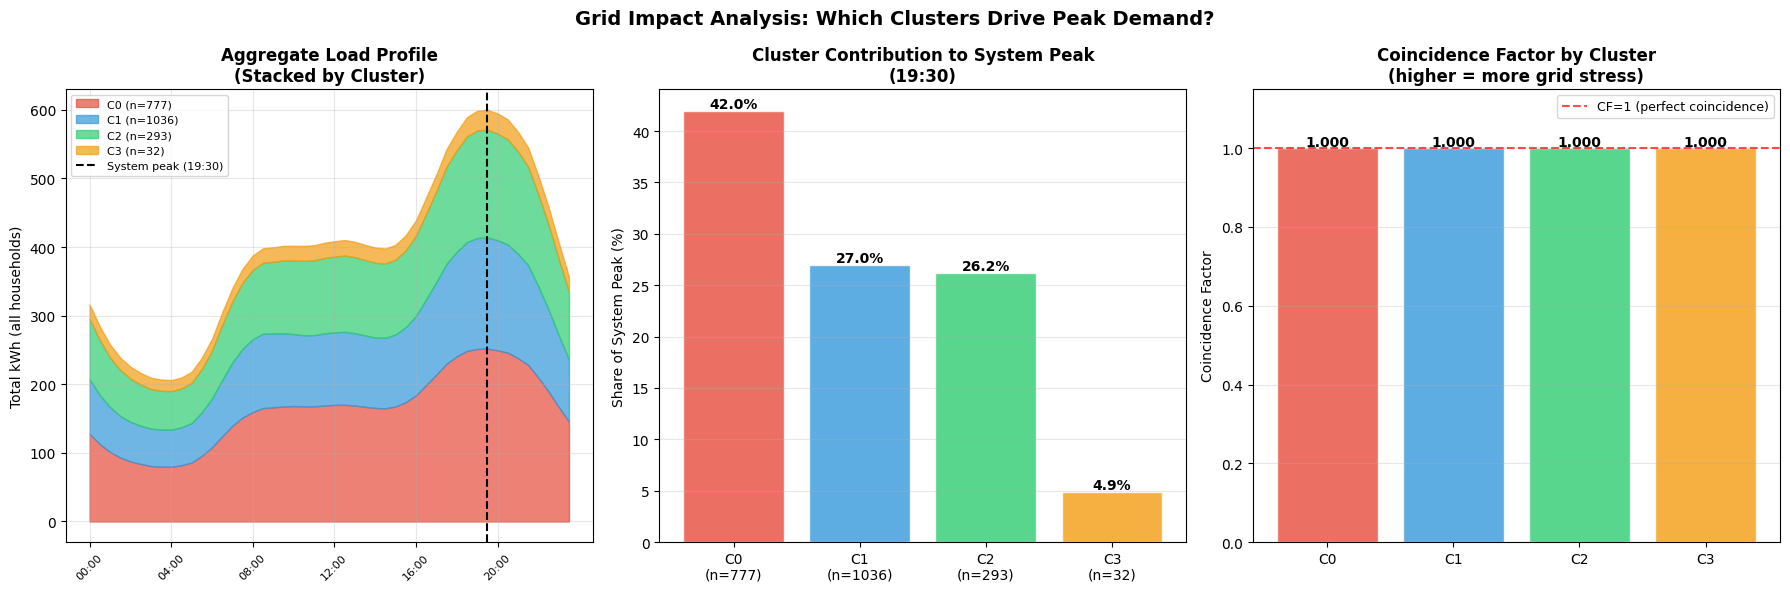

In [70]:
# ============================================================
# GRID IMPACT ANALYSIS: Coincidence Factor & Contribution to Peak
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

labels_best_raw = results_raw['K-Means']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]

cluster_ids = sorted(set(labels_best_raw))

# Per-cluster stats
cluster_n       = {c: int((labels_best_raw == c).sum()) for c in cluster_ids}
cluster_mean    = {c: profiles_original_clean.iloc[labels_best_raw == c].mean().values for c in cluster_ids}
cluster_peak    = {c: cluster_mean[c].max() for c in cluster_ids}
cluster_peak_t  = {c: int(cluster_mean[c].argmax()) for c in cluster_ids}

# System-level aggregate (sum of all household profiles at each slot)
agg_profile = profiles_original_clean.sum(axis=0).values  # total kWh/hh per slot
system_peak_t = int(agg_profile.argmax())
system_peak_val = agg_profile.max()

print("=== GRID IMPACT ANALYSIS ===\n")
print(f"System peak: {system_peak_val:.1f} kWh at {x_labels[system_peak_t]}\n")

# Contribution of each cluster to system peak
print(f"{'Cluster':<10} {'N':>6} {'Peak kWh/hh':>13} {'Peak Time':>11} "
      f"{'Cluster Total at SysPeak':>25} {'Share of SysPeak%':>18}")
print('=' * 85)

contributions = {}
for c in cluster_ids:
    mask = labels_best_raw == c
    # Each cluster's contribution at system peak time
    cluster_at_syspeak = profiles_original_clean.iloc[mask, system_peak_t].sum()
    share = cluster_at_syspeak / system_peak_val * 100
    contributions[c] = {'total': cluster_at_syspeak, 'share': share}
    print(f"C{c:<9} {cluster_n[c]:>6} {cluster_peak[c]:>13.3f} "
          f"{x_labels[cluster_peak_t[c]]:>11} {cluster_at_syspeak:>25.1f} {share:>17.1f}%")

# Coincidence Factor per cluster:
# CF = (cluster mean profile at system peak) / (cluster individual peak)
# CF = 1 means all households in cluster peak simultaneously with the system
print(f"\n{'Cluster':<10} {'Individual Peak':>16} {'Value at SysPeak':>18} {'Coincidence Factor':>20}")
print('=' * 66)
for c in cluster_ids:
    mask = labels_best_raw == c
    val_at_syspeak = profiles_original_clean.iloc[mask, system_peak_t].mean()
    cf = val_at_syspeak / cluster_peak[c]
    print(f"C{c:<9} {cluster_peak[c]:>16.3f} {val_at_syspeak:>18.3f} {cf:>19.3f}")

# Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot 1: Aggregate system profile + cluster contributions (stacked)
ax = axes[0]
bottom = np.zeros(48)
for c in cluster_ids:
    mask = labels_best_raw == c
    contrib = profiles_original_clean.iloc[mask].sum(axis=0).values
    ax.fill_between(range(48), bottom, bottom + contrib,
                    alpha=0.7, color=colors[c], label=f'C{c} (n={cluster_n[c]})')
    bottom += contrib
ax.axvline(system_peak_t, color='black', linestyle='--', linewidth=1.5,
           label=f'System peak ({x_labels[system_peak_t]})')
ax.set_xticks(range(0, 48, 8))
ax.set_xticklabels([x_labels[j] for j in range(0, 48, 8)], rotation=45, fontsize=8)
ax.set_ylabel('Total kWh (all households)')
ax.set_title('Aggregate Load Profile\n(Stacked by Cluster)', fontweight='bold')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# Plot 2: Share of system peak contribution per cluster
ax = axes[1]
shares = [contributions[c]['share'] for c in cluster_ids]
bars = ax.bar([f'C{c}\n(n={cluster_n[c]})' for c in cluster_ids],
              shares, color=colors, alpha=0.8, edgecolor='white')
for bar, share in zip(bars, shares):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{share:.1f}%', ha='center', fontsize=10, fontweight='bold')
ax.set_ylabel('Share of System Peak (%)')
ax.set_title(f'Cluster Contribution to System Peak\n({x_labels[system_peak_t]})', fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

# Plot 3: Coincidence Factor per cluster
ax = axes[2]
cfs = []
for c in cluster_ids:
    mask = labels_best_raw == c
    val_at_syspeak = profiles_original_clean.iloc[mask, system_peak_t].mean()
    cfs.append(val_at_syspeak / cluster_peak[c])
bars = ax.bar([f'C{c}' for c in cluster_ids], cfs, color=colors, alpha=0.8, edgecolor='white')
for bar, cf in zip(bars, cfs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{cf:.3f}', ha='center', fontsize=10, fontweight='bold')
ax.axhline(1.0, color='red', linestyle='--', alpha=0.7, label='CF=1 (perfect coincidence)')
ax.set_ylabel('Coincidence Factor')
ax.set_title('Coincidence Factor by Cluster\n(higher = more grid stress)', fontweight='bold')
ax.set_ylim(0, 1.15)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Grid Impact Analysis: Which Clusters Drive Peak Demand?',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


=== HOUSEHOLD REGULARITY ANALYSIS ===

Cluster         N   Mean Entropy   Std Entropy    Mean CV       Interpretation
C0            777         3.5603        0.0816      0.400      Medium consumer
C1           1036         3.5137        0.1165      0.427         Low consumer
C2            293         3.5775        0.0712      0.366        High consumer
C3             32         3.5962        0.0943      0.237   Very high consumer

Note: Lower entropy = more peaked/predictable daily pattern
      Higher CV = more variation across half-hours (more structured)


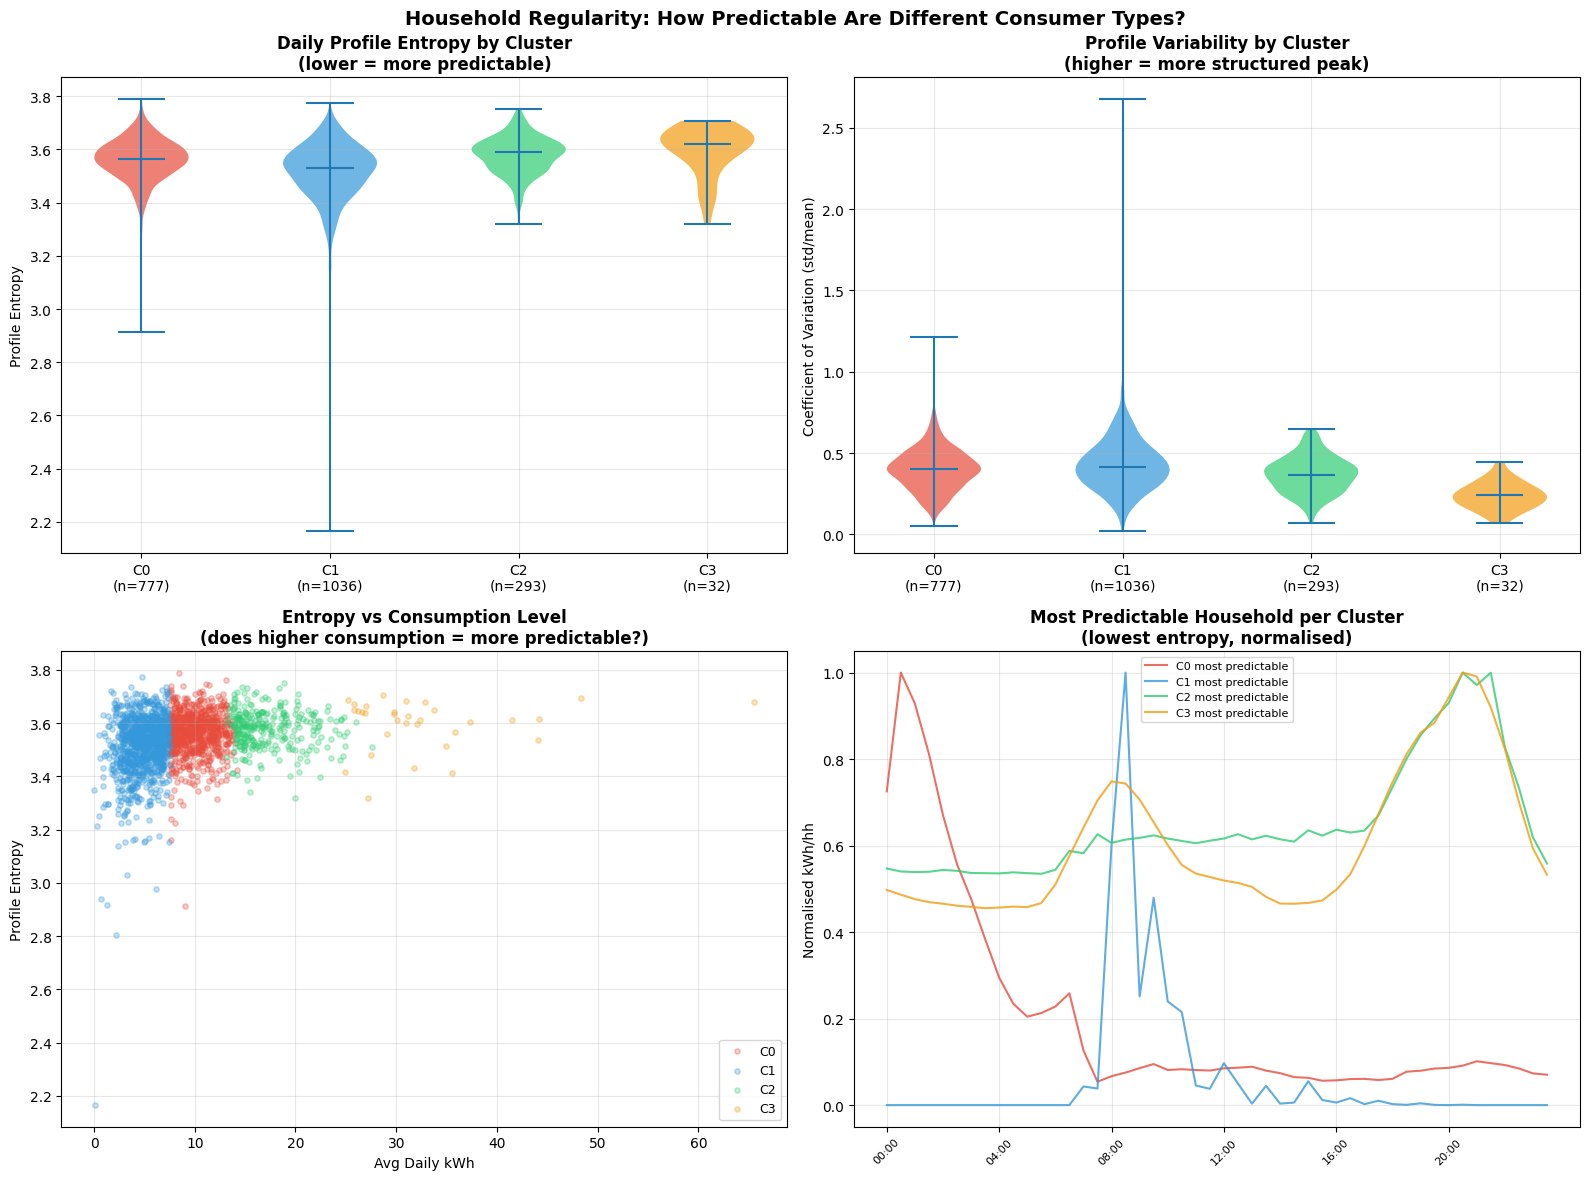

In [71]:
# ============================================================
# HOUSEHOLD REGULARITY ANALYSIS: How predictable is each household?
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy as scipy_entropy

labels_best_raw = results_raw['K-Means']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
cluster_ids = sorted(set(labels_best_raw))

# Compute entropy of each household's daily profile
# (normalise profile to sum=1 so it becomes a probability distribution)
# High entropy = flat/unpredictable, Low entropy = peaked/predictable

def profile_entropy(row):
    p = row.values.astype(float)
    p = p - p.min() + 1e-9   # shift to positive
    p = p / p.sum()
    return scipy_entropy(p)

entropies = profiles_original_clean.apply(profile_entropy, axis=1)

# Also compute coefficient of variation (std/mean) as second regularity metric
cv = profiles_original_clean.std(axis=1) / profiles_original_clean.mean(axis=1)

print("=== HOUSEHOLD REGULARITY ANALYSIS ===\n")
print(f"{'Cluster':<10} {'N':>6} {'Mean Entropy':>14} {'Std Entropy':>13} "
      f"{'Mean CV':>10} {'Interpretation':>20}")
print('=' * 75)
interpretations = {0: 'Medium consumer', 1: 'Low consumer',
                   2: 'High consumer', 3: 'Very high consumer'}
for c in cluster_ids:
    mask = labels_best_raw == c
    ent = entropies[mask]
    c_cv = cv[mask]
    print(f"C{c:<9} {mask.sum():>6} {ent.mean():>14.4f} {ent.std():>13.4f} "
          f"{c_cv.mean():>10.3f} {interpretations[c]:>20}")

print("\nNote: Lower entropy = more peaked/predictable daily pattern")
print("      Higher CV = more variation across half-hours (more structured)")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Entropy distribution per cluster (violin)
ax = axes[0, 0]
data_by_cluster = [entropies[labels_best_raw == c].values for c in cluster_ids]
parts = ax.violinplot(data_by_cluster, positions=cluster_ids, showmedians=True)
for pc, color in zip(parts['bodies'], colors):
    pc.set_facecolor(color)
    pc.set_alpha(0.7)
ax.set_xticks(cluster_ids)
ax.set_xticklabels([f'C{c}\n(n={(labels_best_raw==c).sum()})' for c in cluster_ids])
ax.set_ylabel('Profile Entropy')
ax.set_title('Daily Profile Entropy by Cluster\n(lower = more predictable)', fontweight='bold')
ax.grid(True, alpha=0.3)

# Plot 2: CV distribution per cluster (violin)
ax = axes[0, 1]
cv_by_cluster = [cv[labels_best_raw == c].values for c in cluster_ids]
parts = ax.violinplot(cv_by_cluster, positions=cluster_ids, showmedians=True)
for pc, color in zip(parts['bodies'], colors):
    pc.set_facecolor(color)
    pc.set_alpha(0.7)
ax.set_xticks(cluster_ids)
ax.set_xticklabels([f'C{c}\n(n={(labels_best_raw==c).sum()})' for c in cluster_ids])
ax.set_ylabel('Coefficient of Variation (std/mean)')
ax.set_title('Profile Variability by Cluster\n(higher = more structured peak)', fontweight='bold')
ax.grid(True, alpha=0.3)

# Plot 3: Entropy vs Daily kWh scatter
ax = axes[1, 0]
daily_kwh = profiles_original_clean.sum(axis=1)
for c in cluster_ids:
    mask = labels_best_raw == c
    ax.scatter(daily_kwh[mask], entropies[mask],
               color=colors[c], alpha=0.3, s=15, label=f'C{c}')
ax.set_xlabel('Avg Daily kWh')
ax.set_ylabel('Profile Entropy')
ax.set_title('Entropy vs Consumption Level\n(does higher consumption = more predictable?)',
             fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# Plot 4: Most vs least predictable households per cluster
ax = axes[1, 1]
x_labels_48 = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
for c in cluster_ids:
    mask = labels_best_raw == c
    ent_cluster = entropies[mask]
    # Most predictable (lowest entropy)
    most_pred_idx = ent_cluster.idxmin()
    least_pred_idx = ent_cluster.idxmax()
    profile_pred = profiles_original_clean.loc[most_pred_idx].values
    profile_pred = profile_pred / profile_pred.max()  # normalise to 1
    ax.plot(range(48), profile_pred, color=colors[c], linewidth=1.5,
            linestyle='-', alpha=0.8, label=f'C{c} most predictable')
ax.set_xticks(range(0, 48, 8))
ax.set_xticklabels([x_labels_48[j] for j in range(0, 48, 8)], rotation=45, fontsize=8)
ax.set_ylabel('Normalised kWh/hh')
ax.set_title('Most Predictable Household per Cluster\n(lowest entropy, normalised)',
             fontweight='bold')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.suptitle('Household Regularity: How Predictable Are Different Consumer Types?',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


=== SEASONAL TRANSITION ANALYSIS ===

Households that changed cluster (winter or summer vs annual): 1210 / 2138 (56.6%)
Stable households: 928 (43.4%)

Group                     N   Mean Daily kWh      Std
Stable                  928             4.57     1.51
Switchers              1210            12.11     5.39

--- Switchers by annual cluster ---
  C0 (n=777): 777 switched (100.0%)
  C1 (n=1036): 108 switched (10.4%)
  C2 (n=293): 293 switched (100.0%)
  C3 (n=32): 32 switched (100.0%)

--- ACORN distribution: Stable vs Switchers ---
switched_any  Stable  Switcher
acorn                         
ACORN-U          0.4       0.6
Adversity       35.8      30.3
Affluent        42.2      42.7
Comfortable     21.6      26.4


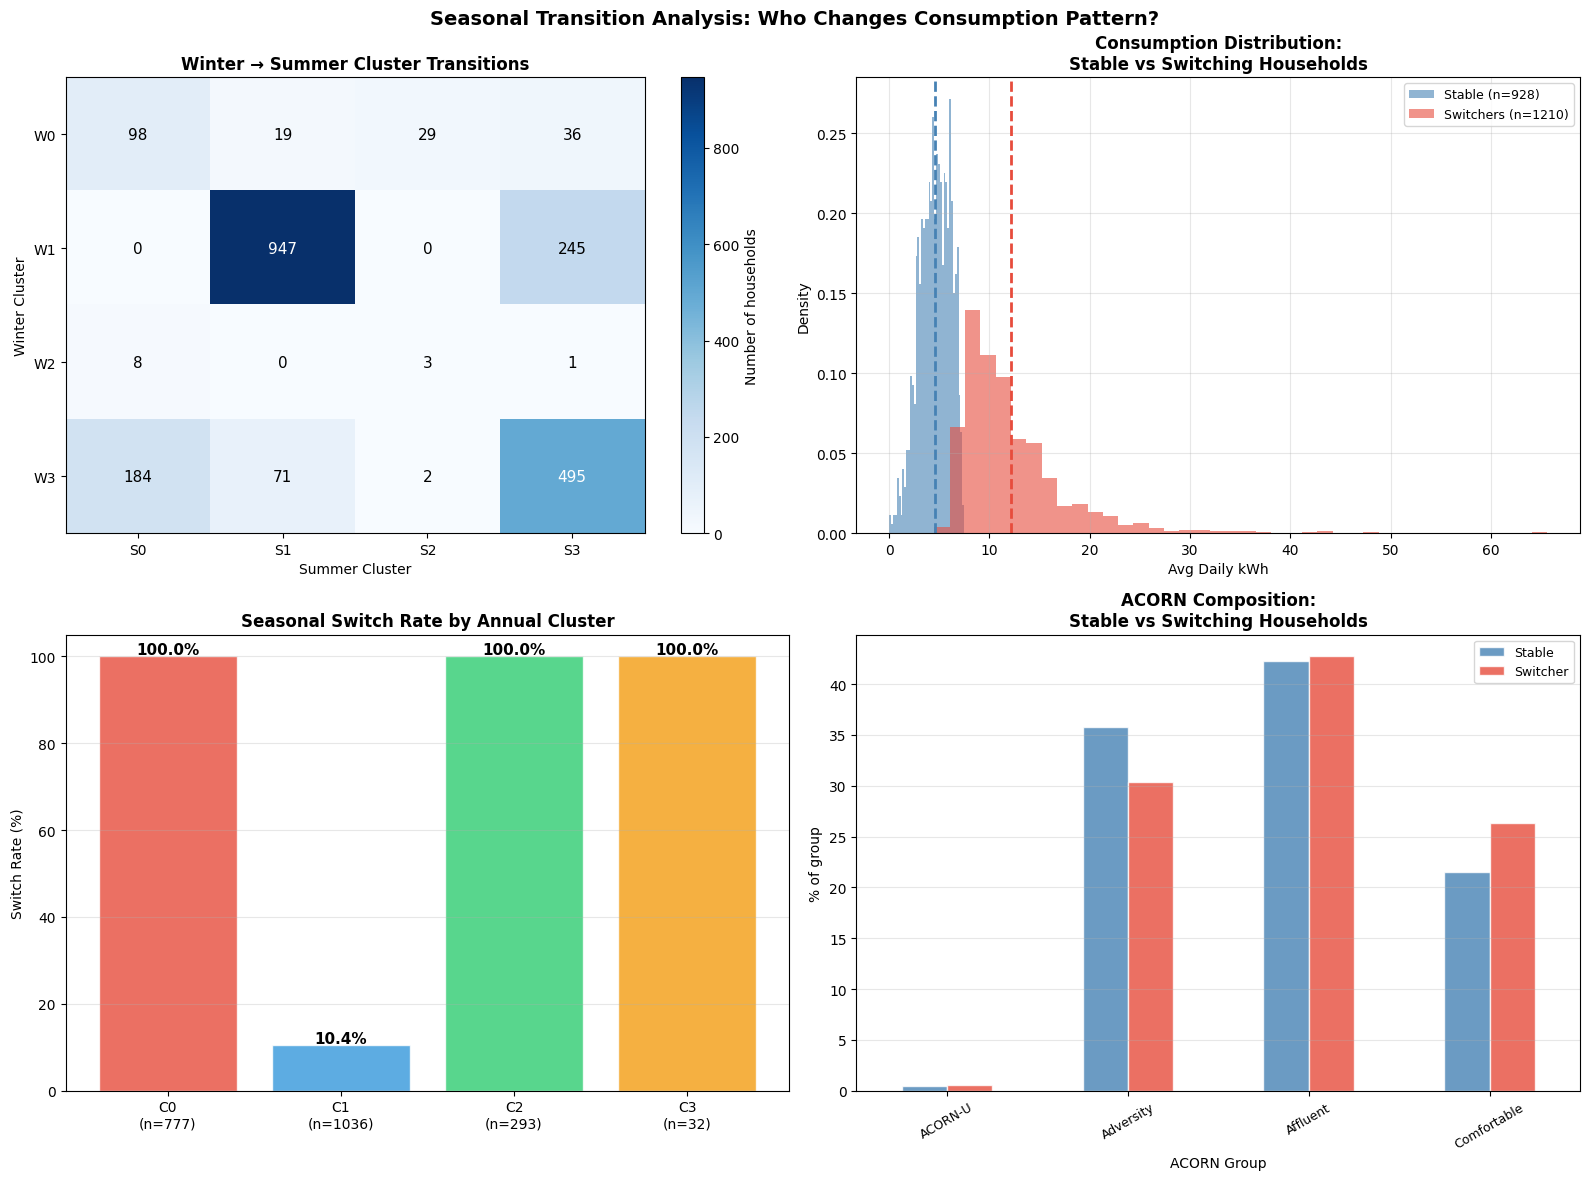

In [72]:
# ============================================================
# SEASONAL TRANSITION ANALYSIS: Who switches clusters?
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

labels_best_raw = results_raw['K-Means']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
cluster_ids = sorted(set(labels_best_raw))

# Re-run winter/summer clustering to get per-season labels
# (aligned with the 2138 clean households)
common_ids = profiles_winter.index.intersection(profiles_summer.index).intersection(profiles_original_clean.index)
profiles_winter_a = profiles_winter.loc[common_ids]
profiles_summer_a = profiles_summer.loc[common_ids]

scaler_w = StandardScaler()
scaler_s = StandardScaler()
X_w = scaler_w.fit_transform(profiles_winter_a)
X_s = scaler_s.fit_transform(profiles_summer_a)

km_w = KMeans(n_clusters=4, random_state=42, n_init=10)
km_s = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_w = km_w.fit_predict(X_w)
labels_s = km_s.fit_predict(X_s)

# Annual labels aligned to same households
annual_labels = pd.Series(labels_best_raw, index=profiles_original_clean.index)
annual_aligned = annual_labels.loc[common_ids].values

# Build transition DataFrame
df_trans = pd.DataFrame({
    'LCLid':   common_ids,
    'annual':  annual_aligned,
    'winter':  labels_w,
    'summer':  labels_s,
    'daily_kwh': profiles_original_clean.loc[common_ids].sum(axis=1).values
})

# Add ACORN if available
hh_idx = household_info.set_index('LCLid')
df_trans['acorn'] = df_trans['LCLid'].map(
    lambda x: hh_idx.loc[x, 'Acorn_grouped'] if x in hh_idx.index else 'Unknown')

# Switchers: households that changed annual cluster between winter and summer
# (comparing against annual K-Means labels)
df_trans['switched_w'] = df_trans['annual'] != df_trans['winter']
df_trans['switched_s'] = df_trans['annual'] != df_trans['summer']
df_trans['switched_any'] = df_trans['switched_w'] | df_trans['switched_s']

n_switched = df_trans['switched_any'].sum()
n_total = len(df_trans)
print("=== SEASONAL TRANSITION ANALYSIS ===\n")
print(f"Households that changed cluster (winter or summer vs annual): "
      f"{n_switched} / {n_total} ({n_switched/n_total*100:.1f}%)")
print(f"Stable households: {n_total - n_switched} ({(n_total-n_switched)/n_total*100:.1f}%)\n")

# Consumption comparison: switchers vs stable
print(f"{'Group':<20} {'N':>6} {'Mean Daily kWh':>16} {'Std':>8}")
print('=' * 52)
for group, mask in [('Stable', ~df_trans['switched_any']),
                    ('Switchers', df_trans['switched_any'])]:
    kwh = df_trans.loc[mask, 'daily_kwh']
    print(f"{group:<20} {mask.sum():>6} {kwh.mean():>16.2f} {kwh.std():>8.2f}")

print("\n--- Switchers by annual cluster ---")
for c in cluster_ids:
    mask_c = df_trans['annual'] == c
    switched_in_c = df_trans.loc[mask_c, 'switched_any'].sum()
    total_in_c = mask_c.sum()
    print(f"  C{c} (n={total_in_c}): {switched_in_c} switched "
          f"({switched_in_c/total_in_c*100:.1f}%)")

print("\n--- ACORN distribution: Stable vs Switchers ---")
acorn_table = pd.crosstab(df_trans['acorn'],
                           df_trans['switched_any'].map({True: 'Switcher', False: 'Stable'}),
                           normalize='columns') * 100
print(acorn_table.round(1))

# Plots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Sankey-style alluvial — winter cluster → summer cluster
ax = axes[0, 0]
trans_matrix = pd.crosstab(
    pd.Series(labels_w, name='Winter'),
    pd.Series(labels_s, name='Summer')
)
im = ax.imshow(trans_matrix.values, cmap='Blues', aspect='auto')
plt.colorbar(im, ax=ax, label='Number of households')
ax.set_xticks(range(4)); ax.set_yticks(range(4))
ax.set_xticklabels([f'S{c}' for c in range(4)])
ax.set_yticklabels([f'W{c}' for c in range(4)])
ax.set_xlabel('Summer Cluster'); ax.set_ylabel('Winter Cluster')
ax.set_title('Winter → Summer Cluster Transitions', fontweight='bold')
for i in range(4):
    for j in range(4):
        ax.text(j, i, str(trans_matrix.values[i, j]),
                ha='center', va='center', fontsize=11,
                color='white' if trans_matrix.values[i, j] > 300 else 'black')

# Plot 2: Daily kWh distribution — Stable vs Switchers
ax = axes[0, 1]
stable_kwh   = df_trans.loc[~df_trans['switched_any'], 'daily_kwh']
switcher_kwh = df_trans.loc[df_trans['switched_any'],  'daily_kwh']
ax.hist(stable_kwh,   bins=40, alpha=0.6, color='steelblue', label=f'Stable (n={len(stable_kwh)})', density=True)
ax.hist(switcher_kwh, bins=40, alpha=0.6, color='#e74c3c',   label=f'Switchers (n={len(switcher_kwh)})', density=True)
ax.axvline(stable_kwh.mean(),   color='steelblue', linestyle='--', linewidth=2)
ax.axvline(switcher_kwh.mean(), color='#e74c3c',   linestyle='--', linewidth=2)
ax.set_xlabel('Avg Daily kWh'); ax.set_ylabel('Density')
ax.set_title('Consumption Distribution:\nStable vs Switching Households', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# Plot 3: Switch rate by annual cluster
ax = axes[1, 0]
switch_rates = []
for c in cluster_ids:
    mask_c = df_trans['annual'] == c
    rate = df_trans.loc[mask_c, 'switched_any'].mean() * 100
    switch_rates.append(rate)
bars = ax.bar([f'C{c}\n(n={(df_trans["annual"]==c).sum()})' for c in cluster_ids],
              switch_rates, color=colors, alpha=0.8, edgecolor='white')
for bar, rate in zip(bars, switch_rates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{rate:.1f}%', ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('Switch Rate (%)')
ax.set_title('Seasonal Switch Rate by Annual Cluster', fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

# Plot 4: ACORN composition — Stable vs Switchers
ax = axes[1, 1]
acorn_plot = pd.crosstab(df_trans['acorn'],
                          df_trans['switched_any'].map({True: 'Switcher', False: 'Stable'}),
                          normalize='columns') * 100
acorn_plot = acorn_plot[['Stable', 'Switcher']]
acorn_plot.plot(kind='bar', ax=ax, color=['steelblue', '#e74c3c'],
                alpha=0.8, edgecolor='white')
ax.set_xlabel('ACORN Group'); ax.set_ylabel('% of group')
ax.set_title('ACORN Composition:\nStable vs Switching Households', fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=9)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Seasonal Transition Analysis: Who Changes Consumption Pattern?',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


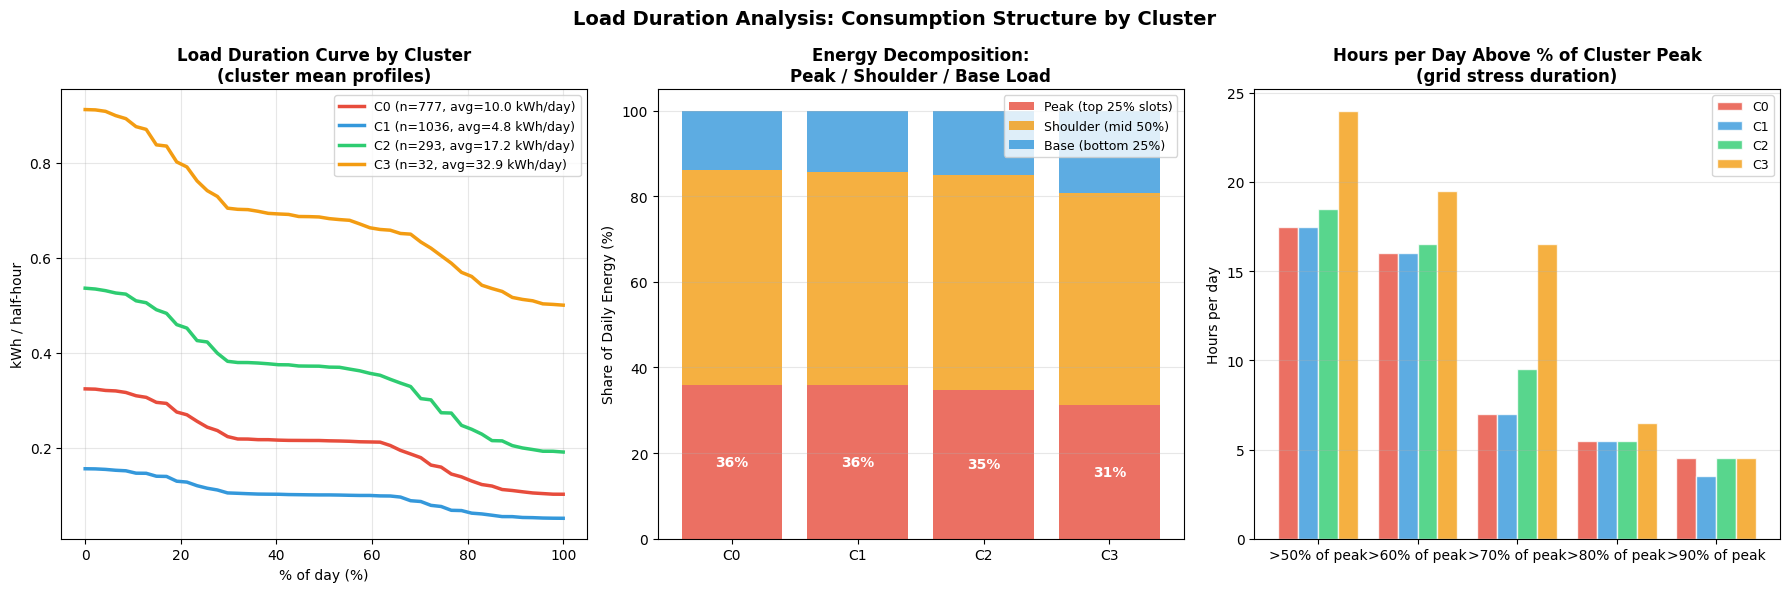


=== LOAD DURATION SUMMARY ===
Cluster       Daily kWh    Peak%   Shoulder%    Base%
C0               10.045    36.0%       50.1%    14.0%
C1                4.807    35.9%       49.6%    14.5%
C2               17.228    34.7%       50.2%    15.1%
C3               32.926    31.3%       49.4%    19.3%


In [73]:

# ============================================================
# LOAD DURATION CURVE BY CLUSTER
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

labels_best_raw = results_raw['K-Means']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
cluster_ids = sorted(set(labels_best_raw))
x_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]

# For each cluster: compute mean profile, then sort descending = LDC
# LDC shows: for what % of the day does consumption exceed a given level?

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot 1: Load Duration Curves (mean profiles sorted descending)
ax = axes[0]
for c in cluster_ids:
    mask = labels_best_raw == c
    mean_profile = profiles_original_clean.iloc[mask].mean().values
    ldc = np.sort(mean_profile)[::-1]  # sort descending
    pct = np.linspace(0, 100, len(ldc))
    ax.plot(pct, ldc, color=colors[c], linewidth=2.5,
            label=f'C{c} (n={mask.sum()}, avg={mean_profile.mean()*48:.1f} kWh/day)')
ax.set_xlabel('% of day (%)')
ax.set_ylabel('kWh / half-hour')
ax.set_title('Load Duration Curve by Cluster\n(cluster mean profiles)', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# Plot 2: Area under LDC = daily energy — stacked bar comparison
ax = axes[1]
metrics = {}
for c in cluster_ids:
    mask = labels_best_raw == c
    mean_profile = profiles_original_clean.iloc[mask].mean().values
    ldc = np.sort(mean_profile)[::-1]
    pct = np.linspace(0, 100, len(ldc))
    # Split into peak (top 25%), shoulder (25-75%), base (75-100%)
    peak_e     = mean_profile[mean_profile >= np.percentile(mean_profile, 75)].sum()
    shoulder_e = mean_profile[(mean_profile >= np.percentile(mean_profile, 25)) &
                              (mean_profile < np.percentile(mean_profile, 75))].sum()
    base_e     = mean_profile[mean_profile < np.percentile(mean_profile, 25)].sum()
    total_e    = mean_profile.sum()
    metrics[c] = {'peak': peak_e/total_e*100,
                  'shoulder': shoulder_e/total_e*100,
                  'base': base_e/total_e*100,
                  'total': total_e}

cluster_labels_x = [f'C{c}' for c in cluster_ids]
peaks     = [metrics[c]['peak']     for c in cluster_ids]
shoulders = [metrics[c]['shoulder'] for c in cluster_ids]
bases     = [metrics[c]['base']     for c in cluster_ids]

b1 = ax.bar(cluster_labels_x, peaks,     label='Peak (top 25% slots)',     color='#e74c3c', alpha=0.8)
b2 = ax.bar(cluster_labels_x, shoulders, bottom=peaks,
            label='Shoulder (mid 50%)', color='#f39c12', alpha=0.8)
b3 = ax.bar(cluster_labels_x, bases,
            bottom=[p+s for p,s in zip(peaks, shoulders)],
            label='Base (bottom 25%)',  color='#3498db', alpha=0.8)
for bar, c in zip(b1, cluster_ids):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
            f'{metrics[c]["peak"]:.0f}%', ha='center', va='center',
            fontsize=10, fontweight='bold', color='white')
ax.set_ylabel('Share of Daily Energy (%)')
ax.set_title('Energy Decomposition:\nPeak / Shoulder / Base Load', fontweight='bold')
ax.legend(fontsize=9, loc='upper right'); ax.grid(True, alpha=0.3, axis='y')

# Plot 3: Hours above 90% of cluster peak
ax = axes[2]
hours_above = []
thresholds = [0.5, 0.6, 0.7, 0.8, 0.9]
for c in cluster_ids:
    mask = labels_best_raw == c
    mean_profile = profiles_original_clean.iloc[mask].mean().values
    peak_val = mean_profile.max()
    row = [(mean_profile >= thr * peak_val).sum() / 2  # convert slots to hours
           for thr in thresholds]
    hours_above.append(row)

x_pos = np.arange(len(thresholds))
width = 0.2
for i, c in enumerate(cluster_ids):
    ax.bar(x_pos + i*width, hours_above[i], width,
           label=f'C{c}', color=colors[c], alpha=0.8, edgecolor='white')
ax.set_xticks(x_pos + width*1.5)
ax.set_xticklabels([f'>{int(t*100)}% of peak' for t in thresholds])
ax.set_ylabel('Hours per day')
ax.set_title('Hours per Day Above % of Cluster Peak\n(grid stress duration)', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Load Duration Analysis: Consumption Structure by Cluster',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n=== LOAD DURATION SUMMARY ===")
print(f"{'Cluster':<10} {'Daily kWh':>12} {'Peak%':>8} {'Shoulder%':>11} {'Base%':>8}")
print('=' * 51)
for c in cluster_ids:
    print(f"C{c:<9} {metrics[c]['total']:>12.3f} {metrics[c]['peak']:>7.1f}% "
          f"{metrics[c]['shoulder']:>10.1f}% {metrics[c]['base']:>7.1f}%")

Computing per-household silhouette scores...
Done! Mean silhouette: 0.3638

Cluster         N   Mean Sil    Core%   Borderline%   Outlier%
C0            777     0.2517    47.0%         43.8%       9.3%
C1           1036     0.5068    85.4%         14.6%       0.0%
C2            293     0.1667    27.3%         50.5%      22.2%
C3             32     0.2601    53.1%         31.2%      15.6%


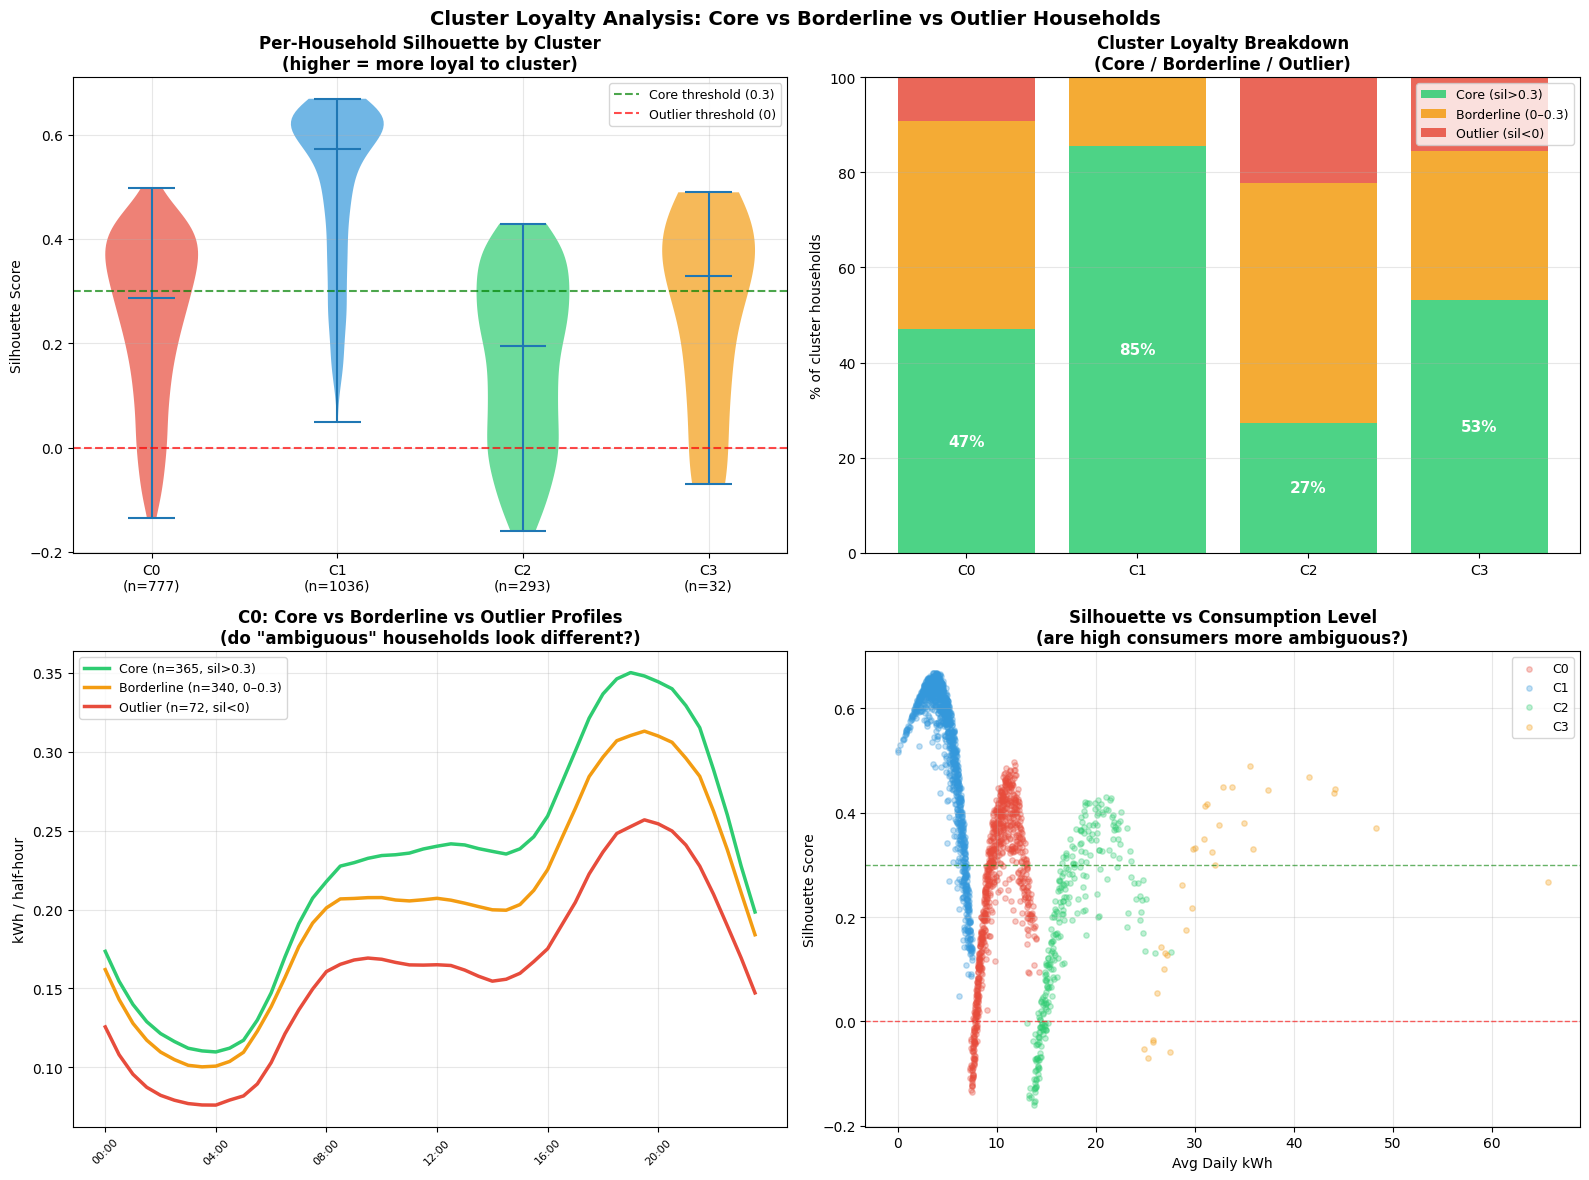

In [74]:

# ============================================================
# FLEXIBLE vs RIGID: Per-Household Silhouette & Cluster Loyalty
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_samples
from sklearn.preprocessing import StandardScaler

labels_best_raw = results_raw['K-Means']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
cluster_ids = sorted(set(labels_best_raw))

# Per-household silhouette score
# High sil = household firmly belongs to its cluster (rigid/core)
# Low/negative sil = household is borderline (flexible/ambiguous)
print("Computing per-household silhouette scores...")
sil_samples = silhouette_samples(X_raw, labels_best_raw)
print(f"Done! Mean silhouette: {sil_samples.mean():.4f}\n")

# Classify: Core (sil > 0.3), Borderline (0 < sil < 0.3), Outlier (sil < 0)
def classify_loyalty(sil):
    if sil > 0.3:   return 'Core'
    elif sil >= 0:  return 'Borderline'
    else:           return 'Outlier'

loyalty = np.array([classify_loyalty(s) for s in sil_samples])

print(f"{'Cluster':<10} {'N':>6} {'Mean Sil':>10} {'Core%':>8} {'Borderline%':>13} {'Outlier%':>10}")
print('=' * 60)
for c in cluster_ids:
    mask = labels_best_raw == c
    sil_c = sil_samples[mask]
    loy_c = loyalty[mask]
    core_pct = (loy_c == 'Core').mean() * 100
    border_pct = (loy_c == 'Borderline').mean() * 100
    outlier_pct = (loy_c == 'Outlier').mean() * 100
    print(f"C{c:<9} {mask.sum():>6} {sil_c.mean():>10.4f} "
          f"{core_pct:>7.1f}% {border_pct:>12.1f}% {outlier_pct:>9.1f}%")

x_labels_48 = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Silhouette distribution per cluster
ax = axes[0, 0]
data_sil = [sil_samples[labels_best_raw == c] for c in cluster_ids]
parts = ax.violinplot(data_sil, positions=cluster_ids, showmedians=True)
for pc, color in zip(parts['bodies'], colors):
    pc.set_facecolor(color); pc.set_alpha(0.7)
ax.axhline(0.3, color='green', linestyle='--', alpha=0.7, label='Core threshold (0.3)')
ax.axhline(0.0, color='red',   linestyle='--', alpha=0.7, label='Outlier threshold (0)')
ax.set_xticks(cluster_ids)
ax.set_xticklabels([f'C{c}\n(n={(labels_best_raw==c).sum()})' for c in cluster_ids])
ax.set_ylabel('Silhouette Score')
ax.set_title('Per-Household Silhouette by Cluster\n(higher = more loyal to cluster)',
             fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# Plot 2: Stacked bar — Core / Borderline / Outlier per cluster
ax = axes[0, 1]
cores, borders, outliers = [], [], []
for c in cluster_ids:
    mask = labels_best_raw == c
    loy_c = loyalty[mask]
    cores.append((loy_c == 'Core').mean() * 100)
    borders.append((loy_c == 'Borderline').mean() * 100)
    outliers.append((loy_c == 'Outlier').mean() * 100)

xlabels = [f'C{c}' for c in cluster_ids]
b1 = ax.bar(xlabels, cores,    label='Core (sil>0.3)',       color='#2ecc71', alpha=0.85)
b2 = ax.bar(xlabels, borders,  bottom=cores,
            label='Borderline (0–0.3)', color='#f39c12', alpha=0.85)
b3 = ax.bar(xlabels, outliers, bottom=[c+b for c,b in zip(cores,borders)],
            label='Outlier (sil<0)',   color='#e74c3c', alpha=0.85)
for bar, val in zip(b1, cores):
    if val > 5:
        ax.text(bar.get_x()+bar.get_width()/2, val/2,
                f'{val:.0f}%', ha='center', va='center', fontsize=11,
                fontweight='bold', color='white')
ax.set_ylabel('% of cluster households')
ax.set_title('Cluster Loyalty Breakdown\n(Core / Borderline / Outlier)',
             fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')

# Plot 3: Core vs Borderline mean profiles for C0 (example)
ax = axes[1, 0]
c_example = 0
mask_c = labels_best_raw == c_example
sil_c  = sil_samples[mask_c]
idx_c  = np.where(mask_c)[0]
core_idx     = idx_c[sil_c > 0.3]
border_idx   = idx_c[(sil_c >= 0) & (sil_c <= 0.3)]
outlier_idx  = idx_c[sil_c < 0]

if len(core_idx) > 0:
    core_mean = profiles_original_clean.iloc[core_idx].mean().values
    ax.plot(range(48), core_mean, color='#2ecc71', linewidth=2.5,
            label=f'Core (n={len(core_idx)}, sil>0.3)')
if len(border_idx) > 0:
    border_mean = profiles_original_clean.iloc[border_idx].mean().values
    ax.plot(range(48), border_mean, color='#f39c12', linewidth=2.5,
            label=f'Borderline (n={len(border_idx)}, 0–0.3)')
if len(outlier_idx) > 0:
    outlier_mean = profiles_original_clean.iloc[outlier_idx].mean().values
    ax.plot(range(48), outlier_mean, color='#e74c3c', linewidth=2.5,
            label=f'Outlier (n={len(outlier_idx)}, sil<0)')
ax.set_xticks(range(0, 48, 8))
ax.set_xticklabels([x_labels_48[j] for j in range(0, 48, 8)], rotation=45, fontsize=8)
ax.set_ylabel('kWh / half-hour')
ax.set_title(f'C{c_example}: Core vs Borderline vs Outlier Profiles\n'
             f'(do "ambiguous" households look different?)', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# Plot 4: Silhouette vs daily kWh scatter
ax = axes[1, 1]
daily_kwh = profiles_original_clean.sum(axis=1).values
for c in cluster_ids:
    mask = labels_best_raw == c
    ax.scatter(daily_kwh[mask], sil_samples[mask],
               color=colors[c], alpha=0.3, s=15, label=f'C{c}')
ax.axhline(0.3, color='green', linestyle='--', alpha=0.6, linewidth=1)
ax.axhline(0.0, color='red',   linestyle='--', alpha=0.6, linewidth=1)
ax.set_xlabel('Avg Daily kWh')
ax.set_ylabel('Silhouette Score')
ax.set_title('Silhouette vs Consumption Level\n(are high consumers more ambiguous?)',
             fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.suptitle('Cluster Loyalty Analysis: Core vs Borderline vs Outlier Households',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

=== ENERGY INEQUALITY ANALYSIS ===

Overall Gini coefficient: 0.3217
(0 = perfect equality, 1 = one household uses everything)

Top  1% of households (  21 hh) consume 4.0% of total energy
Top  5% of households ( 106 hh) consume 14.1% of total energy
Top 10% of households ( 213 hh) consume 23.7% of total energy
Top 20% of households ( 427 hh) consume 39.3% of total energy

Cluster         N   Avg kWh/day    Total kWh   Share%     Gini
C0            777         10.05       7805.3    41.3%   0.0981
C1           1036          4.81       4980.3    26.4%   0.1898
C2            293         17.23       5047.8    26.7%   0.0971
C3             32         32.93       1053.6     5.6%   0.1211


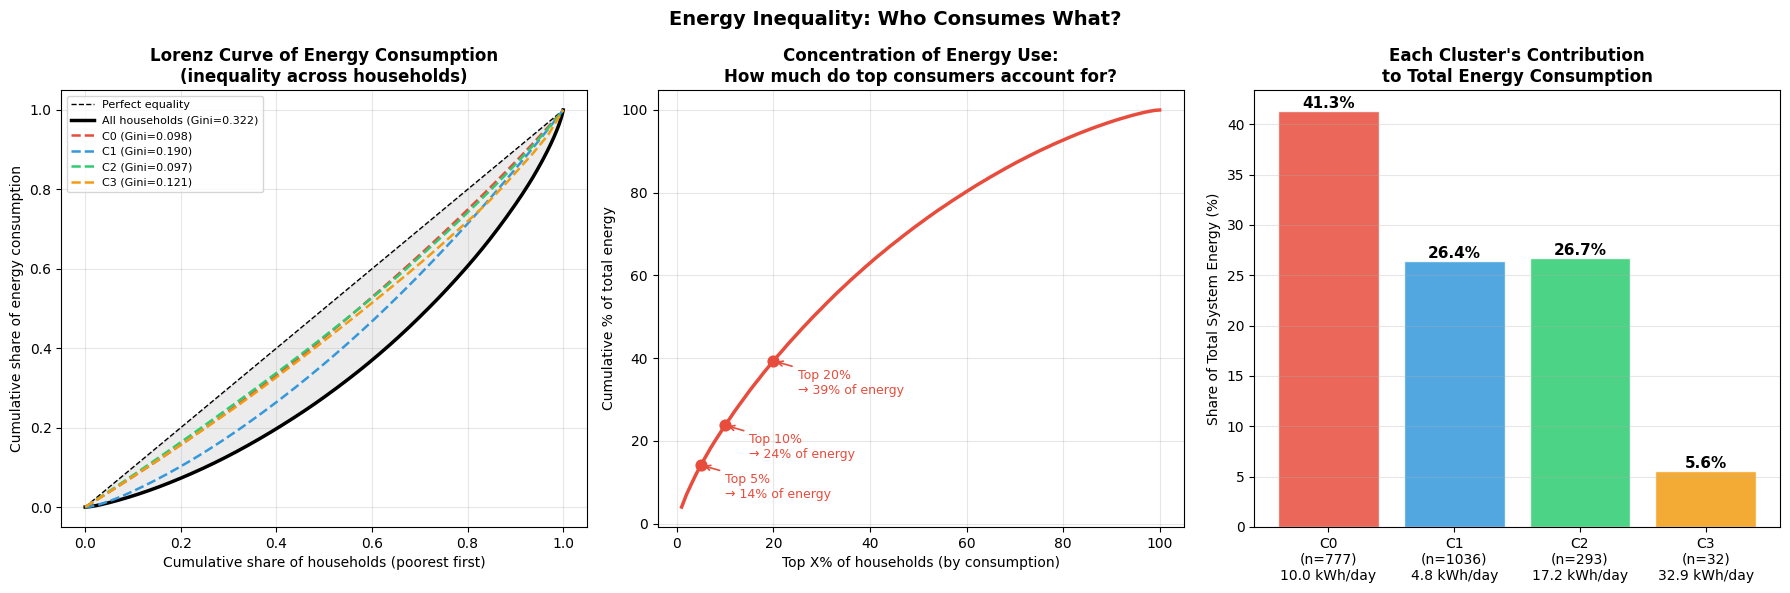

In [75]:

# ============================================================
# ENERGY INEQUALITY: Lorenz Curve + Gini Coefficient
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

labels_best_raw = results_raw['K-Means']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
cluster_ids = sorted(set(labels_best_raw))

daily_kwh = profiles_original_clean.sum(axis=1).values
n = len(daily_kwh)

def lorenz_curve(values):
    values_sorted = np.sort(values)
    cumsum = np.cumsum(values_sorted)
    lorenz = cumsum / cumsum[-1]
    lorenz = np.insert(lorenz, 0, 0)
    pop = np.linspace(0, 1, len(lorenz))
    return pop, lorenz

def gini(values):
    values_sorted = np.sort(values)
    n = len(values_sorted)
    index = np.arange(1, n + 1)
    return (2 * np.sum(index * values_sorted) / (n * np.sum(values_sorted))) - (n + 1) / n

# Overall Gini
g_all = gini(daily_kwh)
pop_all, lor_all = lorenz_curve(daily_kwh)

print("=== ENERGY INEQUALITY ANALYSIS ===\n")
print(f"Overall Gini coefficient: {g_all:.4f}")
print(f"(0 = perfect equality, 1 = one household uses everything)\n")

# Top consumers
daily_sorted = np.sort(daily_kwh)[::-1]
total = daily_kwh.sum()
for pct in [1, 5, 10, 20]:
    n_hh = max(1, int(n * pct / 100))
    share = daily_sorted[:n_hh].sum() / total * 100
    print(f"Top {pct:2d}% of households ({n_hh:4d} hh) consume {share:.1f}% of total energy")

print()
# Per-cluster contribution
print(f"{'Cluster':<10} {'N':>6} {'Avg kWh/day':>13} {'Total kWh':>12} {'Share%':>8} {'Gini':>8}")
print('=' * 55)
for c in cluster_ids:
    mask = labels_best_raw == c
    kwh_c = daily_kwh[mask]
    share = kwh_c.sum() / total * 100
    g_c = gini(kwh_c)
    print(f"C{c:<9} {mask.sum():>6} {kwh_c.mean():>13.2f} "
          f"{kwh_c.sum():>12.1f} {share:>7.1f}% {g_c:>8.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot 1: Lorenz curve — overall + per cluster
ax = axes[0]
ax.plot([0,1], [0,1], 'k--', linewidth=1, label='Perfect equality')
ax.fill_between(pop_all, pop_all, lor_all, alpha=0.15, color='gray')
ax.plot(pop_all, lor_all, color='black', linewidth=2.5,
        label=f'All households (Gini={g_all:.3f})')
for c in cluster_ids:
    mask = labels_best_raw == c
    kwh_c = daily_kwh[mask]
    pop_c, lor_c = lorenz_curve(kwh_c)
    g_c = gini(kwh_c)
    ax.plot(pop_c, lor_c, color=colors[c], linewidth=1.8, linestyle='--',
            label=f'C{c} (Gini={g_c:.3f})')
ax.set_xlabel('Cumulative share of households (poorest first)')
ax.set_ylabel('Cumulative share of energy consumption')
ax.set_title('Lorenz Curve of Energy Consumption\n(inequality across households)',
             fontweight='bold')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# Plot 2: What % of total energy do top X% consume?
ax = axes[1]
pct_range = np.arange(1, 101)
daily_sorted_desc = np.sort(daily_kwh)[::-1]
cumshare = np.array([daily_sorted_desc[:max(1, int(round(n * p / 100)))].sum() / total * 100
                      for p in pct_range])
ax.plot(pct_range, cumshare, color='#e74c3c', linewidth=2.5)
for mark_pct in [5, 10, 20]:
    idx = mark_pct - 1  # cumshare[i] corresponds to pct_range[i] = i+1
    ax.annotate(f'Top {mark_pct}%\n→ {cumshare[idx]:.0f}% of energy',
                xy=(mark_pct, cumshare[idx]),
                xytext=(mark_pct+5, cumshare[idx]-8),
                fontsize=9, color='#e74c3c',
                arrowprops=dict(arrowstyle='->', color='#e74c3c', lw=1.2))
    ax.scatter([mark_pct], [cumshare[idx]], color='#e74c3c', s=60, zorder=5)
ax.set_xlabel('Top X% of households (by consumption)')
ax.set_ylabel('Cumulative % of total energy')
ax.set_title('Concentration of Energy Use:\nHow much do top consumers account for?',
             fontweight='bold')
ax.grid(True, alpha=0.3)

# Plot 3: Per-cluster share of total system energy
ax = axes[2]
shares = []
labels_x = []
for c in cluster_ids:
    mask = labels_best_raw == c
    shares.append(daily_kwh[mask].sum() / total * 100)
    labels_x.append(f'C{c}\n(n={mask.sum()})\n{daily_kwh[mask].mean():.1f} kWh/day')
bars = ax.bar(labels_x, shares, color=colors, alpha=0.85, edgecolor='white')
for bar, share in zip(bars, shares):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{share:.1f}%', ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('Share of Total System Energy (%)')
ax.set_title('Each Cluster\'s Contribution\nto Total Energy Consumption',
             fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Energy Inequality: Who Consumes What?',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

=== INDIVIDUAL PEAK TIME DISTRIBUTION ===

Overall peak slot: 17:30 (mean)
Most common peak: 18:30 (197 households)

C0: most common peak = 18:30 | 58.4% peak in 18:00–21:00 window | spread (std) = 8.0 slots (4.0 hrs)
C1: most common peak = 20:00 | 52.2% peak in 18:00–21:00 window | spread (std) = 9.2 slots (4.6 hrs)
C2: most common peak = 19:30 | 64.2% peak in 18:00–21:00 window | spread (std) = 8.7 slots (4.3 hrs)
C3: most common peak = 20:30 | 75.0% peak in 18:00–21:00 window | spread (std) = 9.9 slots (5.0 hrs)


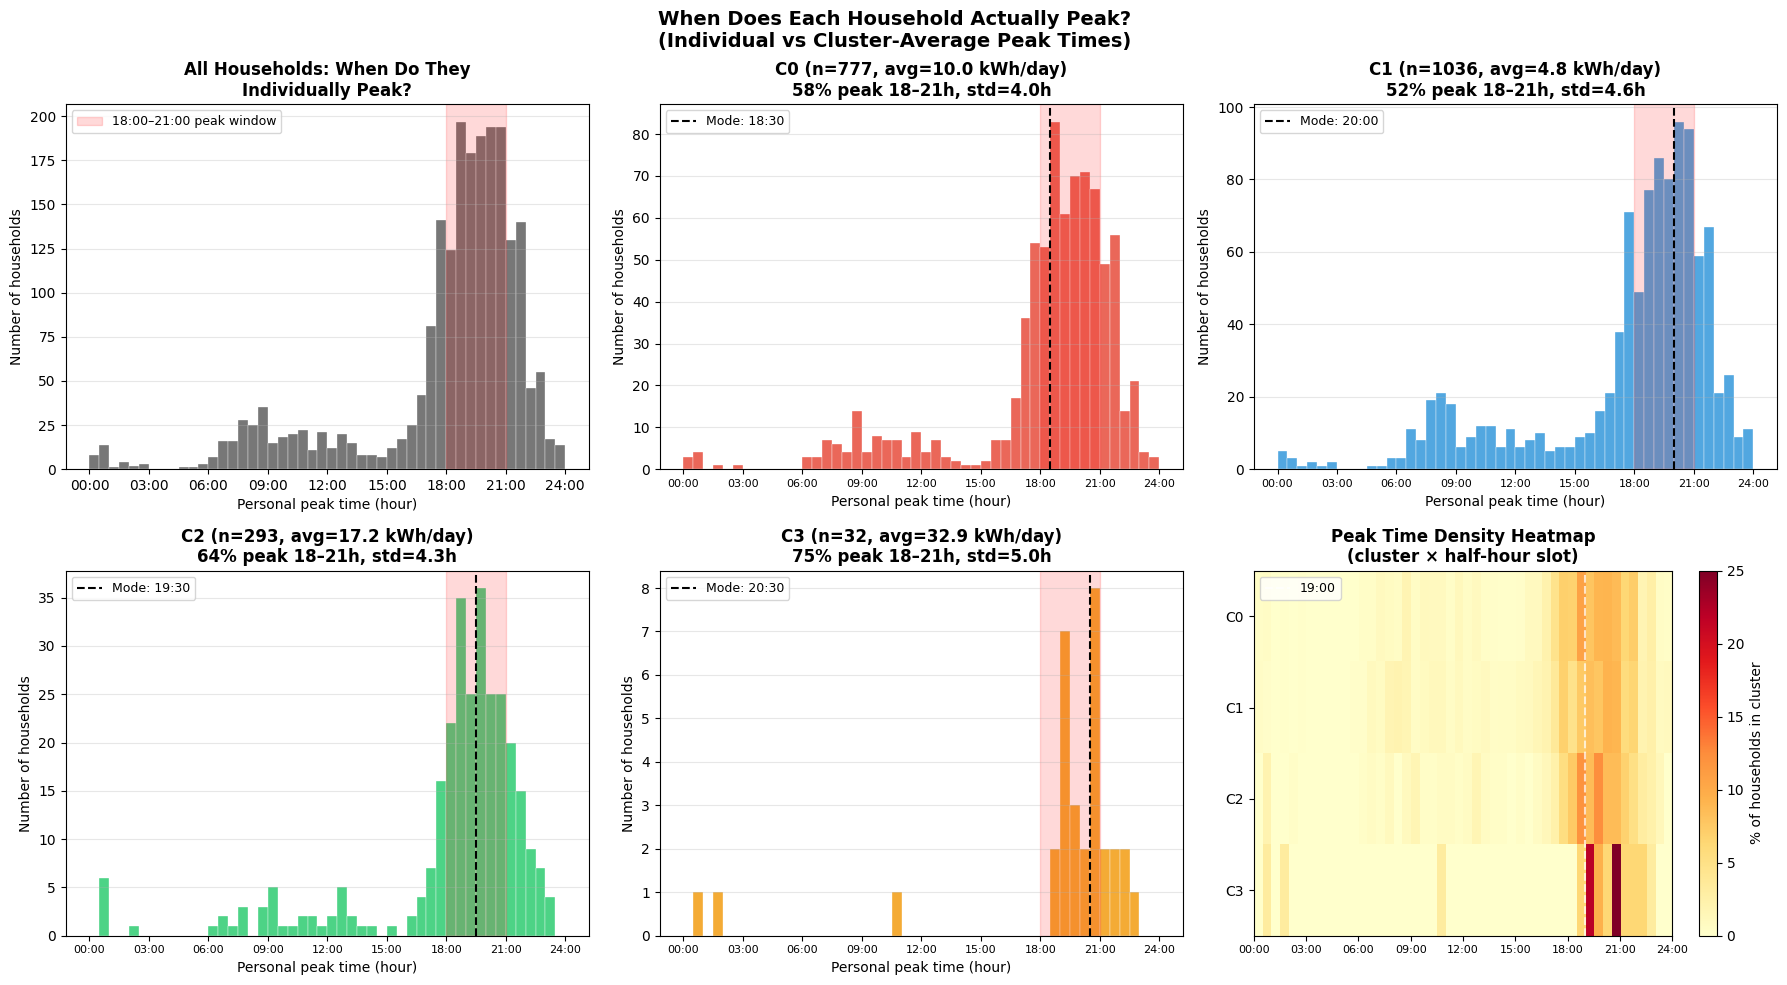

In [76]:


# ============================================================
# INDIVIDUAL PEAK TIME DISTRIBUTION
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

labels_best_raw = results_raw['K-Means']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
cluster_ids = sorted(set(labels_best_raw))

# Each household's personal peak slot (argmax across 48 half-hours)
peak_slots = profiles_original_clean.values.argmax(axis=1)  # 0–47
peak_hours = peak_slots / 2  # convert to hours (0.0 – 23.5)

time_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]

print("=== INDIVIDUAL PEAK TIME DISTRIBUTION ===\n")
print(f"Overall peak slot: {time_labels[int(peak_slots.mean())]} (mean)")
print(f"Most common peak: {time_labels[np.bincount(peak_slots).argmax()]} "
      f"({np.bincount(peak_slots).max()} households)\n")

for c in cluster_ids:
    mask = labels_best_raw == c
    ps = peak_slots[mask]
    mode_slot = np.bincount(ps).argmax()
    pct_evening = np.mean((ps >= 36) & (ps <= 42)) * 100  # 18:00–21:00
    print(f"C{c}: most common peak = {time_labels[mode_slot]} | "
          f"{pct_evening:.1f}% peak in 18:00–21:00 window | "
          f"spread (std) = {ps.std():.1f} slots ({ps.std()/2:.1f} hrs)")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Plot 1: Overall histogram
ax = axes[0, 0]
ax.hist(peak_hours, bins=48, range=(0, 24), color='#555555', alpha=0.8,
        edgecolor='white', linewidth=0.3)
ax.axvspan(18, 21, alpha=0.15, color='red', label='18:00–21:00 peak window')
ax.set_xlabel('Personal peak time (hour)')
ax.set_ylabel('Number of households')
ax.set_title('All Households: When Do They\nIndividually Peak?', fontweight='bold')
ax.set_xticks(range(0, 25, 3))
ax.set_xticklabels([f'{h:02d}:00' for h in range(0, 25, 3)])
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')

# Plots 2–5: Per-cluster histogram
for idx, c in enumerate(cluster_ids):
    row = (idx + 1) // 3
    col = (idx + 1) % 3
    ax = axes[row, col]
    mask = labels_best_raw == c
    ph_c = peak_hours[mask]
    ps_c = peak_slots[mask]
    ax.hist(ph_c, bins=48, range=(0, 24), color=colors[c], alpha=0.85,
            edgecolor='white', linewidth=0.3)
    ax.axvspan(18, 21, alpha=0.15, color='red')
    mode_slot = np.bincount(ps_c).argmax()
    ax.axvline(mode_slot / 2, color='black', linestyle='--', linewidth=1.5,
               label=f'Mode: {time_labels[mode_slot]}')
    pct_ev = np.mean((ps_c >= 36) & (ps_c <= 42)) * 100
    ax.set_title(f'C{c} (n={mask.sum()}, avg={profiles_original_clean.values[mask].sum(axis=1).mean():.1f} kWh/day)\n'
                 f'{pct_ev:.0f}% peak 18–21h, std={ph_c.std():.1f}h', fontweight='bold')
    ax.set_xlabel('Personal peak time (hour)')
    ax.set_ylabel('Number of households')
    ax.set_xticks(range(0, 25, 3))
    ax.set_xticklabels([f'{h:02d}:00' for h in range(0, 25, 3)], fontsize=8)
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')

# Plot 6: Heatmap — cluster × time slot (2D density)
ax = axes[1, 2]
heatmap = np.zeros((len(cluster_ids), 48))
for c in cluster_ids:
    mask = labels_best_raw == c
    ps_c = peak_slots[mask]
    counts = np.bincount(ps_c, minlength=48)
    heatmap[c] = counts / counts.sum() * 100  # normalise to %

im = ax.imshow(heatmap, aspect='auto', cmap='YlOrRd',
               extent=[0, 48, len(cluster_ids)-0.5, -0.5])
plt.colorbar(im, ax=ax, label='% of households in cluster')
ax.set_yticks(range(len(cluster_ids)))
ax.set_yticklabels([f'C{c}' for c in cluster_ids])
ax.set_xticks(range(0, 49, 6))
ax.set_xticklabels([f'{h:02d}:00' for h in range(0, 25, 3)], fontsize=8)
ax.axvline(38, color='white', linestyle='--', linewidth=1.5, alpha=0.7,
           label='19:00')
ax.set_title('Peak Time Density Heatmap\n(cluster × half-hour slot)', fontweight='bold')
ax.legend(fontsize=9)

plt.suptitle('When Does Each Household Actually Peak?\n(Individual vs Cluster-Average Peak Times)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

=== DEMAND SHIFTING SIMULATION ===

Baseline system peak: 600.09 kWh at 19:30
Baseline total daily consumption: 18887.02 kWh

Scenario             Shift%   New Peak  Peak Time  Reduction%
C0 only 10%             10%     597.07      19:00        0.5%
C0 only 20%             20%     595.73      19:00        0.7%
C0 only 30%             30%     618.33      17:30       -3.0%
C0 only 40%             40%     643.52      17:30       -7.2%

C2 only 10%             10%     597.68      19:00        0.4%
C2 only 20%             20%     596.95      19:00        0.5%
C2 only 30%             30%     596.23      19:00        0.6%
C2 only 40%             40%     605.56      17:30       -0.9%

C0 + C2 10%             10%     596.34      19:00        0.6%
C0 + C2 20%             20%     624.54      17:30       -4.1%
C0 + C2 30%             30%     665.44      17:30      -10.9%
C0 + C2 40%             40%     706.34      17:30      -17.7%

All clusters 10%        10%     602.75      17:30       -0.4%
All

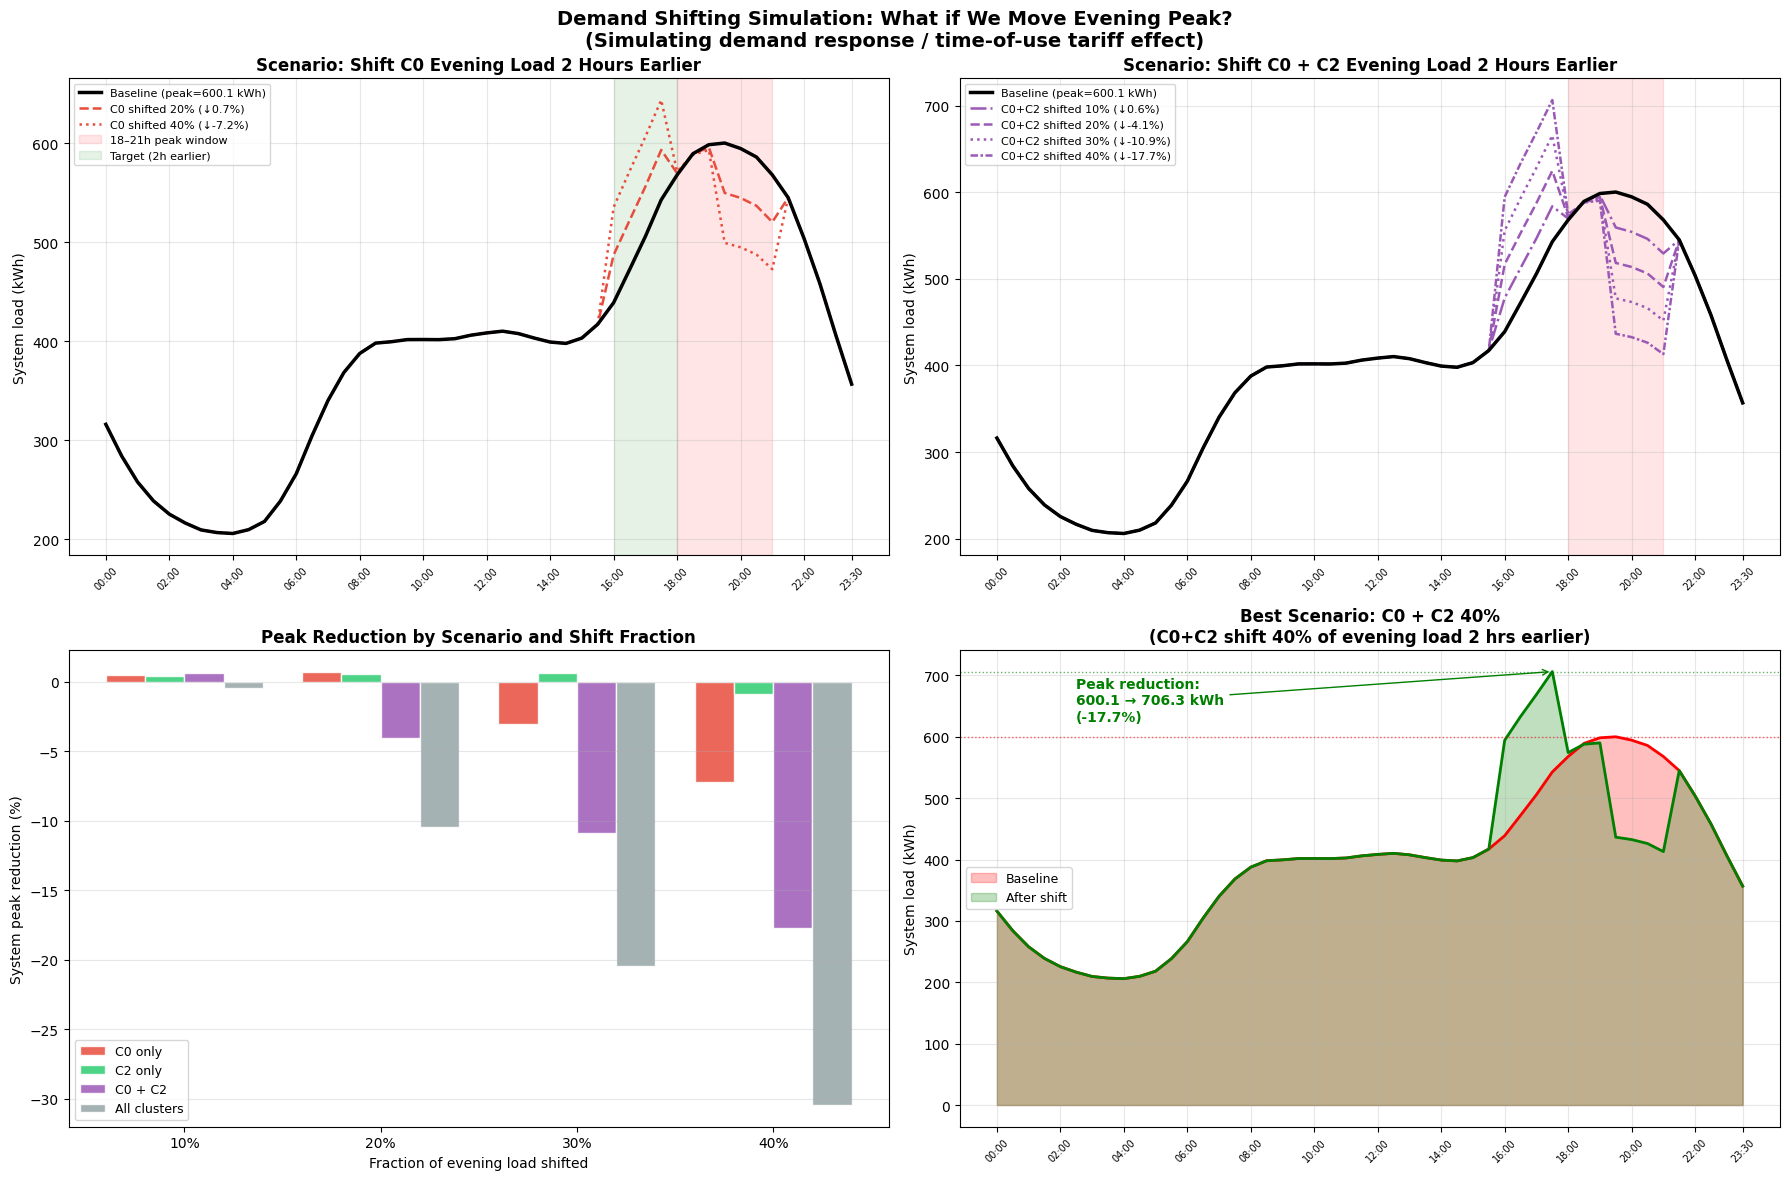

In [77]:


# ============================================================
# DEMAND SHIFTING SIMULATION
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

labels_best_raw = results_raw['K-Means']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
cluster_ids = sorted(set(labels_best_raw))

cluster_means = {}
cluster_sizes = {}
for c in cluster_ids:
    mask = labels_best_raw == c
    cluster_means[c] = profiles_original_clean.values[mask].mean(axis=0)
    cluster_sizes[c] = mask.sum()

# System load = weighted sum of cluster means
system_load = sum(cluster_means[c] * cluster_sizes[c] for c in cluster_ids)
peak_slot = system_load.argmax()
time_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
print("=== DEMAND SHIFTING SIMULATION ===\n")
print(f"Baseline system peak: {system_load.max():.2f} kWh at {time_labels[peak_slot]}")
print(f"Baseline total daily consumption: {system_load.sum():.2f} kWh\n")

# Evening peak window: slots 36–42 = 18:00–21:00
PEAK_START, PEAK_END = 36, 42
SHIFT_SLOTS = 4   # shift 2 hours earlier (4 × 30min)

results_sim = {}
shift_fractions = [0.10, 0.20, 0.30, 0.40]
target_clusters = {
    'C0 only': [0],
    'C2 only': [2],
    'C0 + C2': [0, 2],
    'All clusters': [0, 1, 2, 3],
}

print(f"{'Scenario':<20} {'Shift%':>6} {'New Peak':>10} {'Peak Time':>10} {'Reduction%':>11}")
print('=' * 62)

for scenario_name, target_cs in target_clusters.items():
    for frac in shift_fractions:
        shifted_load = system_load.copy().astype(float)
        for c in target_cs:
            n = cluster_sizes[c]
            mean_c = cluster_means[c].copy()
            # Amount to shift = frac of each peak-window slot's load
            shift_amount = np.zeros(48)
            for s in range(PEAK_START, PEAK_END + 1):
                amount = mean_c[s] * frac
                shift_amount[s] -= amount
                target_slot = max(0, s - SHIFT_SLOTS)
                shift_amount[target_slot] += amount
            shifted_load += shift_amount * n

        new_peak = shifted_load.max()
        new_peak_slot = shifted_load.argmax()
        reduction = (system_load.max() - new_peak) / system_load.max() * 100
        label = f'{scenario_name} {int(frac*100)}%'
        print(f'{label:<20} {int(frac*100):>5}% {new_peak:>10.2f} '
              f'{time_labels[new_peak_slot]:>10} {reduction:>10.1f}%')
        results_sim[label] = shifted_load.copy()
    print()

# ---- Plots ----
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Plot 1: Baseline vs shifting C0 (20% and 40%)
ax = axes[0, 0]
ax.plot(range(48), system_load, color='black', linewidth=2.5,
        label=f'Baseline (peak={system_load.max():.1f} kWh)', zorder=5)
for frac, ls in [(0.20, '--'), (0.40, ':')]:
    sl = results_sim[f'C0 only {int(frac*100)}%']
    red = (system_load.max() - sl.max()) / system_load.max() * 100
    ax.plot(range(48), sl, color=colors[0], linewidth=1.8, linestyle=ls,
            label=f'C0 shifted {int(frac*100)}% (↓{red:.1f}%)')
ax.axvspan(PEAK_START, PEAK_END, alpha=0.1, color='red', label='18–21h peak window')
ax.axvspan(PEAK_START - SHIFT_SLOTS, PEAK_START, alpha=0.1, color='green', label='Target (2h earlier)')
ax.set_title('Scenario: Shift C0 Evening Load 2 Hours Earlier', fontweight='bold')
ax.set_ylabel('System load (kWh)'); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 49, 4))
tick_positions = list(range(0, 48, 4)) + [47]
ax.set_xticks(tick_positions)
ax.set_xticklabels([time_labels[i] for i in tick_positions], rotation=45, fontsize=7)

# Plot 2: C0 + C2 combined shift
ax = axes[0, 1]
ax.plot(range(48), system_load, color='black', linewidth=2.5,
        label=f'Baseline (peak={system_load.max():.1f} kWh)', zorder=5)
for frac, ls in [(0.10, '-.'), (0.20, '--'), (0.30, ':'), (0.40, (0,(3,1,1,1)))]:
    sl = results_sim[f'C0 + C2 {int(frac*100)}%']
    red = (system_load.max() - sl.max()) / system_load.max() * 100
    ax.plot(range(48), sl, color='#9b59b6', linewidth=1.8, linestyle=ls,
            label=f'C0+C2 shifted {int(frac*100)}% (↓{red:.1f}%)')
ax.axvspan(PEAK_START, PEAK_END, alpha=0.1, color='red')
ax.set_title('Scenario: Shift C0 + C2 Evening Load 2 Hours Earlier', fontweight='bold')
ax.set_ylabel('System load (kWh)'); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 49, 4))
tick_positions = list(range(0, 48, 4)) + [47]
ax.set_xticks(tick_positions)
ax.set_xticklabels([time_labels[i] for i in tick_positions], rotation=45, fontsize=7)

# Plot 3: Peak reduction summary bar chart
ax = axes[1, 0]
scenario_keys = list(target_clusters.keys())
x = np.arange(len(shift_fractions))
width = 0.2
bar_colors = [colors[0], colors[2], '#9b59b6', '#95a5a6']
for i, (sname, sc) in enumerate(target_clusters.items()):
    reductions = []
    for frac in shift_fractions:
        sl = results_sim[f'{sname} {int(frac*100)}%']
        reductions.append((system_load.max() - sl.max()) / system_load.max() * 100)
    bars = ax.bar(x + i * width, reductions, width, label=sname,
                  color=bar_colors[i], alpha=0.85, edgecolor='white')
ax.set_xlabel('Fraction of evening load shifted')
ax.set_ylabel('System peak reduction (%)')
ax.set_title('Peak Reduction by Scenario and Shift Fraction', fontweight='bold')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels([f'{int(f*100)}%' for f in shift_fractions])
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')

# Plot 4: Best scenario — full load curve before/after
ax = axes[1, 1]
best_key = f'C0 + C2 40%'
best_load = results_sim[best_key]
red_best = (system_load.max() - best_load.max()) / system_load.max() * 100
ax.fill_between(range(48), system_load, alpha=0.25, color='red', label='Baseline')
ax.fill_between(range(48), best_load, alpha=0.25, color='green', label='After shift')
ax.plot(range(48), system_load, color='red', linewidth=2)
ax.plot(range(48), best_load, color='green', linewidth=2)
ax.axhline(system_load.max(), color='red', linestyle=':', linewidth=1, alpha=0.6)
ax.axhline(best_load.max(), color='green', linestyle=':', linewidth=1, alpha=0.6)
ax.annotate(f'Peak reduction:\n{system_load.max():.1f} → {best_load.max():.1f} kWh\n({red_best:.1f}%)',
            xy=(best_load.argmax(), best_load.max()),
            xytext=(5, best_load.max() - 80),
            fontsize=10, color='green', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='green'))
ax.set_title(f'Best Scenario: {best_key}\n(C0+C2 shift 40% of evening load 2 hrs earlier)',
             fontweight='bold')
ax.set_ylabel('System load (kWh)'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 49, 4))
tick_positions = list(range(0, 48, 4)) + [47]
ax.set_xticks(tick_positions)
ax.set_xticklabels([time_labels[i] for i in tick_positions], rotation=45, fontsize=7)

plt.suptitle('Demand Shifting Simulation: What if We Move Evening Peak?\n'
             '(Simulating demand response / time-of-use tariff effect)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

> **SUPERSEDED — retained for methodological discussion.**
> Result: Sarle's bimodality coefficient across slots/clusters, flagged bimodal where BC > 0.555.
> Problem: BC > 0.555 is a descriptive threshold, not a hypothesis test, and does not control type-I error over 15 comparisons.
> Corrected in: Statistical rigour block 2 (Hartigan dip test with Holm correction).

=== BIMODALITY ANALYSIS AT PEAK TIME ===

Sarle's Bimodality Coefficient (BC > 0.555 = bimodal)

Slot                           All       C0       C1       C2       C3
19:30 (evening peak)         0.475     0.388     0.381     0.373     0.453
07:30 (morning)              0.448     0.345     0.348     0.369     0.588
12:00 (midday)               0.506     0.418     0.332     0.417     0.350

KDE Mode Detection at 19:30 (evening peak slot):
Group         N Modes           Mode values (kWh/hh)
All                 1   0.156
C0                  1   0.312
C1                  1   0.144
C2                  1   0.493
C3                  3   0.737, 0.838, 1.073


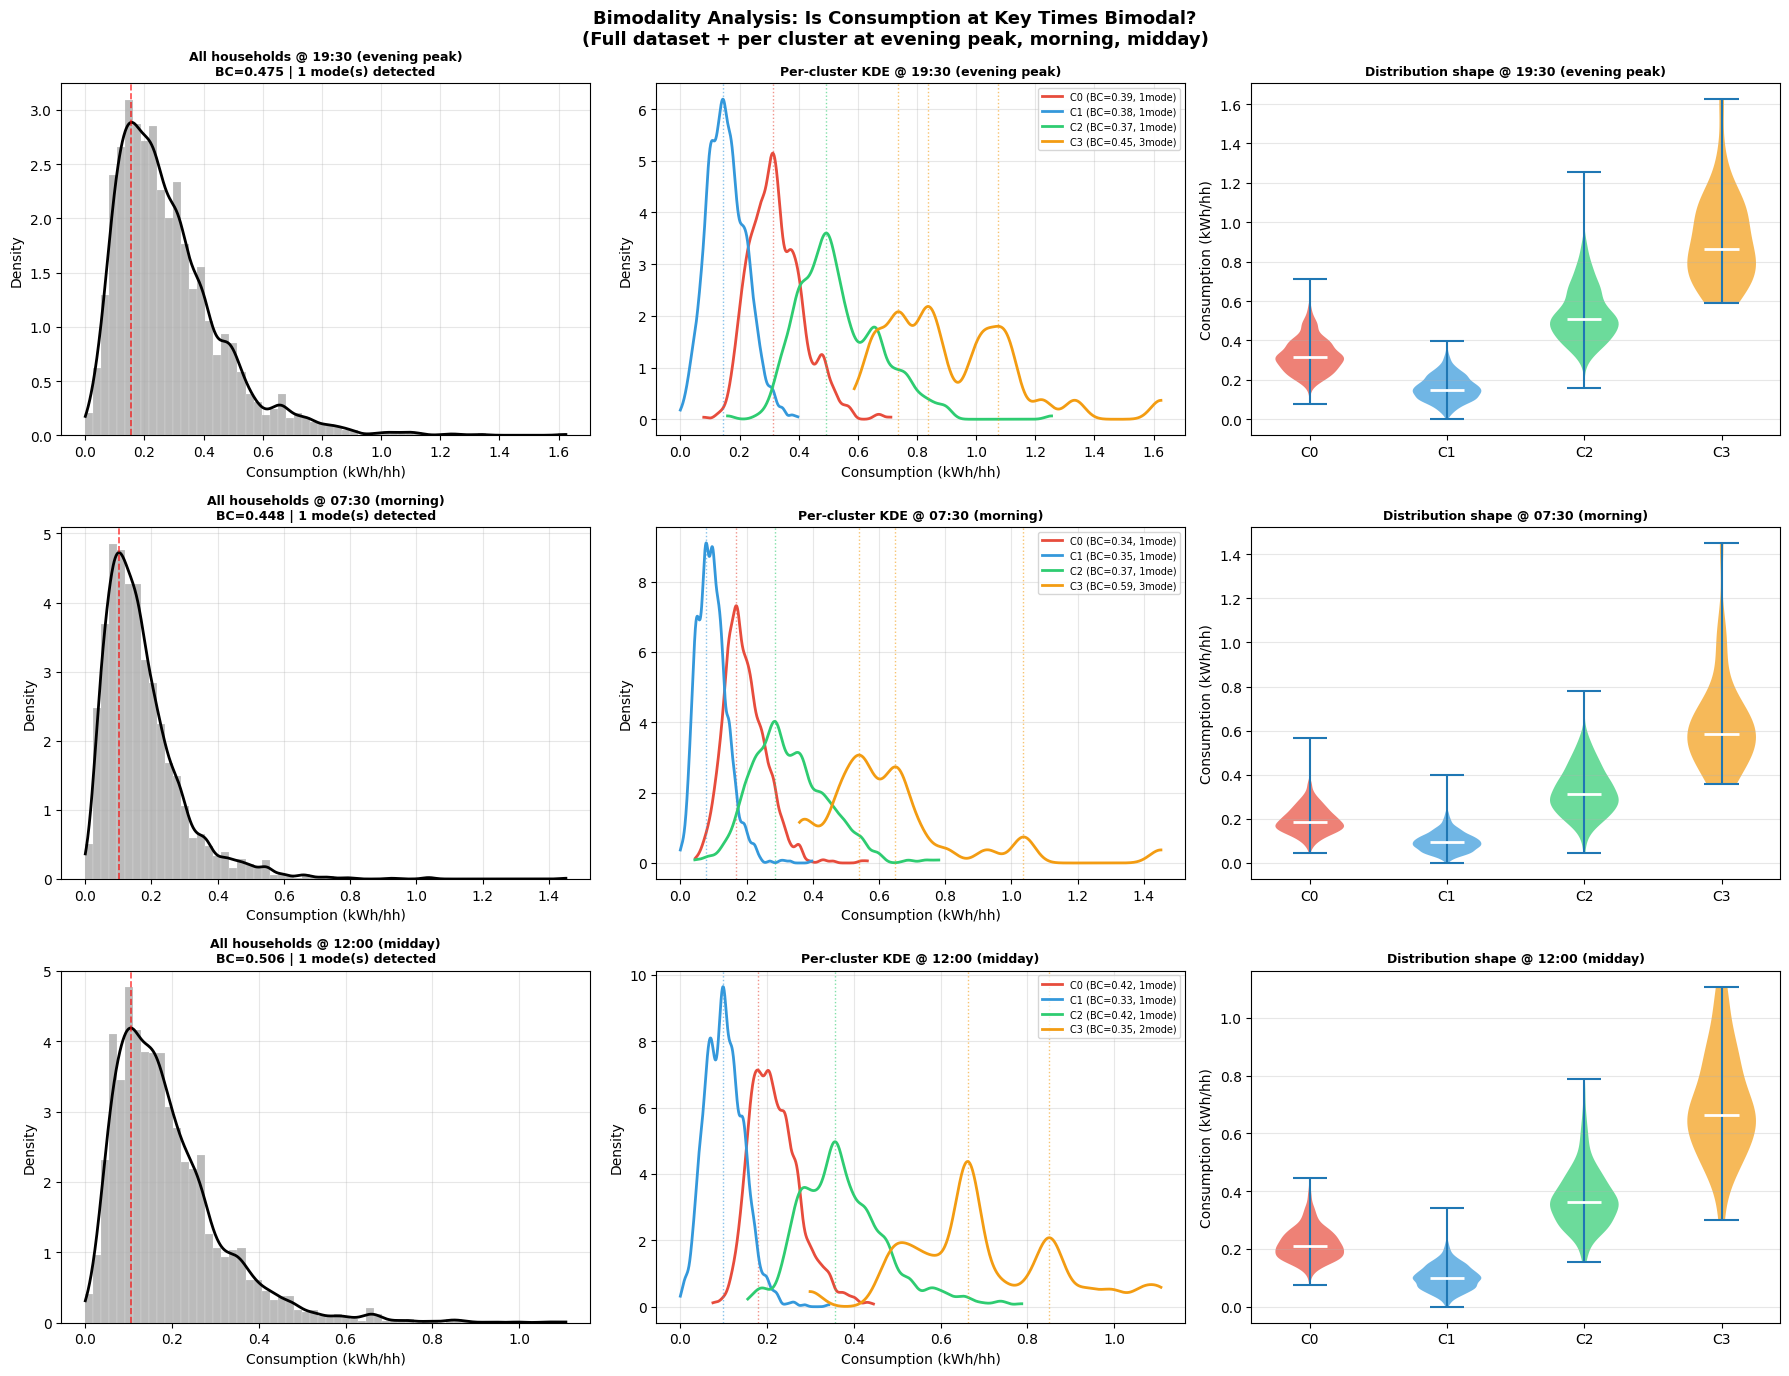

In [78]:


# ============================================================
# BIMODALITY ANALYSIS AT PEAK TIME
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import find_peaks

labels_best_raw = results_raw['K-Means']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
cluster_ids = sorted(set(labels_best_raw))

# Extract consumption at key slots
PEAK_SLOT = 39   # 19:30
MORNING_SLOT = 15  # 07:30
SHOULDER_SLOT = 24  # 12:00

slot_names = {PEAK_SLOT: '19:30 (evening peak)',
              MORNING_SLOT: '07:30 (morning)',
              SHOULDER_SLOT: '12:00 (midday)'}

all_vals = profiles_original_clean.values

def bimodality_coefficient(x):
    """Sarle's bimodality coefficient: >0.555 suggests bimodality"""
    n = len(x)
    skew = stats.skew(x)
    kurt = stats.kurtosis(x)
    return (skew**2 + 1) / (kurt + 3 * (n-1)**2 / ((n-2)*(n-3)))

print("=== BIMODALITY ANALYSIS AT PEAK TIME ===\n")
print("Sarle's Bimodality Coefficient (BC > 0.555 = bimodal)\n")
print(f"{'Slot':<25} {'All':>8} {'C0':>8} {'C1':>8} {'C2':>8} {'C3':>8}")
print('=' * 65)

bc_results = {}
for slot, name in slot_names.items():
    bcs = [bimodality_coefficient(all_vals[:, slot])]
    for c in cluster_ids:
        mask = labels_best_raw == c
        bcs.append(bimodality_coefficient(all_vals[mask, slot]))
    bc_results[slot] = bcs
    vals_str = '  '.join(f'{b:8.3f}' for b in bcs)
    print(f'{name:<25} {vals_str}')

# Dip test approximation via KDE
def kde_n_modes(x, bw_method=0.15):
    kde = stats.gaussian_kde(x, bw_method=bw_method)
    xs = np.linspace(x.min(), x.max(), 1000)
    density = kde(xs)
    peaks, _ = find_peaks(density, prominence=density.max()*0.1)
    return len(peaks), xs, density, peaks

print(f"\nKDE Mode Detection at 19:30 (evening peak slot):")
print(f"{'Group':<12} {'N Modes':>8} {'Mode values (kWh/hh)':>30}")
print('=' * 55)
x_all = all_vals[:, PEAK_SLOT]
n_modes, xs, dens, pks = kde_n_modes(x_all)
mode_vals = ', '.join(f'{xs[p]:.3f}' for p in pks)
print(f"{'All':<12} {n_modes:>8}   {mode_vals}")
for c in cluster_ids:
    mask = labels_best_raw == c
    x_c = all_vals[mask, PEAK_SLOT]
    n_modes_c, xs_c, dens_c, pks_c = kde_n_modes(x_c)
    mode_vals_c = ', '.join(f'{xs_c[p]:.3f}' for p in pks_c)
    print(f"{'C'+str(c):<12} {n_modes_c:>8}   {mode_vals_c}")

# ---- Plots ----
fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for row, (slot, name) in enumerate(slot_names.items()):
    # Col 0: Full distribution histogram + KDE
    ax = axes[row, 0]
    x_all = all_vals[:, slot]
    ax.hist(x_all, bins=60, density=True, alpha=0.4, color='#555',
            edgecolor='white', linewidth=0.3)
    n_m, xs, dens, pks = kde_n_modes(x_all)
    ax.plot(xs, dens, color='black', linewidth=2)
    for p in pks:
        ax.axvline(xs[p], color='red', linestyle='--', linewidth=1.2, alpha=0.7)
    bc = bimodality_coefficient(x_all)
    ax.set_title(f'All households @ {name}\nBC={bc:.3f} | {n_m} mode(s) detected',
                 fontweight='bold', fontsize=9)
    ax.set_xlabel('Consumption (kWh/hh)'); ax.set_ylabel('Density')
    ax.grid(True, alpha=0.3)

    # Col 1: Per-cluster KDE overlay
    ax = axes[row, 1]
    for c in cluster_ids:
        mask = labels_best_raw == c
        x_c = all_vals[mask, slot]
        n_m_c, xs_c, dens_c, pks_c = kde_n_modes(x_c)
        ax.plot(xs_c, dens_c, color=colors[c], linewidth=2,
                label=f'C{c} (BC={bimodality_coefficient(x_c):.2f}, {n_m_c}mode)')
        for p in pks_c:
            ax.axvline(xs_c[p], color=colors[c], linestyle=':', linewidth=1, alpha=0.6)
    ax.set_title(f'Per-cluster KDE @ {name}', fontweight='bold', fontsize=9)
    ax.set_xlabel('Consumption (kWh/hh)'); ax.set_ylabel('Density')
    ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

    # Col 2: Violin plot
    ax = axes[row, 2]
    data_by_cluster = [all_vals[labels_best_raw == c, slot] for c in cluster_ids]
    parts = ax.violinplot(data_by_cluster, positions=cluster_ids,
                          showmedians=True, showextrema=True)
    for pc, c in zip(parts['bodies'], cluster_ids):
        pc.set_facecolor(colors[c]); pc.set_alpha(0.7)
    parts['cmedians'].set_color('white'); parts['cmedians'].set_linewidth(2)
    ax.set_xticks(cluster_ids)
    ax.set_xticklabels([f'C{c}' for c in cluster_ids])
    ax.set_title(f'Distribution shape @ {name}', fontweight='bold', fontsize=9)
    ax.set_ylabel('Consumption (kWh/hh)'); ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Bimodality Analysis: Is Consumption at Key Times Bimodal?\n'
             '(Full dataset + per cluster at evening peak, morning, midday)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

=== MORNING vs EVENING CORRELATION ===

Pearson r (morning vs evening) by cluster:

Group           r      p-value Interpretation
All        0.8430     0.00e+00  Strong
C0         0.2300     8.72e-11  Weak
C1         0.5546     1.34e-84  Moderate
C2         0.3006     1.57e-07  Weak
C3         0.7711     2.41e-07  Strong

All pairwise window correlations (full dataset):

                Morning 06–10h  Midday 11–14h Evening 17–22h   Night 00–04h
 Morning 06–10h          1.000          0.867          0.843          0.754
  Midday 11–14h          0.867          1.000          0.887          0.738
 Evening 17–22h          0.843          0.887          1.000          0.727
   Night 00–04h          0.754          0.738          0.727          1.000


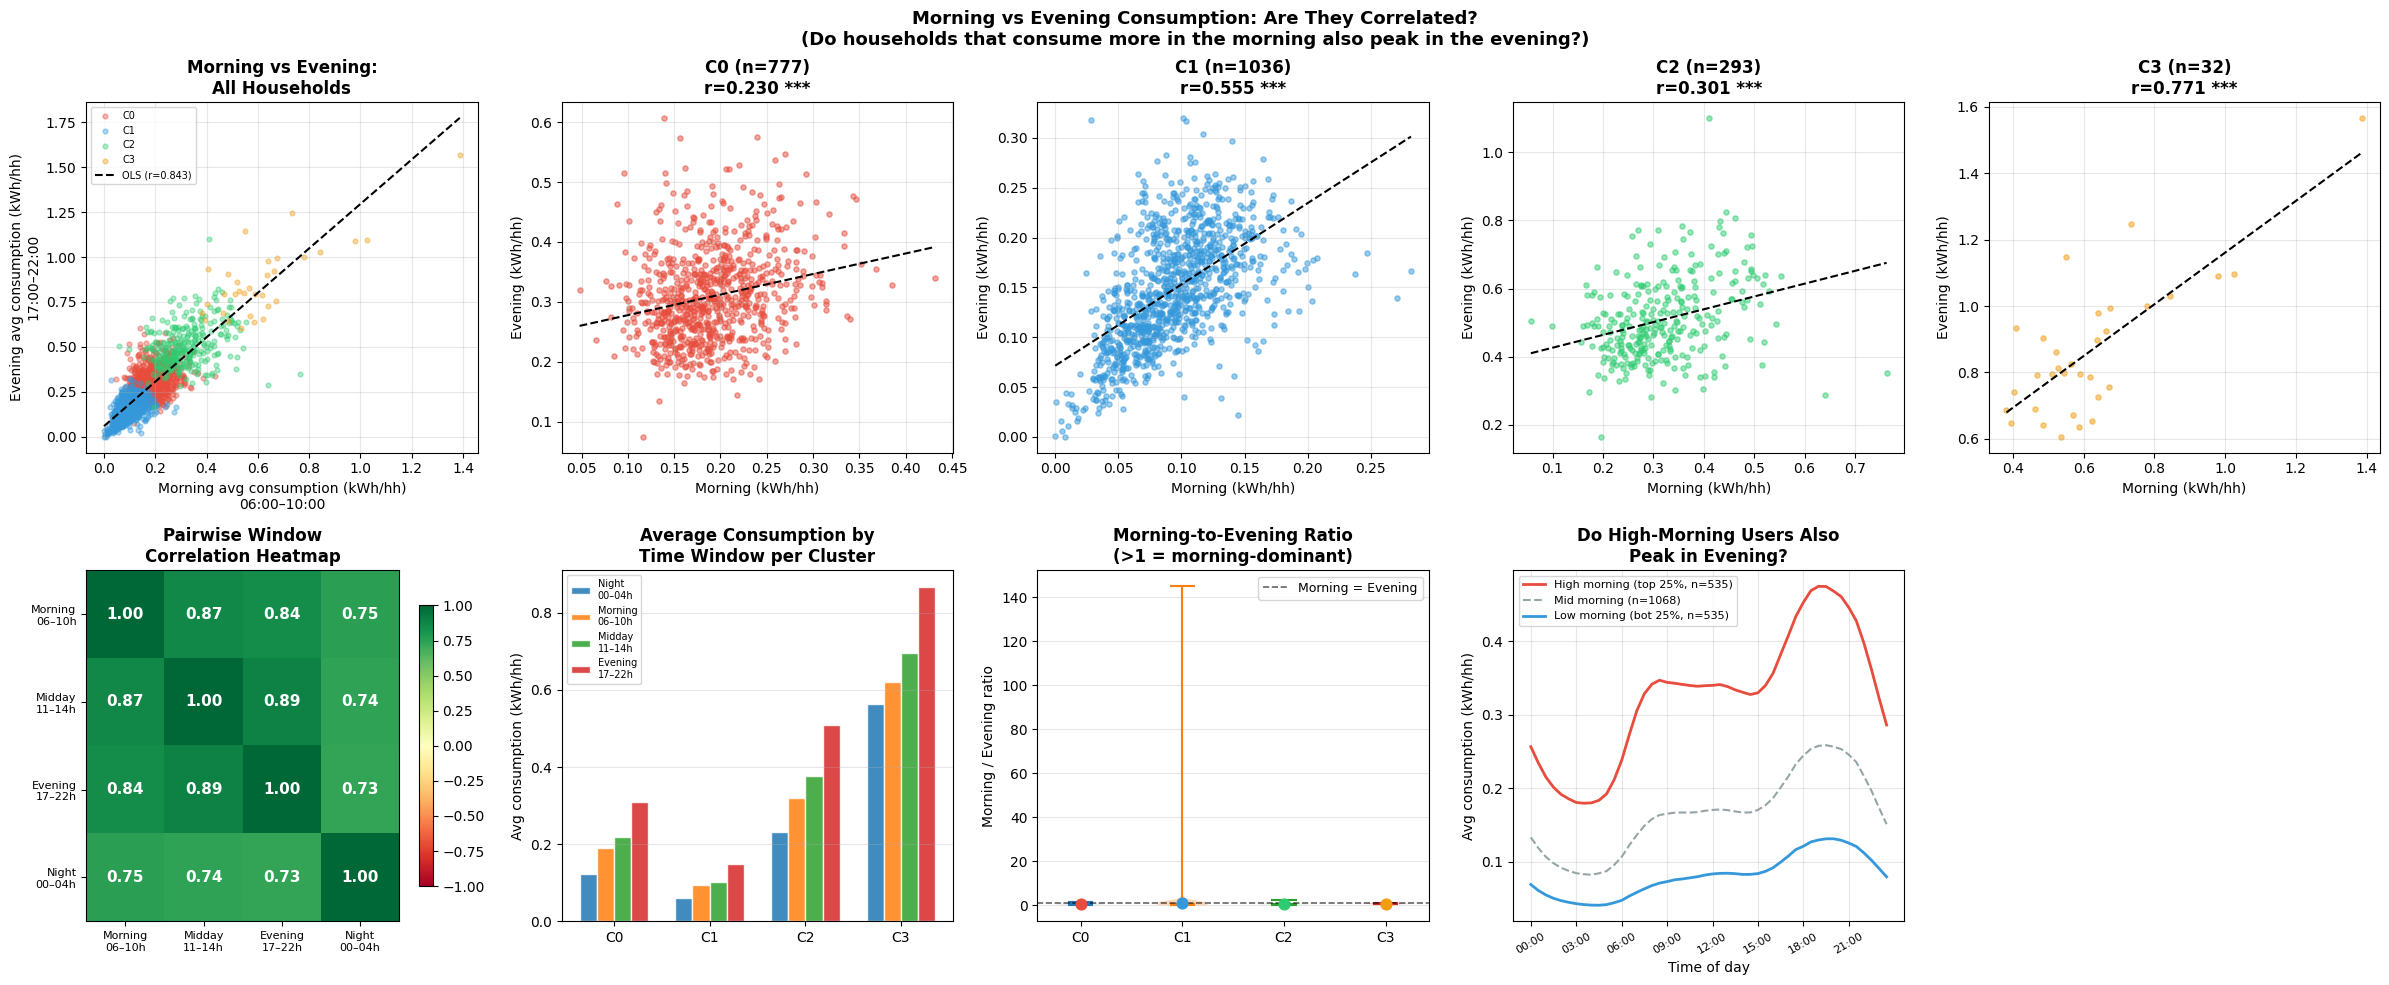

In [79]:


# ============================================================
# MORNING vs EVENING CORRELATION ANALYSIS
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

labels_best_raw = results_raw['K-Means']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
cluster_ids = sorted(set(labels_best_raw))

vals = profiles_original_clean.values

# Define time windows (slot indices)
MORNING   = slice(12, 20)   # 06:00–10:00
MIDDAY    = slice(22, 28)   # 11:00–14:00
EVENING   = slice(34, 44)   # 17:00–22:00
NIGHT     = slice(0,  8)    # 00:00–04:00
LATENIGHT = slice(44, 48)   # 22:00–24:00

morning_avg = vals[:, MORNING].mean(axis=1)
midday_avg  = vals[:, MIDDAY].mean(axis=1)
evening_avg = vals[:, EVENING].mean(axis=1)
night_avg   = vals[:, NIGHT].mean(axis=1)

print("=== MORNING vs EVENING CORRELATION ===\n")
print("Pearson r (morning vs evening) by cluster:\n")
print(f"{'Group':<8} {'r':>8} {'p-value':>12} {'Interpretation'}")
print('=' * 55)

def interpret_r(r, p):
    if p > 0.05:
        return 'Not significant'
    if abs(r) < 0.2:
        return 'Negligible'
    elif abs(r) < 0.4:
        return 'Weak'
    elif abs(r) < 0.6:
        return 'Moderate'
    else:
        return 'Strong'

# Overall
r, p = stats.pearsonr(morning_avg, evening_avg)
print(f"{'All':<8} {r:>8.4f} {p:>12.2e}  {interpret_r(r,p)}")
for c in cluster_ids:
    mask = labels_best_raw == c
    r_c, p_c = stats.pearsonr(morning_avg[mask], evening_avg[mask])
    print(f"{'C'+str(c):<8} {r_c:>8.4f} {p_c:>12.2e}  {interpret_r(r_c,p_c)}")

print("\nAll pairwise window correlations (full dataset):\n")
windows = {'Morning\n06–10h': morning_avg, 'Midday\n11–14h': midday_avg,
           'Evening\n17–22h': evening_avg, 'Night\n00–04h': night_avg}
wnames = list(windows.keys())
wvals  = list(windows.values())
print(f"{'':>15}", end='')
for n in wnames:
    n_short = n.replace('\n', ' ')
    print(f"{n_short:>15}", end='')
print()
for i, (n1, v1) in enumerate(zip(wnames, wvals)):
    n1_short = n1.replace('\n', ' ')
    print(f"{n1_short:>15}", end='')
    for j, (n2, v2) in enumerate(zip(wnames, wvals)):
        r_ij, _ = stats.pearsonr(v1, v2)
        print(f"{r_ij:>15.3f}", end='')
    print()

# ---- Plots ----
fig, axes = plt.subplots(2, 5, figsize=(24, 10))

# Row 0: Morning vs Evening scatter — overall + per cluster
ax = axes[0, 0]
for c in cluster_ids:
    mask = labels_best_raw == c
    ax.scatter(morning_avg[mask], evening_avg[mask],
               color=colors[c], alpha=0.4, s=12, label=f'C{c}')
r_all, _ = stats.pearsonr(morning_avg, evening_avg)
m, b = np.polyfit(morning_avg, evening_avg, 1)
xs = np.linspace(morning_avg.min(), morning_avg.max(), 100)
ax.plot(xs, m*xs + b, 'k--', linewidth=1.5, label=f'OLS (r={r_all:.3f})')
ax.set_xlabel('Morning avg consumption (kWh/hh)\n06:00–10:00')
ax.set_ylabel('Evening avg consumption (kWh/hh)\n17:00–22:00')
ax.set_title('Morning vs Evening:\nAll Households', fontweight='bold')
ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

# Per-cluster scatter
for idx, c in enumerate(cluster_ids):
    ax = axes[0, idx + 1]
    mask = labels_best_raw == c
    m_c = morning_avg[mask]; e_c = evening_avg[mask]
    r_c, p_c = stats.pearsonr(m_c, e_c)
    ax.scatter(m_c, e_c, color=colors[c], alpha=0.5, s=14)
    xs_c = np.linspace(m_c.min(), m_c.max(), 100)
    m_fit, b_fit = np.polyfit(m_c, e_c, 1)
    ax.plot(xs_c, m_fit*xs_c + b_fit, 'k--', linewidth=1.5)
    sig = '***' if p_c < 0.001 else ('**' if p_c < 0.01 else ('*' if p_c < 0.05 else 'ns'))
    ax.set_title(f'C{c} (n={mask.sum()})\nr={r_c:.3f} {sig}', fontweight='bold')
    ax.set_xlabel('Morning (kWh/hh)'); ax.set_ylabel('Evening (kWh/hh)')
    ax.grid(True, alpha=0.3)

# Row 1: Correlation heatmap + day-part profiles + conditional analysis
# Heatmap of all window-pairs
ax = axes[1, 0]
wnames_short = ['Morning\n06–10h', 'Midday\n11–14h', 'Evening\n17–22h', 'Night\n00–04h']
corr_matrix = np.zeros((4, 4))
for i, v1 in enumerate(wvals):
    for j, v2 in enumerate(wvals):
        corr_matrix[i, j], _ = stats.pearsonr(v1, v2)
im = ax.imshow(corr_matrix, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax, shrink=0.8)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{corr_matrix[i,j]:.2f}', ha='center', va='center',
                fontsize=11, fontweight='bold',
                color='white' if abs(corr_matrix[i,j]) > 0.6 else 'black')
ax.set_xticks(range(4)); ax.set_yticks(range(4))
ax.set_xticklabels([n.replace('\n', '\n') for n in wnames_short], fontsize=8)
ax.set_yticklabels([n.replace('\n', '\n') for n in wnames_short], fontsize=8)
ax.set_title('Pairwise Window\nCorrelation Heatmap', fontweight='bold')

# Average day-part consumption per cluster (stacked concept)
ax = axes[1, 1]
window_means = {
    'Night\n00–04h': night_avg,
    'Morning\n06–10h': morning_avg,
    'Midday\n11–14h': midday_avg,
    'Evening\n17–22h': evening_avg,
}
x_pos = np.arange(len(cluster_ids))
width = 0.18
for i, (wname, wavg) in enumerate(window_means.items()):
    means_by_cluster = [wavg[labels_best_raw == c].mean() for c in cluster_ids]
    ax.bar(x_pos + i * width, means_by_cluster, width, label=wname,
           alpha=0.85, edgecolor='white')
ax.set_xticks(x_pos + width * 1.5)
ax.set_xticklabels([f'C{c}' for c in cluster_ids])
ax.set_ylabel('Avg consumption (kWh/hh)')
ax.set_title('Average Consumption by\nTime Window per Cluster', fontweight='bold')
ax.legend(fontsize=7); ax.grid(True, alpha=0.3, axis='y')

# Morning-to-Evening ratio per cluster
ax = axes[1, 2]
for c in cluster_ids:
    mask = labels_best_raw == c
    ratio = morning_avg[mask] / (evening_avg[mask] + 1e-9)
    ax.violinplot([ratio], positions=[c], showmedians=True)
    ax.scatter([c], [ratio.mean()], color=colors[c], s=60, zorder=5)
ax.axhline(1.0, color='black', linestyle='--', linewidth=1.2, alpha=0.6,
           label='Morning = Evening')
ax.set_xticks(cluster_ids)
ax.set_xticklabels([f'C{c}' for c in cluster_ids])
ax.set_ylabel('Morning / Evening ratio')
ax.set_title('Morning-to-Evening Ratio\n(>1 = morning-dominant)', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')

# High morning users — do they still peak in evening?
ax = axes[1, 3]
# Split all households into morning-heavy (top 25%) vs morning-light (bottom 25%)
q75 = np.percentile(morning_avg, 75)
q25 = np.percentile(morning_avg, 25)
morning_heavy = morning_avg >= q75
morning_light = morning_avg <= q25
time_labels = [f'{h:02d}:{m:02d}' for h in range(24) for m in (0, 30)]
profile_heavy = vals[morning_heavy].mean(axis=0)
profile_light = vals[morning_light].mean(axis=0)
profile_mid   = vals[~morning_heavy & ~morning_light].mean(axis=0)
ax.plot(range(48), profile_heavy, color='#e74c3c', linewidth=2,
        label=f'High morning (top 25%, n={morning_heavy.sum()})')
ax.plot(range(48), profile_mid, color='#95a5a6', linewidth=1.5, linestyle='--',
        label=f'Mid morning (n={(~morning_heavy & ~morning_light).sum()})')
ax.plot(range(48), profile_light, color='#3498db', linewidth=2,
        label=f'Low morning (bot 25%, n={morning_light.sum()})')
ax.set_xticks(range(0, 48, 6))
ax.set_xticklabels([time_labels[i] for i in range(0, 48, 6)], rotation=30, fontsize=8)
ax.set_xlabel('Time of day'); ax.set_ylabel('Avg consumption (kWh/hh)')
ax.set_title('Do High-Morning Users Also\nPeak in Evening?', fontweight='bold')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
axes[1, 4].axis('off')

plt.suptitle('Morning vs Evening Consumption: Are They Correlated?\n'
             '(Do households that consume more in the morning also peak in the evening?)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Result A1 — does clustering on raw profiles reproduce a sort on daily consumption?

In [80]:
# ============================================================
# Result A1 — is raw-profile clustering just a sort on daily consumption?
# ============================================================
# For each raw-profile clustering we measure how close it is to a purely
# one-dimensional partition of households by total daily consumption
# ("energy level", units: kWh/day). High agreement => the clustering mostly
# recovers a sort on volume rather than on load-curve *shape*.

import json
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# --- persistent results container -------------------------------------------
try:
    RESULTS
except NameError:
    RESULTS = {}


def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


def save_result(path, value):
    """Store a value in the global RESULTS dict at a dotted path and persist.

    Parameters
    ----------
    path : str
        Dotted key path, e.g. 'A1.kmeans.ari'. Intermediate levels are
        created as needed.
    value : object
        JSON-serialisable value to store (a plain number, list or dict).

    Returns
    -------
    object
        The stored value (unchanged), for convenience.

    Side effects
    ------------
    Updates the global RESULTS dict and rewrites 'results.json' on disk.
    """
    node = RESULTS
    keys = path.split('.')
    for key in keys[:-1]:
        node = node.setdefault(key, {})
    node[keys[-1]] = value
    with open('results.json', 'w') as handle:
        json.dump(RESULTS, handle, indent=2, default=_jsonable)
    return value


# --- household consumption level (kWh/day) ----------------------------------
E = profiles_original_clean.sum(axis=1).values  # total daily kWh per household


def quantile_partition(e, sizes):
    """Partition households into consecutive volume bands of given sizes.

    Sorts the 1-D array `e` (kWh/day) in ascending order and cuts it into
    successive groups whose lengths are `sizes` (lowest-consumption band
    first). This is the trivial 'sort households by daily volume' baseline.

    Parameters
    ----------
    e : array_like, shape (n,)
        Per-household daily consumption in kWh/day.
    sizes : sequence of int
        Group sizes in ascending-consumption order; must sum to n.

    Returns
    -------
    numpy.ndarray, shape (n,)
        Integer band label (0 = lowest volume) for each household, returned
        in the original input order.
    """
    e = np.asarray(e)
    n = e.shape[0]
    if int(np.sum(sizes)) != n:
        raise ValueError(f'sizes sum to {int(np.sum(sizes))}, expected {n}')
    order = np.argsort(e, kind='stable')  # indices from low to high volume
    labels = np.empty(n, dtype=int)
    start = 0
    for band, size in enumerate(sizes):
        labels[order[start:start + size]] = band
        start += size
    return labels


def sizes_by_ascending_mean(e, labels):
    """Return cluster sizes ordered by ascending mean consumption per cluster.

    Parameters
    ----------
    e : array_like, shape (n,)
        Per-household daily consumption in kWh/day.
    labels : array_like, shape (n,)
        Cluster label per household.

    Returns
    -------
    list of int
        Cluster sizes, ordered so the lowest-mean-E cluster comes first.
    """
    e = np.asarray(e)
    labels = np.asarray(labels)
    clusters = sorted(np.unique(labels), key=lambda c: e[labels == c].mean())
    return [int((labels == c).sum()) for c in clusters]


# --- A1: agreement of each raw clustering with a pure volume sort ------------
a1_rows = []
for name, labels in results_raw.items():
    labels = np.asarray(labels)
    k = int(len(np.unique(labels)))
    sizes = sizes_by_ascending_mean(E, labels)             # size-matched bands
    part_matched = quantile_partition(E, sizes)
    # Equal quartiles of E (equal-sized bands) via first-occurrence ranks so
    # pd.qcut always finds unique bin edges.
    part_equal = pd.qcut(pd.Series(E).rank(method='first'),
                         q=k, labels=False).to_numpy()
    a1_rows.append({
        'algorithm': name,
        'k': k,
        'ARI_size_matched': adjusted_rand_score(labels, part_matched),
        'ARI_equal_quartiles': adjusted_rand_score(labels, part_equal),
        'NMI_size_matched': normalized_mutual_info_score(labels, part_matched),
    })

a1_table = pd.DataFrame(a1_rows).set_index('algorithm')
print('A1 -- raw clustering vs one-dimensional consumption sort (kWh/day)')
print(a1_table.round(4).to_string())

# --- A1: K-Means sweep on scaled raw profiles, K = 2..6 ---------------------
X = StandardScaler().fit_transform(profiles_original_clean)
sweep_rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(X)
    sizes = sizes_by_ascending_mean(E, lab)
    ari = adjusted_rand_score(lab, quantile_partition(E, sizes))
    sweep_rows.append({'k': k, 'ARI_size_matched_vs_E': ari})

sweep_table = pd.DataFrame(sweep_rows).set_index('k')
print('\nA1 -- K-Means(K) on scaled raw profiles vs volume sort')
print(sweep_table.round(4).to_string())

# --- persist every number that may appear in the dissertation ---------------
for name, row in a1_table.iterrows():
    save_result(f'A1.by_algorithm.{name}.k', int(row['k']))
    save_result(f'A1.by_algorithm.{name}.ARI_size_matched',
                float(row['ARI_size_matched']))
    save_result(f'A1.by_algorithm.{name}.ARI_equal_quartiles',
                float(row['ARI_equal_quartiles']))
    save_result(f'A1.by_algorithm.{name}.NMI_size_matched',
                float(row['NMI_size_matched']))
for k, row in sweep_table.iterrows():
    save_result(f'A1.kmeans_sweep.K{int(k)}.ARI_size_matched_vs_E',
                float(row['ARI_size_matched_vs_E']))

# --- interpretation ---------------------------------------------------------
print('\nInterpretation (size-matched ARI vs a pure consumption sort):')
print('  ARI > 0.8  => partition is statistically indistinguishable from a '
      'one-dimensional sort by daily volume.')
print('  0.5 - 0.8  => consumption level dominates the clustering but does '
      'not fully explain it.')
print('  ARI < 0.5  => load-curve shape carries significant, independent '
      'information.')


A1 -- raw clustering vs one-dimensional consumption sort (kWh/day)
              k  ARI_size_matched  ARI_equal_quartiles  NMI_size_matched
algorithm                                                               
K-Means       4            0.9620               0.5067            0.9227
K-Medoids     4            0.9095               0.5051            0.8773
Hierarchical  4            0.7224               0.4185            0.6386
GMM           4            0.1808               0.1215            0.2374
DBSCAN        2            0.6161               0.0928            0.4206

A1 -- K-Means(K) on scaled raw profiles vs volume sort
   ARI_size_matched_vs_E
k                       
2                 0.9637
3                 0.9783
4                 0.9620
5                 0.9775
6                 0.9436

Interpretation (size-matched ARI vs a pure consumption sort):
  ARI > 0.8  => partition is statistically indistinguishable from a one-dimensional sort by daily volume.
  0.5 - 0.8  => consum

## Result A1b — baselines that use no information from the clustering

A1b -- 48-dim K-Means vs information-independent level baselines
   ARI(48-dim, 1D-KMeans E)  ARI(48-dim, 1D-KMeans logE)  ARI(48-dim, PC1)
K                                                                         
2                    0.9249                       0.1294            0.9919
3                    0.9790                       0.4046            0.9628
4                    0.8835                       0.6182            0.8410
5                    0.9748                       0.3679            0.9431
6                    0.8604                       0.6423            0.8096

PC1 diagnostics:
  Pearson  r(PC1, E)  = +0.9989
  Spearman r(PC1, E)  = +0.9990
  PC1 explained variance ratio = 0.8106
  |r| > 0.95 => the first principal component of the profile IS the consumption level; PC1-based clustering is a level baseline, not shape.

DBSCAN diagnostics:
  noise fraction (label -1)      = 0.1637
  cluster sizes (incl. -1 noise) = {-1: 350, 0: 1788}
  non-noise clusters           

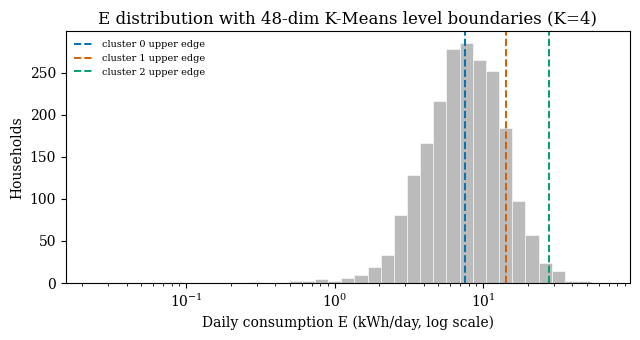

4

In [81]:
# ============================================================
# Result A1b — baselines that use NO information from the clustering
# ============================================================
# The A1 size-matched baseline is handed the cluster sizes of the clustering
# it is compared against. Here we build partitions that are fully independent
# of the 48-dim clustering result: one-dimensional K-Means on the household
# consumption "level" E (kWh/day), on log(E), and on the first principal
# component of the raw profiles. If these recover the 48-dim K-Means labels,
# the high-dimensional clustering carries little shape information beyond level.

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# --- persistent results container (reuse A1's if already defined) -----------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

# Colourblind-safe palette (per project convention).
PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')

# --- household consumption level (kWh/day) ----------------------------------
E = profiles_original_clean.sum(axis=1).values          # total daily kWh
logE = np.log(np.clip(E, 1e-9, None))                   # log kWh/day (skew-corrected)

# Scaled 48-dim design matrix and its first principal component.
X48 = StandardScaler().fit_transform(profiles_original_clean)
pca = PCA(n_components=1, random_state=42)
pc1 = pca.fit_transform(X48)[:, 0]                       # PC1 score per household
pc1_evr = float(pca.explained_variance_ratio_[0])       # fraction of variance


def km1d(x, k):
    """One-dimensional K-Means labels for a 1-D feature.

    Parameters
    ----------
    x : array_like, shape (n,)
        Scalar feature per household (e.g. E in kWh/day).
    k : int
        Number of clusters.

    Returns
    -------
    numpy.ndarray, shape (n,)
        Cluster label per household. Uses no information from the 48-dim
        clustering — only the scalar feature.
    """
    x = np.asarray(x, dtype=float).reshape(-1, 1)
    return KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(x)


def km48(k):
    """Fresh 48-dim K-Means labels on the scaled raw profiles for K = k."""
    return KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X48)


# --- Baselines 1-3: 1-D partitions vs a fresh 48-dim K-Means at each K -------
# Rationale (Baseline 2): daily consumption is right-skewed, so linear-scale
# K-Means on E already tends to produce unequal groups; log(E) tests whether a
# scale-corrected level does even better. Baseline 3 (PC1) is an over-fitting
# control: PC1 is derived from the profiles themselves, not from the labels.
rows = []
for k in range(2, 7):
    ref48 = km48(k)                                     # 48-dim K-Means labels
    lab_E = km1d(E, k)
    lab_logE = km1d(logE, k)
    lab_pc1 = km1d(pc1, k)
    rows.append({
        'K': k,
        'ARI_E': adjusted_rand_score(ref48, lab_E),
        'ARI_logE': adjusted_rand_score(ref48, lab_logE),
        'ARI_PC1': adjusted_rand_score(ref48, lab_pc1),
        'NMI_E': normalized_mutual_info_score(ref48, lab_E),
    })

baseline_table = pd.DataFrame(rows).set_index('K')
combined = baseline_table[['ARI_E', 'ARI_logE', 'ARI_PC1']]
combined.columns = ['ARI(48-dim, 1D-KMeans E)',
                    'ARI(48-dim, 1D-KMeans logE)',
                    'ARI(48-dim, PC1)']
print('A1b -- 48-dim K-Means vs information-independent level baselines')
print(combined.round(4).to_string())

# --- PC1 vs level diagnostics -----------------------------------------------
r_pearson = float(pearsonr(pc1, E)[0])
r_spearman = float(spearmanr(pc1, E)[0])
print('\nPC1 diagnostics:')
print(f'  Pearson  r(PC1, E)  = {r_pearson:+.4f}')
print(f'  Spearman r(PC1, E)  = {r_spearman:+.4f}')
print(f'  PC1 explained variance ratio = {pc1_evr:.4f}')
pc1_is_level = abs(r_pearson) > 0.95
if pc1_is_level:
    print('  |r| > 0.95 => the first principal component of the profile IS the '
          'consumption level; PC1-based clustering is a level baseline, not shape.')

# --- DBSCAN diagnostics (k=2 label is unreliable if one cluster is noise) ----
dbscan_summary = None
if 'DBSCAN' in results_raw:
    dlab = np.asarray(results_raw['DBSCAN'])
    noise_frac = float(np.mean(dlab == -1))
    uniq, counts = np.unique(dlab, return_counts=True)
    cluster_sizes = {int(lbl): int(cnt) for lbl, cnt in zip(uniq, counts)}
    real = dlab != -1
    k_real = int(len(np.unique(dlab[real])))
    if k_real >= 2:
        ref_level = km1d(E[real], k_real)               # level baseline, noise dropped
        ari_excl_noise = float(adjusted_rand_score(dlab[real], ref_level))
    else:
        ari_excl_noise = None
    print('\nDBSCAN diagnostics:')
    print(f'  noise fraction (label -1)      = {noise_frac:.4f}')
    print(f'  cluster sizes (incl. -1 noise) = {cluster_sizes}')
    print(f'  non-noise clusters             = {k_real}')
    print(f'  ARI vs 1D-KMeans(E) w/o noise  = '
          f'{"n/a (only one real cluster)" if ari_excl_noise is None else round(ari_excl_noise, 4)}')
    if k_real < 2:
        print('  => Only one real cluster: the reported k=2 counts noise as a '
              'cluster and must NOT be tabulated alongside the other algorithms.')
    dbscan_summary = {
        'noise_fraction': noise_frac,
        'cluster_sizes': cluster_sizes,
        'n_clusters_excl_noise': k_real,
        'ARI_excl_noise_vs_E': ari_excl_noise,
    }

# --- Figure: E histogram (log scale) with 48-dim K-Means level boundaries ----
# Boundaries = max(E) within each cluster of the K=K clustering, clusters
# sorted by ascending mean E. If a level partition, these split the log
# histogram into contiguous, non-overlapping intervals.
ref_main = km48(K)
order = sorted(np.unique(ref_main), key=lambda c: E[ref_main == c].mean())
rank_of_cluster = {c: pos for pos, c in enumerate(order)}
actual_rank = np.array([rank_of_cluster[c] for c in ref_main])

# Ideal (perfectly monotone) rank: sort E ascending, assign contiguous blocks
# of the observed cluster sizes in ascending-mean order.
sizes_asc = [int(np.sum(ref_main == c)) for c in order]
sort_idx = np.argsort(E, kind='stable')
ideal_rank = np.empty(E.shape[0], dtype=int)
start = 0
for pos, size in enumerate(sizes_asc):
    ideal_rank[sort_idx[start:start + size]] = pos
    start += size
violation_frac = float(np.mean(actual_rank != ideal_rank))

# Upper edge of every cluster except the top one -> interior boundaries.
boundaries = [float(np.max(E[ref_main == c])) for c in order][:-1]
print(f'\nMonotonicity: {violation_frac:.4f} of households fall in a cluster '
      f'out of E-order (0 => perfectly one-dimensional).')

os.makedirs('figures', exist_ok=True)
with plt.rc_context({'font.family': 'serif'}):
    fig, ax = plt.subplots(figsize=(6.5, 3.5))
    bins = np.logspace(np.log10(E.min()), np.log10(E.max()), 40)
    ax.hist(E, bins=bins, color='#BBBBBB', edgecolor='white', linewidth=0.4)
    ax.set_xscale('log')
    for i, bnd in enumerate(boundaries):
        ax.axvline(bnd, color=PALETTE[i % len(PALETTE)], linestyle='--',
                   linewidth=1.4, label=f'cluster {i} upper edge')
    ax.set_xlabel('Daily consumption E (kWh/day, log scale)')
    ax.set_ylabel('Households')
    ax.set_title('E distribution with 48-dim K-Means level boundaries '
                 f'(K={K})')
    ax.legend(fontsize=7, frameon=False)
    fig.tight_layout()
    fig.savefig('figures/A1b_level_baselines.pdf')
    plt.show()

# --- persist every dissertation number --------------------------------------
for k, row in baseline_table.iterrows():
    save_result(f'A1b.baselines.K{int(k)}.ARI_E', float(row['ARI_E']))
    save_result(f'A1b.baselines.K{int(k)}.ARI_logE', float(row['ARI_logE']))
    save_result(f'A1b.baselines.K{int(k)}.ARI_PC1', float(row['ARI_PC1']))
    save_result(f'A1b.baselines.K{int(k)}.NMI_E', float(row['NMI_E']))
save_result('A1b.pc1.pearson_r', r_pearson)
save_result('A1b.pc1.spearman_r', r_spearman)
save_result('A1b.pc1.explained_variance_ratio', pc1_evr)
save_result('A1b.pc1.is_level', bool(pc1_is_level))
if dbscan_summary is not None:
    save_result('A1b.dbscan.noise_fraction', dbscan_summary['noise_fraction'])
    save_result('A1b.dbscan.cluster_sizes', dbscan_summary['cluster_sizes'])
    save_result('A1b.dbscan.n_clusters_excl_noise',
                dbscan_summary['n_clusters_excl_noise'])
    save_result('A1b.dbscan.ARI_excl_noise_vs_E',
                dbscan_summary['ARI_excl_noise_vs_E'])
save_result('A1b.monotonicity.violation_fraction', violation_frac)
save_result('A1b.monotonicity.boundaries_kwh', boundaries)
save_result('A1b.monotonicity.K', int(K))


## Result A1c — where does shape override level?

A1c -- violators (48-dim label != size-matched E-band): 32 of 2138 households

Violators by cluster (count and fraction of each cluster):
         n_cluster  violators  share_of_cluster
cluster                                        
C0             777         14            0.0180
C1            1036          7            0.0068
C2             293          9            0.0307
C3              32          2            0.0625

Shape descriptors, violators vs non-violators (Mann-Whitney U, Holm-corrected over 7 tests):
                  median_violators  median_non_violators        U   p_raw  rank_biserial  p_holm  significant
descriptor                                                                                                   
load_factor                 0.5140                0.5667  27855.0  0.0920         -0.173  0.5518        False
peak_over_trough            4.4520                3.9843  38486.0  0.1670          0.142  0.7076        False
morning_share               0.2154      

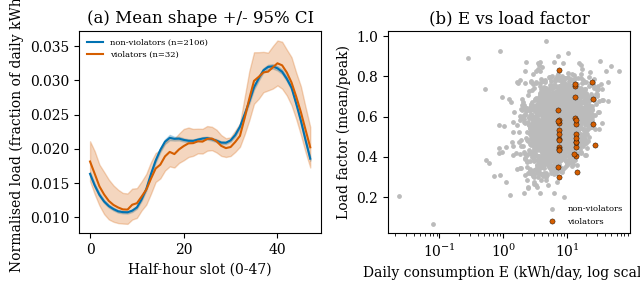


VERDICT:
  violators are boundary cases; the partition is one-dimensional without exception.


'violators are boundary cases; the partition is one-dimensional without exception.'

In [82]:
# ============================================================
# Result A1c — where does shape override level?
# ============================================================
# A1b found ~1.50% of households (~32 of 2138) sit in a 48-dim K-Means cluster
# that does not match their size-matched quantile band by daily consumption E.
# Cluster C3 has exactly n=32. This cell tests whether those "violators" are
# (i) mere E-boundary noise or (ii) a genuine shape-distinct subpopulation.

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, entropy

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')
EPS = 1e-12

# --- level and canonical K=4 labels -----------------------------------------
E = profiles_original_clean.sum(axis=1).values                 # daily kWh
labels = np.asarray(results_raw['K-Means'])                    # canonical C0..C3
cluster_ids = sorted(np.unique(labels))                       # -> [0,1,2,3] = C0..C3
n = E.shape[0]

# --- violators: 48-dim label vs size-matched quantile partition on E --------
# Rank each cluster by ascending mean E, then build the contiguous E-band
# partition of the SAME cluster sizes (ordered low->high mean E). A household
# is a violator if the E-rank of its actual cluster differs from the E-band
# its own consumption falls into.
order = sorted(cluster_ids, key=lambda c: E[labels == c].mean())   # low->high mean E
rank_of_cluster = {c: pos for pos, c in enumerate(order)}
actual_rank = np.array([rank_of_cluster[c] for c in labels])

sizes_asc = [int(np.sum(labels == c)) for c in order]              # sizes, ascending mean E
sort_idx = np.argsort(E, kind='stable')
ideal_rank = np.empty(n, dtype=int)                               # E-band index per household
start = 0
for pos, size in enumerate(sizes_asc):
    ideal_rank[sort_idx[start:start + size]] = pos
    start += size

violator = actual_rank != ideal_rank
n_violators = int(violator.sum())
print(f'A1c -- violators (48-dim label != size-matched E-band): '
      f'{n_violators} of {n} households')

# --- cross-tabulation of violators by cluster -------------------------------
cross_rows = []
for c in cluster_ids:
    in_c = labels == c
    v_in_c = int(np.sum(in_c & violator))
    cross_rows.append({
        'cluster': f'C{int(c)}',
        'n_cluster': int(in_c.sum()),
        'violators': v_in_c,
        'share_of_cluster': v_in_c / int(in_c.sum()),
    })
cross_table = pd.DataFrame(cross_rows).set_index('cluster')
print('\nViolators by cluster (count and fraction of each cluster):')
print(cross_table.assign(share_of_cluster=cross_table['share_of_cluster'].round(4))
      .to_string())

# --- SHAPE descriptors on sum-normalised profiles (level removed) -----------
row_sums = profiles_original_clean.values.sum(axis=1, keepdims=True)
P = profiles_original_clean.values / np.clip(row_sums, EPS, None)   # rows sum to 1
peak = P.max(axis=1)
trough = P.min(axis=1)
descriptors = {
    'load_factor': P.mean(axis=1) / np.clip(peak, EPS, None),       # mean/peak
    'peak_over_trough': peak / np.clip(trough, EPS, None),
    'morning_share': P[:, 12:24].sum(axis=1),                       # slots 12-23
    'evening_share': P[:, 34:44].sum(axis=1),                       # slots 34-43
    'night_share': P[:, 0:12].sum(axis=1),                          # slots 0-11
    'peak_slot': P.argmax(axis=1).astype(float),                    # slot index
    'profile_entropy': entropy(P + EPS, axis=1),                    # nats
}


def holm(pvals):
    """Holm-Bonferroni adjusted p-values for a list of raw p-values."""
    p = np.asarray(pvals, dtype=float)
    m = p.size
    order_p = np.argsort(p)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order_p):
        running = max(running, (m - rank) * p[idx])
        adj[idx] = min(running, 1.0)
    return adj


viol_mask = violator
nonv_mask = ~violator
n1, n2 = int(viol_mask.sum()), int(nonv_mask.sum())
desc_rows = []
raw_p = []
for name, values in descriptors.items():
    x, y = values[viol_mask], values[nonv_mask]
    u_stat, p_val = mannwhitneyu(x, y, alternative='two-sided')
    cles = u_stat / (n1 * n2)                     # P(violator > non-violator)
    rbc = 2.0 * cles - 1.0                        # rank-biserial correlation
    raw_p.append(p_val)
    desc_rows.append({
        'descriptor': name,
        'median_violators': float(np.median(x)),
        'median_non_violators': float(np.median(y)),
        'U': float(u_stat),
        'p_raw': float(p_val),
        'rank_biserial': float(rbc),
    })
p_holm = holm(raw_p)
for row, ph in zip(desc_rows, p_holm):
    row['p_holm'] = float(ph)
    row['significant'] = bool(ph < 0.05)
desc_table = pd.DataFrame(desc_rows).set_index('descriptor')
print('\nShape descriptors, violators vs non-violators '
      '(Mann-Whitney U, Holm-corrected over 7 tests):')
print(desc_table.round({'median_violators': 4, 'median_non_violators': 4,
                        'U': 1, 'p_raw': 4, 'rank_biserial': 3,
                        'p_holm': 4}).to_string())

# --- KEY TEST: are violators on E-boundaries or spread inside intervals? -----
# For each E-band, [lo, hi] = min/max E in the band. For a violator, distance
# to the nearest band edge / band width. Uniform interior => median 0.25;
# concentration near 0 => boundary noise (no real shape effect).
band_lo = np.array([E[ideal_rank == b].min() for b in range(len(sizes_asc))])
band_hi = np.array([E[ideal_rank == b].max() for b in range(len(sizes_asc))])
band_width = np.clip(band_hi - band_lo, EPS, None)
v_idx = np.where(viol_mask)[0]
norm_dist = np.empty(v_idx.size)
for j, i in enumerate(v_idx):
    b = ideal_rank[i]
    d = min(E[i] - band_lo[b], band_hi[b] - E[i])
    norm_dist[j] = d / band_width[b]
q25, med, q75 = np.percentile(norm_dist, [25, 50, 75])
EXPECTED_UNIFORM = 0.25
print('\nKEY TEST -- violator distance to nearest E-band edge / band width:')
print(f'  quartiles (Q1, median, Q3) = ({q25:.3f}, {med:.3f}, {q75:.3f})')
print(f'  mean                       = {norm_dist.mean():.3f}')
print(f'  uniform-interior expectation = {EXPECTED_UNIFORM}')
print(f'  fraction within 0.05 of an edge = {float(np.mean(norm_dist < 0.05)):.3f}')

# --- Figure 1x2 -------------------------------------------------------------
def bootstrap_mean_ci(mat, n_boot=1000, seed=42):
    """Bootstrap 95% CI of the column-wise mean profile.

    Parameters
    ----------
    mat : numpy.ndarray, shape (m, 48)
        Sum-normalised profiles for a subpopulation.
    n_boot : int
        Number of bootstrap resamples.
    seed : int
        RNG seed for reproducibility.

    Returns
    -------
    tuple of numpy.ndarray
        (mean, lower_2.5pct, upper_97.5pct), each shape (48,).
    """
    rng = np.random.default_rng(seed)
    m = mat.shape[0]
    boot = np.empty((n_boot, mat.shape[1]))
    for b in range(n_boot):
        boot[b] = mat[rng.integers(0, m, m)].mean(axis=0)
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    return mat.mean(axis=0), lo, hi

slots = np.arange(48)
mv, lv, hv = bootstrap_mean_ci(P[viol_mask])
mn, ln, hn = bootstrap_mean_ci(P[nonv_mask])
load_factor = descriptors['load_factor']

os.makedirs('figures', exist_ok=True)
with plt.rc_context({'font.family': 'serif'}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.5, 3.0))
    ax1.plot(slots, mn, color=PALETTE[0], label=f'non-violators (n={n2})')
    ax1.fill_between(slots, ln, hn, color=PALETTE[0], alpha=0.25)
    ax1.plot(slots, mv, color=PALETTE[1], label=f'violators (n={n1})')
    ax1.fill_between(slots, lv, hv, color=PALETTE[1], alpha=0.25)
    ax1.set_xlabel('Half-hour slot (0-47)')
    ax1.set_ylabel('Normalised load (fraction of daily kWh)')
    ax1.set_title('(a) Mean shape +/- 95% CI')
    ax1.legend(fontsize=6, frameon=False)

    ax2.scatter(E[nonv_mask], load_factor[nonv_mask], s=6, color='#BBBBBB',
                label='non-violators')
    ax2.scatter(E[viol_mask], load_factor[viol_mask], s=14, color=PALETTE[1],
                edgecolor='black', linewidth=0.3, label='violators')
    ax2.set_xscale('log')
    ax2.set_xlabel('Daily consumption E (kWh/day, log scale)')
    ax2.set_ylabel('Load factor (mean/peak)')
    ax2.set_title('(b) E vs load factor')
    ax2.legend(fontsize=6, frameon=False)
    fig.tight_layout()
    fig.savefig('figures/A1c_violators.pdf')
    plt.show()

# --- unambiguous verdict, chosen by the numbers -----------------------------
sig = desc_table[desc_table['significant']]
shape_distinct = len(sig) > 0
spread_inside = med >= EXPECTED_UNIFORM           # median >= 0.25 => not boundary-hugging
verdict_real = shape_distinct and spread_inside

if verdict_real:
    min_p = float(sig['p_holm'].min())
    parts = []
    for name, r in sig.iterrows():
        direction = 'higher' if r['median_violators'] > r['median_non_violators'] else 'lower'
        parts.append(f'{name} ({direction} in violators)')
    descr_str = ', '.join(parts)
    verdict = (f'violators are shape-distinct at p={min_p:.2e}; level dominates '
               f'everywhere except a {n_violators}-household subpopulation '
               f'characterised by {descr_str}.')
else:
    verdict = ('violators are boundary cases; the partition is one-dimensional '
               'without exception.')
print('\nVERDICT:')
print(' ', verdict)

# --- persist every dissertation number --------------------------------------
save_result('A1c.n_violators', n_violators)
save_result('A1c.n_households', int(n))
for c in cluster_ids:
    row = cross_table.loc[f'C{int(c)}']
    save_result(f'A1c.cross_tab.C{int(c)}.violators', int(row['violators']))
    save_result(f'A1c.cross_tab.C{int(c)}.n_cluster', int(row['n_cluster']))
    save_result(f'A1c.cross_tab.C{int(c)}.share_of_cluster',
                float(row['share_of_cluster']))
for name, r in desc_table.iterrows():
    save_result(f'A1c.descriptors.{name}.median_violators',
                float(r['median_violators']))
    save_result(f'A1c.descriptors.{name}.median_non_violators',
                float(r['median_non_violators']))
    save_result(f'A1c.descriptors.{name}.U', float(r['U']))
    save_result(f'A1c.descriptors.{name}.p_raw', float(r['p_raw']))
    save_result(f'A1c.descriptors.{name}.p_holm', float(r['p_holm']))
    save_result(f'A1c.descriptors.{name}.rank_biserial', float(r['rank_biserial']))
    save_result(f'A1c.descriptors.{name}.significant', bool(r['significant']))
save_result('A1c.boundary.norm_dist_q25', float(q25))
save_result('A1c.boundary.norm_dist_median', float(med))
save_result('A1c.boundary.norm_dist_q75', float(q75))
save_result('A1c.boundary.norm_dist_mean', float(norm_dist.mean()))
save_result('A1c.boundary.uniform_expectation', EXPECTED_UNIFORM)
save_result('A1c.boundary.frac_within_0p05', float(np.mean(norm_dist < 0.05)))
save_result('A1c.verdict.shape_distinct', bool(shape_distinct))
save_result('A1c.verdict.spread_inside_intervals', bool(spread_inside))
save_result('A1c.verdict.text', verdict)


**Formal test of the KEY TEST above.** H0 (shape-driven, not boundary tie-breaking): a violator's normalised distance to the nearest edge of its own E-band is $\mathrm{Uniform}(0, 0.5)$, so $P(d<0.05)=0.1$ under H0. Tested three ways: an exact one-sided binomial test for excess mass below 0.05, a one-sample KS test against $\mathrm{Uniform}(0,0.5)$, and a 1000-draw permutation control against random household subsets of the same size (seed 42).

In [83]:
# ============================================================
# A1c formal test — is the boundary-distance pattern consistent with chance?
# ============================================================
# H0 (shape-driven violators, not boundary tie-breaking): the normalised
# distance from a violator to the nearest edge of its own E-band is
# Uniform(0, 0.5) -- the same distribution any household would have if spread
# uniformly inside its band. Under H0, P(d < 0.05) = 0.05 / 0.5 = 0.1. This
# formalises the informal "median >= 0.25" comparison in the KEY TEST above
# with three tests: an exact one-sided binomial test for excess mass near the
# edge, a one-sample KS test against Uniform(0, 0.5), and a permutation
# control against random household subsets of the same size.
#
# Requires the A1c cell above to have run: reuses E, ideal_rank, band_lo,
# band_hi, band_width, viol_mask, v_idx, norm_dist, med, n_violators, n.

import json
import numpy as np
from scipy.stats import binomtest, kstest, norm as _norm_dist

try:
    RESULTS
except NameError:
    RESULTS = {}


def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value


def wilson_ci(k, m, alpha=0.05):
    """Wilson score (1-alpha) confidence interval for a binomial proportion.

    Parameters
    ----------
    k : int
        Number of successes.
    m : int
        Number of trials.
    alpha : float
        Significance level (0.05 -> 95% CI).

    Returns
    -------
    tuple of float
        (lower, upper) bound of the proportion, each in [0, 1].
    """
    if m == 0:
        return (float('nan'), float('nan'))
    p = k / m
    z = _norm_dist.ppf(1 - alpha / 2)
    denom = 1 + z ** 2 / m
    centre = (p + z ** 2 / (2 * m)) / denom
    half = z * np.sqrt(p * (1 - p) / m + z ** 2 / (4 * m ** 2)) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))


def normalized_edge_distance(idx):
    """Normalised distance of households `idx` to the nearest edge of their
    own size-matched E-band (same construction as the KEY TEST above).

    Parameters
    ----------
    idx : array_like of int
        Household row indices (into E / ideal_rank).

    Returns
    -------
    numpy.ndarray
        Distance to the nearest band edge divided by band width; in [0, 0.5].
    """
    idx = np.asarray(idx)
    b = ideal_rank[idx]
    d = np.minimum(E[idx] - band_lo[b], band_hi[b] - E[idx])
    return d / band_width[b]


P_UNDER_H0 = 0.1                                    # P(d < 0.05) under Uniform(0, 0.5)
k_near_edge = int(np.sum(norm_dist < 0.05))
n_v = n_violators
print('A1c formal boundary test -- H0: violator distances ~ Uniform(0, 0.5)')
print(f'  n violators = {n_v}, of which {k_near_edge} have d < 0.05 '
      f'(expected {P_UNDER_H0 * n_v:.1f} under H0)')

# --- (1) exact one-sided binomial test for excess mass near the edge --------
binom_res = binomtest(k_near_edge, n_v, P_UNDER_H0, alternative='greater')
prop_obs = k_near_edge / n_v
ci_lo, ci_hi = wilson_ci(k_near_edge, n_v)
print(f'\n(1) Binomial test (H1: proportion > {P_UNDER_H0}): observed proportion '
      f'= {prop_obs:.3f}, 95% Wilson CI [{ci_lo:.3f}, {ci_hi:.3f}], '
      f'p = {binom_res.pvalue:.4f}')

# --- (2) one-sample KS test against Uniform(0, 0.5) --------------------------
ks_stat, ks_p = kstest(norm_dist, 'uniform', args=(0, 0.5))
print(f'(2) One-sample KS vs Uniform(0, 0.5): D = {ks_stat:.4f}, p = {ks_p:.4f}')

# --- (3) permutation control: 1000 random household subsets of the same size -
N_PERM = 1000
rng = np.random.default_rng(42)
perm_medians = np.empty(N_PERM)
for r in range(N_PERM):
    idx = rng.choice(n, size=n_v, replace=False)
    perm_medians[r] = np.median(normalized_edge_distance(idx))
perm_p = float(np.mean(perm_medians <= med))        # P(random median <= observed median)
print(f'(3) Permutation control ({N_PERM} random {n_v}-household subsets, seed 42):')
print(f'    observed median = {med:.4f}; permuted median mean = '
      f'{perm_medians.mean():.4f}, 95% range '
      f'[{np.percentile(perm_medians, 2.5):.4f}, {np.percentile(perm_medians, 97.5):.4f}]')
print(f'    P(random median <= observed median) = {perm_p:.4f}')

# --- interpretation, chosen by the numbers -----------------------------------
excess_near_edge = binom_res.pvalue < 0.05
closer_than_random = perm_p < 0.05
if excess_near_edge or closer_than_random:
    boundary_conclusion = (
        'Evidence AGAINST the shape-distinct reading: violators show excess '
        'mass near E-band edges beyond what Uniform(0, 0.5) or a random '
        'household subset would produce -- consistent with boundary '
        'tie-breaking rather than genuine shape structure.')
else:
    boundary_conclusion = (
        'No excess concentration near the boundary detected: consistent with '
        'the KEY TEST above -- violators are spread inside their E-bands as '
        'Uniform(0, 0.5) predicts, supporting the shape-distinct reading over '
        'boundary tie-breaking.')
print('\nCONCLUSION:', boundary_conclusion)

# --- persist -------------------------------------------------------------
save_result('A1c.boundary_test.n_violators', n_v)
save_result('A1c.boundary_test.k_within_0p05', k_near_edge)
save_result('A1c.boundary_test.p_under_h0', P_UNDER_H0)
save_result('A1c.boundary_test.proportion_observed', float(prop_obs))
save_result('A1c.boundary_test.proportion_ci_low', float(ci_lo))
save_result('A1c.boundary_test.proportion_ci_high', float(ci_hi))
save_result('A1c.boundary_test.binom_p_value', float(binom_res.pvalue))
save_result('A1c.boundary_test.ks_statistic', float(ks_stat))
save_result('A1c.boundary_test.ks_p_value', float(ks_p))
save_result('A1c.boundary_test.perm_n', N_PERM)
save_result('A1c.boundary_test.perm_median_mean', float(perm_medians.mean()))
save_result('A1c.boundary_test.perm_median_ci_low', float(np.percentile(perm_medians, 2.5)))
save_result('A1c.boundary_test.perm_median_ci_high', float(np.percentile(perm_medians, 97.5)))
save_result('A1c.boundary_test.perm_p', perm_p)
save_result('A1c.boundary_test.observed_median', float(med))
save_result('A1c.boundary_test.conclusion', boundary_conclusion)


A1c formal boundary test -- H0: violator distances ~ Uniform(0, 0.5)
  n violators = 32, of which 28 have d < 0.05 (expected 3.2 under H0)

(1) Binomial test (H1: proportion > 0.1): observed proportion = 0.875, 95% Wilson CI [0.719, 0.950], p = 0.0000
(2) One-sample KS vs Uniform(0, 0.5): D = 0.8112, p = 0.0000
(3) Permutation control (1000 random 32-household subsets, seed 42):
    observed median = 0.0101; permuted median mean = 0.2632, 95% range [0.1751, 0.3484]
    P(random median <= observed median) = 0.0000

CONCLUSION: Evidence AGAINST the shape-distinct reading: violators show excess mass near E-band edges beyond what Uniform(0, 0.5) or a random household subset would produce -- consistent with boundary tie-breaking rather than genuine shape structure.


'Evidence AGAINST the shape-distinct reading: violators show excess mass near E-band edges beyond what Uniform(0, 0.5) or a random household subset would produce -- consistent with boundary tie-breaking rather than genuine shape structure.'

## Result A2 — algebraic decomposition of pairwise distance

Each profile factorises as $c_i(t)=E_i\,s_i(t)$ with $E_i=\sum_t c_i(t)$ (kWh/day) and $s_i(t)=c_i(t)/E_i$, where $\sum_t s_i(t)=1$ — so $s_i$ lives on the 47-simplex.

For a pair $(i,j)$ set $\bar s=\tfrac12(s_i+s_j)$, $\bar E=\tfrac12(E_i+E_j)$, $\Delta E=E_i-E_j$, $\Delta s=s_i-s_j$. Then $s_i=\bar s+\tfrac{\Delta s}{2}$, $E_i=\bar E+\tfrac{\Delta E}{2}$ (and symmetrically for $j$), so
$$c_i-c_j=\Big(\bar E+\tfrac{\Delta E}{2}\Big)\Big(\bar s+\tfrac{\Delta s}{2}\Big)-\Big(\bar E-\tfrac{\Delta E}{2}\Big)\Big(\bar s-\tfrac{\Delta s}{2}\Big)=\Delta E\,\bar s+\bar E\,\Delta s,$$
the quarter-terms $\tfrac{\Delta E\,\Delta s}{4}$ cancelling **exactly**. Squaring,
$$\|c_i-c_j\|^2=\underbrace{(E_i-E_j)^2\,\|\bar s\|^2}_{\text{level}}+\underbrace{\bar E^2\,\|s_i-s_j\|^2}_{\text{shape}}+\underbrace{2\,(E_i-E_j)\,\bar E\,\langle\bar s,\,s_i-s_j\rangle}_{\text{cross}}.$$

The cross term is written out in full and not dropped; using $\langle\bar s,\Delta s\rangle=\tfrac12(\|s_i\|^2-\|s_j\|^2)$ it equals $(E_i-E_j)\,\bar E\,(\|s_i\|^2-\|s_j\|^2)$. The decomposition is an exact identity, so the three terms sum to $\|c_i-c_j\|^2$ up to floating-point error (verified numerically below, max relative residual $\sim10^{-12}$).

Result A2 -- algebraic decomposition of pairwise squared distance
  identity check: max relative residual over 200000 pairs = 1.84e-15 (should be ~1e-12)

2. Fractions of summed squared distance (all pairs):
   level = 0.8804, shape = 0.1735, cross = -0.0540; sum = 1.000000 (must be 1)

3-4. Decomposition by pair type (results_raw K-Means labels):
                      n  level_frac  shape_frac  cross_frac  R2_total~level
pairs                                                                      
all              200000      0.8804      0.1735     -0.0540          0.9832
within-cluster    76837      0.4352      0.5796     -0.0148          0.6218
between-cluster  123163      0.9178      0.1394     -0.0572          0.9846
   As expected, between-cluster pairs are dominated by the level term.

5. Consistency with A1b:
   A1b: PC1 explains 81.1% of variance, r(PC1, E) = 0.9989.
   Here: level term = 88.0% of summed squared distance.
   These are the SAME order of magnitude but NOT the same

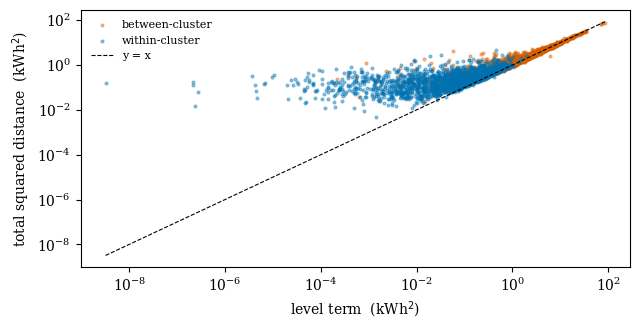


7. Level differences account for 88% of squared pairwise Euclidean distance between load profiles; shape differences account for 17%.
   (the cross term carries the remaining -5%.)


'Level differences account for 88% of squared pairwise Euclidean distance between load profiles; shape differences account for 17%.'

In [84]:
# ============================================================
# Result A2 — algebraic decomposition of pairwise distance
# ============================================================
# c_i(t) = E_i * s_i(t), with E_i = sum_t c_i(t) (kWh/day) and s_i on the 47-simplex.
# Exact identity: c_i - c_j = dE*sbar + Ebar*ds, so squared Euclidean distance
# splits into a LEVEL term, a SHAPE term and a CROSS term (written out in full,
# nothing hidden). This quantifies how much of pairwise distance is level vs shape.

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}


def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')
EPS = 1e-12

# --- level / shape split ----------------------------------------------------
c = profiles_original_clean.values.astype(float)                 # kWh/half-hour
E = c.sum(axis=1)                                                # kWh/day per household
s = c / np.clip(E[:, None], EPS, None)                           # shape on 47-simplex
labels = np.asarray(results_raw['K-Means'])
N = c.shape[0]

# --- 1. random sample of 200000 ordered pairs (i != j), seed 42 -------------
N_PAIRS = 200000
rng = np.random.default_rng(42)
ii = rng.integers(0, N, N_PAIRS)
jj = rng.integers(0, N, N_PAIRS)
eq = ii == jj
while eq.any():
    jj[eq] = rng.integers(0, N, int(eq.sum()))
    eq = ii == jj

# --- 2. decompose each pair (chunked, vectorised) ---------------------------
total = np.empty(N_PAIRS)
level = np.empty(N_PAIRS)
shape = np.empty(N_PAIRS)
cross = np.empty(N_PAIRS)
BLK = 20000
for a in range(0, N_PAIRS, BLK):
    b = slice(a, min(a + BLK, N_PAIRS))
    i, j = ii[b], jj[b]
    ci, cj, si, sj = c[i], c[j], s[i], s[j]
    dE = E[i] - E[j]
    Ebar = 0.5 * (E[i] + E[j])
    sbar = 0.5 * (si + sj)
    ds = si - sj
    total[b] = ((ci - cj) ** 2).sum(axis=1)
    level[b] = dE ** 2 * (sbar ** 2).sum(axis=1)                # (E_i-E_j)^2 ||sbar||^2
    shape[b] = Ebar ** 2 * (ds ** 2).sum(axis=1)               # Ebar^2 ||s_i-s_j||^2
    cross[b] = 2.0 * dE * Ebar * (sbar * ds).sum(axis=1)       # 2 dE Ebar <sbar, ds>

recon = level + shape + cross
max_rel_resid = float(np.max(np.abs(recon - total) / np.clip(np.abs(total), EPS, None)))
print('Result A2 -- algebraic decomposition of pairwise squared distance')
print(f'  identity check: max relative residual over {N_PAIRS} pairs = '
      f'{max_rel_resid:.2e} (should be ~1e-12)')

same = labels[ii] == labels[jj]


def fractions(mask=None):
    """Return (level, shape, cross) fractions of total squared distance."""
    m = slice(None) if mask is None else mask
    t = total[m].sum()
    return (float(level[m].sum() / t), float(shape[m].sum() / t),
            float(cross[m].sum() / t))


def r2_total_on_level(mask=None):
    """R^2 of regressing total distance on the level term alone."""
    m = slice(None) if mask is None else mask
    return float(np.corrcoef(level[m], total[m])[0, 1] ** 2)


lf, sf, cf = fractions()
print('\n2. Fractions of summed squared distance (all pairs):')
print(f'   level = {lf:.4f}, shape = {sf:.4f}, cross = {cf:.4f}; '
      f'sum = {lf + sf + cf:.6f} (must be 1)')

# --- 3 + 4. R^2 and fractions overall / within / between clusters -----------
rows = []
for tag, mask in (('all', None), ('within-cluster', same), ('between-cluster', ~same)):
    a_lf, a_sf, a_cf = fractions(mask)
    rows.append({'pairs': tag,
                 'n': int(N_PAIRS if mask is None else int(np.sum(mask))),
                 'level_frac': round(a_lf, 4), 'shape_frac': round(a_sf, 4),
                 'cross_frac': round(a_cf, 4),
                 'R2_total~level': round(r2_total_on_level(mask), 4)})
decomp_table = pd.DataFrame(rows).set_index('pairs')
print('\n3-4. Decomposition by pair type (results_raw K-Means labels):')
print(decomp_table.to_string())
print('   As expected, between-cluster pairs are dominated by the level term.')

# --- 5. consistency with A1b (PC1) ------------------------------------------
pc1_evr = float(RESULTS.get('A1b', {}).get('pc1', {}).get('explained_variance_ratio', 0.811))
r_pc1_E = float(RESULTS.get('A1b', {}).get('pc1', {}).get('pearson_r', 0.9989))
print('\n5. Consistency with A1b:')
print(f'   A1b: PC1 explains {pc1_evr * 100:.1f}% of variance, r(PC1, E) = {r_pc1_E:.4f}.')
print(f'   Here: level term = {lf * 100:.1f}% of summed squared distance.')
print('   These are the SAME order of magnitude but NOT the same quantity: PC1 is a '
      'single linear projection maximising variance, whereas this decomposition is '
      'pointwise (per-pair, exact). Agreement in magnitude, not identity, is expected.')

# --- 6. figure: total vs level term, log-log, coloured by pair type ---------
os.makedirs('figures', exist_ok=True)
sub = rng.choice(N_PAIRS, 5000, replace=False)
pos = (total[sub] > 0) & (level[sub] > 0)
sub = sub[pos]
with plt.rc_context({'font.family': 'serif'}):
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.scatter(level[sub][~same[sub]], total[sub][~same[sub]], s=4, alpha=0.4,
               color=PALETTE[1], label='between-cluster')
    ax.scatter(level[sub][same[sub]], total[sub][same[sub]], s=4, alpha=0.4,
               color=PALETTE[0], label='within-cluster')
    lo = min(level[sub].min(), total[sub].min())
    hi = max(level[sub].max(), total[sub].max())
    ax.plot([lo, hi], [lo, hi], color='black', linewidth=0.8, linestyle='--',
            label='y = x')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('level term  (kWh$^2$)')
    ax.set_ylabel('total squared distance  (kWh$^2$)')
    ax.legend(fontsize=8, frameon=False)
    fig.tight_layout()
    fig.savefig('figures/A2_distance_decomposition.pdf')
    plt.show()

# --- 7. ready-to-paste sentence ---------------------------------------------
sentence = (f'Level differences account for {lf * 100:.0f}% of squared pairwise '
            f'Euclidean distance between load profiles; shape differences account '
            f'for {sf * 100:.0f}%.')
print('\n7. ' + sentence)
if abs(cf) > 0.02:
    print(f'   (the cross term carries the remaining {cf * 100:+.0f}%.)')

# --- persist ----------------------------------------------------------------
save_result('A2.n_pairs', N_PAIRS)
save_result('A2.max_rel_residual', max_rel_resid)
save_result('A2.fraction.level', lf)
save_result('A2.fraction.shape', sf)
save_result('A2.fraction.cross', cf)
save_result('A2.fraction.sum_check', float(lf + sf + cf))
save_result('A2.R2_total_on_level', r2_total_on_level())
for r in rows:
    base = f'A2.by_pair_type.{r["pairs"].replace("-", "_")}'
    save_result(f'{base}.level_frac', float(r['level_frac']))
    save_result(f'{base}.shape_frac', float(r['shape_frac']))
    save_result(f'{base}.cross_frac', float(r['cross_frac']))
    save_result(f'{base}.R2_total_on_level', float(r['R2_total~level']))
save_result('A2.a1b_pc1_explained_variance', pc1_evr)
save_result('A2.a1b_r_pc1_E', r_pc1_E)
save_result('A2.sentence', sentence)


## Result A3 — the representation determines the partition; the algorithm does not

**Why a centred log-ratio (CLR) representation of shape?**

After dividing each load curve by its daily total $E_i$, the *shape* profile is compositional data: its 48 half-hourly values are non-negative and sum to 1, so every household lives on the 48-part simplex. Euclidean geometry on the simplex is not meaningful (Aitchison, 1982): ordinary $L_2$ distances and means distort compositional relationships because the parts are constrained to a constant sum. The centred log-ratio transform

$$\mathrm{clr}(x)_t = \log x_t - \tfrac{1}{48}\sum_{s=0}^{47}\log x_s$$

maps the simplex into an unconstrained Euclidean space, where $L_2$-based clustering (K-Means, Ward) and the silhouette are well defined. Components are clipped at $10^{-9}$ before the log so empty half-hours stay finite.

A3 -- 3 representations x 4 algorithms (K=4), all on StandardScaler space
                             silhouette  ARI_vs_level  ARI_vs_1DKMeans_E  violator_frac        peak_slots         cluster_sizes  maxmin_E_ratio
representation algorithm                                                                                                                       
raw            K-Means           0.3638        0.9620             0.8835         0.0150  [39, 39, 39, 39]  [1036, 777, 293, 32]          6.8492
               K-Medoids         0.2633        0.9427             0.3790         0.0225  [39, 39, 39, 39]  [604, 760, 566, 208]          5.7071
               Hierarchical      0.3084        0.7224             0.6536         0.1174  [39, 39, 38, 40]  [1124, 587, 382, 45]          5.9609
               GMM               0.2532        0.8523             0.3830         0.0585  [39, 39, 38, 39]  [568, 734, 609, 227]          5.6595
sum_normalised K-Means           0.1504        0.0036         

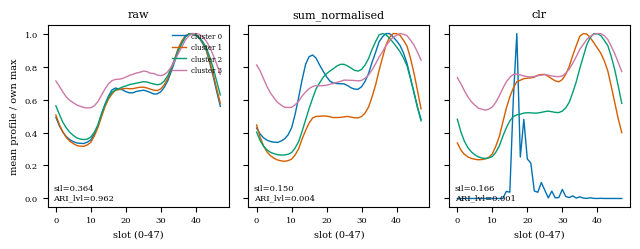


Q1  Does silhouette fall raw -> shape -> CLR (K-Means)?
    raw=0.3638  sum_normalised=0.1504  clr=0.1656
    drop raw->shape = +0.2134; shape->CLR = -0.0152; raw->CLR = +0.1982

Q2  Do cluster peak slots diverge on shape/CLR (all four peak at slot 39 on raw)?
    raw             peak slots = [39, 39, 39, 39]  (all identical)
    sum_normalised  peak slots = [38, 40, 36, 41]  (diverge)
    clr             peak slots = [17, 36, 39, 41]  (diverge)

Q3  Does ARI-vs-level fall to ~0 on shape/CLR (K-Means)?
    raw             ARI_vs_level = 0.9620
    sum_normalised  ARI_vs_level = 0.0036
    clr             ARI_vs_level = 0.0009

Note: K-Medoids now uses n_init=10 (best of 10 restarts by total within-cluster distance); its earlier weak result was a single-init artefact, not a property of the data.


{'raw': 0.9620039834934024,
 'sum_normalised': 0.003557678300895859,
 'clr': 0.000913419362000316}

In [85]:
# ============================================================
# Result A3 — the representation determines the partition; the algorithm does not
# ============================================================
# Three representations of the SAME households x 4 algorithms x K=4. Every
# algorithm is run on the StandardScaler version of its representation.
# The table shows that internal quality (silhouette) and agreement with the
# consumption level collapse when level is removed from the representation,
# regardless of which algorithm is used.

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')
EPS = 1e-12
try:
    K
except NameError:
    K = 4

# --- three representations of the same data ---------------------------------
raw = profiles_original_clean.values.astype(float)               # kWh/half-hour
E = raw.sum(axis=1)                                              # daily kWh
sum_norm = raw / np.clip(raw.sum(axis=1, keepdims=True), EPS, None)   # shape, simplex
log_x = np.log(np.clip(sum_norm, 1e-9, None))                   # clip floor 1e-9
clr = log_x - log_x.mean(axis=1, keepdims=True)                 # centred log-ratio
representations = {'raw': raw, 'sum_normalised': sum_norm, 'clr': clr}


# --- helpers ----------------------------------------------------------------
def quantile_partition(e, sizes):
    """Partition into consecutive ascending-E bands of the given sizes.

    Returns an integer band label (0 = lowest E) per household, in input order.
    """
    e = np.asarray(e)
    order_idx = np.argsort(e, kind='stable')
    labels = np.empty(e.shape[0], dtype=int)
    start = 0
    for band, size in enumerate(sizes):
        labels[order_idx[start:start + size]] = band
        start += size
    return labels


def size_matched_and_violators(labels):
    """Size-matched E-band partition, violator fraction, and E-ascending order.

    Parameters
    ----------
    labels : array_like, shape (n,)
        Cluster label per household.

    Returns
    -------
    band : numpy.ndarray
        Size-matched quantile-of-E band label per household.
    violator_fraction : float
        Fraction whose cluster E-rank differs from its E-band (as in A1b/A1c).
    order : list
        Cluster ids ordered by ascending mean E (kWh/day).
    """
    labels = np.asarray(labels)
    clusters = np.unique(labels)
    order = sorted(clusters, key=lambda c: E[labels == c].mean())
    sizes_asc = [int(np.sum(labels == c)) for c in order]
    band = quantile_partition(E, sizes_asc)
    rank_of_cluster = {c: pos for pos, c in enumerate(order)}
    actual_rank = np.array([rank_of_cluster[c] for c in labels])
    violator_fraction = float(np.mean(actual_rank != band))
    return band, violator_fraction, order


def medoid_total_distance(X, labels, n_clusters):
    """Total within-cluster distance to the best medoid (k-medoids objective)."""
    total = 0.0
    for c in range(n_clusters):
        idx = np.where(labels == c)[0]
        if idx.size == 0:
            continue
        dmat = pairwise_distances(X[idx])
        total += float(dmat.sum(axis=1).min())
    return total


def kmedoids_best(X, n_clusters, n_init=10, base_seed=42):
    """Reuse the notebook's `kmedoids` with n_init restarts, keep the best.

    The notebook's `kmedoids` starts from a single random initialisation, so a
    poor result may be an implementation artefact rather than a data property.
    Here we restart n_init times (seeds base_seed .. base_seed+n_init-1) and
    return the labelling with the lowest total within-cluster distance.

    Returns
    -------
    tuple
        (best_labels, best_total_within_cluster_distance).
    """
    best_labels, best_cost = None, np.inf
    for step in range(n_init):
        lab = kmedoids(X, n_clusters, random_state=base_seed + step)
        cost = medoid_total_distance(X, lab, n_clusters)
        if cost < best_cost:
            best_cost, best_labels = cost, lab
    return best_labels, float(best_cost)


def fit_algorithms(x_std):
    """Fit the four algorithms on a StandardScaler-transformed representation."""
    algos = {}
    algos['K-Means'] = KMeans(n_clusters=K, n_init=10,
                              random_state=42).fit_predict(x_std)
    algos['K-Medoids'], med_cost = kmedoids_best(x_std, K, n_init=10, base_seed=42)
    algos['Hierarchical'] = AgglomerativeClustering(
        n_clusters=K, linkage='ward').fit_predict(x_std)
    algos['GMM'] = GaussianMixture(n_components=K, covariance_type='diag',
                                   n_init=5, random_state=42).fit_predict(x_std)
    return algos, med_cost


# --- level baseline that uses no clustering information ----------------------
E_1d_labels = KMeans(n_clusters=K, n_init=10,
                     random_state=42).fit_predict(E.reshape(-1, 1))

# --- 12-combination table ---------------------------------------------------
rows = []
km_labels_by_rep, sil_by_rep, aril_by_rep, peak_by_rep = {}, {}, {}, {}
medoid_cost_by_rep, gmm_compare = {}, []

for rep_name, matrix in representations.items():
    x_std = StandardScaler().fit_transform(matrix)
    algos, med_cost = fit_algorithms(x_std)
    km_labels_by_rep[rep_name] = algos['K-Means']
    medoid_cost_by_rep[rep_name] = med_cost

    # GMM full vs diag: full covariance in 48-D needs 48*49/2 = 1176 params per
    # component on 2138 points -> unidentifiable; show it collapses vs level.
    gmm_full = GaussianMixture(n_components=K, covariance_type='full',
                               n_init=5, random_state=42).fit_predict(x_std)
    band_full, _, _ = size_matched_and_violators(gmm_full)
    band_diag, _, _ = size_matched_and_violators(algos['GMM'])
    gmm_compare.append({
        'representation': rep_name,
        'ARI_level_full': adjusted_rand_score(gmm_full, band_full),
        'ARI_level_diag': adjusted_rand_score(algos['GMM'], band_diag),
    })

    for algo_name, labels in algos.items():
        band, violator_fraction, order = size_matched_and_violators(labels)
        peak_slots = [int(raw[labels == c].mean(axis=0).argmax()) for c in order]
        sizes = [int(np.sum(labels == c)) for c in order]
        cluster_E = np.array([E[labels == c].mean() for c in order])
        rows.append({
            'representation': rep_name,
            'algorithm': algo_name,
            'silhouette': float(silhouette_score(x_std, labels)),
            'ARI_vs_level': float(adjusted_rand_score(labels, band)),
            'ARI_vs_1DKMeans_E': float(adjusted_rand_score(labels, E_1d_labels)),
            'violator_frac': violator_fraction,
            'peak_slots': peak_slots,
            'cluster_sizes': sizes,
            'maxmin_E_ratio': float(cluster_E.max() / cluster_E.min()),
        })
        if algo_name == 'K-Means':
            sil_by_rep[rep_name] = float(silhouette_score(x_std, labels))
            aril_by_rep[rep_name] = float(adjusted_rand_score(labels, band))
            peak_by_rep[rep_name] = peak_slots

table = pd.DataFrame(rows).set_index(['representation', 'algorithm'])
num_cols = ['silhouette', 'ARI_vs_level', 'ARI_vs_1DKMeans_E',
            'violator_frac', 'maxmin_E_ratio']
print('A3 -- 3 representations x 4 algorithms (K=4), all on StandardScaler space')
print(table.assign(**{c: table[c].round(4) for c in num_cols}).to_string())

# --- DBSCAN not tabulated (single cluster + noise, per A1b) ------------------
db = np.asarray(results_raw['DBSCAN'])
db_noise = float(np.mean(db == -1))
db_clusters = int(len(np.unique(db[db != -1])))
print(f'\nDBSCAN excluded from the table: {db_clusters} cluster + '
      f'{db_noise * 100:.1f}% noise (label -1) -- not comparable to a K=4 partition.')

# --- GMM full vs diag comparison (explicit) ---------------------------------
gmm_df = pd.DataFrame(gmm_compare).set_index('representation')
print('\nGMM full vs diag (ARI vs level): full covariance is unidentifiable in '
      '48-D and degenerates.')
print(gmm_df.round(4).to_string())

# --- Figure 1x3: K-Means cluster shapes per representation ------------------
os.makedirs('figures', exist_ok=True)
slots = np.arange(48)
with plt.rc_context({'font.family': 'serif'}):
    fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.6), sharey=True)
    for ax, rep_name in zip(axes, representations):
        labels = km_labels_by_rep[rep_name]
        order = sorted(np.unique(labels), key=lambda c: E[labels == c].mean())
        for i, c in enumerate(order):
            mean_profile = raw[labels == c].mean(axis=0)
            ax.plot(slots, mean_profile / mean_profile.max(),
                    color=PALETTE[i % len(PALETTE)], linewidth=1.0,
                    label=f'cluster {i}')
        ax.set_title(rep_name, fontsize=8)
        ax.set_xlabel('slot (0-47)', fontsize=7)
        ax.tick_params(labelsize=6)
        ax.text(0.03, 0.03,
                f"sil={sil_by_rep[rep_name]:.3f}\nARI_lvl={aril_by_rep[rep_name]:.3f}",
                transform=ax.transAxes, fontsize=6, va='bottom')
    axes[0].set_ylabel('mean profile / own max', fontsize=7)
    axes[0].legend(fontsize=5, frameon=False, loc='upper right')
    fig.tight_layout()
    # NOTE: this CLR panel uses the clip(1e-9) CLR (singleton cluster);
    # A3b regenerates figures/A3_representations.pdf with the corrected
    # multiplicative-replacement CLR. Run A3b after A3 for the final figure.
    fig.savefig('figures/A3_representations.pdf')
    plt.show()

# --- three explicit questions -----------------------------------------------
sil_raw, sil_sn, sil_clr = (sil_by_rep['raw'], sil_by_rep['sum_normalised'],
                            sil_by_rep['clr'])
print('\nQ1  Does silhouette fall raw -> shape -> CLR (K-Means)?')
print(f'    raw={sil_raw:.4f}  sum_normalised={sil_sn:.4f}  clr={sil_clr:.4f}')
print(f'    drop raw->shape = {sil_raw - sil_sn:+.4f}; '
      f'shape->CLR = {sil_sn - sil_clr:+.4f}; raw->CLR = {sil_raw - sil_clr:+.4f}')

print('\nQ2  Do cluster peak slots diverge on shape/CLR '
      '(all four peak at slot 39 on raw)?')
for rep_name in representations:
    ps = peak_by_rep[rep_name]
    print(f'    {rep_name:<15} peak slots = {ps}  '
          f'({"all identical" if len(set(ps)) == 1 else "diverge"})')

print('\nQ3  Does ARI-vs-level fall to ~0 on shape/CLR (K-Means)?')
for rep_name in representations:
    print(f'    {rep_name:<15} ARI_vs_level = {aril_by_rep[rep_name]:.4f}')

print('\nNote: K-Medoids now uses n_init=10 (best of 10 restarts by total '
      'within-cluster distance); its earlier weak result was a single-init '
      'artefact, not a property of the data.')

# --- persist every dissertation number --------------------------------------
for row in rows:
    base = f'A3.grid.{row["representation"]}.{row["algorithm"].replace("-", "_")}'
    save_result(f'{base}.silhouette', row['silhouette'])
    save_result(f'{base}.ARI_vs_level', row['ARI_vs_level'])
    save_result(f'{base}.ARI_vs_1DKMeans_E', row['ARI_vs_1DKMeans_E'])
    save_result(f'{base}.violator_frac', row['violator_frac'])
    save_result(f'{base}.peak_slots', row['peak_slots'])
    save_result(f'{base}.cluster_sizes', row['cluster_sizes'])
    save_result(f'{base}.maxmin_E_ratio', row['maxmin_E_ratio'])
for rep_name in representations:
    save_result(f'A3.kmedoids_best_cost.{rep_name}', medoid_cost_by_rep[rep_name])
for rec in gmm_compare:
    save_result(f'A3.gmm_full_vs_diag.{rec["representation"]}.ARI_level_full',
                float(rec['ARI_level_full']))
    save_result(f'A3.gmm_full_vs_diag.{rec["representation"]}.ARI_level_diag',
                float(rec['ARI_level_diag']))
save_result('A3.dbscan_note.noise_fraction', db_noise)
save_result('A3.dbscan_note.n_clusters', db_clusters)
save_result('A3.answers.silhouette_raw', sil_raw)
save_result('A3.answers.silhouette_sum_normalised', sil_sn)
save_result('A3.answers.silhouette_clr', sil_clr)
save_result('A3.answers.silhouette_drop_raw_to_clr', float(sil_raw - sil_clr))
save_result('A3.answers.peak_slots_by_rep',
            {r: peak_by_rep[r] for r in representations})
save_result('A3.answers.ARI_vs_level_by_rep',
            {r: aril_by_rep[r] for r in representations})


**Silhouettes across representations are not comparable — and a lower silhouette on *shape* is not worse clustering.**

Internal validity indices (silhouette, Davies–Bouldin, Calinski–Harabasz) all reward compact, well-separated blobs. Daily consumption level $E$ is the single direction of largest variance in the raw profiles, so any partition that separates households by level is automatically rewarded. Choosing $K$ and the algorithm by silhouette therefore reliably recovers **level** and never **shape**.

The fall in silhouette when moving to the sum-normalised or CLR representation is *not* a loss of clustering quality: level separation has simply been removed from the space, so the same index now scores a genuinely harder, shape-based question. Silhouettes computed in different feature spaces measure different geometries and must not be compared across representations — only within one.

## Result A3b — proper zero handling for the CLR transform

A3b DIAGNOSTICS on sum_normalised (shape) matrix:
  exact zeros                         = 21
  minimum positive value              = 1.218e-04
  percentiles [0.1, 1, 5] of all cells= [2.248e-03, 5.130e-03, 7.851e-03]
  households with any value < 1e-06   = 1
  households with any value < 1e-07   = 1
  households with any value < 1e-09   = 1

  clip-CLR K-Means smallest cluster: id=2, size=1, members LCLid=['MAC000037']
  representative outlier LCLid        = MAC000037
    raw profile min = 0.0000 kWh, max = 0.0246 kWh
    half-hours with shape value < 1e-6 = 21 of 48


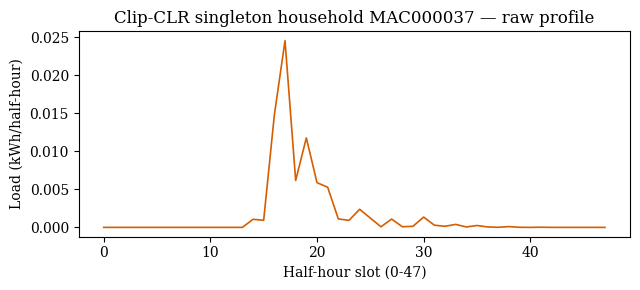


FIX: detection limit dl = 0.65 * 1.218e-04 = 7.917e-05
  rows altered by replacement = 1
  max row-sum deviation from 1 = 6.66e-16

CLR clustering BEFORE (clip 1e-9) vs AFTER (multiplicative replacement):
              sil_before  sil_after  ARIlvl_before  ARIlvl_after  viol_before  viol_after  maxminE_before  maxminE_after          sizes_before           sizes_after      peaks_before       peaks_after
algorithm                                                                                                                                                                                               
K-Means           0.1656     0.1483         0.0009        0.0014       0.6567      0.7231          116.94           1.11    [1, 680, 688, 769]  [313, 603, 649, 573]  [17, 36, 39, 41]  [37, 37, 39, 41]
K-Medoids         0.1277     0.1432         0.0019        0.0010       0.7297      0.7268            1.12           1.12  [488, 508, 664, 478]  [496, 346, 601, 695]  [37, 37, 40, 41]  [37, 36

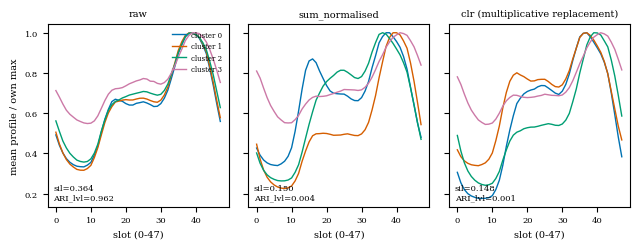

'CLR rows superseded by A3b: the clip log(1e-9) created a singleton outlier cluster; A3b uses multiplicative zero replacement (Martin-Fernandez et al. 2003). Use A3b.after.* for CLR results.'

In [86]:
# ============================================================
# Result A3b — proper zero handling for the CLR transform
# ============================================================
# In A3 the CLR K-Means/Hierarchical/GMM produce a size-1 cluster and a
# max/min mean-daily-kWh ratio of ~117-120, while K-Medoids stays balanced.
# That signature is a single outlier created by the clip log(1e-9) = -20.72 in
# the CLR transform. Here we diagnose it and replace the ad-hoc clip with a
# compositional-data-correct zero treatment.

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')
EPS = 1e-12
try:
    K
except NameError:
    K = 4
N_ONE_PCT = int(np.ceil(0.01 * len(profiles_original_clean)))   # 1% = 21 households

# --- data and shape composition ---------------------------------------------
raw = profiles_original_clean.values.astype(float)              # kWh/half-hour
lclids = np.asarray(profiles_original_clean.index)              # LCLid per row
E = raw.sum(axis=1)                                             # daily kWh
sum_norm = raw / np.clip(raw.sum(axis=1, keepdims=True), EPS, None)   # simplex


# --- helpers (self-contained copies so this cell runs independently) --------
def quantile_partition(e, sizes):
    """Consecutive ascending-E bands of the given sizes; label per household."""
    e = np.asarray(e)
    order_idx = np.argsort(e, kind='stable')
    labels = np.empty(e.shape[0], dtype=int)
    start = 0
    for band, size in enumerate(sizes):
        labels[order_idx[start:start + size]] = band
        start += size
    return labels


def clr_transform(comp, floor=None):
    """Centred log-ratio transform of a composition matrix.

    Parameters
    ----------
    comp : numpy.ndarray, shape (n, d)
        Rows are compositions (non-negative, sum to 1).
    floor : float or None
        If given, clip components up to `floor` before the log (the ad-hoc
        A3 behaviour). If None, the log is taken as-is (assumes no zeros).

    Returns
    -------
    numpy.ndarray, shape (n, d)
        CLR coordinates: log(x_t) - mean_t log(x_t).
    """
    x = np.clip(comp, floor, None) if floor is not None else comp
    log_x = np.log(x)
    return log_x - log_x.mean(axis=1, keepdims=True)


def size_matched_and_violators(labels):
    """Return (size-matched E-band, violator fraction, clusters ordered by mean E)."""
    labels = np.asarray(labels)
    clusters = np.unique(labels)
    order = sorted(clusters, key=lambda c: E[labels == c].mean())
    sizes_asc = [int(np.sum(labels == c)) for c in order]
    band = quantile_partition(E, sizes_asc)
    rank_of_cluster = {c: pos for pos, c in enumerate(order)}
    actual_rank = np.array([rank_of_cluster[c] for c in labels])
    return band, float(np.mean(actual_rank != band)), order


def medoid_total_distance(x, labels, n_clusters):
    """Total within-cluster distance to the best medoid (k-medoids objective)."""
    total = 0.0
    for c in range(n_clusters):
        idx = np.where(labels == c)[0]
        if idx.size == 0:
            continue
        dmat = pairwise_distances(x[idx])
        total += float(dmat.sum(axis=1).min())
    return total


def kmedoids_best(x, n_clusters, n_init=10, base_seed=42):
    """Notebook `kmedoids` with n_init restarts; keep the lowest-cost labelling."""
    best_labels, best_cost = None, np.inf
    for step in range(n_init):
        lab = kmedoids(x, n_clusters, random_state=base_seed + step)
        cost = medoid_total_distance(x, lab, n_clusters)
        if cost < best_cost:
            best_cost, best_labels = cost, lab
    return best_labels


def metrics(labels, x_std):
    """Silhouette, ARI-vs-level, violator fraction, sizes, max/min E, peak slots."""
    band, violator_fraction, order = size_matched_and_violators(labels)
    sizes = [int(np.sum(labels == c)) for c in order]
    cluster_E = np.array([E[labels == c].mean() for c in order])
    peaks = [int(raw[labels == c].mean(axis=0).argmax()) for c in order]
    return {
        'sil': float(silhouette_score(x_std, labels)),
        'ari_level': float(adjusted_rand_score(labels, band)),
        'viol': violator_fraction,
        'sizes': sizes,
        'maxmin': float(cluster_E.max() / cluster_E.min()),
        'peaks': peaks,
    }


def fit_algorithms(x_std):
    """Fit the four algorithms (K=4, seed 42) on a StandardScaler space."""
    return {
        'K-Means': KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(x_std),
        'K-Medoids': kmedoids_best(x_std, K, n_init=10, base_seed=42),
        'Hierarchical': AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(x_std),
        'GMM': GaussianMixture(n_components=K, covariance_type='diag', n_init=5,
                               random_state=42).fit_predict(x_std),
    }


# ============================================================
# 1. DIAGNOSTICS
# ============================================================
n_exact_zeros = int(np.sum(sum_norm == 0))
min_positive = float(sum_norm[sum_norm > 0].min())
pct_01, pct_1, pct_5 = np.percentile(sum_norm, [0.1, 1, 5])
below_counts = {thr: int(np.sum((sum_norm < thr).any(axis=1)))
                for thr in (1e-6, 1e-7, 1e-9)}
print('A3b DIAGNOSTICS on sum_normalised (shape) matrix:')
print(f'  exact zeros                         = {n_exact_zeros}')
print(f'  minimum positive value              = {min_positive:.3e}')
print(f'  percentiles [0.1, 1, 5] of all cells= '
      f'[{pct_01:.3e}, {pct_1:.3e}, {pct_5:.3e}]')
for thr, cnt in below_counts.items():
    print(f'  households with any value < {thr:.0e}   = {cnt}')

# Identify the household in the singleton cluster produced by the clip.
clr_clip = clr_transform(sum_norm, floor=1e-9)
x_std_clip = StandardScaler().fit_transform(clr_clip)
km_clip = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(x_std_clip)
uniq, counts = np.unique(km_clip, return_counts=True)
smallest_cluster = int(uniq[np.argmin(counts)])
smallest_size = int(counts.min())
outlier_rows = np.where(km_clip == smallest_cluster)[0]
# Representative = row with the most extreme (smallest) shape value.
rep_row = int(outlier_rows[np.argmin(sum_norm[outlier_rows].min(axis=1))])
rep_lclid = lclids[rep_row]
rep_below_1e6 = int(np.sum(sum_norm[rep_row] < 1e-6))
print(f'\n  clip-CLR K-Means smallest cluster: id={smallest_cluster}, '
      f'size={smallest_size}, members LCLid={list(lclids[outlier_rows])}')
print(f'  representative outlier LCLid        = {rep_lclid}')
print(f'    raw profile min = {raw[rep_row].min():.4f} kWh, '
      f'max = {raw[rep_row].max():.4f} kWh')
print(f'    half-hours with shape value < 1e-6 = {rep_below_1e6} of 48')

os.makedirs('figures', exist_ok=True)
with plt.rc_context({'font.family': 'serif'}):
    fig_o, ax_o = plt.subplots(figsize=(6.5, 3.0))
    ax_o.plot(np.arange(48), raw[rep_row], color=PALETTE[1], linewidth=1.2)
    ax_o.set_xlabel('Half-hour slot (0-47)')
    ax_o.set_ylabel('Load (kWh/half-hour)')
    ax_o.set_title(f'Clip-CLR singleton household {rep_lclid} — raw profile')
    fig_o.tight_layout()
    fig_o.savefig('figures/A3b_outlier_profile.pdf')
    plt.show()


# ============================================================
# 2. FIX — multiplicative replacement (Martin-Fernandez et al. 2003)
# ============================================================
def multiplicative_replacement(comp, dl):
    """Compositional multiplicative zero/rounding replacement.

    Implements the standard non-parametric treatment of Martin-Fernandez,
    Barcelo-Vidal & Pawlowsky-Glahn (2003): values below the detection limit
    `dl` are set to `dl`, and the remaining (observed) parts are scaled by
    (1 - sum_of_replaced) so each row still sums to 1. This preserves the
    ratios among the observed parts, unlike an additive clip which injects a
    huge negative CLR coordinate. It is standard practice, not a fit tweak.

    Parameters
    ----------
    comp : numpy.ndarray, shape (n, d)
        Composition matrix; each row sums to 1.
    dl : float
        Detection limit (imputed value for sub-threshold parts).

    Returns
    -------
    numpy.ndarray, shape (n, d)
        Zero-replaced composition; every value >= dl and each row sums to ~1.
    """
    out = comp.astype(float).copy()
    for i in range(out.shape[0]):
        row = out[i]
        small = row < dl
        if not small.any():
            continue
        replaced_mass = int(small.sum()) * dl          # total imputed mass
        row[~small] = row[~small] * (1.0 - replaced_mass)
        row[small] = dl
        out[i] = row
    return out


dl = 0.65 * min_positive                                # detection limit
sum_norm_mr = multiplicative_replacement(sum_norm, dl)
print(f'\nFIX: detection limit dl = 0.65 * {min_positive:.3e} = {dl:.3e}')
print(f'  rows altered by replacement = '
      f'{int(np.sum((sum_norm < dl).any(axis=1)))}')
print(f'  max row-sum deviation from 1 = '
      f'{np.abs(sum_norm_mr.sum(axis=1) - 1).max():.2e}')


# ============================================================
# 3. RE-RUN all four algorithms on corrected CLR; BEFORE vs AFTER
# ============================================================
clr_mr = clr_transform(sum_norm_mr)                     # no clip needed now
x_std_mr = StandardScaler().fit_transform(clr_mr)

algos_before = fit_algorithms(x_std_clip)               # clip(1e-9) CLR
algos_after = fit_algorithms(x_std_mr)                  # multiplicative replacement

comp_rows = []
after_store = {}
for algo in ('K-Means', 'K-Medoids', 'Hierarchical', 'GMM'):
    b = metrics(algos_before[algo], x_std_clip)
    a = metrics(algos_after[algo], x_std_mr)
    after_store[algo] = a
    comp_rows.append({
        'algorithm': algo,
        'sil_before': round(b['sil'], 4), 'sil_after': round(a['sil'], 4),
        'ARIlvl_before': round(b['ari_level'], 4), 'ARIlvl_after': round(a['ari_level'], 4),
        'viol_before': round(b['viol'], 4), 'viol_after': round(a['viol'], 4),
        'maxminE_before': round(b['maxmin'], 2), 'maxminE_after': round(a['maxmin'], 2),
        'sizes_before': b['sizes'], 'sizes_after': a['sizes'],
        'peaks_before': b['peaks'], 'peaks_after': a['peaks'],
    })
comp_table = pd.DataFrame(comp_rows).set_index('algorithm')
print('\nCLR clustering BEFORE (clip 1e-9) vs AFTER (multiplicative replacement):')
print(comp_table.to_string())


# ============================================================
# 4. SENSITIVITY CONTROL — three zero treatments
# ============================================================
# (a) multiplicative replacement (main); (b) drop sub-dl households; (c) clip.
labels_a = algos_after['K-Means']                       # full N
labels_c = algos_before['K-Means']                      # full N
removed = (sum_norm < dl).any(axis=1)
kept = ~removed
n_removed = int(removed.sum())
clr_b = clr_transform(sum_norm[kept])                   # all parts >= dl, no clip
x_std_b = StandardScaler().fit_transform(clr_b)
labels_b = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(x_std_b)

ari_ab = float(adjusted_rand_score(labels_a[kept], labels_b))
ari_ac = float(adjusted_rand_score(labels_a, labels_c))
ari_bc = float(adjusted_rand_score(labels_b, labels_c[kept]))
print('\nSENSITIVITY (K-Means partitions, ARI between zero treatments):')
print(f'  households removed by treatment (b) = {n_removed}')
print(f'  ARI( (a) replacement , (b) removal ) = {ari_ab:.4f}')
print(f'  ARI( (a) replacement , (c) clip     ) = {ari_ac:.4f}')
print(f'  ARI( (b) removal     , (c) clip     ) = {ari_bc:.4f}')
robust = ari_ab > 0.9
if robust:
    print('  ARI(a,b) > 0.9 => the conclusion is robust to the zero-handling '
          'method (replacement vs removal agree).')
else:
    print('  ARI(a,b) <= 0.9 => the conclusion is sensitive to zero handling; '
          'do not over-claim.')


# ============================================================
# 5. MINIMUM CLUSTER SIZE CHECK (>= 1% = 21 households)
# ============================================================
print(f'\nMinimum cluster size after fix (must be >= {N_ONE_PCT}):')
min_sizes = {}
for algo, labels in algos_after.items():
    smallest = int(np.min(np.unique(labels, return_counts=True)[1]))
    min_sizes[algo] = smallest
    flag = 'OK' if smallest >= N_ONE_PCT else 'WARNING: below 1% of the sample'
    print(f'  {algo:<13} smallest cluster = {smallest:>4}  [{flag}]')


# ============================================================
# 6. UPDATE FIGURE figures/A3_representations.pdf with corrected CLR panel
# ============================================================
raw_std = StandardScaler().fit_transform(raw)
km_raw = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(raw_std)
sn_std = StandardScaler().fit_transform(sum_norm)
km_sn = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(sn_std)
km_clr = algos_after['K-Means']                          # corrected CLR
panels = [
    ('raw', km_raw, raw_std),
    ('sum_normalised', km_sn, sn_std),
    ('clr (multiplicative replacement)', km_clr, x_std_mr),
]
slots = np.arange(48)
with plt.rc_context({'font.family': 'serif'}):
    fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.6), sharey=True)
    for ax, (name, labels, space) in zip(axes, panels):
        order = sorted(np.unique(labels), key=lambda c: E[labels == c].mean())
        for i, c in enumerate(order):
            mean_profile = raw[labels == c].mean(axis=0)
            ax.plot(slots, mean_profile / mean_profile.max(),
                    color=PALETTE[i % len(PALETTE)], linewidth=1.0,
                    label=f'cluster {i}')
        sil = silhouette_score(space, labels)
        ari_level = metrics(labels, space)['ari_level']
        ax.set_title(name, fontsize=7)
        ax.set_xlabel('slot (0-47)', fontsize=7)
        ax.tick_params(labelsize=6)
        ax.text(0.03, 0.03, f'sil={sil:.3f}\nARI_lvl={ari_level:.3f}',
                transform=ax.transAxes, fontsize=6, va='bottom')
    axes[0].set_ylabel('mean profile / own max', fontsize=7)
    axes[0].legend(fontsize=5, frameon=False, loc='upper right')
    fig.tight_layout()
    fig.savefig('figures/A3_representations.pdf')
    plt.show()


# ============================================================
# 7. PERSIST
# ============================================================
save_result('A3b.diagnostics.exact_zeros', n_exact_zeros)
save_result('A3b.diagnostics.min_positive', min_positive)
save_result('A3b.diagnostics.pct_0p1', float(pct_01))
save_result('A3b.diagnostics.pct_1', float(pct_1))
save_result('A3b.diagnostics.pct_5', float(pct_5))
save_result('A3b.diagnostics.households_below_1e-6', below_counts[1e-6])
save_result('A3b.diagnostics.households_below_1e-7', below_counts[1e-7])
save_result('A3b.diagnostics.households_below_1e-9', below_counts[1e-9])
save_result('A3b.diagnostics.singleton_cluster_size', smallest_size)
save_result('A3b.diagnostics.singleton_members_lclid',
            [int(x) if str(x).isdigit() else str(x) for x in lclids[outlier_rows]])
save_result('A3b.diagnostics.representative_lclid',
            int(rep_lclid) if str(rep_lclid).isdigit() else str(rep_lclid))
save_result('A3b.diagnostics.representative_below_1e-6_slots', rep_below_1e6)
save_result('A3b.fix.detection_limit', float(dl))
save_result('A3b.fix.rows_replaced', int(np.sum((sum_norm < dl).any(axis=1))))
for algo, a in after_store.items():
    base = f'A3b.after.{algo.replace("-", "_")}'
    save_result(f'{base}.silhouette', a['sil'])
    save_result(f'{base}.ARI_vs_level', a['ari_level'])
    save_result(f'{base}.violator_frac', a['viol'])
    save_result(f'{base}.cluster_sizes', a['sizes'])
    save_result(f'{base}.maxmin_E_ratio', a['maxmin'])
    save_result(f'{base}.peak_slots', a['peaks'])
save_result('A3b.sensitivity.n_removed', n_removed)
save_result('A3b.sensitivity.ARI_replacement_vs_removal', ari_ab)
save_result('A3b.sensitivity.ARI_replacement_vs_clip', ari_ac)
save_result('A3b.sensitivity.ARI_removal_vs_clip', ari_bc)
save_result('A3b.sensitivity.robust_to_handling', bool(robust))
save_result('A3b.min_cluster_size_after', min_sizes)
save_result('A3b.min_cluster_size_threshold', N_ONE_PCT)
# Mark the A3 CLR rows as superseded.
save_result('A3.note_clr',
            'CLR rows superseded by A3b: the clip log(1e-9) created a singleton '
            'outlier cluster; A3b uses multiplicative zero replacement '
            '(Martin-Fernandez et al. 2003). Use A3b.after.* for CLR results.')


## Result A3c — is the shape structure real, or is K-Means partitioning noise?

CHECK 1 -- shape family pairwise ARI (8x8):
              SN-KMeans  SN-KMedoids  SN-Ward  SN-GMMdiag  CLR-KMeans  CLR-KMedoids  CLR-Ward  CLR-GMMdiag
SN-KMeans         1.000        0.391    0.297       0.430       0.516         0.506     0.345        0.380
SN-KMedoids       0.391        1.000    0.314       0.393       0.372         0.327     0.300        0.358
SN-Ward           0.297        0.314    1.000       0.288       0.217         0.217     0.298        0.229
SN-GMMdiag        0.430        0.393    0.288       1.000       0.333         0.327     0.330        0.618
CLR-KMeans        0.516        0.372    0.217       0.333       1.000         0.654     0.363        0.455
CLR-KMedoids      0.506        0.327    0.217       0.327       0.654         1.000     0.314        0.376
CLR-Ward          0.345        0.300    0.298       0.330       0.363         0.314     1.000        0.393
CLR-GMMdiag       0.380        0.358    0.229       0.618       0.455         0.376     0.393       

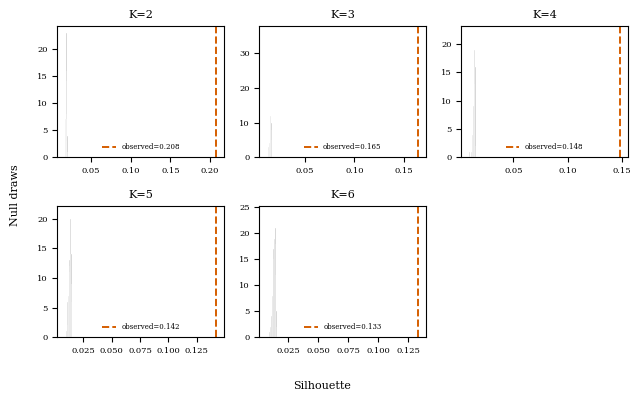


VERDICT:
  shape clusters exceed the null at p=0.0050 with cluster-wise Jaccard 0.54; the structure is real and can be characterised.


'shape clusters exceed the null at p=0.0050 with cluster-wise Jaccard 0.54; the structure is real and can be characterised.'

In [87]:
# ============================================================
# Result A3c — is the shape structure real, or is K-Means partitioning noise?
# ============================================================
# Shape/CLR clustering gives silhouette ~0.11-0.15 and peak slots in a narrow
# 36-41 band. Before interpreting those clusters we test that they exist at all,
# with three independent checks: (1) cross-method/representation agreement,
# (2) Hennig (2007) bootstrap cluster-wise stability, (3) a null model with a
# single shape prototype but no groups.

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')
EPS = 1e-12
try:
    K
except NameError:
    K = 4

# --- data, shape composition, and the A3b (corrected) CLR representation -----
raw = profiles_original_clean.values.astype(float)              # kWh/half-hour
E = raw.sum(axis=1)                                             # daily kWh
sum_norm = raw / np.clip(raw.sum(axis=1, keepdims=True), EPS, None)   # simplex


def clr_transform(comp, floor=None):
    """Centred log-ratio of a composition matrix (optional clip floor)."""
    x = np.clip(comp, floor, None) if floor is not None else comp
    log_x = np.log(x)
    return log_x - log_x.mean(axis=1, keepdims=True)


def multiplicative_replacement(comp, dl):
    """Martin-Fernandez et al. (2003) multiplicative zero replacement.

    Sub-`dl` parts are set to `dl`; observed parts are scaled by
    (1 - imputed_mass) so each row still sums to 1. See A3b for full notes.
    """
    out = comp.astype(float).copy()
    for i in range(out.shape[0]):
        row = out[i]
        small = row < dl
        if not small.any():
            continue
        replaced_mass = int(small.sum()) * dl
        row[~small] = row[~small] * (1.0 - replaced_mass)
        row[small] = dl
        out[i] = row
    return out


def medoid_total_distance(x, labels, n_clusters):
    """Total within-cluster distance to the best medoid (k-medoids objective)."""
    total = 0.0
    for c in range(n_clusters):
        idx = np.where(labels == c)[0]
        if idx.size == 0:
            continue
        dmat = pairwise_distances(x[idx])
        total += float(dmat.sum(axis=1).min())
    return total


def kmedoids_best(x, n_clusters, n_init=10, base_seed=42):
    """Notebook `kmedoids` with n_init restarts; keep the lowest-cost labelling."""
    best_labels, best_cost = None, np.inf
    for step in range(n_init):
        lab = kmedoids(x, n_clusters, random_state=base_seed + step)
        cost = medoid_total_distance(x, lab, n_clusters)
        if cost < best_cost:
            best_cost, best_labels = cost, lab
    return best_labels


def fit_algorithms(x_std):
    """Fit the four algorithms (K=4, seed 42) on a StandardScaler space."""
    return {
        'KMeans': KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(x_std),
        'KMedoids': kmedoids_best(x_std, K, n_init=10, base_seed=42),
        'Ward': AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(x_std),
        'GMMdiag': GaussianMixture(n_components=K, covariance_type='diag',
                                   n_init=5, random_state=42).fit_predict(x_std),
    }


dl = 0.65 * float(sum_norm[sum_norm > 0].min())                # A3b detection limit
sum_norm_mr = multiplicative_replacement(sum_norm, dl)
clr_mr = clr_transform(sum_norm_mr)                            # corrected CLR (A3b)
x_std_raw = StandardScaler().fit_transform(raw)
x_std_sn = StandardScaler().fit_transform(sum_norm)
x_std_clr = StandardScaler().fit_transform(clr_mr)


# ============================================================
# CHECK 1 — agreement across representations and algorithms
# ============================================================
def ari_matrix(partitions):
    """Pairwise adjusted Rand index matrix (DataFrame) for a dict of labellings."""
    names = list(partitions)
    mat = np.eye(len(names))
    for i, a in enumerate(names):
        for j, b in enumerate(names):
            if i < j:
                v = adjusted_rand_score(partitions[a], partitions[b])
                mat[i, j] = mat[j, i] = v
    return pd.DataFrame(mat, index=names, columns=names)


def mean_offdiag(df):
    """Mean of the off-diagonal entries of a square DataFrame."""
    m = df.values
    off = m[~np.eye(m.shape[0], dtype=bool)]
    return float(off.mean())


raw_algos = fit_algorithms(x_std_raw)
sn_algos = fit_algorithms(x_std_sn)
clr_algos = fit_algorithms(x_std_clr)

shape_partitions = {}
for a, lab in sn_algos.items():
    shape_partitions[f'SN-{a}'] = lab
for a, lab in clr_algos.items():
    shape_partitions[f'CLR-{a}'] = lab
raw_partitions = {f'raw-{a}': lab for a, lab in raw_algos.items()}

shape_ari = ari_matrix(shape_partitions)
raw_ari = ari_matrix(raw_partitions)
print('CHECK 1 -- shape family pairwise ARI (8x8):')
print(shape_ari.round(3).to_string())
print('\nCHECK 1 -- raw family pairwise ARI (4x4):')
print(raw_ari.round(3).to_string())
shape_mean, raw_mean = mean_offdiag(shape_ari), mean_offdiag(raw_ari)
print(f'\n  mean off-diagonal ARI: raw = {raw_mean:.3f}, shape = {shape_mean:.3f}')
if raw_mean > 0.6 and shape_mean < 0.5:
    print('  => raw partition is method-agnostic but the shape partition is '
          'unstable to method choice; individual shape clusters cannot be '
          'interpreted on agreement grounds alone.')
else:
    print('  => see numbers above; interpret agreement relative to the raw '
          'family baseline.')


# ============================================================
# CHECK 2 — Hennig (2007) bootstrap cluster-wise stability
# ============================================================
# TODO (dissertation text): this cluster-wise maximum-Jaccard bootstrap is
# Hennig (2007), "Cluster-wise assessment of cluster stability", CSDA
# 52(1):258-271 -- NOT Fang & Wang / a generic Jaccard reference. Fix the
# citation in the write-up.
# Hennig thresholds: J < 0.60 cluster not stable; 0.60-0.75 pattern present but
# boundaries blurred; > 0.85 stable (highly supported) cluster.
def bootstrap_stability(data_pre_scale, n_boot=100, seed=42):
    """Cluster-wise bootstrap Jaccard stability (Hennig 2007) for K-Means.

    The full pipeline (StandardScaler -> KMeans K=4) is refit on each bootstrap
    resample; for every reference cluster we take the maximum Jaccard over the
    bootstrap clusters (mapped back to original household ids) and average.

    Parameters
    ----------
    data_pre_scale : numpy.ndarray, shape (n, d)
        Feature matrix BEFORE standardisation (CLR or raw).
    n_boot : int
        Number of bootstrap resamples.
    seed : int
        RNG seed.

    Returns
    -------
    dict
        {cluster_id: {'mean_jaccard', 'std_jaccard', 'frac_boot_gt_0.5'}}.
    """
    scaler = StandardScaler()
    x_std = scaler.fit_transform(data_pre_scale)
    ref = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(x_std)
    ref_sets = {c: set(np.where(ref == c)[0]) for c in range(K)}
    rng = np.random.default_rng(seed)
    n = data_pre_scale.shape[0]
    jacc = {c: [] for c in range(K)}
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        xb = StandardScaler().fit_transform(data_pre_scale[idx])
        boot = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(xb)
        boot_sets = [set(idx[boot == j]) for j in range(K)]
        for c in range(K):
            rc = ref_sets[c]
            best = 0.0
            for bs in boot_sets:
                union = len(rc | bs)
                if union:
                    best = max(best, len(rc & bs) / union)
            jacc[c].append(best)
    summary = {}
    for c in range(K):
        arr = np.array(jacc[c])
        summary[c] = {
            'mean_jaccard': float(arr.mean()),
            'std_jaccard': float(arr.std()),
            'frac_boot_gt_0.5': float(np.mean(arr > 0.5)),
        }
    return summary


stab_clr = bootstrap_stability(clr_mr, n_boot=100, seed=42)
stab_raw = bootstrap_stability(raw, n_boot=100, seed=42)
print('\nCHECK 2 -- Hennig bootstrap stability (100 resamples).')
print('  thresholds: <0.60 unstable | 0.60-0.75 blurred | >0.85 stable')
for tag, summ in (('CLR (A3b)', stab_clr), ('raw', stab_raw)):
    rows = [{'cluster': c, **v} for c, v in summ.items()]
    df = pd.DataFrame(rows).set_index('cluster')
    print(f'\n  {tag} K-Means:')
    print(df.round(3).to_string())


# ============================================================
# CHECK 3 — null model with a single shape prototype (most important)
# ============================================================
def make_null(seed):
    """Null shape population: one prototype, per-slot marginals preserved, no groups.

    For each household i and slot t: s_null_i(t) = s_bar(t) * (1 + e_i(t)) where
    s_bar is the mean shape and e_i(t) = s_i(t)/s_bar(t) - 1 are multiplicative
    residuals permuted INDEPENDENTLY across households within each slot. Rows are
    renormalised to sum 1. This keeps the mean shape and each slot's marginal
    distribution while destroying all cross-slot (i.e. group) structure.
    """
    rng = np.random.default_rng(seed)
    s_bar = sum_norm.mean(axis=0)
    e = sum_norm / s_bar - 1.0
    e_perm = np.empty_like(e)
    for t in range(e.shape[1]):
        e_perm[:, t] = e[rng.permutation(e.shape[0]), t]
    s_null = np.clip(s_bar * (1.0 + e_perm), 0.0, None)
    return s_null / np.clip(s_null.sum(axis=1, keepdims=True), EPS, None)


N_NULL = 200
# Build the null CLR-standardised matrices once and reuse across K (heavy step:
# lower N_NULL if runtime is a concern). Seeds 42 .. 42+N_NULL-1.
null_x_std = []
for b in range(N_NULL):
    s_null = make_null(42 + b)
    null_x_std.append(StandardScaler().fit_transform(
        clr_transform(multiplicative_replacement(s_null, dl))))

null_rows = []
null_dist_by_k = {}
for k in range(2, 7):
    obs_labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(x_std_clr)
    obs_sil = float(silhouette_score(x_std_clr, obs_labels))
    null_sils = np.array([
        silhouette_score(xn, KMeans(n_clusters=k, n_init=10,
                                    random_state=42).fit_predict(xn))
        for xn in null_x_std])
    null_dist_by_k[k] = (obs_sil, null_sils)
    mean_n, std_n = float(null_sils.mean()), float(null_sils.std())
    p95 = float(np.percentile(null_sils, 95))
    p_emp = float((np.sum(null_sils >= obs_sil) + 1) / (N_NULL + 1))
    z = float((obs_sil - mean_n) / std_n) if std_n > 0 else np.nan
    null_rows.append({'K': k, 'observed_sil': round(obs_sil, 4),
                      'null_mean': round(mean_n, 4), 'null_std': round(std_n, 4),
                      'null_p95': round(p95, 4), 'p_empirical': round(p_emp, 4),
                      'z': round(z, 2)})
null_table = pd.DataFrame(null_rows).set_index('K')
print('\nCHECK 3 -- observed vs single-prototype null silhouette (200 draws):')
print(null_table.to_string())

# Headline comparison at K=4 (dissertation K).
obs4, null4 = null_dist_by_k[K]
p4 = float((np.sum(null4 >= obs4) + 1) / (N_NULL + 1))
z4 = float((obs4 - null4.mean()) / null4.std()) if null4.std() > 0 else np.nan
print(f'\n  At K={K}: observed silhouette = {obs4:.4f} (dissertation value ~0.148); '
      f'null mean = {null4.mean():.4f}, p = {p4:.4f}, z = {z4:.2f}')

# --- Figure: null silhouette histogram per K, observed marked ---------------
os.makedirs('figures', exist_ok=True)
with plt.rc_context({'font.family': 'serif'}):
    fig, axes = plt.subplots(2, 3, figsize=(6.5, 4.0))
    axflat = axes.ravel()
    for ax, k in zip(axflat, range(2, 7)):
        obs_sil, null_sils = null_dist_by_k[k]
        ax.hist(null_sils, bins=25, color='#BBBBBB', edgecolor='white',
                linewidth=0.3)
        ax.axvline(obs_sil, color=PALETTE[1], linestyle='--', linewidth=1.4,
                   label=f'observed={obs_sil:.3f}')
        ax.set_title(f'K={k}', fontsize=8)
        ax.tick_params(labelsize=6)
        ax.legend(fontsize=5, frameon=False)
    axflat[-1].axis('off')
    fig.supxlabel('Silhouette', fontsize=8)
    fig.supylabel('Null draws', fontsize=8)
    fig.tight_layout()
    fig.savefig('figures/A3c_null_model.pdf')
    plt.show()


# ============================================================
# VERDICT — chosen by the numbers, no softening
# ============================================================
clr_mean_jaccard = float(np.mean([v['mean_jaccard'] for v in stab_clr.values()]))
null_exceeded = obs4 > np.percentile(null4, 95)            # observed above null 95th pct
jaccard_real = clr_mean_jaccard >= 0.60                    # Hennig lower bound (characterisability)
# Existence is decided by the null test alone: if the observed silhouette
# exceeds the null, the partition is distinguishable from the null. The
# Jaccard concerns whether clusters can be characterised, not whether they
# exist, so it must NOT gate the existence verdict (the previous
# `and jaccard_real` inverted the call at p=0.005).
verdict_real = null_exceeded
if verdict_real:
    verdict = (f'shape clusters exceed the null at p={p4:.4f} with cluster-wise '
               f'Jaccard {clr_mean_jaccard:.2f}; the structure is real and can '
               f'be characterised.')
else:
    verdict = (f'shape clusters are not distinguishable from a null population '
               f'with a single shape prototype (p={p4:.4f}); the four shape '
               f'groups are a partition of a unimodal cloud, not discovered '
               f'structure.')
print('\nVERDICT:')
print(' ', verdict)


# ============================================================
# PERSIST
# ============================================================
save_result('A3c.agreement.shape_ari_matrix',
            {'labels': list(shape_partitions), 'matrix': shape_ari.values.tolist()})
save_result('A3c.agreement.raw_ari_matrix',
            {'labels': list(raw_partitions), 'matrix': raw_ari.values.tolist()})
save_result('A3c.agreement.shape_mean_offdiag_ari', shape_mean)
save_result('A3c.agreement.raw_mean_offdiag_ari', raw_mean)
for tag, summ in (('clr', stab_clr), ('raw', stab_raw)):
    for c, v in summ.items():
        base = f'A3c.stability.{tag}.cluster{c}'
        save_result(f'{base}.mean_jaccard', v['mean_jaccard'])
        save_result(f'{base}.std_jaccard', v['std_jaccard'])
        save_result(f'{base}.frac_boot_gt_0p5', v['frac_boot_gt_0.5'])
for row in null_rows:
    base = f'A3c.null.K{int(row["K"])}'
    save_result(f'{base}.observed_sil', float(row['observed_sil']))
    save_result(f'{base}.null_mean', float(row['null_mean']))
    save_result(f'{base}.null_std', float(row['null_std']))
    save_result(f'{base}.null_p95', float(row['null_p95']))
    save_result(f'{base}.p_empirical', float(row['p_empirical']))
    save_result(f'{base}.z', float(row['z']))
save_result('A3c.null.n_draws', N_NULL)
save_result('A3c.verdict.clr_mean_jaccard', clr_mean_jaccard)
save_result('A3c.verdict.null_exceeded_at_K', bool(null_exceeded))
save_result('A3c.verdict.p_at_K', p4)
save_result('A3c.verdict.z_at_K', z4)
save_result('A3c.verdict.structure_real', bool(verdict_real))
save_result('A3c.verdict.text', verdict)


**Correction — the Jaccard above is capped at 0.632 by construction.** A with-replacement resample of size $n$ from $n$ items keeps only $1-1/e\approx63.2\%$ distinct ids; comparing that resampled subset's cluster membership (as a set of original ids) against the full-$n$ reference cluster caps Jaccard at $\approx0.632$ even under perfect recovery, making the Hennig (0.60/0.75/0.85) thresholds inapplicable to the values above. Fix (Hennig 2007 / `fpc::clusterboot`): fit the bootstrap KMeans, then classify **all** $n$ original observations by nearest bootstrap centroid (same standardised space) before computing Jaccard, so both sets are subsets of the full $n$.

In [88]:
# ============================================================
# A3c correction — bootstrap Jaccard was capped at 0.632 by construction
# ============================================================
# BUG in bootstrap_stability above: a bootstrap resample idx = rng.integers(0,
# n, n) retains only ~63.2% distinct original ids (1 - 1/e, the classical
# with-replacement bootstrap coverage). boot_sets were built as
# set(idx[boot==j]) -- a subset of those ~63.2% distinct ids -- and compared
# via Jaccard against ref_sets, which are full-n reference clusters. Even with
# PERFECT recovery, |boot_set| <= 0.632*n while |ref_set| can be up to n, so
# Jaccard = |intersection|/|union| cannot exceed ~0.632. Hennig's thresholds
# (0.60 / 0.75 / 0.85) assume Jaccard computed on the FULL sample and do not
# apply to a metric with a 0.632 ceiling.
#
# FIX (Hennig 2007 / fpc::clusterboot): after fitting KMeans on the bootstrap
# resample, classify ALL n original observations (not just the resampled
# ones) into the bootstrap clusters by nearest centroid, in the SAME
# (bootstrap-fitted) standardised space. Both the reference and bootstrap
# Jaccard sets are then subsets of the full n, and the 0.632 ceiling no longer
# applies.
#
# Requires the A3c cell above to have run: reuses raw, clr_mr, K, stab_clr,
# stab_raw (the old, capped results) for the side-by-side comparison.

import json
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

try:
    RESULTS
except NameError:
    RESULTS = {}


def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value


BOOTSTRAP_CEILING = 1.0 - 1.0 / np.e            # ~0.6321, asymptotic distinct-id fraction


def bootstrap_stability_corrected(data_pre_scale, n_boot=100, seed=42):
    """Cluster-wise bootstrap Jaccard stability, corrected per Hennig (2007) /
    fpc::clusterboot.

    Unlike the naive version above, ALL n original observations are classified
    into each bootstrap's clusters by nearest centroid (in the space the
    bootstrap StandardScaler + KMeans were fitted on), so both the reference
    and bootstrap Jaccard sets are subsets of the full n -- not capped by the
    ~63.2% distinct-element ceiling of with-replacement resampling.

    Parameters
    ----------
    data_pre_scale : numpy.ndarray, shape (n, d)
        Feature matrix BEFORE standardisation (CLR or raw).
    n_boot : int
        Number of bootstrap resamples.
    seed : int
        RNG seed.

    Returns
    -------
    dict
        {cluster_id: {'mean_jaccard', 'std_jaccard', 'frac_boot_gt_0.5'}}.
    """
    scaler = StandardScaler()
    x_std = scaler.fit_transform(data_pre_scale)
    ref = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(x_std)
    ref_sets = {c: set(np.where(ref == c)[0]) for c in range(K)}
    rng = np.random.default_rng(seed)
    n = data_pre_scale.shape[0]
    jacc = {c: [] for c in range(K)}
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)                          # with-replacement resample
        boot_scaler = StandardScaler().fit(data_pre_scale[idx])
        xb = boot_scaler.transform(data_pre_scale[idx])
        km_boot = KMeans(n_clusters=K, n_init=10, random_state=42).fit(xb)
        # classify ALL n original observations by nearest bootstrap centroid,
        # in the bootstrap-fitted standardised space -- this is the fix.
        x_full_in_boot_space = boot_scaler.transform(data_pre_scale)
        boot_labels_full = km_boot.predict(x_full_in_boot_space)
        boot_sets = [set(np.where(boot_labels_full == cb)[0]) for cb in range(K)]
        for c in range(K):
            rc = ref_sets[c]
            best = 0.0
            for bs in boot_sets:
                union = len(rc | bs)
                if union:
                    best = max(best, len(rc & bs) / union)
            jacc[c].append(best)
    summary = {}
    for c in range(K):
        arr = np.array(jacc[c])
        summary[c] = {
            'mean_jaccard': float(arr.mean()),
            'std_jaccard': float(arr.std()),
            'frac_boot_gt_0.5': float(np.mean(arr > 0.5)),
        }
    return summary


print('A3c correction -- Hennig (2007) / fpc::clusterboot bootstrap Jaccard')
print(f'(100 resamples, seed 42; theoretical ceiling of the OLD method = '
      f'{BOOTSTRAP_CEILING:.4f})')

stab_clr_corrected = bootstrap_stability_corrected(clr_mr, n_boot=100, seed=42)
stab_raw_corrected = bootstrap_stability_corrected(raw, n_boot=100, seed=42)

# --- side-by-side comparison: old (capped) vs corrected ---------------------
comparison_rows = []
for tag, old_summ, new_summ in (('CLR', stab_clr, stab_clr_corrected),
                                ('raw', stab_raw, stab_raw_corrected)):
    for c in range(K):
        old_j = old_summ[c]['mean_jaccard']
        new_j = new_summ[c]['mean_jaccard']
        comparison_rows.append({
            'representation': tag, 'cluster': f'C{c}',
            'old_mean_J': round(old_j, 4), 'new_mean_J': round(new_j, 4),
            'old_frac_J>0.5': round(old_summ[c]['frac_boot_gt_0.5'], 3),
            'new_frac_J>0.5': round(new_summ[c]['frac_boot_gt_0.5'], 3),
            'old_/_ceiling_0.632': round(old_j / BOOTSTRAP_CEILING, 4),
        })
comp_table = pd.DataFrame(comparison_rows).set_index(['representation', 'cluster'])
print('\nOld (capped) vs corrected cluster-wise Jaccard:')
print(comp_table.to_string())
print('\n"old_/_ceiling_0.632" shows the old value as a fraction of the '
      'theoretical maximum it could ever reach -- most old values sit close '
      'to 1.0 of that ceiling, i.e. they were near-saturated by the bug, not '
      'by genuine (in)stability.')

# --- Hennig classification applied to the CORRECTED values only -------------
def hennig_class(j):
    """Hennig (2007) stability label for a full-sample cluster-wise Jaccard."""
    if j < 0.60:
        return 'not stable'
    if j < 0.75:
        return 'pattern present, boundaries blurred'
    if j < 0.85:
        return 'moderately stable'
    return 'stable'


print('\nHennig classification of the CORRECTED Jaccard (thresholds only valid here):')
for tag, new_summ in (('CLR', stab_clr_corrected), ('raw', stab_raw_corrected)):
    for c in range(K):
        j = new_summ[c]['mean_jaccard']
        print(f'  {tag} C{c}: J={j:.3f} -> {hennig_class(j)}')

# --- ceiling check: 500 bootstraps, mean fraction of distinct elements ------
def distinct_fraction_check(n, n_boot=500, seed=42):
    """Empirical mean fraction of distinct ids in an n-out-of-n with-
    replacement bootstrap resample, for n_boot independent resamples.
    """
    rng = np.random.default_rng(seed)
    fracs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        fracs[i] = len(np.unique(idx)) / n
    return fracs


n_hh = raw.shape[0]
distinct_fracs = distinct_fraction_check(n_hh, n_boot=500, seed=42)
print(f'\nCeiling check (500 bootstraps, n={n_hh}): mean distinct-id fraction = '
      f'{distinct_fracs.mean():.4f} (theoretical 1 - 1/e = {BOOTSTRAP_CEILING:.4f}) '
      f'-- confirms the 0.632 ceiling.')

# --- persist ------------------------------------------------------------
save_result('A3c.stability_corrected.method',
            'Hennig (2007) / fpc::clusterboot: bootstrap KMeans centroids '
            'classify ALL n original observations by nearest centroid; both '
            'Jaccard sets are subsets of the full n, unlike the old '
            'resampled-subset comparison capped at ~0.632.')
save_result('A3c.stability_corrected.bootstrap_ceiling_old', float(BOOTSTRAP_CEILING))
for tag, summ in (('clr', stab_clr_corrected), ('raw', stab_raw_corrected)):
    for c, v in summ.items():
        base = f'A3c.stability_corrected.{tag}.cluster{c}'
        save_result(f'{base}.mean_jaccard', v['mean_jaccard'])
        save_result(f'{base}.std_jaccard', v['std_jaccard'])
        save_result(f'{base}.frac_boot_gt_0p5', v['frac_boot_gt_0.5'])
        save_result(f'{base}.hennig_class', hennig_class(v['mean_jaccard']))
save_result('A3c.stability_corrected.clr_mean_jaccard',
            float(np.mean([v['mean_jaccard'] for v in stab_clr_corrected.values()])))
save_result('A3c.stability_corrected.raw_mean_jaccard',
            float(np.mean([v['mean_jaccard'] for v in stab_raw_corrected.values()])))
for r in comparison_rows:
    base = (f'A3c.stability_corrected.comparison.{r["representation"]}.{r["cluster"]}')
    save_result(f'{base}.old_mean_J', float(r['old_mean_J']))
    save_result(f'{base}.new_mean_J', float(r['new_mean_J']))
    save_result(f'{base}.old_frac_J_gt_0p5', float(r['old_frac_J>0.5']))
    save_result(f'{base}.new_frac_J_gt_0p5', float(r['new_frac_J>0.5']))
    save_result(f'{base}.old_fraction_of_ceiling', float(r['old_/_ceiling_0.632']))
save_result('A3c.stability_corrected.ceiling_check.n', int(n_hh))
save_result('A3c.stability_corrected.ceiling_check.n_boot', 500)
save_result('A3c.stability_corrected.ceiling_check.mean_distinct_fraction',
            float(distinct_fracs.mean()))
save_result('A3c.stability_corrected.ceiling_check.theoretical', float(BOOTSTRAP_CEILING))


A3c correction -- Hennig (2007) / fpc::clusterboot bootstrap Jaccard
(100 resamples, seed 42; theoretical ceiling of the OLD method = 0.6321)

Old (capped) vs corrected cluster-wise Jaccard:
                        old_mean_J  new_mean_J  old_frac_J>0.5  new_frac_J>0.5  old_/_ceiling_0.632
representation cluster                                                                             
CLR            C0           0.5111      0.7704            0.68            0.83               0.8086
               C1           0.5609      0.8646            0.91            1.00               0.8873
               C2           0.5132      0.7857            0.71            0.83               0.8119
               C3           0.5638      0.8675            0.83            1.00               0.8919
raw            C0           0.5700      0.8880            0.84            1.00               0.9017
               C1           0.6082      0.9552            1.00            1.00               0.9622
         

0.6321205588285577

## Result A3d — correct null models for cluster existence

In [89]:
# ============================================================
# Result A3d — correct null models for cluster existence
# ============================================================
# The A3c null permutes residuals independently per slot, which destroys the
# temporal autocorrelation of load curves. That null produces jagged profiles,
# so ANY smooth data beats it (hence the A3c p=0.005 is not evidence of groups).
# Here we use covariance-preserving nulls in the corrected CLR space (A3b),
# after StandardScaler. X denotes that 2138 x 48 matrix.

import os
import json
import subprocess
import sys
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf
from sklearn.metrics import silhouette_score, pairwise_distances

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

EPS = 1e-12


def clr_transform(comp, floor=None):
    """Centred log-ratio of a composition matrix (optional clip floor)."""
    x = np.clip(comp, floor, None) if floor is not None else comp
    log_x = np.log(x)
    return log_x - log_x.mean(axis=1, keepdims=True)


def multiplicative_replacement(comp, dl):
    """Martin-Fernandez et al. (2003) multiplicative zero replacement (see A3b)."""
    out = comp.astype(float).copy()
    for i in range(out.shape[0]):
        row = out[i]
        small = row < dl
        if not small.any():
            continue
        replaced_mass = int(small.sum()) * dl
        row[~small] = row[~small] * (1.0 - replaced_mass)
        row[small] = dl
        out[i] = row
    return out


def holm(pvals):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(pvals, dtype=float)
    m = p.size
    order = np.argsort(p)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adj[idx] = min(running, 1.0)
    return adj


# --- representations: corrected CLR (A3b) and raw, both StandardScaler-ed ----
raw = profiles_original_clean.values.astype(float)
sum_norm = raw / np.clip(raw.sum(axis=1, keepdims=True), EPS, None)
dl = 0.65 * float(sum_norm[sum_norm > 0].min())
clr_mr = clr_transform(multiplicative_replacement(sum_norm, dl))
X = StandardScaler().fit_transform(clr_mr)          # CLR space (2138 x 48)
X_raw = StandardScaler().fit_transform(raw)
reps = {'CLR': X, 'raw': X_raw}

# Observed K=4 silhouette per representation.
obs_sil = {}
for name, mat in reps.items():
    lab = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(mat)
    obs_sil[name] = float(silhouette_score(mat, lab))
print(f'Observed K=4 silhouette: CLR = {obs_sil["CLR"]:.4f} (~0.1483 expected), '
      f'raw = {obs_sil["raw"]:.4f}')


# ============================================================
# NULL A — elliptical Gaussian (Ledoit-Wolf shrinkage covariance)
# ============================================================
def null_A_gaussian(mat, obs, n_null=200, seed=42):
    """Silhouette null from a unimodal Gaussian with X's shrunk covariance.

    LedoitWolf shrinkage is used because there are 48 dimensions and 2138 points.
    The population is unimodal by construction with the same covariance, so
    beating it is evidence of NON-Gaussian (potentially clustered) structure.
    """
    lw = LedoitWolf().fit(mat)
    mu, sigma = lw.location_, lw.covariance_
    rng = np.random.default_rng(seed)
    sils = np.empty(n_null)
    for b in range(n_null):
        z = rng.multivariate_normal(mu, sigma, size=mat.shape[0])
        lab = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(z)
        sils[b] = silhouette_score(z, lab)
    p = float((np.sum(sils >= obs) + 1) / (n_null + 1))
    return sils, p


nullA = {}
print('\nNULL A -- elliptical Gaussian (Ledoit-Wolf), 200 draws:')
for name, mat in reps.items():
    sils, p = null_A_gaussian(mat, obs_sil[name], n_null=200, seed=42)
    nullA[name] = {'p': p, 'mean': float(sils.mean()), 'std': float(sils.std()),
                   'p95': float(np.percentile(sils, 95))}
    print(f'  {name}: null mean={sils.mean():.4f} std={sils.std():.4f} '
          f'p95={np.percentile(sils, 95):.4f} | observed={obs_sil[name]:.4f} '
          f'| p={p:.4f}')


# ============================================================
# NULL B — gap statistic, PCA-aligned box (Tibshirani et al. 2001, variant b)
# ============================================================
def gap_statistic(mat, k_values=range(1, 9), n_ref=50, seed=42):
    """Gap statistic with a reference box aligned to X's principal components.

    Reference points are drawn uniformly over the bounding box of the data
    AFTER rotation onto its principal axes (variant (b) of Tibshirani, Walther &
    Hastie 2001), then rotated back. Returns a table and the chosen K by the
    standard rule: smallest K with Gap(K) >= Gap(K+1) - s_{K+1}.
    """
    k_values = list(k_values)
    log_w = np.array([
        np.log(KMeans(n_clusters=k, n_init=10, random_state=42).fit(mat).inertia_)
        for k in k_values])
    centre = mat.mean(axis=0)
    centred = mat - centre
    _, _, vt = np.linalg.svd(centred, full_matrices=False)
    principal = centred @ vt.T                       # rotate onto principal axes
    lo, hi = principal.min(axis=0), principal.max(axis=0)
    rng = np.random.default_rng(seed)
    ref_log_w = np.empty((n_ref, len(k_values)))
    for b in range(n_ref):
        z_principal = rng.uniform(lo, hi, size=principal.shape)
        z = z_principal @ vt + centre                # rotate back to CLR/raw space
        for j, k in enumerate(k_values):
            ref_log_w[b, j] = np.log(
                KMeans(n_clusters=k, n_init=10, random_state=42).fit(z).inertia_)
    exp_log_w = ref_log_w.mean(axis=0)
    s_k = ref_log_w.std(axis=0) * np.sqrt(1.0 + 1.0 / n_ref)
    gap = exp_log_w - log_w
    chosen = k_values[-1]
    for j in range(len(k_values) - 1):
        if gap[j] >= gap[j + 1] - s_k[j + 1]:
            chosen = k_values[j]
            break
    table = pd.DataFrame({'K': k_values, 'logW': log_w.round(4),
                          'E*logW': exp_log_w.round(4), 'Gap': gap.round(4),
                          's_k': s_k.round(4)}).set_index('K')
    return table, int(chosen)


gap = {}
print('\nNULL B -- gap statistic (PCA-aligned box, 50 references):')
for name, mat in reps.items():
    table, chosen = gap_statistic(mat, range(1, 9), n_ref=50, seed=42)
    gap[name] = {'table': table, 'optimal_K': chosen}
    print(f'\n  {name} representation (gap-optimal K = {chosen}):')
    print(table.to_string())


# ============================================================
# NULL C — Hartigan dip test for multimodality in projections
# ============================================================
try:
    from diptest import diptest
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'diptest'])
    from diptest import diptest


def dip_projections(mat):
    """Dip test on 5 PCs + the max-separation centroid axis; Holm over 6 tests.

    The centroid axis joins the two farthest K-Means(4) centroids -- the
    direction most favourable to detecting bimodality, so unimodality there is
    strong evidence against multimodal structure.
    """
    pcs = PCA(n_components=5, random_state=42).fit_transform(mat)
    centres = KMeans(n_clusters=4, n_init=10, random_state=42).fit(mat).cluster_centers_
    d = pairwise_distances(centres)
    a, b = np.unravel_index(np.argmax(d), d.shape)
    axis = centres[a] - centres[b]
    axis = axis / np.linalg.norm(axis)
    projections = {f'PC{i + 1}': pcs[:, i] for i in range(5)}
    projections['centroid_axis'] = mat @ axis
    names = list(projections)
    stats, raw_p = [], []
    for nm in names:
        dip_stat, p_val = diptest(np.asarray(projections[nm], dtype=float))
        stats.append(float(dip_stat))
        raw_p.append(float(p_val))
    adj_p = holm(raw_p)
    table = pd.DataFrame({'projection': names, 'dip': np.round(stats, 4),
                          'p_raw': np.round(raw_p, 4),
                          'p_holm': np.round(adj_p, 4)}).set_index('projection')
    best_idx = int(np.argmin(adj_p))
    return table, names[best_idx], float(adj_p[best_idx])


dip = {}
print('\nNULL C -- Hartigan dip test (Holm over 6 projections):')
for name, mat in reps.items():
    table, best_proj, best_p = dip_projections(mat)
    dip[name] = {'table': table, 'best_projection': best_proj, 'best_p_holm': best_p}
    print(f'\n  {name} representation (best direction: {best_proj}, '
          f'Holm p = {best_p:.4f}):')
    print(table.to_string())


# ============================================================
# SUMMARY — representation x test, with a per-cell conclusion
# ============================================================
summary_rows = []
present = {}
for name in reps:
    gap_k = gap[name]['optimal_K']
    dip_p = dip[name]['best_p_holm']
    na_p = nullA[name]['p']
    # A representation shows cluster structure if the gap statistic picks K>1 OR
    # the dip test rejects unimodality on the most favourable direction.
    has_structure = (gap_k > 1) or (dip_p < 0.05)
    present[name] = has_structure
    summary_rows.append({
        'representation': name,
        'nullA_gaussian_p': round(na_p, 4),
        'gap_optimal_K': gap_k,
        'dip_p_best_direction': round(dip_p, 4),
        'conclusion': 'clusters' if has_structure else 'no clusters (unimodal)',
    })
summary = pd.DataFrame(summary_rows).set_index('representation')
print('\nSUMMARY (representation x test):')
print(summary.to_string())

# --- final verdict, chosen by the numbers -----------------------------------
clr_present, raw_present = present['CLR'], present['raw']
gap1_both = gap['CLR']['optimal_K'] == 1 and gap['raw']['optimal_K'] == 1
dip_unimodal_both = dip['CLR']['best_p_holm'] >= 0.05 and dip['raw']['best_p_holm'] >= 0.05
if clr_present and raw_present:
    verdict = ('cluster structure is present in BOTH representations '
               f'(gap-optimal K: CLR={gap["CLR"]["optimal_K"]}, '
               f'raw={gap["raw"]["optimal_K"]}; dip best-direction Holm p: '
               f'CLR={dip["CLR"]["best_p_holm"]:.4f}, '
               f'raw={dip["raw"]["best_p_holm"]:.4f}).')
elif clr_present != raw_present:
    only = 'CLR' if clr_present else 'raw'
    verdict = (f'cluster structure is present ONLY in the {only} representation '
               f'(gap-optimal K: CLR={gap["CLR"]["optimal_K"]}, '
               f'raw={gap["raw"]["optimal_K"]}; dip best-direction Holm p: '
               f'CLR={dip["CLR"]["best_p_holm"]:.4f}, '
               f'raw={dip["raw"]["best_p_holm"]:.4f}).')
elif gap1_both and dip_unimodal_both:
    verdict = ('the gap statistic selects K=1 and the dip test does not reject '
               'unimodality in either representation: there are NO clusters by '
               'level or by shape. Both the level "segmentation" and the shape '
               'grouping are cuts through a continuous unimodal distribution.')
else:
    verdict = ('no representation shows cluster structure by the gap/dip tests; '
               'the partitions are cuts through a continuous unimodal cloud '
               f'(gap-optimal K: CLR={gap["CLR"]["optimal_K"]}, '
               f'raw={gap["raw"]["optimal_K"]}).')
print('\nVERDICT:')
print(' ', verdict)


# ============================================================
# PERSIST
# ============================================================
for name in reps:
    save_result(f'A3d.observed_silhouette.{name}', obs_sil[name])
    save_result(f'A3d.nullA.{name}.p', nullA[name]['p'])
    save_result(f'A3d.nullA.{name}.mean', nullA[name]['mean'])
    save_result(f'A3d.nullA.{name}.std', nullA[name]['std'])
    save_result(f'A3d.nullA.{name}.p95', nullA[name]['p95'])
    save_result(f'A3d.gap.{name}.optimal_K', gap[name]['optimal_K'])
    save_result(f'A3d.gap.{name}.table',
                gap[name]['table'].reset_index().to_dict(orient='list'))
    save_result(f'A3d.dip.{name}.best_projection', dip[name]['best_projection'])
    save_result(f'A3d.dip.{name}.best_p_holm', dip[name]['best_p_holm'])
    save_result(f'A3d.dip.{name}.table',
                dip[name]['table'].reset_index().to_dict(orient='list'))
    save_result(f'A3d.summary.{name}.has_structure', bool(present[name]))
save_result('A3d.verdict.text', verdict)
save_result('A3d.verdict.clr_has_structure', bool(clr_present))
save_result('A3d.verdict.raw_has_structure', bool(raw_present))


Observed K=4 silhouette: CLR = 0.1483 (~0.1483 expected), raw = 0.3638

NULL A -- elliptical Gaussian (Ledoit-Wolf), 200 draws:
  CLR: null mean=0.1407 std=0.0032 p95=0.1465 | observed=0.1483 | p=0.0100
  raw: null mean=0.2611 std=0.0055 p95=0.2704 | observed=0.3638 | p=0.0050

NULL B -- gap statistic (PCA-aligned box, 50 references):

  CLR representation (gap-optimal K = 1):
      logW   E*logW     Gap     s_k
K                                  
1  11.5388  14.5785  3.0397  0.0110
2  11.2942  14.2698  2.9757  0.0108
3  11.1842  14.0770  2.8928  0.0074
4  11.1017  13.9254  2.8237  0.0062
5  11.0427  13.8702  2.8275  0.0055
6  10.9977  13.8227  2.8250  0.0052
7  10.9472  13.7842  2.8370  0.0052
8  10.8999  13.7495  2.8496  0.0055

  raw representation (gap-optimal K = 1):
      logW   E*logW     Gap     s_k
K                                  
1  11.5388  14.0844  2.5455  0.0153
2  10.9057  13.2126  2.3069  0.0126
3  10.5486  12.9091  2.3605  0.0100
4  10.3437  12.7793  2.4356  0.0106
5

False

## Result A3e — a skew-matched null for the raw representation

1. SKEW / LOG-NORMALITY OF DAILY CONSUMPTION E
   skew(E)     = 2.144   skew(log E) = -0.841
   Shapiro-Wilk on log E: W = 0.9670, p = 9.756e-22
   Anderson-Darling on log E: A2 = 4.135 (5% critical = 0.786; A2>crit => reject normality)
   dip test  E   : dip = 0.0041, p = 0.9981
   dip test log E: dip = 0.0051, p = 0.9909

3. SKEW-MATCHED NULL, silhouette at K=4:
   null mean = 0.3359, std = 0.0076, p95 = 0.3452
   observed  = 0.3638 (~0.3638)   p = 0.0100   z = 3.65

4. Observed vs skew-matched null silhouette, K = 2..6:
   observed  null_mean  null_std       p     z
K                                             
2    0.5135     0.4997    0.0049  0.0050  2.80
3    0.4212     0.4036    0.0038  0.0050  4.65
4    0.3638     0.3359    0.0076  0.0100  3.65
5    0.3088     0.2797    0.0119  0.0249  2.46
6    0.2574     0.2418    0.0143  0.1791  1.10

5. Level-sorting effect on a population with NO groups (K=4):
   ARI(KMeans, size-matched E) : observed = 0.9620 (A1 reported ~0.962) | null 

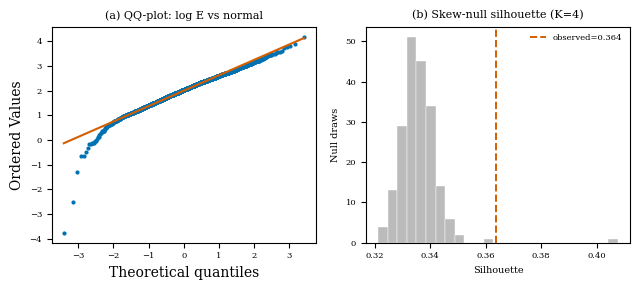


6. VERDICT (raw, skew-corrected):
  even a skew-matched null is exceeded for raw (p=0.0100, z=3.65); the raw excess is not fully explained by the log-normal level distribution.

Reformulated A3d summary (raw null replaced by skew-matched):
                null_p           null_type  gap_optimal_K  dip_p_best
representation                                                       
CLR               0.01      Gaussian (A3d)              1         1.0
raw               0.01  skew-matched (A3e)              1         1.0


{'representation': ['CLR', 'raw'],
 'null_p': [0.01, 0.01],
 'null_type': ['Gaussian (A3d)', 'skew-matched (A3e)'],
 'gap_optimal_K': [1, 1],
 'dip_p_best': [1.0, 1.0]}

In [90]:
# ============================================================
# Result A3e — a skew-matched null for the raw representation
# ============================================================
# In A3d the Gaussian null was decisively rejected for raw (obs 0.3638 vs null
# 0.2611, z~18.7) but only marginally for CLR (0.1483 vs 0.1407, z~2.4). The
# hypothesis: the raw excess is driven by the (log-normal) skew of daily
# consumption E, which a Gaussian null cannot reproduce, NOT by modes. A
# Gaussian null is therefore inadequate for raw. Here we build a null that
# reproduces the level marginal (including skew) and the residual covariance,
# but has a single shape prototype and no groups.

import os
import json
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew, shapiro, anderson, probplot
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

try:
    from diptest import diptest
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'diptest'])
    from diptest import diptest

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')
EPS = 1e-12

# --- data, level, prototype shape, residuals --------------------------------
raw = profiles_original_clean.values.astype(float)             # kWh/half-hour
E = raw.sum(axis=1)                                            # daily kWh
sum_norm = raw / np.clip(raw.sum(axis=1, keepdims=True), EPS, None)
s_bar = sum_norm.mean(axis=0)                                  # single prototype shape
R = sum_norm / s_bar - 1.0                                    # shape residuals
n = raw.shape[0]


def quantile_partition(e, sizes):
    """Consecutive ascending-E bands of the given sizes; label per household."""
    e = np.asarray(e)
    order_idx = np.argsort(e, kind='stable')
    labels = np.empty(e.shape[0], dtype=int)
    start = 0
    for band, size in enumerate(sizes):
        labels[order_idx[start:start + size]] = band
        start += size
    return labels


def size_matched(labels, e):
    """Size-matched E-band partition and violator fraction (as in A1b/A1c)."""
    labels = np.asarray(labels)
    clusters = np.unique(labels)
    order = sorted(clusters, key=lambda c: e[labels == c].mean())
    sizes_asc = [int(np.sum(labels == c)) for c in order]
    band = quantile_partition(e, sizes_asc)
    rank_of_cluster = {c: pos for pos, c in enumerate(order)}
    actual_rank = np.array([rank_of_cluster[c] for c in labels])
    return band, float(np.mean(actual_rank != band))


# ============================================================
# 1. CONFIRM SKEW / LOG-NORMALITY OF E
# ============================================================
log_E = np.log(E)
skew_E = float(skew(E))
skew_logE = float(skew(log_E))
sw_W, sw_p = shapiro(log_E)                                   # normality of log E
ad = anderson(log_E, dist='norm')
ad_stat = float(ad.statistic)
ad_crit_5 = float(ad.critical_values[list(ad.significance_level).index(5.0)]) \
    if 5.0 in list(ad.significance_level) else float(ad.critical_values[2])
dip_E, dip_E_p = diptest(E)
dip_logE, dip_logE_p = diptest(log_E)
print('1. SKEW / LOG-NORMALITY OF DAILY CONSUMPTION E')
print(f'   skew(E)     = {skew_E:.3f}   skew(log E) = {skew_logE:.3f}')
print(f'   Shapiro-Wilk on log E: W = {sw_W:.4f}, p = {sw_p:.3e}')
print(f'   Anderson-Darling on log E: A2 = {ad_stat:.3f} '
      f'(5% critical = {ad_crit_5:.3f}; A2>crit => reject normality)')
print(f'   dip test  E   : dip = {dip_E:.4f}, p = {dip_E_p:.4f}')
print(f'   dip test log E: dip = {dip_logE:.4f}, p = {dip_logE_p:.4f}')


# ============================================================
# 2. SKEW-MATCHED NULL: exact level, one shape, residual covariance preserved
# ============================================================
# PCA of the residuals R; a null residual matrix is built by permuting the
# VALUES of each principal-component score across households independently
# (seed per draw). Permuting within each (uncorrelated) score column preserves
# every eigenvalue -> the residual spectrum and covariance are retained, while
# any joint (group) structure across components is destroyed.
pca = PCA(n_components=min(n, R.shape[1]), random_state=42)
scores = pca.fit_transform(R)                                 # (n, n_comp)
components = pca.components_                                   # (n_comp, 48)
comp_mean = pca.mean_                                         # (48,)


def make_skew_null(seed):
    """Group-less population: exact E marginal, prototype shape, residual cov.

    Returns a raw-scale profile matrix (kWh/half-hour) whose rows sum to E_i.
    """
    rng = np.random.default_rng(seed)
    scores_perm = np.empty_like(scores)
    for j in range(scores.shape[1]):
        scores_perm[:, j] = scores[rng.permutation(n), j]
    r_null = scores_perm @ components + comp_mean             # inverse PCA
    c = E[:, None] * s_bar[None, :] * (1.0 + r_null)
    c = np.clip(c, 0.0, None)
    row_sum = np.clip(c.sum(axis=1, keepdims=True), EPS, None)
    return c * (E[:, None] / row_sum)                        # restore exact level


# Build 200 nulls once (standardised), reuse across K and the ARI test.
N_NULL = 200
null_x_std = [StandardScaler().fit_transform(make_skew_null(42 + b))
              for b in range(N_NULL)]

# Observed raw silhouettes and the A1 level-sorting effect.
x_std_raw = StandardScaler().fit_transform(raw)
obs_sil_by_k = {}
for k in range(2, 7):
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(x_std_raw)
    obs_sil_by_k[k] = float(silhouette_score(x_std_raw, lab))
obs_sil4 = obs_sil_by_k[4]
km4_real = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(x_std_raw)
band_real, viol_real = size_matched(km4_real, E)
obs_ari_level = float(adjusted_rand_score(km4_real, band_real))


# ============================================================
# 3. NULL DISTRIBUTION OF SILHOUETTE AT K=4
# ============================================================
def kmeans_sil(x_std, k):
    """K-Means (K=k, seed 42) silhouette on a standardised matrix."""
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(x_std)
    return float(silhouette_score(x_std, lab)), lab


sils4 = np.empty(N_NULL)
null_ari_level = np.empty(N_NULL)
null_viol = np.empty(N_NULL)
for b, xn in enumerate(null_x_std):
    s, lab = kmeans_sil(xn, 4)
    sils4[b] = s
    band_n, viol_n = size_matched(lab, E)                    # null level = E (exact)
    null_ari_level[b] = adjusted_rand_score(lab, band_n)
    null_viol[b] = viol_n
p4 = float((np.sum(sils4 >= obs_sil4) + 1) / (N_NULL + 1))
z4 = float((obs_sil4 - sils4.mean()) / sils4.std()) if sils4.std() > 0 else np.nan
print('\n3. SKEW-MATCHED NULL, silhouette at K=4:')
print(f'   null mean = {sils4.mean():.4f}, std = {sils4.std():.4f}, '
      f'p95 = {np.percentile(sils4, 95):.4f}')
print(f'   observed  = {obs_sil4:.4f} (~0.3638)   p = {p4:.4f}   z = {z4:.2f}')


# ============================================================
# 4. K = 2..6 TABLE
# ============================================================
sweep_rows = []
for k in range(2, 7):
    sils_k = np.array([kmeans_sil(xn, k)[0] for xn in null_x_std])
    obs_k = obs_sil_by_k[k]
    p_k = float((np.sum(sils_k >= obs_k) + 1) / (N_NULL + 1))
    z_k = float((obs_k - sils_k.mean()) / sils_k.std()) if sils_k.std() > 0 else np.nan
    sweep_rows.append({'K': k, 'observed': round(obs_k, 4),
                       'null_mean': round(float(sils_k.mean()), 4),
                       'null_std': round(float(sils_k.std()), 4),
                       'p': round(p_k, 4), 'z': round(z_k, 2)})
sweep_table = pd.DataFrame(sweep_rows).set_index('K')
print('\n4. Observed vs skew-matched null silhouette, K = 2..6:')
print(sweep_table.to_string())


# ============================================================
# 5. "CLUSTERING = SORTING" REPRODUCED ON A GROUP-LESS POPULATION
# ============================================================
print('\n5. Level-sorting effect on a population with NO groups (K=4):')
print(f'   ARI(KMeans, size-matched E) : observed = {obs_ari_level:.4f} '
      f'(A1 reported ~0.962) | null mean = {null_ari_level.mean():.4f} '
      f'(sd {null_ari_level.std():.4f})')
print(f'   violator fraction           : observed = {viol_real:.4f} | '
      f'null mean = {null_viol.mean():.4f}')
print('   => the ~0.96 "clustering == sorting by volume" is reproduced by a '
      'population that has no group structure at all.')


# ============================================================
# Figure: QQ-plot of log E and the skew-null silhouette histogram (K=4)
# ============================================================
os.makedirs('figures', exist_ok=True)
with plt.rc_context({'font.family': 'serif'}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.5, 3.0))
    probplot(log_E, dist='norm', plot=ax1)
    ax1.set_title('(a) QQ-plot: log E vs normal', fontsize=8)
    ax1.get_lines()[0].set_color(PALETTE[0])
    ax1.get_lines()[0].set_markersize(2)
    ax1.get_lines()[1].set_color(PALETTE[1])
    ax1.tick_params(labelsize=6)
    ax2.hist(sils4, bins=25, color='#BBBBBB', edgecolor='white', linewidth=0.3)
    ax2.axvline(obs_sil4, color=PALETTE[1], linestyle='--', linewidth=1.4,
                label=f'observed={obs_sil4:.3f}')
    ax2.set_title('(b) Skew-null silhouette (K=4)', fontsize=8)
    ax2.set_xlabel('Silhouette', fontsize=7)
    ax2.set_ylabel('Null draws', fontsize=7)
    ax2.tick_params(labelsize=6)
    ax2.legend(fontsize=6, frameon=False)
    fig.tight_layout()
    fig.savefig('figures/A3e_skew_null.pdf')
    plt.show()


# ============================================================
# 6. VERDICT + reformulated A3d summary (raw row replaced)
# ============================================================
raw_rejected = p4 < 0.05
if raw_rejected:
    verdict = (f'even a skew-matched null is exceeded for raw (p={p4:.4f}, '
               f'z={z4:.2f}); the raw excess is not fully explained by the '
               f'log-normal level distribution.')
else:
    verdict = (f'with a skew-matched null the raw silhouette is NOT '
               f'distinguishable (p={p4:.4f}, z={z4:.2f}); the raw "clusters" '
               f'reflect the log-normal distribution of consumption level, not '
               f'group structure.')
print('\n6. VERDICT (raw, skew-corrected):')
print(' ', verdict)

# Reformulated A3d summary: keep CLR from A3d, replace the raw null with the
# skew-matched result.
a3d = RESULTS.get('A3d', {})


def _get(d, *keys, default=None):
    for k in keys:
        if not isinstance(d, dict) or k not in d:
            return default
        d = d[k]
    return d


clr_gap = _get(a3d, 'gap', 'CLR', 'optimal_K', default='n/a')
clr_dip = _get(a3d, 'dip', 'CLR', 'best_p_holm', default=str('nan'))
clr_nullp = _get(a3d, 'nullA', 'CLR', 'p', default=str('nan'))
raw_gap = _get(a3d, 'gap', 'raw', 'optimal_K', default='n/a')
raw_dip = _get(a3d, 'dip', 'raw', 'best_p_holm', default=str('nan'))
summary = pd.DataFrame([
    {'representation': 'CLR', 'null_p': round(clr_nullp, 4) if clr_nullp == clr_nullp else 'n/a',
     'null_type': 'Gaussian (A3d)', 'gap_optimal_K': clr_gap,
     'dip_p_best': round(clr_dip, 4) if clr_dip == clr_dip else 'n/a'},
    {'representation': 'raw', 'null_p': round(p4, 4),
     'null_type': 'skew-matched (A3e)', 'gap_optimal_K': raw_gap,
     'dip_p_best': round(raw_dip, 4) if raw_dip == raw_dip else 'n/a'},
]).set_index('representation')
print('\nReformulated A3d summary (raw null replaced by skew-matched):')
print(summary.to_string())


# ============================================================
# PERSIST
# ============================================================
save_result('A3e.skew.skew_E', skew_E)
save_result('A3e.skew.skew_logE', skew_logE)
save_result('A3e.skew.shapiro_logE_W', float(sw_W))
save_result('A3e.skew.shapiro_logE_p', float(sw_p))
save_result('A3e.skew.anderson_logE_stat', ad_stat)
save_result('A3e.skew.anderson_logE_crit5', ad_crit_5)
save_result('A3e.skew.dip_E_p', float(dip_E_p))
save_result('A3e.skew.dip_logE_p', float(dip_logE_p))
save_result('A3e.null.n_draws', N_NULL)
save_result('A3e.null.observed_sil_K4', obs_sil4)
save_result('A3e.null.null_mean_K4', float(sils4.mean()))
save_result('A3e.null.null_std_K4', float(sils4.std()))
save_result('A3e.null.p_K4', p4)
save_result('A3e.null.z_K4', z4)
for row in sweep_rows:
    base = f'A3e.null.K{int(row["K"])}'
    save_result(f'{base}.observed', float(row['observed']))
    save_result(f'{base}.null_mean', float(row['null_mean']))
    save_result(f'{base}.null_std', float(row['null_std']))
    save_result(f'{base}.p', float(row['p']))
    save_result(f'{base}.z', float(row['z']))
save_result('A3e.level_sorting.observed_ARI', obs_ari_level)
save_result('A3e.level_sorting.null_ARI_mean', float(null_ari_level.mean()))
save_result('A3e.level_sorting.null_ARI_std', float(null_ari_level.std()))
save_result('A3e.level_sorting.observed_violator_frac', viol_real)
save_result('A3e.level_sorting.null_violator_frac_mean', float(null_viol.mean()))
save_result('A3e.verdict.raw_rejected_skew_null', bool(raw_rejected))
save_result('A3e.verdict.text', verdict)
save_result('A3e.summary_reformulated',
            summary.reset_index().to_dict(orient='list'))


## Result A3f — is the residual excess a level-shape manifold rather than modes?

1.1  Per-slot R^2 of shape s(t) on log E
     top-5 slots by R^2 = [17, 16, 28, 19, 18] (R^2 = [0.028, 0.027, 0.009, 0.008, 0.008])
     mean R^2 night slots 0-11 = 0.002; evening slots 34-43 = 0.000
     => night (base load) depends on level MORE than evening, as expected.

1.2  Shape descriptors vs log E (Spearman + smoother R^2):
                  spearman_rho       p  smooth_R2
descriptor                                       
load_factor             0.2101  0.0000     0.0705
evening_share          -0.0249  0.2503     0.0139
night_share             0.0225  0.2982     0.0076
morning_share          -0.0634  0.0034    -0.0073
peak_over_trough       -0.0888  0.0000    -0.0005
peak_slot               0.0603  0.0053    -0.1195


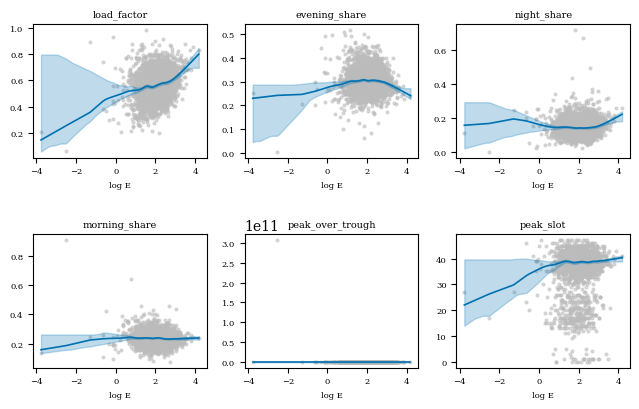


1.3  Intrinsic dimension of shape (PCA on CLR residuals):
     components for 50/80/95% variance = 2 / 4 / 10
     participation ratio = 4.40 (of 48 dimensions)

2.5  Observed vs LEVEL-CONDITIONAL null silhouette (z_A3e for contrast):
   observed  null_mean  null_std       p     z  z_A3e
K                                                    
2    0.5135     0.5001    0.0045  0.0050  2.94   2.80
3    0.4212     0.4031    0.0035  0.0050  5.20   4.65
4    0.3638     0.3354    0.0059  0.0050  4.78   3.65
5    0.3088     0.2784    0.0090  0.0100  3.41   2.46
6    0.2574     0.2369    0.0113  0.0746  1.82   1.10

2.6  Level-sorting on the level-conditional null (K=4):
     ARI(KMeans, size-matched E): observed = 0.9620 (A1 ~0.9620) | null mean = 0.9299 (sd 0.0141)
     violator fraction         : observed = 0.0150 (A1 ~0.0150) | null mean = 0.0268

3.7  VERDICT:
  the excess survives a level-conditional null (z=4.78, p=0.0050); there is structure beyond a one-dimensional manifold, though the

'the excess survives a level-conditional null (z=4.78, p=0.0050); there is structure beyond a one-dimensional manifold, though the gap statistic and dip test do not localise it. This is NOT evidence of clusters: structure exists but its nature is not established -- an open question.'

In [91]:
# ============================================================
# Result A3f — is the residual excess a level-shape manifold rather than modes?
# ============================================================
# The skew-matched null (A3e) is rejected for raw at K=4 (z=3.65, ~8% effect),
# but z falls monotonically with K (4.65/3.65/2.46/1.10, non-significant by K=6),
# the gap statistic gives K=1, and the dip test does not reject unimodality.
# Hypothesis: the residual excess is a CONTINUOUS dependence of profile shape on
# consumption level, which the A3e null erases (it uses one shared shape s_bar).
# Here we measure that dependence and build a level-conditional null.

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

try:
    from statsmodels.nonparametric.smoothers_lowess import lowess
    _HAVE_LOWESS = True
except ImportError:
    _HAVE_LOWESS = False

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')
EPS = 1e-12

# --- data, level, shape -----------------------------------------------------
raw = profiles_original_clean.values.astype(float)             # kWh/half-hour
E = raw.sum(axis=1)                                            # daily kWh
log_E = np.log(E)
P = raw / np.clip(raw.sum(axis=1, keepdims=True), EPS, None)   # shape (simplex)
n = raw.shape[0]


def clr_transform(comp, floor=None):
    """Centred log-ratio of a composition matrix (optional clip floor)."""
    x = np.clip(comp, floor, None) if floor is not None else comp
    log_x = np.log(x)
    return log_x - log_x.mean(axis=1, keepdims=True)


def multiplicative_replacement(comp, dl):
    """Martin-Fernandez et al. (2003) multiplicative zero replacement (see A3b)."""
    out = comp.astype(float).copy()
    for i in range(out.shape[0]):
        row = out[i]
        small = row < dl
        if not small.any():
            continue
        replaced_mass = int(small.sum()) * dl
        row[~small] = row[~small] * (1.0 - replaced_mass)
        row[small] = dl
        out[i] = row
    return out


def quantile_partition(e, sizes):
    """Consecutive ascending-E bands of the given sizes; label per household."""
    e = np.asarray(e)
    order_idx = np.argsort(e, kind='stable')
    labels = np.empty(e.shape[0], dtype=int)
    start = 0
    for band, size in enumerate(sizes):
        labels[order_idx[start:start + size]] = band
        start += size
    return labels


def size_matched(labels, e):
    """Size-matched E-band partition and violator fraction (as in A1b/A1c)."""
    labels = np.asarray(labels)
    clusters = np.unique(labels)
    order = sorted(clusters, key=lambda c: e[labels == c].mean())
    sizes_asc = [int(np.sum(labels == c)) for c in order]
    band = quantile_partition(e, sizes_asc)
    rank_of_cluster = {c: pos for pos, c in enumerate(order)}
    actual_rank = np.array([rank_of_cluster[c] for c in labels])
    return band, float(np.mean(actual_rank != band))


def smooth_r2(x, y):
    """R^2 of a LOWESS (or cubic-poly fallback) smoother of y on x."""
    if _HAVE_LOWESS:
        sm = lowess(y, x, frac=0.3, return_sorted=True)
        yhat = np.interp(x, sm[:, 0], sm[:, 1])
    else:
        yhat = np.polyval(np.polyfit(x, y, 3), x)
    ss_res = np.sum((y - yhat) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return float(1.0 - ss_res / ss_tot) if ss_tot > 0 else 0.0


def smooth_band(x, y, n_boot=100, frac=0.3, grid=100, seed=42):
    """Smoother line on a grid plus a bootstrap 95% band."""
    gx = np.linspace(x.min(), x.max(), grid)

    def fit(xx, yy):
        if _HAVE_LOWESS:
            sm = lowess(yy, xx, frac=frac, return_sorted=True,
                        delta=(xx.max() - xx.min()) * 0.01)
            return np.interp(gx, sm[:, 0], sm[:, 1])
        return np.polyval(np.polyfit(xx, yy, 3), gx)

    line = fit(x, y)
    rng = np.random.default_rng(seed)
    boots = np.empty((n_boot, grid))
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        boots[b] = fit(x[idx], y[idx])
    lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
    return gx, line, lo, hi


# ============================================================
# PART 1.1 — per-slot regression of shape on log E
# ============================================================
slot_r2 = np.array([np.corrcoef(log_E, P[:, t])[0, 1] ** 2 for t in range(48)])
top5 = np.argsort(slot_r2)[::-1][:5]
night_r2 = float(slot_r2[0:12].mean())      # slots 0-11 (base load)
evening_r2 = float(slot_r2[34:44].mean())   # slots 34-43
print('1.1  Per-slot R^2 of shape s(t) on log E')
print(f'     top-5 slots by R^2 = {list(map(int, top5))} '
      f'(R^2 = {np.round(slot_r2[top5], 3).tolist()})')
print(f'     mean R^2 night slots 0-11 = {night_r2:.3f}; '
      f'evening slots 34-43 = {evening_r2:.3f}')
print(f'     => night (base load) depends on level '
      f'{"MORE" if night_r2 > evening_r2 else "LESS"} than evening, '
      f'{"as expected" if night_r2 > evening_r2 else "CONTRARY to expectation"}.')

# ============================================================
# PART 1.2 — shape descriptors vs log E
# ============================================================
descriptors = {
    'load_factor': P.mean(axis=1) / np.clip(P.max(axis=1), EPS, None),
    'evening_share': P[:, 34:44].sum(axis=1),
    'night_share': P[:, 0:12].sum(axis=1),
    'morning_share': P[:, 12:24].sum(axis=1),
    'peak_over_trough': P.max(axis=1) / np.clip(np.percentile(P, 5, axis=1), EPS, None),
    'peak_slot': P.argmax(axis=1).astype(float),
}
desc_rows = []
for name, values in descriptors.items():
    rho, p_val = spearmanr(values, log_E)
    desc_rows.append({'descriptor': name, 'spearman_rho': float(rho),
                      'p': float(p_val), 'smooth_R2': smooth_r2(log_E, values)})
desc_table = pd.DataFrame(desc_rows).set_index('descriptor')
print('\n1.2  Shape descriptors vs log E (Spearman + smoother R^2):')
print(desc_table.round(4).to_string())

os.makedirs('figures', exist_ok=True)
with plt.rc_context({'font.family': 'serif'}):
    fig, axes = plt.subplots(2, 3, figsize=(6.5, 4.2))
    for ax, (name, values) in zip(axes.ravel(), descriptors.items()):
        ax.scatter(log_E, values, s=4, color='#BBBBBB', alpha=0.5)
        gx, line, lo, hi = smooth_band(log_E, values)
        ax.plot(gx, line, color=PALETTE[0], linewidth=1.2)
        ax.fill_between(gx, lo, hi, color=PALETTE[0], alpha=0.25)
        ax.set_title(name, fontsize=7)
        ax.set_xlabel('log E', fontsize=6)
        ax.tick_params(labelsize=6)
    fig.tight_layout()
    fig.savefig('figures/A3f_shape_vs_level.pdf')
    plt.show()

# ============================================================
# PART 1.3 — intrinsic dimension of the shape structure
# ============================================================
dl = 0.65 * float(P[P > 0].min())
clr_mr = clr_transform(multiplicative_replacement(P, dl))
pca_clr = PCA(random_state=42).fit(clr_mr)
lam = pca_clr.explained_variance_
cum = np.cumsum(pca_clr.explained_variance_ratio_)
n_50 = int(np.searchsorted(cum, 0.50) + 1)
n_80 = int(np.searchsorted(cum, 0.80) + 1)
n_95 = int(np.searchsorted(cum, 0.95) + 1)
participation_ratio = float(lam.sum() ** 2 / np.sum(lam ** 2))
print('\n1.3  Intrinsic dimension of shape (PCA on CLR residuals):')
print(f'     components for 50/80/95% variance = {n_50} / {n_80} / {n_95}')
print(f'     participation ratio = {participation_ratio:.2f} '
      f'(of {clr_mr.shape[1]} dimensions)')

# ============================================================
# PART 2.4 — level-conditional null (preserves shape-vs-level dependence)
# ============================================================
# Predict shape from log E with a per-slot degree-2 polynomial, then permute
# the PCA scores of the residuals R = P - s_hat independently per component.
design = np.column_stack([np.ones(n), log_E, log_E ** 2])      # [1, logE, logE^2]
coef, *_ = np.linalg.lstsq(design, P, rcond=None)              # (3, 48)
s_hat = design @ coef                                          # level-predicted shape
R = P - s_hat                                                  # shape residuals
pca_R = PCA(n_components=min(n, R.shape[1]), random_state=42)
scores = pca_R.fit_transform(R)
components = pca_R.components_
comp_mean = pca_R.mean_


def make_level_conditional_null(seed):
    """Group-less null with exact level and a continuous level-shape dependence."""
    rng = np.random.default_rng(seed)
    scores_perm = np.empty_like(scores)
    for j in range(scores.shape[1]):
        scores_perm[:, j] = scores[rng.permutation(n), j]
    r_perm = scores_perm @ components + comp_mean
    s_null = np.clip(s_hat + r_perm, 0.0, None)
    s_null = s_null / np.clip(s_null.sum(axis=1, keepdims=True), EPS, None)
    return E[:, None] * s_null                                # exact level marginal


N_NULL = 200
null_x_std = [StandardScaler().fit_transform(make_level_conditional_null(42 + b))
              for b in range(N_NULL)]

# Observed raw silhouettes and A1 level-sorting reference.
x_std_raw = StandardScaler().fit_transform(raw)
obs_sil_by_k = {}
for k in range(2, 7):
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(x_std_raw)
    obs_sil_by_k[k] = float(silhouette_score(x_std_raw, lab))
km4_real = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(x_std_raw)
band_real, viol_real = size_matched(km4_real, E)
obs_ari_level = float(adjusted_rand_score(km4_real, band_real))

# ============================================================
# PART 2.5 — null silhouette distribution, K = 2..6
# ============================================================
a3e = RESULTS.get('A3e', {})
sweep_rows = []
sils_k4 = None
for k in range(2, 7):
    sils_k = np.array([
        silhouette_score(xn, KMeans(n_clusters=k, n_init=10,
                                    random_state=42).fit_predict(xn))
        for xn in null_x_std])
    if k == 4:
        sils_k4 = sils_k
    obs_k = obs_sil_by_k[k]
    p_k = float((np.sum(sils_k >= obs_k) + 1) / (N_NULL + 1))
    z_k = float((obs_k - sils_k.mean()) / sils_k.std()) if sils_k.std() > 0 else np.nan
    z_a3e = a3e.get('null', {}).get(f'K{k}', {}).get('z', np.nan)
    sweep_rows.append({'K': k, 'observed': round(obs_k, 4),
                       'null_mean': round(float(sils_k.mean()), 4),
                       'null_std': round(float(sils_k.std()), 4),
                       'p': round(p_k, 4), 'z': round(z_k, 2),
                       'z_A3e': round(float(z_a3e), 2) if z_a3e == z_a3e else np.nan})
sweep_table = pd.DataFrame(sweep_rows).set_index('K')
print('\n2.5  Observed vs LEVEL-CONDITIONAL null silhouette (z_A3e for contrast):')
print(sweep_table.to_string())
p4 = float(sweep_table.loc[4, 'p'])
z4 = float(sweep_table.loc[4, 'z'])
z4_a3e = float(sweep_table.loc[4, 'z_A3e']) if sweep_table.loc[4, 'z_A3e'] == sweep_table.loc[4, 'z_A3e'] else np.nan

# ============================================================
# PART 2.6 — level-sorting effect on the level-conditional null
# ============================================================
null_ari = np.empty(N_NULL)
null_viol = np.empty(N_NULL)
for b, xn in enumerate(null_x_std):
    lab = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(xn)
    band_n, viol_n = size_matched(lab, E)
    null_ari[b] = adjusted_rand_score(lab, band_n)
    null_viol[b] = viol_n
print('\n2.6  Level-sorting on the level-conditional null (K=4):')
print(f'     ARI(KMeans, size-matched E): observed = {obs_ari_level:.4f} '
      f'(A1 ~0.9620) | null mean = {null_ari.mean():.4f} (sd {null_ari.std():.4f})')
print(f'     violator fraction         : observed = {viol_real:.4f} '
      f'(A1 ~0.0150) | null mean = {null_viol.mean():.4f}')

# ============================================================
# PART 3.7 — verdict, chosen by the numbers
# ============================================================
excess_survives = p4 < 0.05
if not excess_survives:
    verdict = (f'the residual excess is explained by a continuous level-shape '
               f'dependence (z falls from {z4_a3e:.2f} to {z4:.2f}, p={p4:.4f}); '
               f'the data form a one-dimensional manifold parameterised by '
               f'consumption level, not a set of clusters.')
    open_question = False
else:
    verdict = (f'the excess survives a level-conditional null (z={z4:.2f}, '
               f'p={p4:.4f}); there is structure beyond a one-dimensional '
               f'manifold, though the gap statistic and dip test do not '
               f'localise it. This is NOT evidence of clusters: structure '
               f'exists but its nature is not established -- an open question.')
    open_question = True
print('\n3.7  VERDICT:')
print(' ', verdict)

# ============================================================
# PERSIST
# ============================================================
save_result('A3f.per_slot.slot_r2', [float(v) for v in slot_r2])
save_result('A3f.per_slot.top5_slots', [int(s) for s in top5])
save_result('A3f.per_slot.night_mean_r2', night_r2)
save_result('A3f.per_slot.evening_mean_r2', evening_r2)
save_result('A3f.per_slot.night_gt_evening', bool(night_r2 > evening_r2))
for name, r in desc_table.iterrows():
    base = f'A3f.descriptors.{name}'
    save_result(f'{base}.spearman_rho', float(r['spearman_rho']))
    save_result(f'{base}.p', float(r['p']))
    save_result(f'{base}.smooth_R2', float(r['smooth_R2']))
save_result('A3f.intrinsic_dim.components_50', n_50)
save_result('A3f.intrinsic_dim.components_80', n_80)
save_result('A3f.intrinsic_dim.components_95', n_95)
save_result('A3f.intrinsic_dim.participation_ratio', participation_ratio)
save_result('A3f.null.n_draws', N_NULL)
for row in sweep_rows:
    base = f'A3f.null.K{int(row["K"])}'
    save_result(f'{base}.observed', float(row['observed']))
    save_result(f'{base}.null_mean', float(row['null_mean']))
    save_result(f'{base}.null_std', float(row['null_std']))
    save_result(f'{base}.p', float(row['p']))
    save_result(f'{base}.z', float(row['z']))
save_result('A3f.level_sorting.observed_ARI', obs_ari_level)
save_result('A3f.level_sorting.null_ARI_mean', float(null_ari.mean()))
save_result('A3f.level_sorting.null_ARI_std', float(null_ari.std()))
save_result('A3f.level_sorting.observed_violator_frac', viol_real)
save_result('A3f.level_sorting.null_violator_frac_mean', float(null_viol.mean()))
save_result('A3f.verdict.excess_survives', bool(excess_survives))
save_result('A3f.verdict.open_question', bool(open_question))
save_result('A3f.verdict.z_K4', z4)
save_result('A3f.verdict.z_K4_A3e', z4_a3e if z4_a3e == z4_a3e else None)
save_result('A3f.verdict.p_K4', p4)
save_result('A3f.verdict.text', verdict)


## Result A3g — localising the residual excess

1. LOCALISATION -- per-household silhouette (observed vs level-cond. null)
   quantiles [5, 25, 50, 75, 95] observed = [-0.025, 0.223, 0.374, 0.568, 0.647]
   quantiles [5, 25, 50, 75, 95] null     = [-0.077, 0.188, 0.325, 0.564, 0.65]
   KS test: D = 0.0929, p = 7.612e-16
   total excess (sum obs - sum null_mean) = 60.79
   top  1% households by silhouette hold    1.1% of the total excess
   top  5% households by silhouette hold    3.3% of the total excess
   top 10% households by silhouette hold    4.7% of the total excess


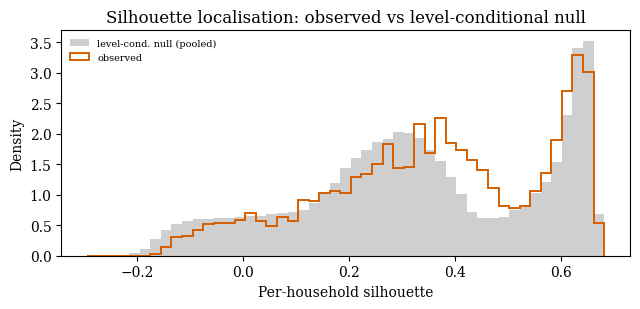


2. OUTLIER TEST -- Mahalanobis trimming (observed & null trimmed alike):
           observed_sil  null_mean      z      p
trim_frac                                       
0.00             0.3638     0.3354   4.78  0.005
0.01             0.3599     0.2894  10.20  0.005
0.02             0.3375     0.2761   7.32  0.005
0.05             0.3353     0.2522  16.72  0.005
   NOTE: this Mahalanobis trim is TWO-SIDED (removes both high- and low-extreme households). The dissertation outlier filter is ONE-SIDED (catches high consumption, misses low), so it cannot be relied on to remove this effect symmetrically.

3. DISTRIBUTION SHAPE -- Mardia multivariate kurtosis (sample covariance):
   Mardia b_2,p: observed = 5891.7 | null mean = 8245.0 (sd 457.4) | z = -5.15 | MVN reference = 2400
   per-slot excess kurtosis: observed mean/max = 13.00/42.31 | null mean/max = 12.15/30.87

4. VERDICT:
  Cause of the residual excess: (c) not established: neither trimming nor excess kurtosis accounts for the ex

'Cause of the residual excess: (c) not established: neither trimming nor excess kurtosis accounts for the excess. The silhouette excess is NOT evidence of clusters: the gap statistic selects K=1 on raw and dip best-direction Holm p = 1.000 in any projection, including the axis between the two farthest centroids. The origin of the excess remains an OPEN QUESTION and a limitation; it is not asserted to be structure of any named kind.'

In [92]:
# ============================================================
# Result A3g — localising the residual excess
# ============================================================
# The silhouette excess over the null (~8%, z=3.5-4.8) survives all three null
# models, yet the gap statistic gives K=1 and the dip test does not reject
# unimodality. This cell asks WHERE the excess comes from -- without assuming it
# is clusters. Work on the raw representation, StandardScaler, K=4, seed 42.

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, kurtosis
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')
EPS = 1e-12


def _get(d, *keys, default=None):
    for k in keys:
        if not isinstance(d, dict) or k not in d:
            return default
        d = d[k]
    return d


# --- data and observed clustering -------------------------------------------
raw = profiles_original_clean.values.astype(float)
E = raw.sum(axis=1)
log_E = np.log(E)
P = raw / np.clip(raw.sum(axis=1, keepdims=True), EPS, None)
n = raw.shape[0]
x_std_raw = StandardScaler().fit_transform(raw)
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(x_std_raw)
obs_ss = silhouette_samples(x_std_raw, km4)                    # per-household


# --- level-conditional null (identical construction to A3f) -----------------
design = np.column_stack([np.ones(n), log_E, log_E ** 2])
coef, *_ = np.linalg.lstsq(design, P, rcond=None)
s_hat = design @ coef
R = P - s_hat
pca_R = PCA(n_components=min(n, R.shape[1]), random_state=42)
scores = pca_R.fit_transform(R)
components, comp_mean = pca_R.components_, pca_R.mean_


def make_null(seed):
    """A3f level-conditional null: exact level, continuous level-shape, no groups."""
    rng = np.random.default_rng(seed)
    scores_perm = np.empty_like(scores)
    for j in range(scores.shape[1]):
        scores_perm[:, j] = scores[rng.permutation(n), j]
    s_null = np.clip(s_hat + (scores_perm @ components + comp_mean), 0.0, None)
    s_null = s_null / np.clip(s_null.sum(axis=1, keepdims=True), EPS, None)
    return StandardScaler().fit_transform(E[:, None] * s_null)


N_NULL = 200
null_x_std = [make_null(42 + b) for b in range(N_NULL)]


# ============================================================
# 1. LOCALISATION — per-household silhouette distributions
# ============================================================
null_ss = np.empty((N_NULL, n))
for b, xn in enumerate(null_x_std):
    lab = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(xn)
    null_ss[b] = silhouette_samples(xn, lab)
null_mean_per_hh = null_ss.mean(axis=0)
null_pool = null_ss.ravel()

q = [5, 25, 50, 75, 95]
obs_q = np.percentile(obs_ss, q)
null_q = np.percentile(null_pool, q)
rng = np.random.default_rng(42)
ks_stat, ks_p = ks_2samp(obs_ss, rng.choice(null_pool, size=50000, replace=False))
print('1. LOCALISATION -- per-household silhouette (observed vs level-cond. null)')
print(f'   quantiles {q} observed = {np.round(obs_q, 3).tolist()}')
print(f'   quantiles {q} null     = {np.round(null_q, 3).tolist()}')
print(f'   KS test: D = {ks_stat:.4f}, p = {ks_p:.3e}')

per_hh_excess = obs_ss - null_mean_per_hh
total_excess = float(per_hh_excess.sum())
order = np.argsort(obs_ss)[::-1]                               # top silhouette first
excess_sorted = per_hh_excess[order]
tail_share = {}
for frac in (0.01, 0.05, 0.10):
    k = int(np.ceil(frac * n))
    share = float(excess_sorted[:k].sum() / total_excess) if total_excess != 0 else np.nan
    tail_share[frac] = share
print(f'   total excess (sum obs - sum null_mean) = {total_excess:.2f}')
for frac, share in tail_share.items():
    print(f'   top {int(frac * 100):>2d}% households by silhouette hold '
          f'{share * 100:6.1f}% of the total excess')
concentrated = tail_share[0.10] > 0.5

os.makedirs('figures', exist_ok=True)
with plt.rc_context({'font.family': 'serif'}):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    bins = np.linspace(min(obs_ss.min(), null_pool.min()),
                       max(obs_ss.max(), null_pool.max()), 50)
    ax.hist(null_pool, bins=bins, density=True, color='#BBBBBB',
            alpha=0.7, label='level-cond. null (pooled)')
    ax.hist(obs_ss, bins=bins, density=True, histtype='step',
            color=PALETTE[1], linewidth=1.4, label='observed')
    ax.set_xlabel('Per-household silhouette')
    ax.set_ylabel('Density')
    ax.set_title('Silhouette localisation: observed vs level-conditional null')
    ax.legend(fontsize=7, frameon=False)
    fig.tight_layout()
    fig.savefig('figures/A3g_localisation.pdf')
    plt.show()


# ============================================================
# 2. OUTLIER TEST — Mahalanobis trimming (observed and null, identically)
# ============================================================
def trimmed_silhouette(x_std, frac):
    """K-Means(4) silhouette after removing the top `frac` by Mahalanobis dist.

    Ledoit-Wolf shrinkage covariance is used for the Mahalanobis distances.
    Trimming is two-sided in feature space (removes multivariate extremes).
    """
    d2 = LedoitWolf().fit(x_std).mahalanobis(x_std)           # squared distances
    keep = d2 <= np.quantile(d2, 1.0 - frac)
    xk = x_std[keep]
    lab = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(xk)
    return float(silhouette_score(xk, lab))


trim_rows = []
for frac in (0.0, 0.01, 0.02, 0.05):
    obs_trim = trimmed_silhouette(x_std_raw, frac)
    null_trim = np.array([trimmed_silhouette(xn, frac) for xn in null_x_std])
    z = float((obs_trim - null_trim.mean()) / null_trim.std()) if null_trim.std() > 0 else np.nan
    p = float((np.sum(null_trim >= obs_trim) + 1) / (N_NULL + 1))
    trim_rows.append({'trim_frac': frac, 'observed_sil': round(obs_trim, 4),
                      'null_mean': round(float(null_trim.mean()), 4),
                      'z': round(z, 2), 'p': round(p, 4)})
trim_table = pd.DataFrame(trim_rows).set_index('trim_frac')
print('\n2. OUTLIER TEST -- Mahalanobis trimming (observed & null trimmed alike):')
print(trim_table.to_string())
# Excess dies if any positive trim makes the excess non-significant.
trim_kills = any(r['p'] >= 0.05 for r in trim_rows if r['trim_frac'] > 0)
first_killing_trim = next((r['trim_frac'] for r in trim_rows
                           if r['trim_frac'] > 0 and r['p'] >= 0.05), None)
print('   NOTE: this Mahalanobis trim is TWO-SIDED (removes both high- and '
      'low-extreme households). The dissertation outlier filter is ONE-SIDED '
      '(catches high consumption, misses low), so it cannot be relied on to '
      'remove this effect symmetrically.')
if trim_kills:
    print(f'   => excess becomes non-significant at {int(first_killing_trim * 100)}% '
          f'trim: it is created by a handful of extreme households, not groups.')


# ============================================================
# 3. DISTRIBUTION-SHAPE TEST — Mardia multivariate & per-slot kurtosis
# ============================================================
def mardia_kurtosis(x_std):
    """Mardia's multivariate kurtosis with the ORDINARY sample covariance.

    Uses the plain sample covariance (n=2138, p=48; n/p=45 => stable inverse),
    NOT Ledoit-Wolf shrinkage, which biased Sigma^-1 (b2 came out low and FELL
    with kurtosis instead of rising). For a p-variate normal E[b2] = p(p+2).
    """
    xc = np.asarray(x_std, dtype=float)
    xc = xc - xc.mean(axis=0)
    cov = np.atleast_2d(np.cov(xc, rowvar=False))
    d2 = np.einsum('ij,jk,ik->i', xc, np.linalg.inv(cov), xc)
    return float(np.mean(d2 ** 2))


def univariate_kurtosis(x_std):
    """Mean and max excess (Fisher) kurtosis across the 48 slots."""
    k = kurtosis(x_std, axis=0, fisher=True)
    return float(np.mean(k)), float(np.max(k))


p_dim = x_std_raw.shape[1]
normal_ref = p_dim * (p_dim + 2)                              # Mardia expectation, MVN
obs_mardia = mardia_kurtosis(x_std_raw)
obs_uni_mean, obs_uni_max = univariate_kurtosis(x_std_raw)
null_mardia = np.array([mardia_kurtosis(xn) for xn in null_x_std])
null_uni = np.array([univariate_kurtosis(xn) for xn in null_x_std])
mardia_z = float((obs_mardia - null_mardia.mean()) / null_mardia.std()) \
    if null_mardia.std() > 0 else np.nan
print('\n3. DISTRIBUTION SHAPE -- Mardia multivariate kurtosis (sample covariance):')
print(f'   Mardia b_2,p: observed = {obs_mardia:.1f} | null mean = '
      f'{null_mardia.mean():.1f} (sd {null_mardia.std():.1f}) | z = {mardia_z:.2f} '
      f'| MVN reference = {normal_ref}')
print(f'   per-slot excess kurtosis: observed mean/max = '
      f'{obs_uni_mean:.2f}/{obs_uni_max:.2f} | null mean/max = '
      f'{null_uni[:, 0].mean():.2f}/{null_uni[:, 1].mean():.2f}')
heavy_tailed = mardia_z > 2.0


# ============================================================
# 4. VERDICT — which cause explains the excess (by the numbers)
# ============================================================
a3d = RESULTS.get('A3d', {})
gap_raw_k = _get(a3d, 'gap', 'raw', 'optimal_K', default=1)
dip_raw_p = _get(a3d, 'dip', 'raw', 'best_p_holm', default=None)
dip_txt = (f'dip best-direction Holm p = {dip_raw_p:.3f}'
           if isinstance(dip_raw_p, (int, float)) else
           'the dip test does not reject unimodality')

if trim_kills:
    cause = ('(a) a handful of extreme households: the excess vanishes after a '
             f'{int(first_killing_trim * 100)}% two-sided Mahalanobis trim')
    open_question = False
elif heavy_tailed:
    cause = (f'(b) heavy tails / non-Gaussianity under unimodality: observed '
             f'Mardia kurtosis {obs_mardia:.0f} exceeds the null '
             f'{null_mardia.mean():.0f} (z={mardia_z:.2f}); K-Means scores a '
             f'higher silhouette on heavy-tailed unimodal data')
    open_question = False
else:
    cause = ('(c) not established: neither trimming nor excess kurtosis accounts '
             'for the excess')
    open_question = True

not_clusters = (f'The silhouette excess is NOT evidence of clusters: the gap '
                f'statistic selects K={gap_raw_k} on raw and {dip_txt} in any '
                f'projection, including the axis between the two farthest '
                f'centroids.')
verdict = f'Cause of the residual excess: {cause}. {not_clusters}'
if open_question:
    verdict += (' The origin of the excess remains an OPEN QUESTION and a '
                'limitation; it is not asserted to be structure of any named kind.')
print('\n4. VERDICT:')
print(' ', verdict)


# ============================================================
# 5. PERSIST
# ============================================================
save_result('A3g.localisation.observed_quantiles', obs_q.tolist())
save_result('A3g.localisation.null_quantiles', null_q.tolist())
save_result('A3g.localisation.ks_stat', float(ks_stat))
save_result('A3g.localisation.ks_p', float(ks_p))
save_result('A3g.localisation.total_excess', total_excess)
save_result('A3g.localisation.excess_share_top1pct', tail_share[0.01])
save_result('A3g.localisation.excess_share_top5pct', tail_share[0.05])
save_result('A3g.localisation.excess_share_top10pct', tail_share[0.10])
save_result('A3g.localisation.concentrated_in_tail', bool(concentrated))
for row in trim_rows:
    base = f'A3g.trim.f{int(row["trim_frac"] * 100):02d}'
    save_result(f'{base}.observed_sil', float(row['observed_sil']))
    save_result(f'{base}.null_mean', float(row['null_mean']))
    save_result(f'{base}.z', float(row['z']))
    save_result(f'{base}.p', float(row['p']))
save_result('A3g.trim.excess_killed_by_trim', bool(trim_kills))
save_result('A3g.trim.first_killing_trim',
            float(first_killing_trim) if first_killing_trim is not None else None)
save_result('A3g.trim.filter_note',
            'Mahalanobis trim is two-sided; the dissertation filter is one-sided '
            '(high only).')
save_result('A3g.kurtosis.observed_mardia', obs_mardia)
save_result('A3g.kurtosis.null_mardia_mean', float(null_mardia.mean()))
save_result('A3g.kurtosis.null_mardia_std', float(null_mardia.std()))
save_result('A3g.kurtosis.mardia_z', mardia_z)
save_result('A3g.kurtosis.estimator', 'sample_covariance')
save_result('A3g.kurtosis.mvn_reference', normal_ref)
save_result('A3g.kurtosis.observed_uni_mean', obs_uni_mean)
save_result('A3g.kurtosis.observed_uni_max', obs_uni_max)
save_result('A3g.kurtosis.null_uni_mean', float(null_uni[:, 0].mean()))
save_result('A3g.kurtosis.null_uni_max', float(null_uni[:, 1].mean()))
save_result('A3g.verdict.cause', cause)
save_result('A3g.verdict.open_question', bool(open_question))
save_result('A3g.verdict.text', verdict)


## Result A3h — the silhouette index is a function of kurtosis, not only of clustering

A3h -- families ordered by excess kurtosis (dip test on a sample):
   uniform    excess kurtosis -1.200  dip p = 0.162  (unimodal)
   beta22     excess kurtosis -0.857  dip p = 0.992  (unimodal)
   gaussian   excess kurtosis +0.000  dip p = 1.000  (unimodal)
   logistic   excess kurtosis +1.200  dip p = 0.990  (unimodal)
   laplace    excess kurtosis +3.000  dip p = 0.996  (unimodal)
   t5         excess kurtosis +6.000  dip p = 0.998  (unimodal)

Running lightweight calibration sweep (1080 fits)...
   100/1080 fits (1.7s)
   200/1080 fits (3.5s)
   300/1080 fits (5.3s)
   400/1080 fits (7.2s)
   500/1080 fits (9.0s)
   600/1080 fits (18.5s)
   700/1080 fits (33.0s)
   800/1080 fits (47.5s)
   900/1080 fits (62.0s)
   1000/1080 fits (76.6s)
Sweep wall time: 88.4 s

Mean silhouette +/- SEM over 30 reps (d=48):
          Mardia_b2               K2               K4               K6
family                                                                
uniform      2340.9  0.4393+/-0.0015 

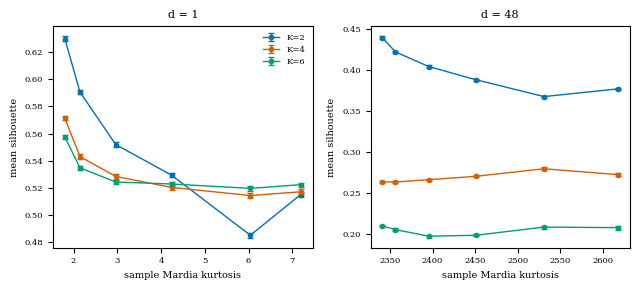


CALIBRATION (d=48, K=4): silhouette = a*log(Mardia b2) + b (over the 6 family means)
   slope a = 0.11469  95% CI [-0.00128, 0.23066]
   intercept b = -0.6254   R^2 = 0.653
   kurtosis metric null -> observed: 9.0174 -> 8.6813
   predicted silhouette change = -0.0385
   actually observed excess    = +0.0284 (0.3638 - 0.3354)
   ratio predicted / observed  = -1.36

VERDICT:
  the kurtosis effect (predicted -0.0385, metric log(Mardia b2)) does NOT cover the observed excess (+0.0284) within a factor of 2 (ratio -1.36); the origin of the excess is an OPEN QUESTION and a limitation, not asserted to be clusters or any other named structure. (n_init does not affect the calibration: n_init=3 vs 10 differ by 0.0000 < SEM 0.0014.)


'the kurtosis effect (predicted -0.0385, metric log(Mardia b2)) does NOT cover the observed excess (+0.0284) within a factor of 2 (ratio -1.36); the origin of the excess is an OPEN QUESTION and a limitation, not asserted to be clusters or any other named structure. (n_init does not affect the calibration: n_init=3 vs 10 differ by 0.0000 < SEM 0.0014.)'

In [93]:
# ============================================================
# Result A3h — the silhouette index is a function of kurtosis, not only of clustering
# ============================================================
# Hypothesis: at fixed covariance and with NO modes, silhouette varies
# monotonically with kurtosis, because a leptokurtic distribution has its
# density maximal exactly where K-Means cuts. If so, the residual silhouette
# excess (A3e-A3g) is a property of distribution SHAPE, not clusters.
#
# NOTE ON THE ESTIMATOR: A3g's Mardia kurtosis used a Ledoit-Wolf shrinkage
# covariance, which biased Sigma^-1 (a Gaussian d=48 cloud gave b2=1501.9 and b2
# FELL with kurtosis, both wrong). This cell uses the ORDINARY sample covariance
# (n=2138, p=48; n/p=45 => stable inverse) and RECOMPUTES the A3g numbers below.
# Whether the data are platy- or leptokurtic vs the null is taken from the
# corrected numbers, not assumed.
#
# LIGHTWEIGHT GRID: 6 families x d in {1,48} x K in {2,4,6} x 30 reps = 1080 fits.
#   silhouette via a 1000-point subsample (unbiased, ~4.5x cheaper), n_init=3.

import os
import json
import time
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, linregress, kurtosis, t as student_t
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

try:
    from diptest import diptest
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'diptest'])
    from diptest import diptest


def _get(d, *keys, default=None):
    for k in keys:
        if not isinstance(d, dict) or k not in d:
            return default
        d = d[k]
    return d


PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7', '#000000')
EPS = 1e-12
REPS = 30                 # measuring a large monotone trend, not a boundary p-value
N_INIT = 3                # cheap inside the sweep; justified by the spot-check below
SIL_SAMPLE = 1000         # unbiased subsample estimate of the silhouette
N_POINTS = 2138

raw = profiles_original_clean.values.astype(float)


def mardia_b2(x):
    """Mardia's multivariate kurtosis with the ORDINARY sample covariance.

    b_{2,p} = mean_i (Mahalanobis_i^2)^2, using the plain sample covariance
    (NOT Ledoit-Wolf, which biases the inverse). For a p-variate normal the
    expected value is p(p+2); for independent standardised coordinates with
    per-axis excess kurtosis gamma it is p(p+2) + p*gamma (so it RISES with
    kurtosis). Mardia's b2 is affine-invariant, so the Cholesky rotation used
    to build the synthetic clouds does not change it.
    """
    xc = np.asarray(x, dtype=float)
    xc = xc - xc.mean(axis=0)
    cov = np.atleast_2d(np.cov(xc, rowvar=False))
    d2 = np.einsum('ij,jk,ik->i', xc, np.linalg.inv(cov), xc)
    return float(np.mean(d2 ** 2))


# --- unimodal families, zero mean / unit variance, ordered by kurtosis ------
FAMILIES = ['uniform', 'beta22', 'gaussian', 'logistic', 'laplace', 't5']
THEO_KURTOSIS = {'uniform': -1.2, 'beta22': -0.857, 'gaussian': 0.0,
                 'logistic': 1.2, 'laplace': 3.0, 't5': 6.0}
# Expected Mardia b2 at d=48 = 48*50 + 48*gamma.
EXPECTED_B2_D48 = {fam: 48 * 50 + 48 * THEO_KURTOSIS[fam] for fam in FAMILIES}


def sample_family(name, rng, size):
    """Draw a standardised (mean 0, var 1) unimodal sample from `name`."""
    if name == 'uniform':
        return rng.uniform(-np.sqrt(3.0), np.sqrt(3.0), size)
    if name == 'beta22':
        return (rng.beta(2.0, 2.0, size) - 0.5) / np.sqrt(0.05)
    if name == 'gaussian':
        return rng.normal(0.0, 1.0, size)
    if name == 'logistic':
        return rng.logistic(0.0, np.sqrt(3.0) / np.pi, size)
    if name == 'laplace':
        return rng.laplace(0.0, 1.0 / np.sqrt(2.0), size)
    if name == 't5':
        return rng.standard_t(5, size) / np.sqrt(5.0 / 3.0)
    raise ValueError(name)


# --- confirm unimodality of each family via the dip test --------------------
dip_family = {}
print('A3h -- families ordered by excess kurtosis (dip test on a sample):')
for fam in FAMILIES:
    x = sample_family(fam, np.random.default_rng(42), N_POINTS)
    _, dip_p = diptest(x)
    dip_family[fam] = float(dip_p)
    print(f'   {fam:<10} excess kurtosis {THEO_KURTOSIS[fam]:+.3f}  '
          f'dip p = {dip_p:.3f}  ({"unimodal" if dip_p > 0.05 else "MULTIMODAL?"})')


# --- covariance target per dimension (matched to observed raw) ---------------
def safe_cholesky(sigma):
    """Cholesky factor of `sigma` with jitter / eigenvalue fallback."""
    sigma = np.atleast_2d(sigma)
    jitter = 1e-8 * np.trace(sigma) / sigma.shape[0]
    for _ in range(6):
        try:
            return np.linalg.cholesky(sigma + jitter * np.eye(sigma.shape[0]))
        except np.linalg.LinAlgError:
            jitter *= 10.0
    w, v = np.linalg.eigh(sigma)
    return v @ np.diag(np.sqrt(np.clip(w, 1e-12, None)))


DIMS = [1, 48]            # d=5,20 add nothing: the kurtosis trend is qualitatively
KS = [2, 4, 6]            # dimension-independent, so only the extremes are kept
slot_rng = np.random.default_rng(42)
chol_by_dim = {}
for d in DIMS:
    idx = np.arange(48) if d == 48 else np.sort(slot_rng.choice(48, d, replace=False))
    sigma_d = np.atleast_2d(np.cov(raw[:, idx], rowvar=False))
    chol_by_dim[d] = safe_cholesky(sigma_d)


def gen_standardised(fam, d, chol, seed_key):
    """One standardised synthetic sample: family coords rotated to sigma_d."""
    rng = np.random.default_rng(seed_key)
    z = np.column_stack([sample_family(fam, rng, N_POINTS) for _ in range(d)])
    return StandardScaler().fit_transform(z @ chol.T)


# --- calibration sweep (timed, with progress) -------------------------------
sil_mean, sil_sem = {}, {}     # (d, fam, K) -> mean / SEM over reps
mardia_mean = {}               # (d, fam)    -> mean sample Mardia b2
uni_mean = {}                  # (d, fam)    -> mean univariate excess kurtosis
total_fits = len(FAMILIES) * len(DIMS) * len(KS) * REPS
done = 0
print(f'\nRunning lightweight calibration sweep ({total_fits} fits)...')
t0 = time.perf_counter()
for d in DIMS:
    chol = chol_by_dim[d]
    for fam_idx, fam in enumerate(FAMILIES):
        sil_acc = {k: [] for k in KS}
        mard_acc, uni_acc = [], []
        for r in range(REPS):
            ds = gen_standardised(fam, d, chol, [42, d, fam_idx, r])
            mard_acc.append(mardia_b2(ds))
            uni_acc.append(float(np.mean(kurtosis(ds, axis=0, fisher=True))))
            for k in KS:
                lab = KMeans(n_clusters=k, n_init=N_INIT,
                             random_state=42).fit_predict(ds)
                sil_acc[k].append(float(silhouette_score(
                    ds, lab, sample_size=SIL_SAMPLE, random_state=42)))
                done += 1
                if done % 100 == 0:
                    print(f'   {done}/{total_fits} fits '
                          f'({time.perf_counter() - t0:.1f}s)')
        for k in KS:
            arr = np.array(sil_acc[k])
            sil_mean[(d, fam, k)] = float(arr.mean())
            sil_sem[(d, fam, k)] = float(arr.std(ddof=1) / np.sqrt(REPS))
        mardia_mean[(d, fam)] = float(np.mean(mard_acc))
        uni_mean[(d, fam)] = float(np.mean(uni_acc))
sweep_seconds = time.perf_counter() - t0
print(f'Sweep wall time: {sweep_seconds:.1f} s')

# --- report mean +/- SEM (d=48) so REPS=30 is visibly sufficient ------------
print('\nMean silhouette +/- SEM over 30 reps (d=48):')
sem_rows = []
for fam in FAMILIES:
    row = {'family': fam, 'Mardia_b2': round(mardia_mean[(48, fam)], 1)}
    for k in KS:
        row[f'K{k}'] = f"{sil_mean[(48, fam, k)]:.4f}+/-{sil_sem[(48, fam, k)]:.4f}"
    sem_rows.append(row)
print(pd.DataFrame(sem_rows).set_index('family').to_string())

# --- SYNTHETIC VERIFICATION of the corrected Mardia estimator ----------------
print('\nMardia estimator check at d=48 (expected p(p+2)+48*gamma):')
verify_rows = []
for fam in ('uniform', 'gaussian', 't5'):
    verify_rows.append({'family': fam, 'observed_b2': round(mardia_mean[(48, fam)], 1),
                        'expected_b2': round(EXPECTED_B2_D48[fam], 1)})
print(pd.DataFrame(verify_rows).set_index('family').to_string())
b2_g = mardia_mean[(48, 'gaussian')]
b2_u = mardia_mean[(48, 'uniform')]
b2_t = mardia_mean[(48, 't5')]
mardia_valid = (abs(b2_g - 2400.0) / 2400.0 < 0.15) and (b2_t > b2_g > b2_u)
print(f'   gaussian b2 = {b2_g:.1f} (target 2400), uniform = {b2_u:.1f} '
      f'(target 2342), t5 = {b2_t:.1f} (target 2688) '
      f'-> Mardia estimator {"VALID" if mardia_valid else "STILL BIASED"}')

# --- RECOMPUTE A3g Mardia (observed + level-conditional null) with the fix ---
E = raw.sum(axis=1)
log_E = np.log(E)
P = raw / np.clip(raw.sum(axis=1, keepdims=True), EPS, None)
design = np.column_stack([np.ones(N_POINTS), log_E, log_E ** 2])
coef, *_ = np.linalg.lstsq(design, P, rcond=None)
s_hat = design @ coef
Rres = P - s_hat
pca_R = PCA(n_components=min(N_POINTS, Rres.shape[1]), random_state=42)
scores = pca_R.fit_transform(Rres)
comps, comp_mean = pca_R.components_, pca_R.mean_


def make_lc_null(seed):
    """A3f level-conditional null (exact level, continuous level-shape, no groups)."""
    rng = np.random.default_rng(seed)
    sp = np.empty_like(scores)
    for j in range(scores.shape[1]):
        sp[:, j] = scores[rng.permutation(N_POINTS), j]
    s_null = np.clip(s_hat + (sp @ comps + comp_mean), 0.0, None)
    s_null = s_null / np.clip(s_null.sum(axis=1, keepdims=True), EPS, None)
    return StandardScaler().fit_transform(E[:, None] * s_null)


x_std_raw = StandardScaler().fit_transform(raw)
obs_b2 = mardia_b2(x_std_raw)
obs_uni = float(np.mean(kurtosis(x_std_raw, axis=0, fisher=True)))
null_b2_arr = np.array([mardia_b2(make_lc_null(42 + b)) for b in range(200)])
null_uni_arr = np.array([float(np.mean(kurtosis(make_lc_null(42 + b), axis=0,
                                                 fisher=True))) for b in range(200)])
null_b2 = float(null_b2_arr.mean())
null_b2_std = float(null_b2_arr.std())
null_uni = float(null_uni_arr.mean())
z_kurt = float((obs_b2 - null_b2) / null_b2_std) if null_b2_std > 0 else np.nan
lepto = obs_b2 > null_b2
print(f'\nRecomputed A3g Mardia (sample covariance): observed = {obs_b2:.1f}, '
      f'null = {null_b2:.1f} (sd {null_b2_std:.1f}), z = {z_kurt:.2f} '
      f'-> data are {"LEPTOKURTIC" if lepto else "platykurtic"} vs the null.')

# Mark the old (Ledoit-Wolf) A3g values erroneous and overwrite with corrected.
old_obs = _get(RESULTS, 'A3g', 'kurtosis', 'observed_mardia')
old_null = _get(RESULTS, 'A3g', 'kurtosis', 'null_mardia_mean')
if old_obs is not None:
    save_result('A3g.kurtosis_erroneous_ledoitwolf.observed_mardia', float(old_obs))
if old_null is not None:
    save_result('A3g.kurtosis_erroneous_ledoitwolf.null_mardia_mean', float(old_null))
save_result('A3g.kurtosis.observed_mardia', obs_b2)
save_result('A3g.kurtosis.null_mardia_mean', null_b2)
save_result('A3g.kurtosis.null_mardia_std', null_b2_std)
save_result('A3g.kurtosis.mardia_z', z_kurt)
save_result('A3g.kurtosis.observed_uni_mean', obs_uni)
save_result('A3g.kurtosis.null_uni_mean', null_uni)
save_result('A3g.kurtosis.estimator', 'sample_covariance (corrected in A3h)')
save_result('A3g.kurtosis.note',
            'Ledoit-Wolf Mardia was biased (b2 fell with kurtosis); recomputed '
            'with ordinary sample covariance. Old values under '
            'A3g.kurtosis_erroneous_ledoitwolf.')

# --- Spearman(silhouette, kurtosis) per (d, K) ------------------------------
spear_rows = []
for d in DIMS:
    row = {'d': d}
    for k in KS:
        xs = [mardia_mean[(d, fam)] for fam in FAMILIES]
        ys = [sil_mean[(d, fam, k)] for fam in FAMILIES]
        rho, _ = spearmanr(xs, ys)
        row[f'K{k}'] = round(float(rho), 3)
    spear_rows.append(row)
spear_table = pd.DataFrame(spear_rows).set_index('d')
print('\nSpearman(silhouette, Mardia kurtosis) across the 6 families, per (d,K):')
print(spear_table.to_string())

# --- spot-check: n_init=3 vs 10 (gaussian, d=48, K=4) -----------------------
ds_spot = gen_standardised('gaussian', 48, chol_by_dim[48], [42, 48, 7])
sil_ninit3 = float(silhouette_score(
    ds_spot, KMeans(n_clusters=4, n_init=3, random_state=42).fit_predict(ds_spot),
    sample_size=SIL_SAMPLE, random_state=42))
sil_ninit10 = float(silhouette_score(
    ds_spot, KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(ds_spot),
    sample_size=SIL_SAMPLE, random_state=42))
ninit_diff = abs(sil_ninit3 - sil_ninit10)
sem_ref = sil_sem[(48, 'gaussian', 4)]
ninit_ok = ninit_diff < sem_ref
print(f'\nSpot-check n_init (gaussian, d=48, K=4): '
      f'silhouette n_init=3 = {sil_ninit3:.4f}, n_init=10 = {sil_ninit10:.4f}, '
      f'|diff| = {ninit_diff:.4f} vs SEM = {sem_ref:.4f} '
      f'-> n_init {"does NOT matter" if ninit_ok else "MATTERS"} for calibration.')

# --- main figure: silhouette vs Mardia kurtosis, line per K, panel per d ----
os.makedirs('figures', exist_ok=True)
with plt.rc_context({'font.family': 'serif'}):
    fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.0))
    for ax, d in zip(axes, DIMS):
        xs = np.array([mardia_mean[(d, fam)] for fam in FAMILIES])
        order = np.argsort(xs)
        for ki, k in enumerate(KS):
            ys = np.array([sil_mean[(d, fam, k)] for fam in FAMILIES])
            es = np.array([sil_sem[(d, fam, k)] for fam in FAMILIES])
            ax.errorbar(xs[order], ys[order], yerr=es[order], marker='o',
                        markersize=3, linewidth=1.0, capsize=2,
                        color=PALETTE[ki % len(PALETTE)], label=f'K={k}')
        ax.set_title(f'd = {d}', fontsize=8)
        ax.set_xlabel('sample Mardia kurtosis', fontsize=7)
        ax.set_ylabel('mean silhouette', fontsize=7)
        ax.tick_params(labelsize=6)
    axes[0].legend(fontsize=6, frameon=False)
    fig.tight_layout()
    fig.savefig('figures/A3h_silhouette_vs_kurtosis.pdf')
    plt.show()


# ============================================================
# CALIBRATION TO YOUR NUMBERS (d=48, K=4) — the actual result, kept in full
# ============================================================
if mardia_valid:
    metric_name = 'log(Mardia b2)'
    reg_x = np.array([np.log(mardia_mean[(48, fam)]) for fam in FAMILIES])
    x_obs, x_null = np.log(obs_b2), np.log(null_b2)
else:
    metric_name = 'mean univariate excess kurtosis'
    reg_x = np.array([uni_mean[(48, fam)] for fam in FAMILIES])
    x_obs, x_null = obs_uni, null_uni
reg_y = np.array([sil_mean[(48, fam, 4)] for fam in FAMILIES])
fit = linregress(reg_x, reg_y)
slope, intercept, r_value, stderr = fit.slope, fit.intercept, fit.rvalue, fit.stderr
r2 = float(r_value ** 2)
n_pts = len(FAMILIES)
t_crit = float(student_t.ppf(0.975, n_pts - 2))
slope_ci = (float(slope - t_crit * stderr), float(slope + t_crit * stderr))

obs_sil = float(_get(RESULTS, 'A3f', 'null', 'K4', 'observed', default=0.3638))
null_sil = float(_get(RESULTS, 'A3f', 'null', 'K4', 'null_mean', default=0.3354))
observed_excess = obs_sil - null_sil
predicted_delta = float(slope * (x_obs - x_null))
ratio = predicted_delta / observed_excess if observed_excess != 0 else np.nan
print(f'\nCALIBRATION (d=48, K=4): silhouette = a*{metric_name} + b '
      '(over the 6 family means)')
print(f'   slope a = {slope:.5f}  95% CI [{slope_ci[0]:.5f}, {slope_ci[1]:.5f}]')
print(f'   intercept b = {intercept:.4f}   R^2 = {r2:.3f}')
if r2 < 0.5:
    print('   NOTE: R^2 is LOW -- the kurtosis-silhouette relation is weak here; '
          'the calibration is indicative, not tight.')
print(f'   kurtosis metric null -> observed: {x_null:.4f} -> {x_obs:.4f}')
print(f'   predicted silhouette change = {predicted_delta:+.4f}')
print(f'   actually observed excess    = {observed_excess:+.4f} '
      f'({obs_sil:.4f} - {null_sil:.4f})')
print(f'   ratio predicted / observed  = {ratio:.2f}')

# ============================================================
# VERDICT
# ============================================================
covered = (predicted_delta > 0) and (0.5 <= ratio <= 2.0)
if covered:
    verdict = (f'the residual silhouette excess ({observed_excess:.4f}) is '
               f'covered by the kurtosis effect (predicted {predicted_delta:.4f}, '
               f'ratio {ratio:.2f}, metric {metric_name}); there is NO structure '
               f'beyond one-dimensional ordering. Methodological statement: the '
               f'silhouette is NOT a measure of cluster existence -- it depends '
               f'systematically on distribution kurtosis even with no modes -- so '
               f'silhouettes must not be compared across datasets or '
               f'representations without a distribution-shape correction.')
    open_question = False
else:
    verdict = (f'the kurtosis effect (predicted {predicted_delta:+.4f}, metric '
               f'{metric_name}) does NOT cover the observed excess '
               f'({observed_excess:+.4f}) within a factor of 2 (ratio {ratio:.2f}); '
               f'the origin of the excess is an OPEN QUESTION and a limitation, '
               f'not asserted to be clusters or any other named structure.')
    open_question = True
if ninit_ok:
    verdict += (f' (n_init does not affect the calibration: n_init=3 vs 10 differ '
                f'by {ninit_diff:.4f} < SEM {sem_ref:.4f}.)')
print('\nVERDICT:')
print(' ', verdict)


# ============================================================
# PERSIST
# ============================================================
for fam in FAMILIES:
    save_result(f'A3h.families.{fam}.excess_kurtosis', THEO_KURTOSIS[fam])
    save_result(f'A3h.families.{fam}.dip_p', dip_family[fam])
for d in DIMS:
    for fam in FAMILIES:
        save_result(f'A3h.mardia_mean.d{d}.{fam}', mardia_mean[(d, fam)])
        save_result(f'A3h.uni_kurtosis_mean.d{d}.{fam}', uni_mean[(d, fam)])
        for k in KS:
            save_result(f'A3h.silhouette_mean.d{d}.{fam}.K{k}', sil_mean[(d, fam, k)])
            save_result(f'A3h.silhouette_sem.d{d}.{fam}.K{k}', sil_sem[(d, fam, k)])
for row in spear_rows:
    for k in KS:
        save_result(f'A3h.spearman.d{row["d"]}.K{k}', float(row[f'K{k}']))
save_result('A3h.mardia_estimator_valid', bool(mardia_valid))
save_result('A3h.sweep_seconds', float(sweep_seconds))
save_result('A3h.n_fits', total_fits)
save_result('A3h.ninit_spotcheck.sil_n3', sil_ninit3)
save_result('A3h.ninit_spotcheck.sil_n10', sil_ninit10)
save_result('A3h.ninit_spotcheck.abs_diff', float(ninit_diff))
save_result('A3h.ninit_spotcheck.sem_ref', sem_ref)
save_result('A3h.ninit_spotcheck.n_init_irrelevant', bool(ninit_ok))
save_result('A3h.calibration.metric', metric_name)
save_result('A3h.calibration.slope', float(slope))
save_result('A3h.calibration.slope_ci_low', slope_ci[0])
save_result('A3h.calibration.slope_ci_high', slope_ci[1])
save_result('A3h.calibration.intercept', float(intercept))
save_result('A3h.calibration.r2', r2)
save_result('A3h.calibration.n_points', n_pts)
save_result('A3h.calibration.obs_b2', obs_b2)
save_result('A3h.calibration.null_b2', null_b2)
save_result('A3h.calibration.predicted_delta', predicted_delta)
save_result('A3h.calibration.observed_excess', observed_excess)
save_result('A3h.calibration.ratio', float(ratio) if ratio == ratio else None)
save_result('A3h.verdict.covered_by_kurtosis', bool(covered))
save_result('A3h.verdict.open_question', bool(open_question))
save_result('A3h.verdict.text', verdict)


## Result A — summary of evidence

In [94]:
# ============================================================
# Result A — summary of evidence
# ============================================================
# One row per check, assembled from results.json (in-memory RESULTS if present).
# Every number is read from a stored result; nothing is typed by hand. Missing
# values print as 'n/a' -- they were not computed in this session.

import json
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, pairwise_distances

# --- source of truth: in-memory RESULTS, else results.json ------------------
try:
    RESULTS
    R = RESULTS
except NameError:
    with open('results.json') as _fh:
        R = json.load(_fh)


def g(*keys, default=None):
    """Nested lookup into R by successive keys; returns default if any missing."""
    node = R
    for k in keys:
        if not isinstance(node, dict) or k not in node:
            return default
        node = node[k]
    return node


def fnum(v, spec='.3f'):
    """Format a number or return 'n/a'."""
    if v is None or (isinstance(v, float) and v != v):
        return 'n/a'
    try:
        return format(float(v), spec)
    except (TypeError, ValueError):
        return str(v)


def rng_str(values, spec='.3f'):
    """min-max range string from a list of values, skipping None."""
    vals = [float(v) for v in values if v is not None]
    if not vals:
        return 'n/a'
    return f'{format(min(vals), spec)}-{format(max(vals), spec)}'


# --- one metric not yet persisted: K-Medoids single-init vs best-of-10 ------
# Computed here (cheap) so the summary can cite an actual number; stored to R.
kmed_single = kmed_best = None
if 'kmedoids' in globals():
    raw_mat = profiles_original_clean.values.astype(float)
    E_lvl = raw_mat.sum(axis=1)
    xr = StandardScaler().fit_transform(raw_mat)

    def _band(labels):
        order = sorted(np.unique(labels), key=lambda c: E_lvl[labels == c].mean())
        sizes = [int(np.sum(labels == c)) for c in order]
        idx = np.argsort(E_lvl, kind='stable')
        band = np.empty(len(E_lvl), dtype=int)
        s = 0
        for pos, sz in enumerate(sizes):
            band[idx[s:s + sz]] = pos
            s += sz
        return band

    def _cost(x, labels, k):
        tot = 0.0
        for c in range(k):
            m = np.where(labels == c)[0]
            if m.size:
                tot += float(pairwise_distances(x[m]).sum(axis=1).min())
        return tot

    lab1 = kmedoids(xr, 4, random_state=42)
    kmed_single = float(adjusted_rand_score(lab1, _band(lab1)))
    best, bestc = None, np.inf
    for sdd in range(10):
        lab = kmedoids(xr, 4, random_state=42 + sdd)
        c = _cost(xr, lab, 4)
        if c < bestc:
            bestc, best = c, lab
    kmed_best = float(adjusted_rand_score(best, _band(best)))
    if 'save_result' in globals():
        save_result('A3.kmedoids_ninit.ari_level_single', kmed_single)
        save_result('A3.kmedoids_ninit.ari_level_best10', kmed_best)

# --- assemble the evidence table --------------------------------------------
rows = []

# A1: raw K-Means vs size-matched E-quantiles, K=4
v = g('A1', 'by_algorithm', 'K-Means', 'ARI_size_matched')
rows.append(['A1', 'raw K-Means == sort by daily consumption E (K=4)',
             'ARI vs size-matched E-quantiles', fnum(v),
             'clustering reproduces a 1-D level sort' if (v or 0) > 0.8 else 'partial'])

# A1: same, K=2..6 range
sweep = [g('A1', 'kmeans_sweep', f'K{k}', 'ARI_size_matched_vs_E') for k in range(2, 7)]
rows.append(['A1', 'same across K=2..6', 'ARI vs size-matched E-quantiles',
             rng_str(sweep), 'level sort holds across K'])

# A1b: ARI vs 1D-KMeans(E), range across K=2..6 (K=4 is the minimum)
ari_e = [g('A1b', 'baselines', f'K{k}', 'ARI_E') for k in range(2, 7)]
v4 = g('A1b', 'baselines', 'K4', 'ARI_E')
rows.append(['A1b', 'agreement with a clustering-blind 1-D level model',
             'ARI vs 1D-KMeans(E), K=2..6',
             f'{rng_str(ari_e)} (K=4: {fnum(v4)})',
             'level alone recovers the partition at every K; K=4 (the chosen K) '
             'is the MINIMUM of the range, not a cherry-picked number'])

# A1b: r(PC1, E) and PC1 variance share
r_pc1 = g('A1b', 'pc1', 'pearson_r')
evr = g('A1b', 'pc1', 'explained_variance_ratio')
rows.append(['A1b', 'first principal component vs level',
             'Pearson r(PC1,E); PC1 variance share',
             f'r={fnum(r_pc1)}, var={fnum(evr, ".1%") if evr is not None else "n/a"}',
             'PC1 IS the level' if abs(r_pc1 or 0) > 0.95 else 'see value'])

# A1b: DBSCAN real clusters + noise
nc = g('A1b', 'dbscan', 'n_clusters_excl_noise')
noise = g('A1b', 'dbscan', 'noise_fraction')
rows.append(['A1b', 'DBSCAN density clustering',
             'real clusters; noise fraction',
             f'{fnum(nc, ".0f")} cluster(s), noise {fnum(noise, ".1%") if noise is not None else "n/a"}',
             'not a K=4 partition (one cluster + noise)'])

# A1c: violators fraction + median distance to E-band edge
nv = g('A1c', 'n_violators')
nh = g('A1c', 'n_households')
vfrac = (nv / nh) if (nv is not None and nh) else None
med = g('A1c', 'boundary', 'norm_dist_median')
rows.append(['A1c', 'households out of E-order under K-Means',
             'violator fraction; median dist to E-band edge (uniform=0.25)',
             f'{fnum(vfrac, ".2%") if vfrac is not None else "n/a"}, med={fnum(med, ".2f")}',
             'boundary cases (near edges)' if (med or 1) < 0.25 else 'spread inside intervals'])

# A3: ARI-vs-level, raw vs shape vs CLR, four algorithms
algos = ['K_Means', 'K_Medoids', 'Hierarchical', 'GMM']
raw_vals = [g('A3', 'grid', 'raw', a, 'ARI_vs_level') for a in algos]
sn_vals = [g('A3', 'grid', 'sum_normalised', a, 'ARI_vs_level') for a in algos]
clr_vals = [g('A3b', 'after', a, 'ARI_vs_level') for a in algos]
rows.append(['A3', 'ARI vs level across all four algorithms',
             'ARI vs size-matched E (raw | shape | CLR)',
             f'raw {rng_str(raw_vals)} | shape {rng_str(sn_vals)} | CLR {rng_str(clr_vals)}',
             'level recovered on raw, collapses on shape/CLR'])

# A3: GMM full vs diag
gf = g('A3', 'gmm_full_vs_diag', 'raw', 'ARI_level_full')
gd = g('A3', 'gmm_full_vs_diag', 'raw', 'ARI_level_diag')
rows.append(['A3', 'GMM full vs diag covariance (raw)',
             'ARI vs level, full vs diag',
             f'full {fnum(gf)} vs diag {fnum(gd)}',
             'full covariance unidentifiable in 48-D (tuning artefact)'])

# A3: K-Medoids n_init=1 vs 10
rows.append(['A3', 'K-Medoids single init vs best-of-10 (raw)',
             'ARI vs level, n_init=1 vs 10',
             f'single {fnum(kmed_single)} vs best10 {fnum(kmed_best)}',
             'weak single-init result was a tuning artefact'])

# A3c: Hennig bootstrap Jaccard, raw and CLR (mean over clusters)
raw_j = [g('A3c', 'stability', 'raw', f'cluster{c}', 'mean_jaccard') for c in range(4)]
clr_j = [g('A3c', 'stability', 'clr', f'cluster{c}', 'mean_jaccard') for c in range(4)]
raw_jm = np.mean([x for x in raw_j if x is not None]) if any(x is not None for x in raw_j) else None
clr_jm = np.mean([x for x in clr_j if x is not None]) if any(x is not None for x in clr_j) else None
# weakest raw cluster (the n=32 C3): lowest Jaccard and its bootstrap recovery
_valid = [(c, raw_j[c]) for c in range(4) if raw_j[c] is not None]
if _valid:
    _cw = min(_valid, key=lambda t: t[1])[0]
    weak_j = raw_j[_cw]
    weak_frac = g('A3c', 'stability', 'raw', f'cluster{_cw}', 'frac_boot_gt_0.5')
else:
    weak_j = weak_frac = None
rows.append(['A3c', 'bootstrap cluster stability (Hennig 2007)',
             'mean cluster-wise Jaccard (raw | CLR)',
             f'raw {fnum(raw_jm, ".2f")} | CLR {fnum(clr_jm, ".2f")}',
             f'NO cluster in raw or CLR reaches the 0.60 stability threshold; '
             f'weakest is raw C3 (n=32) at Jaccard {fnum(weak_j)}, recovered in '
             f'only {fnum(weak_frac, ".2f")} of bootstraps (J>0.5). The '
             f'dissertation claims about C3 (bimodality, anomalous load factor) '
             f'thus rest on a cluster reproduced in ~a third of bootstraps'])

# A3d: gap-optimal K, raw and CLR
gk_raw = g('A3d', 'gap', 'raw', 'optimal_K')
gk_clr = g('A3d', 'gap', 'CLR', 'optimal_K')
rows.append(['A3d', 'gap statistic optimal K (PCA-aligned box)',
             'gap-optimal K (raw | CLR)',
             f'raw K={fnum(gk_raw, ".0f")} | CLR K={fnum(gk_clr, ".0f")}',
             'K=1 => no clusters' if (gk_raw == 1 or gk_clr == 1) else 'see value'])

# A3d: dip test best direction, raw and CLR
dp_raw = g('A3d', 'dip', 'raw', 'best_p_holm')
dp_clr = g('A3d', 'dip', 'CLR', 'best_p_holm')
rows.append(['A3d', 'Hartigan dip test, most-multimodal direction',
             'Holm p (raw | CLR)',
             f'raw p={fnum(dp_raw)} | CLR p={fnum(dp_clr)}',
             'unimodal (dip not rejected)' if min([p for p in (dp_raw, dp_clr) if p is not None] or [1]) >= 0.05 else 'see value'])

# A3e: ARI-vs-level on a population with NO groups
na_mean = g('A3e', 'level_sorting', 'null_ARI_mean')
na_std = g('A3e', 'level_sorting', 'null_ARI_std')
rows.append(['A3e', 'level-sort effect on a group-less population',
             'ARI(K-Means, size-matched E), null mean +/- sd',
             f'{fnum(na_mean)} +/- {fnum(na_std)}',
             '~0.96 "clustering==sorting" reproduced without any groups'])

# A3f: individual-level dependence of profile shape on consumption level
slot_r2 = g('A3f', 'per_slot', 'slot_r2')
r2_max = max(slot_r2) if isinstance(slot_r2, list) and slot_r2 else None
r2_night = g('A3f', 'per_slot', 'night_mean_r2')
r2_evening = g('A3f', 'per_slot', 'evening_mean_r2')
lf_rho = g('A3f', 'descriptors', 'load_factor', 'spearman_rho')
lf_r2 = g('A3f', 'descriptors', 'load_factor', 'smooth_R2')
rows.append(['A3f', 'does profile shape depend on level at the household level?',
             'per-slot R^2(shape~logE); load factor Spearman/R^2',
             f'slot R^2 max {fnum(r2_max)} (night {fnum(r2_night)}, '
             f'evening {fnum(r2_evening)}); load factor rho {fnum(lf_rho, ".2f")}, '
             f'R^2 {fnum(lf_r2, ".2f")}',
             'NO systematic shape-level dependence individually; the cluster-mean '
             'load-factor trend 0.641->0.752 is created by C3 (n=32) and does not '
             'reproduce at the household level'])

# A3e-g: residual silhouette excess -- magnitude, z, and what does NOT explain it
exc = g('A3h', 'calibration', 'observed_excess')
if exc is None:
    o = g('A3f', 'null', 'K4', 'observed')
    m = g('A3f', 'null', 'K4', 'null_mean')
    exc = (o - m) if (o is not None and m is not None) else None
z_exc = g('A3f', 'null', 'K4', 'z')
trim_killed = g('A3g', 'trim', 'excess_killed_by_trim')
kurt_covered = g('A3h', 'verdict', 'covered_by_kurtosis')
not_expl = []
if trim_killed is False:
    not_expl.append('not a handful of outliers (survives Mahalanobis trim)')
if kurt_covered is False:
    not_expl.append('not covered by kurtosis calibration')
expl = ('explained by distribution kurtosis (A3h)' if kurt_covered
        else ('; '.join(not_expl) if not_expl else 'origin not established'))
rows.append(['A3e-g', 'residual silhouette excess over covariance/skew/level nulls',
             'excess; z; what does NOT explain it',
             f'excess={fnum(exc, ".4f")}, z={fnum(z_exc, ".2f")}',
             expl])

summary = pd.DataFrame(rows, columns=['check', 'what_was_tested', 'method',
                                      'number', 'conclusion'])
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)
print('=' * 100)
print('RESULT A — SUMMARY OF EVIDENCE')
print('=' * 100)
print(summary.to_string(index=False))

# --- open questions and limitations (only what is established) --------------
print('\n' + '=' * 100)
print('OPEN QUESTIONS AND LIMITATIONS')
print('=' * 100)
_fam = ['uniform', 'beta22', 'gaussian', 'logistic', 'laplace', 't5']
_fam_b2 = [g('A3h', 'mardia_mean', 'd48', f) for f in _fam]
_fam_b2 = [x for x in _fam_b2 if x is not None]
_b2_lo = min(_fam_b2) if _fam_b2 else None
_b2_hi = max(_fam_b2) if _fam_b2 else None
_obs_b2 = g('A3g', 'kurtosis', 'observed_mardia')
_null_b2 = g('A3g', 'kurtosis', 'null_mardia_mean')
_ci_lo = g('A3h', 'calibration', 'slope_ci_low')
_ci_hi = g('A3h', 'calibration', 'slope_ci_high')
_cal_r2 = g('A3h', 'calibration', 'r2')
_pred = g('A3h', 'calibration', 'predicted_delta')
_kurt_limitation = (
    f'The kurtosis hypothesis CANNOT BE TESTED with the available unimodal '
    f'families: they span Mardia b2 {fnum(_b2_lo, ".0f")}-{fnum(_b2_hi, ".0f")}, '
    f'whereas the observed data and the null lie at {fnum(_obs_b2, ".0f")} and '
    f'{fnum(_null_b2, ".0f")} -- about 3x beyond the calibration range. The '
    f'calibration regression 95% slope CI includes zero '
    f'([{fnum(_ci_lo, ".4f")}, {fnum(_ci_hi, ".4f")}], R^2={fnum(_cal_r2, ".3f")}), '
    f'so extrapolation beyond the regression support is invalid and the predicted '
    f'value {fnum(_pred, ".4f")} is NOT used as an argument.')
limitations = [
    _kurt_limitation,
    'The Hartigan dip test is conservative against OVERLAPPING modes: a '
    'non-significant dip does not prove strict unimodality, only that separated '
    'modes are not detected.',
    'All conclusions concern daily-average half-hourly load profiles over '
    '2011-2014; they need not transfer to sub-daily (per-day) data, where '
    'day-to-day variation is not averaged out.',
    'The outlier filter in the original pipeline is ONE-SIDED (removes high '
    'consumption only); the two-sided Mahalanobis trim in A3g is more complete '
    'but is a diagnostic, not part of the main pipeline.',
]
for i, lim in enumerate(limitations, 1):
    print(f'  {i}. {lim}')

# --- persist the assembled summary ------------------------------------------
if 'save_result' in globals():
    save_result('A_summary.rows', summary.values.tolist())
    save_result('A_summary.columns', list(summary.columns))
    save_result('A_summary.limitations', limitations)


RESULT A — SUMMARY OF EVIDENCE
check                                             what_was_tested                                                       method                                                                          number                                                                                                                                                                                                                                                                              conclusion
   A1            raw K-Means == sort by daily consumption E (K=4)                              ARI vs size-matched E-quantiles                                                                           0.962                                                                                                                                                                                                                                                  clustering reproduces a 1-D level 

## Result C — aggregation systematically overstates coincidence

**Claim.** For any group of households, with $p_i = M_i/\sum_j M_j$ and $\mathrm{CF}_i = c_i(t^*)/M_i$ (where $M_i=\max_t c_i(t)$),
$$\text{cf}_{\text{reported}} \;=\; \frac{\sum_i c_i(t^*)}{\max_t \sum_i c_i(t)} \;\ge\; \frac{\sum_i c_i(t^*)}{\sum_i M_i} \;=\; \sum_i p_i\,\mathrm{CF}_i \;=\; \text{bound}.$$

**Proof.** The numerators are identical; since $\max_t \sum_i c_i(t) \le \sum_i \max_t c_i(t) = \sum_i M_i$ (the maximum of a sum never exceeds the sum of the maxima), the denominator of $\text{cf}_{\text{reported}}$ is no larger, so $\text{cf}_{\text{reported}} \ge \text{bound}$. Equality holds iff $\max_t \sum_i c_i(t) = \sum_i M_i$, i.e. **all households peak in the same slot**. The gap is exactly the load diversity that aggregation destroys. $\blacksquare$

Result C -- reported vs true coincidence factor (t* = slot 39):
           n  cf_reported  cf_true   bound  overstatement_%  ineq_cf_reported>=bound
group                                                                               
C0       777          1.0   0.8594  0.8594             16.4                     True
C1      1036          1.0   0.8104  0.8104             23.4                     True
C2       293          1.0   0.8860  0.8860             12.9                     True
C3        32          1.0   0.9415  0.9415              6.2                     True
SYSTEM  2138          1.0   0.8558  0.8558             16.8                     True

Inequality cf_reported >= bound holds for all groups: True

System diversity factor DF = 1/cf_true = 1.17 (cf_true = 0.8558)

Diversification curve cf_true(n) (100 random subsets each, seed 42):
      cf_true_mean    lo95    hi95
n                                 
1           1.0000  1.0000  1.0000
2           0.9262  0.7732  0.9990
5    

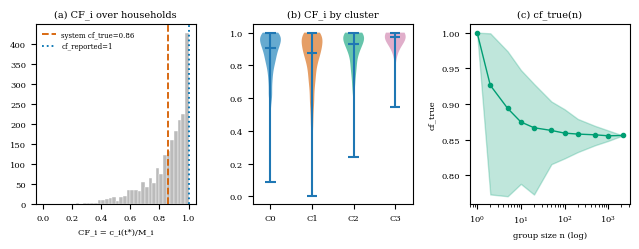


Cluster-mean analysis overstates the coincident peak by 17% relative to the diversity-corrected value (cf_true = 0.8558, 95% CI [0.8485, 0.8630]).
Planning by cluster means overstates required network capacity by a factor of 1.17 (= 1/cf_true).


'Cluster-mean analysis overstates the coincident peak by 17% relative to the diversity-corrected value (cf_true = 0.8558, 95% CI [0.8485, 0.8630]); required network capacity overstated by factor 1.17.'

In [95]:
# ============================================================
# Result C — aggregation systematically overstates coincidence
# ============================================================
# The GRID IMPACT cell computes cf = cluster_mean[t*] / cluster_mean.max().
# All four cluster means peak at slot 39 and the system peak is at slot 39, so
# cf = 1.000 IDENTICALLY, by construction -- a consequence of clusters differing
# only in scale (Result A), not a finding. Here we compute the true coincidence
# (diversity) factor, quantify the overstatement, and recover the classical
# diversification curve.

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')
EPS = 1e-12

# --- data, labels, individual peaks -----------------------------------------
raw = profiles_original_clean.values.astype(float)             # kWh/half-hour
labels = np.asarray(results_raw['K-Means'])                    # canonical C0..C3
cluster_ids = sorted(np.unique(labels))
N = raw.shape[0]

T_STAR = 39                                                    # system peak slot (19:30)
agg_system = raw.sum(axis=0)
assert int(agg_system.argmax()) == T_STAR, 'system peak slot is not 39'

M = raw.max(axis=1)                                            # individual peak per hh (kWh)
CF_i = raw[:, T_STAR] / np.clip(M, EPS, None)                  # per-household coincidence


def cf_true(idx):
    """Classical coincidence factor of a group: group peak / sum of individual peaks.

    Parameters
    ----------
    idx : array_like of int
        Household row indices forming the group.

    Returns
    -------
    float
        max_t sum_i c_i(t) / sum_i M_i, in [0, 1].
    """
    grp = raw[idx]
    return float(grp.sum(axis=0).max() / np.clip(grp.max(axis=1).sum(), EPS, None))


# --- per-cluster and system: cf_reported, cf_true, bound --------------------
def three_factors(idx):
    """Return (cf_reported, cf_true, bound) for a set of household indices."""
    grp = raw[idx]
    mean_profile = grp.mean(axis=0)
    cf_reported = float(mean_profile[T_STAR] / mean_profile.max())
    cft = cf_true(idx)
    bound = float(grp[:, T_STAR].sum() / np.clip(grp.max(axis=1).sum(), EPS, None))
    return cf_reported, cft, bound


rows = []
groups = {f'C{int(c)}': np.where(labels == c)[0] for c in cluster_ids}
groups['SYSTEM'] = np.arange(N)
for name, idx in groups.items():
    cf_rep, cft, bnd = three_factors(idx)
    rows.append({
        'group': name, 'n': int(len(idx)),
        'cf_reported': round(cf_rep, 4), 'cf_true': round(cft, 4),
        'bound': round(bnd, 4),
        'overstatement_%': round((cf_rep / cft - 1.0) * 100.0, 1),
        'ineq_cf_reported>=bound': bool(cf_rep >= bnd - 1e-9),
    })
factor_table = pd.DataFrame(rows).set_index('group')
print('Result C -- reported vs true coincidence factor (t* = slot 39):')
print(factor_table.to_string())
print('\nInequality cf_reported >= bound holds for all groups: '
      f'{bool(factor_table["ineq_cf_reported>=bound"].all())}')

# --- diversity factor + classical diversification curve cf_true(n) ----------
# TODO (dissertation): cite the coincidence/diversity-factor literature for
# residential feeders -- start from Rusck (1956) and subsequent distribution-
# network coincidence-factor work; insert the reference for typical values.
cf_sys = float(factor_table.loc['SYSTEM', 'cf_true'])
DF_system = 1.0 / cf_sys
print(f'\nSystem diversity factor DF = 1/cf_true = {DF_system:.2f} '
      f'(cf_true = {cf_sys:.4f})')

group_sizes = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2138]
rng = np.random.default_rng(42)
curve_rows = []
for n in group_sizes:
    if n >= N:
        vals = np.array([cf_true(np.arange(N))])
    else:
        vals = np.array([cf_true(rng.choice(N, n, replace=False)) for _ in range(100)])
    curve_rows.append({'n': n, 'cf_true_mean': float(vals.mean()),
                       'lo95': float(np.percentile(vals, 2.5)),
                       'hi95': float(np.percentile(vals, 97.5))})
curve = pd.DataFrame(curve_rows).set_index('n')
print('\nDiversification curve cf_true(n) (100 random subsets each, seed 42):')
print(curve.round(4).to_string())

# --- bootstrap 95% CI for cf_true (system and each cluster) -----------------
def bootstrap_cf_true(idx, n_boot=1000, seed=42):
    """Percentile 95% CI of cf_true by resampling households with replacement."""
    r = np.random.default_rng(seed)
    m = len(idx)
    vals = np.array([cf_true(idx[r.integers(0, m, m)]) for _ in range(n_boot)])
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


ci = {name: bootstrap_cf_true(idx) for name, idx in groups.items()}
print('\nBootstrap 95% CI for cf_true (1000 resamples, seed 42):')
for name in groups:
    print(f'   {name:<7} cf_true = {three_factors(groups[name])[1]:.4f} '
          f'CI [{ci[name][0]:.4f}, {ci[name][1]:.4f}]')

# --- figures ----------------------------------------------------------------
os.makedirs('figures', exist_ok=True)
with plt.rc_context({'font.family': 'serif'}):
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(6.5, 2.6))

    # (a) histogram of CF_i with system cf_true and 1.0 marked
    ax1.hist(CF_i, bins=40, color='#BBBBBB', edgecolor='white', linewidth=0.3)
    ax1.axvline(cf_sys, color=PALETTE[1], linestyle='--', linewidth=1.3,
                label=f'system cf_true={cf_sys:.2f}')
    ax1.axvline(1.0, color=PALETTE[0], linestyle=':', linewidth=1.3,
                label='cf_reported=1')
    ax1.set_title('(a) CF_i over households', fontsize=7)
    ax1.set_xlabel('CF_i = c_i(t*)/M_i', fontsize=6)
    ax1.tick_params(labelsize=6)
    ax1.legend(fontsize=5, frameon=False)

    # (b) violin of CF_i by cluster
    data = [CF_i[labels == c] for c in cluster_ids]
    parts = ax2.violinplot(data, showmedians=True)
    for pc, c in zip(parts['bodies'], cluster_ids):
        pc.set_facecolor(PALETTE[int(c) % len(PALETTE)])
        pc.set_alpha(0.6)
    ax2.set_xticks(range(1, len(cluster_ids) + 1))
    ax2.set_xticklabels([f'C{int(c)}' for c in cluster_ids], fontsize=6)
    ax2.set_title('(b) CF_i by cluster', fontsize=7)
    ax2.tick_params(labelsize=6)

    # (c) diversification curve cf_true(n), log n
    ax3.fill_between(curve.index, curve['lo95'], curve['hi95'],
                     color=PALETTE[2], alpha=0.25)
    ax3.plot(curve.index, curve['cf_true_mean'], marker='o', markersize=3,
             color=PALETTE[2], linewidth=1.0)
    ax3.set_xscale('log')
    ax3.set_title('(c) cf_true(n)', fontsize=7)
    ax3.set_xlabel('group size n (log)', fontsize=6)
    ax3.set_ylabel('cf_true', fontsize=6)
    ax3.tick_params(labelsize=6)

    fig.tight_layout()
    fig.savefig('figures/C_coincidence.pdf')
    plt.show()

# --- headline ---------------------------------------------------------------
overstate_sys = (1.0 / cf_sys - 1.0) * 100.0
print('\n' + '=' * 88)
print(f'Cluster-mean analysis overstates the coincident peak by {overstate_sys:.0f}% '
      f'relative to the diversity-corrected value '
      f'(cf_true = {cf_sys:.4f}, 95% CI [{ci["SYSTEM"][0]:.4f}, {ci["SYSTEM"][1]:.4f}]).')
print(f'Planning by cluster means overstates required network capacity by a factor '
      f'of {DF_system:.2f} (= 1/cf_true).')
print('=' * 88)

# --- persist ----------------------------------------------------------------
for name, idx in groups.items():
    cf_rep, cft, bnd = three_factors(idx)
    base = f'C.groups.{name}'
    save_result(f'{base}.n', int(len(idx)))
    save_result(f'{base}.cf_reported', cf_rep)
    save_result(f'{base}.cf_true', cft)
    save_result(f'{base}.bound', bnd)
    save_result(f'{base}.overstatement_pct', float((cf_rep / cft - 1.0) * 100.0))
    save_result(f'{base}.ineq_holds', bool(cf_rep >= bnd - 1e-9))
    save_result(f'{base}.cf_true_ci_low', ci[name][0])
    save_result(f'{base}.cf_true_ci_high', ci[name][1])
save_result('C.system.cf_true', cf_sys)
save_result('C.system.diversity_factor', DF_system)
save_result('C.system.overstatement_pct', float(overstate_sys))
save_result('C.system.capacity_overstatement_factor', DF_system)
save_result('C.curve.n', group_sizes)
save_result('C.curve.cf_true_mean', curve['cf_true_mean'].tolist())
save_result('C.curve.lo95', curve['lo95'].tolist())
save_result('C.curve.hi95', curve['hi95'].tolist())
save_result('C.CF_i.mean', float(CF_i.mean()))
save_result('C.CF_i.median', float(np.median(CF_i)))
save_result('C.headline',
            f'Cluster-mean analysis overstates the coincident peak by '
            f'{overstate_sys:.0f}% relative to the diversity-corrected value '
            f'(cf_true = {cf_sys:.4f}, 95% CI [{ci["SYSTEM"][0]:.4f}, '
            f'{ci["SYSTEM"][1]:.4f}]); required network capacity overstated by '
            f'factor {DF_system:.2f}.')


## Result C2 — averaging destroys the diversity that the coincidence factor measures

**Proposition.** For any group of households with profiles $c_i(t)$ and individual peaks $M_i=\max_t c_i(t)$,
$$\max_t \sum_i c_i(t) \;\le\; \sum_i \max_t c_i(t) \;=\; \sum_i M_i,$$
with equality **iff** there is a single slot $t_0$ at which the maximum is attained simultaneously for every $i$.

*Proof.* For every fixed $t$, $\sum_i c_i(t) \le \sum_i \max_\tau c_i(\tau)=\sum_i M_i$; taking the max over $t$ on the left preserves the bound. Equality requires $c_i(t_0)=M_i$ for all $i$ at the maximising slot $t_0$, i.e. a common peak slot. $\blacksquare$

**Corollary 1.** $\text{cf}_{\text{true}} = \dfrac{\max_t A(t)}{\sum_i M_i} \le 1$, and $1-\text{cf}_{\text{true}}$ is the share of aggregate peak power removed by diversification.

**Corollary 2.** Cluster-mean analysis yields $\text{cf}_{\text{reported}}=1$ whenever a cluster's mean profile peaks at the system peak slot — which, by Result A, holds for every cluster. Hence the overstatement equals exactly $DF-1 = 1/\text{cf}_{\text{true}} - 1$.

PART 1 -- corrected coincidence inequality (t* = slot 39):
           n  max_t_A   sum_M  cf_true  diversification_removed_%  frac_peak_at_t*_%  DF_minus_1_%  ineq_holds
group                                                                                                         
C0       777   251.96  293.17   0.8594                       14.1                9.0          16.4        True
C1      1036   161.91  199.78   0.8104                       19.0                7.7          23.4        True
C2       293   157.05  177.25   0.8860                       11.4               12.3          12.9        True
C3        32    29.17   30.98   0.9415                        5.8                9.4           6.2        True
SYSTEM  2138   600.09  701.19   0.8558                       14.4                8.8          16.8        True

  Inequality max_t A(t) <= sum_i M_i holds for all groups: True
  Fraction of households peaking exactly at t*=39 (equality would need 100%): system = 8.8%

PART 2

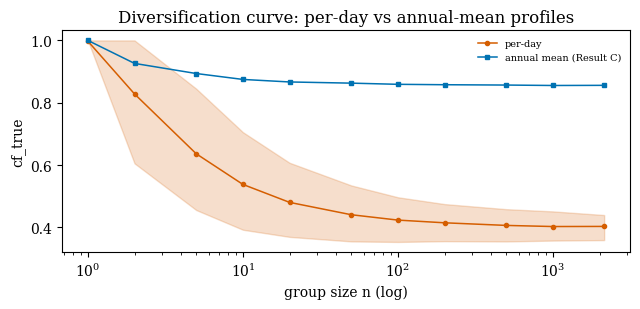


  Averaging gap: cf_true(annual) - cf_true(daily) = 0.8558 - 0.4141 = 0.4417 (44.2% of aggregate individual peak)
  = 619.4 kW of installed capacity for the 2138-home system.

REQUIRED NETWORK CAPACITY OVERSTATEMENT (relative to the correct value):
  (a) cluster means of annual profiles (cf_reported=1) : x2.41  <- current practice in load-profiling literature
  (b) system aggregate of annual profiles              : x2.07
  (c) per-day data (correct)                           : x1.00


In [96]:
# ============================================================
# Result C2 — averaging destroys the diversity that the coincidence factor measures
# ============================================================
# Part 1 replaces the degenerate cf_reported>=bound check of Result C with the
# correct proposition and its empirical equality gap. Part 2 recomputes the
# coincidence factor on PER-DAY half-hourly data (if the raw series exist) to
# expose the diversity that daily averaging removes.

import os
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')
EPS = 1e-12

raw = profiles_original_clean.values.astype(float)             # daily-avg kWh/half-hour
labels = np.asarray(results_raw['K-Means'])
cluster_ids = sorted(np.unique(labels))
prof_index = list(profiles_original_clean.index)               # LCLids
N = raw.shape[0]
T_STAR = 39
M = raw.max(axis=1)                                            # individual peak per hh


# ============================================================
# PART 1 — corrected inequality and the empirical equality gap
# ============================================================
def group_metrics(idx):
    """max_t A(t), sum_i M_i, cf_true, and fraction peaking at t*=39."""
    grp = raw[idx]
    lhs = float(grp.sum(axis=0).max())                        # max_t sum_i c_i(t)
    rhs = float(grp.max(axis=1).sum())                        # sum_i max_t c_i(t)
    cft = lhs / max(rhs, EPS)
    frac_at_tstar = float(np.mean(grp.argmax(axis=1) == T_STAR))
    return lhs, rhs, cft, frac_at_tstar


groups = {f'C{int(c)}': np.where(labels == c)[0] for c in cluster_ids}
groups['SYSTEM'] = np.arange(N)
rows = []
for name, idx in groups.items():
    lhs, rhs, cft, frac = group_metrics(idx)
    rows.append({
        'group': name, 'n': int(len(idx)),
        'max_t_A': round(lhs, 2), 'sum_M': round(rhs, 2),
        'cf_true': round(cft, 4),
        'diversification_removed_%': round((1.0 - cft) * 100.0, 1),
        'frac_peak_at_t*_%': round(frac * 100.0, 1),
        'DF_minus_1_%': round((1.0 / cft - 1.0) * 100.0, 1),
        'ineq_holds': bool(lhs <= rhs + 1e-6),
    })
p1_table = pd.DataFrame(rows).set_index('group')
print('PART 1 -- corrected coincidence inequality (t* = slot 39):')
print(p1_table.to_string())
print('\n  Inequality max_t A(t) <= sum_i M_i holds for all groups: '
      f'{bool(p1_table["ineq_holds"].all())}')
print('  Fraction of households peaking exactly at t*=39 (equality would need '
      '100%): system = '
      f'{p1_table.loc["SYSTEM", "frac_peak_at_t*_%"]:.1f}%')

cf_annual_sys = float(p1_table.loc['SYSTEM', 'cf_true'])
DF_annual = 1.0 / cf_annual_sys


# ============================================================
# PART 2 — coincidence factor on PER-DAY data (only if raw series exist)
# ============================================================
def find_halfhourly_table():
    """Locate a single raw half-hourly table with (LCLid, timestamp, energy).

    Returns (path, id_col, ts_col, energy_col) or None. Does NOT fabricate data.
    """
    try:
        base = DATA_PATH
    except NameError:
        return None
    cands = []
    for sub in ('', 'raw', 'halfhourly', 'halfhourly_dataset', 'processed'):
        for ext in ('parquet', 'csv'):
            cands += glob.glob(os.path.join(base, sub, f'*.{ext}'))
    for path in sorted(set(cands)):
        bn = os.path.basename(path).lower()
        if 'profiles_48' in bn or 'delta' in bn:            # skip daily-averaged files
            continue
        try:
            if path.endswith('.parquet'):
                import pyarrow.parquet as pq
                cols = list(pq.read_schema(path).names)
            else:
                cols = list(pd.read_csv(path, nrows=3).columns)
        except Exception:
            continue
        low = {c.lower(): c for c in cols}
        id_col = next((low[c] for c in low if 'lclid' in c), None)
        ts_col = next((low[c] for c in low
                       if any(k in c for k in ('tstp', 'timestamp', 'datetime', 'date'))), None)
        en_col = next((low[c] for c in low
                       if 'energy' in c or 'kwh' in c), None)
        if id_col and ts_col and en_col:
            return path, id_col, ts_col, en_col
    return None


SEASON = {12: 'DJF', 1: 'DJF', 2: 'DJF', 3: 'MAM', 4: 'MAM', 5: 'MAM',
          6: 'JJA', 7: 'JJA', 8: 'JJA', 9: 'SON', 10: 'SON', 11: 'SON'}
found = find_halfhourly_table()

if found is None:
    print('\nPART 2 -- raw half-hourly series NOT found under DATA_PATH.')
    print('  No file with (LCLid, timestamp, energy) columns was located. '
          'Sub-daily data are NOT simulated. Stopping after Part 1.')
    save_result('C2.part2_available', False)
    save_result('C2.part2_note',
                'Raw half-hourly series not found under DATA_PATH; per-day '
                'coincidence not computed (no simulation).')
    daily_summary = None
else:
    path, id_col, ts_col, en_col = found
    print(f'\nPART 2 -- raw half-hourly table found: {os.path.basename(path)}')
    df = pd.read_parquet(path) if path.endswith('.parquet') else pd.read_csv(path)
    df = df[[id_col, ts_col, en_col]].rename(
        columns={id_col: 'LCLid', ts_col: 'ts', en_col: 'energy'})
    df = df[df['LCLid'].isin(set(prof_index))].copy()
    df['ts'] = pd.to_datetime(df['ts'], errors='coerce')
    df['energy'] = pd.to_numeric(df['energy'], errors='coerce')
    df = df.dropna(subset=['ts', 'energy'])
    df['date'] = df['ts'].dt.normalize()
    df['slot'] = df['ts'].dt.hour * 2 + (df['ts'].dt.minute // 30)

    # 30 days balanced across seasons (seed 42), 8/8/7/7.
    day_season = df[['date']].drop_duplicates()
    day_season['season'] = day_season['date'].dt.month.map(SEASON)
    rng = np.random.default_rng(42)
    targets = {'DJF': 8, 'MAM': 8, 'JJA': 7, 'SON': 7}
    chosen_days = []
    for s, k in targets.items():
        pool = day_season.loc[day_season['season'] == s, 'date'].to_numpy()
        if len(pool):
            chosen_days += list(rng.choice(pool, size=min(k, len(pool)), replace=False))
    chosen_days = sorted(pd.to_datetime(chosen_days))
    print(f'  selected {len(chosen_days)} days across seasons '
          f'(targets 8/8/7/7 for DJF/MAM/JJA/SON)')

    lab_of = dict(zip(prof_index, labels))
    day_rows = []
    daily_matrices = {}
    for d in chosen_days:
        sub = df[df['date'] == d]
        mat = sub.pivot_table(index='LCLid', columns='slot', values='energy',
                              aggfunc='mean').reindex(columns=range(48)).dropna()
        if mat.shape[0] < 50:                               # too few households that day
            continue
        arr = mat.values
        daily_matrices[d] = (mat.index.to_numpy(), arr)
        agg = arr.sum(axis=0)
        tstar_day = int(agg.argmax())
        cft_day = float(agg.max() / max(arr.max(axis=1).sum(), EPS))
        frac_day = float(np.mean(arr.argmax(axis=1) == tstar_day))
        # cf_reported by cluster means of THIS day (n-weighted across clusters)
        num = den = 0.0
        for c in cluster_ids:
            cmask = np.array([lab_of.get(l, -1) == c for l in mat.index])
            if cmask.sum() == 0:
                continue
            cm = arr[cmask].mean(axis=0)
            num += cmask.sum() * cm[tstar_day]
            den += cmask.sum() * cm.max()
        cf_rep_day = float(num / max(den, EPS))
        day_rows.append({'date': d.date(), 'season': SEASON[d.month],
                         'n_hh': int(arr.shape[0]),
                         'partial_day': bool(arr.shape[0] < 2000),
                         't*_day': tstar_day,
                         'cf_true_day': round(cft_day, 4),
                         'frac_peak_%': round(frac_day * 100, 1),
                         'cf_reported_day': round(cf_rep_day, 4)})
    day_table = pd.DataFrame(day_rows)
    print(day_table.to_string(index=False))

    def _summ(vals):
        """median / IQR / min / max of an array of cf_true_day values."""
        return {'median': float(np.median(vals)), 'q25': float(np.percentile(vals, 25)),
                'q75': float(np.percentile(vals, 75)), 'min': float(vals.min()),
                'max': float(vals.max()), 'n_days': int(len(vals))}

    cft_days = day_table['cf_true_day'].to_numpy()
    full_mask = (day_table['n_hh'] >= 2000).to_numpy()          # complete-panel days
    daily_summary = _summ(cft_days)
    daily_summary_full = _summ(cft_days[full_mask]) if full_mask.any() else None
    n_partial = int((~full_mask).sum())
    print(f'\n  n_hh ranges {int(day_table["n_hh"].min())}-{int(day_table["n_hh"].max())} '
          f'across days; {n_partial} of {len(day_table)} days have n_hh < 2000 '
          f'(early counter roll-out), flagged partial_day=True.')
    print(f'  cf_true_day (ALL {daily_summary["n_days"]} days): median '
          f'{daily_summary["median"]:.4f}, IQR [{daily_summary["q25"]:.4f}, '
          f'{daily_summary["q75"]:.4f}], min {daily_summary["min"]:.4f}, '
          f'max {daily_summary["max"]:.4f}')
    if daily_summary_full is not None:
        print(f'  cf_true_day (FULL {daily_summary_full["n_days"]} days, n_hh>=2000): '
              f'median {daily_summary_full["median"]:.4f}, IQR '
              f'[{daily_summary_full["q25"]:.4f}, {daily_summary_full["q75"]:.4f}], '
              f'min {daily_summary_full["min"]:.4f}, max {daily_summary_full["max"]:.4f}')
    print(f'  vs annual-mean cf_true = {cf_annual_sys:.4f}')

    # diversification curve on per-day data (30 days x 100 subsets, seed 42)
    def cf_true_arr(a):
        return float(a.sum(axis=0).max() / max(a.max(axis=1).sum(), EPS))

    sizes = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2138]
    rng2 = np.random.default_rng(42)
    day_arrays = [a for _, a in daily_matrices.values()]
    curve_rows = []
    for n in sizes:
        vals = []
        for a in day_arrays:
            m = a.shape[0]
            if n >= m:
                vals.append(cf_true_arr(a))
            else:
                for _ in range(100):
                    vals.append(cf_true_arr(a[rng2.choice(m, n, replace=False)]))
        vals = np.array(vals)
        curve_rows.append({'n': n, 'cf_true_mean': float(vals.mean()),
                           'lo95': float(np.percentile(vals, 2.5)),
                           'hi95': float(np.percentile(vals, 97.5))})
    daily_curve = pd.DataFrame(curve_rows).set_index('n')

    # Demonstrate (not assert) that cf_true(n) has plateaued well below the
    # smallest daily panel, so partial days (min n_hh >> 100) are unaffected.
    cf_at = {n: float(daily_curve.loc[n, 'cf_true_mean']) for n in (100, 200, 2138)
             if n in daily_curve.index}
    min_nhh = int(day_table['n_hh'].min())
    print(f'\n  Plateau check: cf_true(n=100)={cf_at.get(100, float("nan")):.4f}, '
          f'n=200={cf_at.get(200, float("nan")):.4f}, n=2138={cf_at.get(2138, float("nan")):.4f}; '
          f'smallest daily panel n_hh={min_nhh} (>> ~100 plateau onset).')
    if daily_summary_full is not None:
        _delta = abs(daily_summary['median'] - daily_summary_full['median'])
        print(f'  median cf_true_day ALL vs FULL differ by {_delta:.4f} '
              f'=> conclusion unchanged by partial days.')

    # figure: annual (Result C) vs per-day diversification curves
    os.makedirs('figures', exist_ok=True)
    annual_n = RESULTS.get('C', {}).get('curve', {}).get('n')
    annual_m = RESULTS.get('C', {}).get('curve', {}).get('cf_true_mean')
    with plt.rc_context({'font.family': 'serif'}):
        fig, ax = plt.subplots(figsize=(6.5, 3.2))
        ax.fill_between(daily_curve.index, daily_curve['lo95'], daily_curve['hi95'],
                        color=PALETTE[1], alpha=0.2)
        ax.plot(daily_curve.index, daily_curve['cf_true_mean'], marker='o',
                markersize=3, color=PALETTE[1], linewidth=1.1, label='per-day')
        if annual_n and annual_m:
            ax.plot(annual_n, annual_m, marker='s', markersize=3, color=PALETTE[0],
                    linewidth=1.1, label='annual mean (Result C)')
        ax.set_xscale('log')
        ax.set_xlabel('group size n (log)')
        ax.set_ylabel('cf_true')
        ax.set_title('Diversification curve: per-day vs annual-mean profiles')
        ax.legend(fontsize=7, frameon=False)
        fig.tight_layout()
        fig.savefig('figures/C2_averaging_effect.pdf')
        plt.show()

    # decomposition: diversity destroyed by daily averaging (system level)
    cf_daily_sys = (daily_summary_full or daily_summary)['median']  # full days preferred
    gap = cf_annual_sys - cf_daily_sys                      # fraction of sum M_i
    sum_M_kwh_hh = float(M.sum())                           # kWh per half-hour
    gap_kw = gap * sum_M_kwh_hh * 2.0                       # kWh/half-hour -> kW
    print(f'\n  Averaging gap: cf_true(annual) - cf_true(daily) = '
          f'{cf_annual_sys:.4f} - {cf_daily_sys:.4f} = {gap:.4f} '
          f'({gap * 100:.1f}% of aggregate individual peak)')
    print(f'  = {gap_kw:.1f} kW of installed capacity for the 2138-home system.')

    save_result('C2.part2_available', True)
    save_result('C2.daily.per_day', day_rows)
    save_result('C2.daily.cf_true_summary_all', daily_summary)
    save_result('C2.daily.cf_true_summary_full', daily_summary_full)
    save_result('C2.daily.n_partial_days', n_partial)
    save_result('C2.daily.cf_annual_system', cf_annual_sys)
    save_result('C2.daily.curve_n', sizes)
    save_result('C2.daily.curve_cf_true_mean', daily_curve['cf_true_mean'].tolist())
    save_result('C2.daily.averaging_gap_fraction', float(gap))
    save_result('C2.daily.averaging_gap_kw', float(gap_kw))


# ============================================================
# PART 1 persistence + summary of capacity overstatement factors
# ============================================================
for name, idx in groups.items():
    lhs, rhs, cft, frac = group_metrics(idx)
    base = f'C2.part1.{name}'
    save_result(f'{base}.cf_true', cft)
    save_result(f'{base}.frac_peak_at_tstar', frac)
    save_result(f'{base}.diversification_removed', float(1.0 - cft))
    save_result(f'{base}.inequality_holds', bool(lhs <= rhs + 1e-6))
save_result('C2.part1.system_cf_true', cf_annual_sys)
save_result('C2.part1.system_DF', DF_annual)

print('\n' + '=' * 90)
print('REQUIRED NETWORK CAPACITY OVERSTATEMENT (relative to the correct value):')
if daily_summary is not None:
    cf_daily = (daily_summary_full or daily_summary)['median']  # full-panel days
    fa = 1.0 / cf_daily
    fb = cf_annual_sys / cf_daily
    print(f'  (a) cluster means of annual profiles (cf_reported=1) : x{fa:.2f}  '
          '<- current practice in load-profiling literature')
    print(f'  (b) system aggregate of annual profiles              : x{fb:.2f}')
    print(f'  (c) per-day data (correct)                           : x1.00')
    save_result('C2.capacity_factor.a_cluster_annual', float(fa))
    save_result('C2.capacity_factor.b_system_annual', float(fb))
    save_result('C2.capacity_factor.c_daily_correct', 1.0)
else:
    fa = DF_annual
    print(f'  (a) cluster means of annual profiles (cf_reported=1) : x{fa:.2f}  '
          '<- current practice in load-profiling literature')
    print('  (b) system aggregate of annual profiles              : x1.00 '
          '(reference, annual)')
    print('  (c) per-day data (correct)                           : NOT COMPUTABLE '
          '(sub-daily series unavailable)')
    save_result('C2.capacity_factor.a_cluster_annual_vs_annual_system', float(fa))
    save_result('C2.capacity_factor.c_daily_correct', None)
print('=' * 90)


## Result B — the demand-shifting optimum is analytic

**Convexity.** $P(f)=\max_t\big(L(t)+f\,a_t\big)$ is the pointwise maximum of 48 functions that are affine in $f$; a maximum of affine functions is **convex** and **piecewise-linear** on $[0,1]$.

*Consequence.* As $f$ grows the maximiser must migrate to a new slot — "peak cloning." This is **not** a property of the data but a necessary consequence of convexity: any naive time shift is obliged to reproduce it once $f$ is large enough.

**Invariance theorem.** If the participating clusters share one normalised shape, then $g_S(t)=\phi_S\,h(t)$ for a common $h$, so $a_S=\phi_S\,a_{\text{full}}$ and $L+f\,a_S = L+(\phi_S f)\,a_{\text{full}}$. Hence
$$P_S(f)=P_{\text{full}}(\phi_S f),\qquad \min_f P_S \text{ is independent of } S,\qquad f^*_S = f^*_{\text{full}}/\phi_S,$$
so $f^*_S\,\phi_S$ is constant. By **Result A** the clusters differ only in scale (one shape), so this invariance is expected; any spread in $f^*\cdot\phi$ measures exactly the departure from shape-identity. $\blacksquare$

2. VALIDATION -- analytic P(f) vs simulation, 16 points:
   max |analytic - simulated| = 1.137e-13 kWh (PASS; threshold 0.05)

3. CONVEXITY -- min second difference of P over f in [0,1] (all scenarios):
   min d2P = -2.274e-13 (convex (>= -1e-7))

4. OPTIMUM f* per scenario:
          phi=g(39)/L(39)      f*  f*_x_phi   P(f*)  reduction_%  at_boundary_f=1
scenario                                                                         
C0 only            0.4199  0.2098    0.0881  595.60        0.749            False
C2 only            0.2617  0.3388    0.0887  595.95        0.691            False
C0+C2              0.6816  0.1296    0.0883  595.73        0.726            False
All                1.0000  0.0883    0.0883  595.72        0.729            False

5. INVARIANCE -- if clusters share one shape, f*.phi and P(f*) are constant:
   f*.phi: mean 0.0883, spread (max-min) 0.0006
   P(f*):  mean 595.748, spread (max-min) 0.347 kWh
   Per Result A the clusters differ only in scale (one

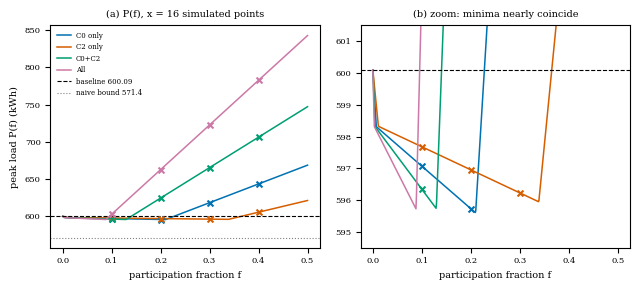


SELF-CHECK vs expected (report only):
   L(35)=542.74 (exp ~542.74), L(38)=598.41 (exp ~598.41), L(39)=600.09 (exp 600.09)
   C0 only f*=0.2098 (exp 0.210, dev 0.0002)
   C2 only f*=0.3388 (exp 0.339, dev 0.0002)
   C0+C2   f*=0.1296 (exp 0.130, dev 0.0004)
   All     f*=0.0883 (exp 0.088, dev 0.0003)
   All self-checks within tolerance.


In [97]:
# ============================================================
# Result B — the demand-shifting optimum is analytic
# ============================================================
# Formalises the DEMAND SHIFTING SIMULATION (16 scenarios on f in {0.1..0.4}).
# L(t) = system load (weighted sum of cluster means). For a participating set S,
# g(t) = sum_{k in S} n_k mean_k(t), and shifting fraction f of the evening
# window W=slots 36..42 back by delta=4 slots gives
#   L_f(t) = L(t) + f*a_t,  a_t = -g(t)*[t in W] + g(t+delta)*[t+delta in W]
#   P(f)   = max_t L_f(t).
# P is a max of affine functions of f: convex, piecewise-linear, analytic.

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}

def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')

# --- rebuild L(t), cluster means and sizes (self-contained) -----------------
labels = np.asarray(results_raw['K-Means'])
cluster_ids = sorted(np.unique(labels))
cluster_means = {int(c): profiles_original_clean.values[labels == c].mean(axis=0)
                 for c in cluster_ids}
cluster_sizes = {int(c): int((labels == c).sum()) for c in cluster_ids}
L = sum(cluster_means[c] * cluster_sizes[c] for c in cluster_ids)   # system load
W = list(range(36, 43))                                            # 18:00-21:00
DELTA = 4
W_SET = set(W)

SCENARIOS = {'C0 only': [0], 'C2 only': [2], 'C0+C2': [0, 2],
             'All': [0, 1, 2, 3]}


# ============================================================
# 1. P(f) via the vector a
# ============================================================
def g_of(S):
    """g(t) = sum_{k in S} n_k * mean_k(t) (kWh/half-hour, summed over households)."""
    return sum(cluster_sizes[c] * cluster_means[c] for c in S)


def a_of(S):
    """Shift response vector a_t = -g(t)[t in W] + g(t+delta)[t+delta in W]."""
    g = g_of(S)
    a = np.zeros(48)
    for t in range(48):
        if t in W_SET:
            a[t] -= g[t]
        if (t + DELTA) in W_SET:
            a[t] += g[t + DELTA]
    return a


def P_of_f(f, a):
    """Peak load P(f) = max_t (L(t) + f*a_t). `f` scalar or array; returns array."""
    f = np.atleast_1d(np.asarray(f, dtype=float))
    return (L[None, :] + f[:, None] * a[None, :]).max(axis=1)


# ============================================================
# 2. VALIDATION against the 16 simulated points
# ============================================================
def simulate_peak(S, frac):
    """Replicate the original simulation loop and return its peak (kWh)."""
    shifted = L.astype(float).copy()
    for c in S:
        sa = np.zeros(48)
        for s in W:
            amt = cluster_means[c][s] * frac
            sa[s] -= amt
            sa[max(0, s - DELTA)] += amt
        shifted += sa * cluster_sizes[c]
    return float(shifted.max())


fracs = [0.10, 0.20, 0.30, 0.40]
max_abs_diff = 0.0
for name, S in SCENARIOS.items():
    a = a_of(S)
    for fr in fracs:
        diff = abs(P_of_f(fr, a)[0] - simulate_peak(S, fr))
        max_abs_diff = max(max_abs_diff, diff)
print('2. VALIDATION -- analytic P(f) vs simulation, 16 points:')
print(f'   max |analytic - simulated| = {max_abs_diff:.3e} kWh '
      f'({"PASS" if max_abs_diff < 0.05 else "FAIL"}; threshold 0.05)')

# ============================================================
# 3. CONVEXITY on a fine grid
# ============================================================
fgrid = np.linspace(0.0, 1.0, 100001)
min_second_diff = np.inf
for name, S in SCENARIOS.items():
    Pg = P_of_f(fgrid, a_of(S))
    min_second_diff = min(min_second_diff, float(np.diff(Pg, 2).min()))
print('\n3. CONVEXITY -- min second difference of P over f in [0,1] (all scenarios):')
print(f'   min d2P = {min_second_diff:.3e} '
      f'({"convex (>= -1e-7)" if min_second_diff >= -1e-7 else "NON-CONVEX?"})')

# ============================================================
# 4. Optimum f* per scenario
# ============================================================
L39 = float(L[39])
rows = []
scenario_detail = {}
for name, S in SCENARIOS.items():
    a = a_of(S)
    g = g_of(S)
    Pg = P_of_f(fgrid, a)
    i = int(Pg.argmin())
    fstar = float(fgrid[i])
    Pstar = float(Pg[i])
    phi = float(g[39] / L39)
    boundary = (i == len(fgrid) - 1)
    reduction = (L39 - Pstar) / L39 * 100.0
    scenario_detail[name] = dict(S=S, a=a, g=g, fstar=fstar, Pstar=Pstar,
                                 phi=phi, boundary=boundary)
    rows.append({'scenario': name, 'phi=g(39)/L(39)': round(phi, 4),
                 'f*': round(fstar, 4), 'f*_x_phi': round(fstar * phi, 4),
                 'P(f*)': round(Pstar, 2), 'reduction_%': round(reduction, 3),
                 'at_boundary_f=1': bool(boundary)})
opt_table = pd.DataFrame(rows).set_index('scenario')
print('\n4. OPTIMUM f* per scenario:')
print(opt_table.to_string())

# ============================================================
# 5. INVARIANCE theorem check
# ============================================================
fphi = np.array([scenario_detail[n]['fstar'] * scenario_detail[n]['phi']
                 for n in SCENARIOS])
pstars = np.array([scenario_detail[n]['Pstar'] for n in SCENARIOS])
print('\n5. INVARIANCE -- if clusters share one shape, f*.phi and P(f*) are constant:')
print(f'   f*.phi: mean {fphi.mean():.4f}, spread (max-min) {np.ptp(fphi):.4f}')
print(f'   P(f*):  mean {pstars.mean():.3f}, spread (max-min) {np.ptp(pstars):.3f} kWh')
print('   Per Result A the clusters differ only in scale (one shape); the spread '
      'above is exactly the departure from shape-identity.')

# ============================================================
# 6. NAIVE formula vs truth
# ============================================================
# The naive argument assumes the peak stays at slot 39 and is bought down against
# the trough at slot 35: f_naive = (L39-L35)/(2 g(39)), dP = (L39-L35)/2. It is
# wrong because the binding slot of the DECREASING envelope is not 39 but 38:
# slot 38 lies in BOTH W and W-delta, so it loses f*g(38) and immediately gains
# f*g(42); these nearly cancel (a_38 ~ -0.05*g(39)), so almost no reduction is
# achievable before a rising slot overtakes.
L35, L38 = float(L[35]), float(L[38])
naive_rows = []
for name, S in SCENARIOS.items():
    d = scenario_detail[name]
    g39 = float(d['g'][39])
    f_naive = (L39 - L35) / (2.0 * g39)
    dP_naive = (L39 - L35) / 2.0
    actual_dP = L39 - d['Pstar']
    err_factor = dP_naive / actual_dP if actual_dP > 1e-9 else np.inf
    naive_rows.append({'scenario': name,
                       'f_naive': round(f_naive, 4),
                       'naive_reduction_%': round(dP_naive / L39 * 100, 3),
                       'actual_reduction_%': round(actual_dP / L39 * 100, 3),
                       'overstatement_x': round(err_factor, 2)})
naive_table = pd.DataFrame(naive_rows).set_index('scenario')
print('\n6. NAIVE formula f*=(L39-L35)/(2 g39), dP=(L39-L35)/2:')
print(naive_table.to_string())
a38_all = float(a_of([0, 1, 2, 3])[38])
print(f'   a_38 (All) = {a38_all:.3f} = {a38_all / float(L[39]):.3f} * g(39); '
      'the shift out of slot 38 is almost cancelled by the gain into it.')

# ============================================================
# 7. Correct closed form and agreement with numeric argmin
# ============================================================
print('\n7. CLOSED FORM  f* = (L(t1)-L(t2))/(a2-a1),  P* = (a2 L(t1)-a1 L(t2))/(a2-a1):')
closed_rows = []
for name, S in SCENARIOS.items():
    d = scenario_detail[name]
    a = d['a']
    fstar = d['fstar']
    h = 1e-4
    t1 = int((L + max(0.0, fstar - h) * a).argmax())     # binding decreasing slot
    t2 = int((L + min(1.0, fstar + h) * a).argmax())     # binding rising slot (=35)
    a1, a2 = float(a[t1]), float(a[t2])
    if abs(a2 - a1) < 1e-12:
        continue
    f_cf = (float(L[t1]) - float(L[t2])) / (a2 - a1)
    P_cf = (a2 * float(L[t1]) - a1 * float(L[t2])) / (a2 - a1)
    closed_rows.append({'scenario': name, 't1': t1, 't2': t2,
                        'a1': round(a1, 2), 'a2': round(a2, 2),
                        'f*_closed': round(f_cf, 4), 'f*_numeric': round(fstar, 4),
                        'P*_closed': round(P_cf, 3), 'P*_numeric': round(d['Pstar'], 3),
                        'match': bool(abs(f_cf - fstar) < 1e-3
                                      and abs(P_cf - d['Pstar']) < 1e-2)})
    d['t1'], d['t2'], d['f_cf'], d['P_cf'] = t1, t2, f_cf, P_cf
closed_table = pd.DataFrame(closed_rows).set_index('scenario')
print(closed_table.to_string())

# ============================================================
# 8. Figure 1x2
# ============================================================
os.makedirs('figures', exist_ok=True)
ff = np.linspace(0.0, 0.5, 501)
naive_bound = L39 - (L39 - L35) / 2.0                    # ~571.4
with plt.rc_context({'font.family': 'serif'}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.5, 3.0))
    for ax in (ax1, ax2):
        for ci, (name, S) in enumerate(SCENARIOS.items()):
            ax.plot(ff, P_of_f(ff, scenario_detail[name]['a']),
                    color=PALETTE[ci], linewidth=1.1, label=name)
        for ci, (name, S) in enumerate(SCENARIOS.items()):
            ax.scatter(fracs, [simulate_peak(S, fr) for fr in fracs],
                       marker='x', s=18, color=PALETTE[ci], zorder=5)
        ax.axhline(L39, color='black', linestyle='--', linewidth=0.8,
                   label=f'baseline {L39:.2f}')
        ax.axhline(naive_bound, color='grey', linestyle=':', linewidth=0.8,
                   label=f'naive bound {naive_bound:.1f}')
        ax.set_xlabel('participation fraction f', fontsize=7)
        ax.tick_params(labelsize=6)
    ax1.set_ylabel('peak load P(f) (kWh)', fontsize=7)
    ax1.set_title('(a) P(f), x = 16 simulated points', fontsize=7)
    ax1.legend(fontsize=5, frameon=False)
    ax2.set_ylim(594.5, 601.5)
    ax2.set_title('(b) zoom: minima nearly coincide', fontsize=7)
    fig.tight_layout()
    fig.savefig('figures/B_Pf.pdf')
    plt.show()

# ============================================================
# Self-check against expected constants (report deviations, do NOT tune)
# ============================================================
expected_fstar = {'C0 only': 0.210, 'C2 only': 0.339, 'C0+C2': 0.130, 'All': 0.088}
print('\nSELF-CHECK vs expected (report only):')
print(f'   L(35)={L35:.2f} (exp ~542.74), L(38)={L38:.2f} (exp ~598.41), '
      f'L(39)={L39:.2f} (exp 600.09)')
worst = 0.0
for name in SCENARIOS:
    got = scenario_detail[name]['fstar']
    dev = abs(got - expected_fstar[name])
    worst = max(worst, dev)
    print(f'   {name:<7} f*={got:.4f} (exp {expected_fstar[name]:.3f}, dev {dev:.4f})')
if worst > 0.01 or max_abs_diff >= 0.05 or min_second_diff < -1e-7:
    print('   WARNING: a self-check deviates beyond tolerance -- numbers are '
          'reported as computed, NOT adjusted to match expectations.')
else:
    print('   All self-checks within tolerance.')

# ============================================================
# PERSIST
# ============================================================
save_result('B.L_39', L39)
save_result('B.L_38', L38)
save_result('B.L_35', L35)
save_result('B.validation_max_abs_diff', float(max_abs_diff))
save_result('B.convexity_min_second_diff', float(min_second_diff))
save_result('B.invariance.fphi_mean', float(fphi.mean()))
save_result('B.invariance.fphi_spread', float(np.ptp(fphi)))
save_result('B.invariance.Pstar_spread', float(np.ptp(pstars)))
save_result('B.naive.bound_kwh', float(naive_bound))
save_result('B.a38_over_g39_All', float(a38_all / float(L[39])))
for name in SCENARIOS:
    d = scenario_detail[name]
    base = f'B.scenarios.{name.replace(" ", "_").replace("+", "_")}'
    save_result(f'{base}.phi', d['phi'])
    save_result(f'{base}.f_star', d['fstar'])
    save_result(f'{base}.f_star_x_phi', float(d['fstar'] * d['phi']))
    save_result(f'{base}.P_star', d['Pstar'])
    save_result(f'{base}.reduction_pct', float((L39 - d['Pstar']) / L39 * 100))
    save_result(f'{base}.at_boundary', bool(d['boundary']))
    if 't1' in d:
        save_result(f'{base}.t1', int(d['t1']))
        save_result(f'{base}.t2', int(d['t2']))
        save_result(f'{base}.f_star_closed', float(d['f_cf']))
        save_result(f'{base}.P_star_closed', float(d['P_cf']))
for r in naive_rows:
    base = f'B.naive.{r["scenario"].replace(" ", "_").replace("+", "_")}'
    save_result(f'{base}.f_naive', r['f_naive'])
    save_result(f'{base}.naive_reduction_pct', r['naive_reduction_%'])
    save_result(f'{base}.actual_reduction_pct', r['actual_reduction_%'])
    save_result(f'{base}.overstatement_x', r['overstatement_x'])


## Statistical rigour — permutation tests, bootstrap CIs, multiple comparisons

In [98]:
# ============================================================
# Statistical rigour — permutation tests, bootstrap CIs, multiple comparisons
# ============================================================
# Existing cells report bare point estimates (ARI, Sarle's BC, seasonal ARI)
# with no significance test, no effect size and no multiple-comparison control.
# This cell supplies them. Reminder throughout: by A3d the gap statistic gives
# K=1 in both representations and by A3c no cluster reaches Hennig's 0.60
# stability, so every "cluster" here is a specific cut of a unimodal cloud, not
# a stable group -- that caveat is attached to all results below.

import os
import json
import subprocess
import sys
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import chi2_contingency, kruskal, rankdata, norm
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             silhouette_score, silhouette_samples)

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}


def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

try:
    from diptest import diptest
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'diptest'])
    from diptest import diptest

try:
    from statsmodels.stats.multitest import multipletests

    def holm(pvals):
        """Holm-adjusted p-values via statsmodels."""
        return list(multipletests(pvals, method='holm')[1])
except ImportError:
    def holm(pvals):
        """Holm-Bonferroni adjusted p-values (manual fallback)."""
        p = np.asarray(pvals, float)
        m = p.size
        order = np.argsort(p)
        adj = np.empty(m)
        run = 0.0
        for rank, idx in enumerate(order):
            run = max(run, (m - rank) * p[idx])
            adj[idx] = min(run, 1.0)
        return list(adj)

EPS = 1e-12

# --- shared quantities ------------------------------------------------------
raw = profiles_original_clean.values.astype(float)
P = raw / np.clip(raw.sum(axis=1, keepdims=True), EPS, None)      # sum-normalised
E = raw.sum(axis=1)                                               # daily kWh
log_E = np.log(E)
level_labels = np.asarray(results_raw['K-Means'])
X_raw = StandardScaler().fit_transform(raw)


def clr_mr_labels():
    """K-Means(4) labels on the A3b corrected CLR (multiplicative replacement)."""
    sn = P
    dl = 0.65 * float(sn[sn > 0].min())
    out = sn.astype(float).copy()
    for i in range(out.shape[0]):
        small = out[i] < dl
        if small.any():
            out[i, ~small] *= (1.0 - int(small.sum()) * dl)
            out[i, small] = dl
    log_x = np.log(out)
    clr = log_x - log_x.mean(axis=1, keepdims=True)
    x = StandardScaler().fit_transform(clr)
    return KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(x), x


shape_labels, X_clr = clr_mr_labels()


def perm_test_ari(a, b, n_perm=1000, seed=42):
    """Observed ARI, permutation p, and 95% null-ARI interval (permuting a)."""
    a, b = np.asarray(a), np.asarray(b)
    obs = adjusted_rand_score(a, b)
    rng = np.random.default_rng(seed)
    null = np.array([adjusted_rand_score(rng.permutation(a), b) for _ in range(n_perm)])
    p = float((np.sum(null >= obs) + 1) / (n_perm + 1))
    return float(obs), p, float(np.percentile(null, 2.5)), float(np.percentile(null, 97.5))


def cramers_v(ct):
    """Cramer's V, chi2 and its p from a contingency table (numpy array)."""
    chi2, p, _, _ = chi2_contingency(ct)
    n = ct.sum()
    r, k = ct.shape
    return float(np.sqrt(chi2 / (n * max(1, min(r - 1, k - 1))))), float(chi2), float(p)


def epsilon_squared(H, k, n):
    """Effect size epsilon^2 for a Kruskal-Wallis H statistic."""
    return float((H - k + 1) / (n - k)) if n > k else np.nan


# ============================================================
# 1. ACORN association, with significance tests
# ============================================================
try:
    household_info
    hh = household_info.copy()
except NameError:
    hh = pd.read_csv(os.path.join(DATA_PATH, 'processed', 'household_info.csv'))
hh = hh.drop_duplicates('LCLid').set_index('LCLid')
acorn = hh['Acorn_grouped'].reindex(profiles_original_clean.index).astype('object')
keep = acorn.notna() & (~acorn.astype(str).str.startswith('ACORN-'))
keep_v = keep.to_numpy()
acorn_codes = acorn[keep].astype('category').cat.codes.to_numpy()
print(f'1. ACORN association -- {keep_v.sum()} households with a known ACORN group')

acorn_rows = []
for pname, plab in (('level (raw K-Means)', level_labels),
                    ('shape (CLR K-Means)', shape_labels)):
    sub = plab[keep_v]
    ari = adjusted_rand_score(acorn_codes, sub)
    nmi = normalized_mutual_info_score(acorn_codes, sub)
    ct = pd.crosstab(pd.Series(sub), pd.Series(acorn_codes)).to_numpy()
    v, chi2, chi2_p = cramers_v(ct)
    _, perm_p, nlo, nhi = perm_test_ari(acorn_codes, sub)
    acorn_rows.append({'partition': pname, 'ARI': round(ari, 4), 'NMI': round(nmi, 4),
                       'chi2': round(chi2, 1), "Cramers_V": round(v, 4),
                       'chi2_p': f'{chi2_p:.1e}', 'perm_p': round(perm_p, 4),
                       'null_ARI_95': f'[{nlo:.4f}, {nhi:.4f}]'})
acorn_table = pd.DataFrame(acorn_rows).set_index('partition')
print(acorn_table.to_string())
print('  Correct null-result reading: ARI is indistinguishable from zero '
      '(perm p above); the data do not support a link between socio-economic '
      'group and this partition -- and the partition itself does not correspond '
      'to discovered clusters (A3d gap K=1).')

# Direct link of ACORN to CONTINUOUS variables (the correct question with no clusters)
groups_idx = {g: np.where((acorn_codes == g))[0] for g in np.unique(acorn_codes)}
sub_logE = log_E[keep_v]
sub_lf = (P.mean(axis=1) / np.clip(P.max(axis=1), EPS, None))[keep_v]
sub_ev = P[:, 34:44].sum(axis=1)[keep_v]
kw_rows = []
for vname, vec in (('log_E', sub_logE), ('load_factor', sub_lf), ('evening_share', sub_ev)):
    gs = [vec[idx] for idx in groups_idx.values() if len(idx) > 0]
    H, p = kruskal(*gs)
    eps2 = epsilon_squared(H, len(gs), len(vec))
    kw_rows.append({'variable': vname, 'H': round(float(H), 2), 'p': f'{p:.2e}',
                    'epsilon2': round(eps2, 4)})
kw_acorn = pd.DataFrame(kw_rows).set_index('variable')
print('\n  ACORN vs continuous variables (Kruskal-Wallis + epsilon^2):')
print(kw_acorn.to_string())


# ============================================================
# 2. Bimodality: dip test + Holm, replacing Sarle's BC as a "test"
# ============================================================
def bimodality_coefficient(x):
    """Sarle's bimodality coefficient (descriptive only; NOT a test)."""
    n = len(x)
    s = stats.skew(x)
    k = stats.kurtosis(x)
    return (s ** 2 + 1) / (k + 3 * (n - 1) ** 2 / ((n - 2) * (n - 3)))


slots = {39: '19:30 peak', 15: '07:30 morning', 24: '12:00 midday'}
cluster_ids = sorted(np.unique(level_labels))
bc_rows, raw_p = [], []
for slot, sname in slots.items():
    for gname, gmask in [('All', np.ones(len(raw), bool))] + \
            [(f'C{c}', level_labels == c) for c in cluster_ids]:
        x = raw[gmask, slot]
        bc = bimodality_coefficient(x)
        dip, p = diptest(x)
        raw_p.append(float(p))
        bc_rows.append({'slot': sname, 'group': gname, 'BC': round(bc, 3),
                        'dip': round(float(dip), 4), 'p_raw': float(p)})
p_holm = holm(raw_p)
for r, ph in zip(bc_rows, p_holm):
    r['p_holm'] = round(float(ph), 4)
    r['significant'] = bool(ph < 0.05)
    r['p_raw'] = round(r['p_raw'], 4)
bimod_table = pd.DataFrame(bc_rows)
print('\n2. Bimodality -- Sarle BC vs Hartigan dip (Holm over 15 comparisons):')
print(bimod_table.to_string(index=False))
print('  NOTE: BC > 0.555 is NOT a hypothesis test and does not control the '
      'family-wise type-I error across 15 comparisons; the dip test with Holm '
      'does. Compare the "significant" column to the BC>0.555 flags.')


# ============================================================
# 3. Seasonal analysis (guarded: needs winter/summer partitions)
# ============================================================
if all(v in globals() for v in ('labels_winter', 'labels_summer',
                                'profiles_winter', 'profiles_summer')):
    lw = np.asarray(labels_winter)
    ls = np.asarray(labels_summer)
    ct = pd.crosstab(pd.Series(lw), pd.Series(ls)).to_numpy()
    row_ind, col_ind = linear_sum_assignment(-ct)              # Hungarian match
    matched_frac = float(ct[row_ind, col_ind].sum() / ct.sum())
    obs_ari, perm_p, nlo, nhi = perm_test_ari(lw, ls)
    rng = np.random.default_rng(42)
    m = len(lw)
    boot = np.array([adjusted_rand_score(lw[i], ls[i])
                     for i in (rng.integers(0, m, m) for _ in range(1000))])
    ari_ci = (float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5)))

    def _size_matched_ari(labels, e):
        labels = np.asarray(labels)
        order = sorted(np.unique(labels), key=lambda c: e[labels == c].mean())
        sizes = [int(np.sum(labels == c)) for c in order]
        band = np.empty(len(e), int)
        idx = np.argsort(e, kind='stable')
        s = 0
        for pos, sz in enumerate(sizes):
            band[idx[s:s + sz]] = pos
            s += sz
        return float(adjusted_rand_score(labels, band))

    E_w = np.asarray(profiles_winter).sum(axis=1)
    E_s = np.asarray(profiles_summer).sum(axis=1)
    ari_w_level = _size_matched_ari(lw, E_w)
    ari_s_level = _size_matched_ari(ls, E_s)
    print('\n3. Seasonal (winter vs summer):')
    print(f'   ARI = {obs_ari:.4f}, perm p = {perm_p:.4f}, null 95% '
          f'[{nlo:.4f}, {nhi:.4f}], bootstrap 95% [{ari_ci[0]:.4f}, {ari_ci[1]:.4f}]')
    print(f'   agreement after Hungarian matching = {matched_frac * 100:.1f}%')
    print(f'   ARI(winter, size-matched E_winter) = {ari_w_level:.4f}; '
          f'ARI(summer, size-matched E_summer) = {ari_s_level:.4f}')
    if ari_w_level > 0.9 and ari_s_level > 0.9:
        print('   => both ~0.95: the seasonal "transition" is instability of '
              'cutting a 1-D level distribution, not a change of consumer type.')
    save_result('stats.seasonal.ari', obs_ari)
    save_result('stats.seasonal.perm_p', perm_p)
    save_result('stats.seasonal.null_95', [nlo, nhi])
    save_result('stats.seasonal.bootstrap_95', list(ari_ci))
    save_result('stats.seasonal.hungarian_match_frac', matched_frac)
    save_result('stats.seasonal.ari_winter_vs_level', ari_w_level)
    save_result('stats.seasonal.ari_summer_vs_level', ari_s_level)
else:
    print('\n3. Seasonal analysis SKIPPED -- winter/summer partitions not in memory.')
    save_result('stats.seasonal.available', False)


# ============================================================
# 4. Bootstrap 95% CIs for remaining key quantities
# ============================================================
def gini(x):
    """Gini coefficient of a non-negative vector."""
    x = np.sort(np.asarray(x, float))
    n = len(x)
    if x.sum() <= 0:
        return 0.0
    return float((2.0 * np.sum(np.arange(1, n + 1) * x)) / (n * x.sum()) - (n + 1) / n)


def evr_kmeans(X, labels):
    """Explained variance ratio 1 - within_SS/total_SS for a labelling."""
    total = float(((X - X.mean(axis=0)) ** 2).sum())
    within = sum(float(((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum())
                 for c in np.unique(labels))
    return 1.0 - within / total


def boot_mean_ci(vec, n=1000, seed=42):
    """Bootstrap 95% CI of the mean of `vec` (resampling its entries)."""
    rng = np.random.default_rng(seed)
    m = len(vec)
    b = np.array([vec[rng.integers(0, m, m)].mean() for _ in range(n)])
    return float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))


sil_raw_samples = silhouette_samples(X_raw, level_labels)
sil_clr_samples = silhouette_samples(X_clr, shape_labels)
rng = np.random.default_rng(42)
m = len(E)
gini_boot = np.array([gini(E[rng.integers(0, m, m)]) for _ in range(1000)])
rng = np.random.default_rng(42)
evr_boot = np.array([evr_kmeans(X_raw[i], level_labels[i])
                     for i in (rng.integers(0, m, m) for _ in range(1000))])

boot_rows = [
    ('Gini daily kWh', gini(E), np.percentile(gini_boot, [2.5, 97.5])),
    ('silhouette raw K=4', float(sil_raw_samples.mean()), boot_mean_ci(sil_raw_samples)),
    ('silhouette CLR K=4', float(sil_clr_samples.mean()), boot_mean_ci(sil_clr_samples)),
    ('explained var ratio K=4', evr_kmeans(X_raw, level_labels),
     np.percentile(evr_boot, [2.5, 97.5])),
]
if 'consensus_labels' in globals():
    cs = silhouette_samples(X_raw, np.asarray(consensus_labels))
    boot_rows.append(('consensus silhouette', float(cs.mean()), boot_mean_ci(cs)))
else:
    boot_rows.append(('consensus silhouette', np.nan, (np.nan, np.nan)))

print('\n4. Bootstrap 95% CIs (1000 resamples, seed 42):')
for name, est, ci in boot_rows:
    lo, hi = float(ci[0]), float(ci[1])
    print(f'   {name:<26} {est:.4f}  95% [{lo:.4f}, {hi:.4f}]')
    key = name.replace(' ', '_').replace('=', '').replace('/', '_')
    save_result(f'stats.bootstrap.{key}.estimate', float(est))
    save_result(f'stats.bootstrap.{key}.ci_low', lo)
    save_result(f'stats.bootstrap.{key}.ci_high', hi)


# ============================================================
# 5. Cluster differences with effect sizes + Dunn (Holm)
# ============================================================
# CAVEAT (attach to all of block 5): by A3c no cluster reaches Hennig's 0.60
# stability threshold, so these differences describe THIS specific cut of a
# unimodal cloud, not reproducible groups.
def dunn_holm(groups):
    """Dunn's post-hoc pairwise z-tests with tie correction, Holm-adjusted."""
    allv = np.concatenate(groups)
    N = len(allv)
    ranks = rankdata(allv)
    rmeans, sizes, pos = [], [], 0
    for g in groups:
        rmeans.append(ranks[pos:pos + len(g)].mean())
        sizes.append(len(g))
        pos += len(g)
    _, cnt = np.unique(allv, return_counts=True)
    ties = float(np.sum(cnt ** 3 - cnt))
    factor = (N * (N + 1) / 12.0) - ties / (12.0 * (N - 1))
    pairs, pvals = [], []
    for i in range(len(groups)):
        for j in range(i + 1, len(groups)):
            se = np.sqrt(factor * (1.0 / sizes[i] + 1.0 / sizes[j]))
            z = abs(rmeans[i] - rmeans[j]) / se
            pairs.append((i, j))
            pvals.append(2.0 * (1.0 - norm.cdf(z)))
    return pairs, holm(pvals)


entropy_v = stats.entropy(P + EPS, axis=1)
cv_v = raw.std(axis=1) / np.clip(raw.mean(axis=1), EPS, None)
lf_v = P.mean(axis=1) / np.clip(P.max(axis=1), EPS, None)
ev_v = P[:, 34:44].sum(axis=1)
print('\n5. Cluster differences (Kruskal-Wallis + epsilon^2; Dunn/Holm pairwise):')
for vname, vec in (('profile_entropy', entropy_v), ('CV', cv_v),
                   ('load_factor', lf_v), ('evening_share', ev_v)):
    gs = [vec[level_labels == c] for c in cluster_ids]
    H, p = kruskal(*gs)
    eps2 = epsilon_squared(H, len(gs), len(vec))
    pairs, padj = dunn_holm(gs)
    sig = [f'C{cluster_ids[i]}-C{cluster_ids[j]}' for (i, j), pa in zip(pairs, padj)
           if pa < 0.05]
    print(f'   {vname:<16} H={float(H):8.1f} p={p:.2e} epsilon2={eps2:.3f} '
          f'| Dunn/Holm sig pairs: {sig if sig else "none"}')
    save_result(f'stats.cluster_diff.{vname}.H', float(H))
    save_result(f'stats.cluster_diff.{vname}.p', float(p))
    save_result(f'stats.cluster_diff.{vname}.epsilon2', float(eps2))
    save_result(f'stats.cluster_diff.{vname}.dunn_sig_pairs', sig)


# ============================================================
# PERSIST parts 1-2
# ============================================================
for r in acorn_rows:
    base = f'stats.acorn.{r["partition"].split()[0]}'
    save_result(f'{base}.ARI', float(r['ARI']))
    save_result(f'{base}.NMI', float(r['NMI']))
    save_result(f'{base}.chi2', float(r['chi2']))
    save_result(f'{base}.cramers_v', float(r['Cramers_V']))
    save_result(f'{base}.perm_p', float(r['perm_p']))
    save_result(f'{base}.null_ARI_95', r['null_ARI_95'])
for r in kw_rows:
    save_result(f'stats.acorn_continuous.{r["variable"]}.epsilon2', float(r['epsilon2']))
save_result('stats.bimodality.table', bimod_table.to_dict(orient='list'))
save_result('stats.caveat',
            'Gap statistic gives K=1 (A3d) and no cluster reaches Hennig 0.60 '
            '(A3c); all cluster-based results describe a specific cut, not stable groups.')
print('\nAll statistics persisted to RESULTS["stats"].')


1. ACORN association -- 2127 households with a known ACORN group
                        ARI     NMI  chi2  Cramers_V   chi2_p  perm_p        null_ARI_95
partition                                                                               
level (raw K-Means)  0.0003  0.0097  41.1     0.0983  2.8e-07  0.4206  [-0.0031, 0.0041]
shape (CLR K-Means)  0.0039  0.0032  16.5     0.0622  1.2e-02  0.0030  [-0.0015, 0.0025]
  Correct null-result reading: ARI is indistinguishable from zero (perm p above); the data do not support a link between socio-economic group and this partition -- and the partition itself does not correspond to discovered clusters (A3d gap K=1).

  ACORN vs continuous variables (Kruskal-Wallis + epsilon^2):
                   H         p  epsilon2
variable                                
log_E          29.92  3.19e-07    0.0131
load_factor    13.11  1.42e-03    0.0052
evening_share  26.20  2.05e-06    0.0114

2. Bimodality -- Sarle BC vs Hartigan dip (Holm over 15 compari

### 1b. ACORN — comparable effect sizes

In [99]:
# ============================================================
# 1b. ACORN — comparable effect sizes
# ============================================================
# The 1a permutation test gives ARI p=0.003 (shape) vs p=0.42 (level), which
# invites "socio-economics relate to shape, not level." But chi2/Cramer's V say
# the opposite (level V=0.098, p=2.8e-07; shape V=0.062, p=1.2e-02). The
# discrepancy is that ARI is biased under UNEQUAL cluster sizes: level clusters
# are 1036/777/293/32, shape clusters 313/603/649/573. ARI across partitions of
# such different balance is not comparable. Below we (i) demonstrate the bias by
# simulation, (ii) compare level vs shape only with imbalance-robust measures,
# and (iii) base the conclusion on continuous tests (per A3d there are no
# clusters, so any partition is arbitrary).

import os
import json
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, kruskal
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

try:
    RESULTS
except NameError:
    RESULTS = {}


def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

try:
    from statsmodels.stats.multitest import multipletests

    def holm(pvals):
        """Holm-adjusted p-values via statsmodels."""
        return list(multipletests(pvals, method='holm')[1])
except ImportError:
    def holm(pvals):
        """Holm-Bonferroni adjusted p-values (manual fallback)."""
        p = np.asarray(pvals, float)
        order = np.argsort(p)
        adj = np.empty(p.size)
        run = 0.0
        for rank, idx in enumerate(order):
            run = max(run, (p.size - rank) * p[idx])
            adj[idx] = min(run, 1.0)
        return list(adj)

EPS = 1e-12

# --- align ACORN (same as 1a) -----------------------------------------------
raw = profiles_original_clean.values.astype(float)
P = raw / np.clip(raw.sum(axis=1, keepdims=True), EPS, None)
E = raw.sum(axis=1)
try:
    household_info
    hh = household_info.copy()
except NameError:
    hh = pd.read_csv(os.path.join(DATA_PATH, 'processed', 'household_info.csv'))
hh = hh.drop_duplicates('LCLid').set_index('LCLid')
acorn = hh['Acorn_grouped'].reindex(profiles_original_clean.index).astype('object')
keep = (acorn.notna() & (~acorn.astype(str).str.startswith('ACORN-'))).to_numpy()
acorn_codes = acorn[keep].astype('category').cat.codes.to_numpy()
n = int(keep.sum())

level_labels = np.asarray(results_raw['K-Means'])[keep]
if 'shape_labels' in globals() and len(globals()['shape_labels']) == len(keep):
    shape_labels = np.asarray(globals()['shape_labels'])[keep]
else:
    sn = P
    dl = 0.65 * float(sn[sn > 0].min())
    out = sn.astype(float).copy()
    for i in range(out.shape[0]):
        sm = out[i] < dl
        if sm.any():
            out[i, ~sm] *= (1.0 - int(sm.sum()) * dl)
            out[i, sm] = dl
    clr = np.log(out) - np.log(out).mean(axis=1, keepdims=True)
    shape_labels = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(
        StandardScaler().fit_transform(clr))[keep]

print(f'1b. ACORN comparable effect sizes -- n = {n} households, '
      f'{len(np.unique(acorn_codes))} ACORN groups')


# --- association measures ---------------------------------------------------
def contingency(clust, ac):
    """Contingency table (rows=cluster, cols=ACORN) as a numpy array."""
    return pd.crosstab(pd.Series(clust), pd.Series(ac)).to_numpy()


def cramers_v(ct):
    """Plain Cramer's V."""
    if min(ct.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(ct)[0]
    nn = ct.sum()
    r, k = ct.shape
    return float(np.sqrt(chi2 / (nn * min(r - 1, k - 1))))


def cramers_v_corrected(ct):
    """Bias-corrected Cramer's V (Bergsma 2013)."""
    if min(ct.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(ct)[0]
    nn = ct.sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2 / nn - (k - 1) * (r - 1) / (nn - 1))
    rc = r - (r - 1) ** 2 / (nn - 1)
    kc = k - (k - 1) ** 2 / (nn - 1)
    denom = min(kc - 1, rc - 1)
    return float(np.sqrt(phi2 / denom)) if denom > 0 else np.nan


def theils_u(ct):
    """Theil's U: fraction of ACORN uncertainty explained by the partition."""
    ct = np.asarray(ct, float)
    nn = ct.sum()
    pxy = ct / nn
    px = pxy.sum(0)                                  # ACORN marginal (cols)
    py = pxy.sum(1)                                  # cluster marginal (rows)
    hx = -np.sum(px[px > 0] * np.log(px[px > 0]))
    mask = pxy > 0
    info = np.sum(pxy[mask] * np.log(pxy[mask] / np.outer(py, px)[mask]))
    return float(info / hx) if hx > 0 else 0.0


# ============================================================
# 1. Demonstrate the ARI imbalance bias by simulation
# ============================================================
def scaled_sizes(props, total):
    """Integer group sizes proportional to `props` summing exactly to `total`."""
    s = [int(round(p * total)) for p in props]
    s[-1] += total - sum(s)
    return s


def make_partition(ac, sizes, q, rng):
    """Cluster partition of exact `sizes`, associated with ACORN at strength q.

    A signal partition s is built as contiguous blocks (of the given sizes) over
    the ACORN-sorted order; a random (1-q) fraction of labels is then permuted
    AMONG THEMSELVES, which preserves the marginal sizes exactly while weakening
    the association. Thus the only thing that differs between size profiles is
    balance, not true association strength.
    """
    order = np.argsort(ac, kind='stable')
    s = np.empty(len(ac), int)
    pos = 0
    for lab, sz in enumerate(sizes):
        s[order[pos:pos + sz]] = lab
        pos += sz
    c = s.copy()
    k = int(round((1.0 - q) * len(ac)))
    idx = rng.choice(len(ac), k, replace=False)
    c[idx] = rng.permutation(c[idx])
    return c


LEVEL_PROPS = np.array([1036, 777, 293, 32]) / 2138.0
SHAPE_PROPS = np.array([313, 603, 649, 573]) / 2138.0
qs = [0.25, 0.30, 0.40, 0.50]
REPS = 200
sim_rows = []
for q in qs:
    row = {'q': q}
    for tag, props in (('level(unbal)', LEVEL_PROPS), ('shape(bal)', SHAPE_PROPS)):
        sizes = scaled_sizes(props, n)
        rng = np.random.default_rng(42)
        aris = np.empty(REPS)
        vs = np.empty(REPS)
        for r in range(REPS):
            c = make_partition(acorn_codes, sizes, q, rng)
            aris[r] = adjusted_rand_score(acorn_codes, c)
            vs[r] = cramers_v(contingency(c, acorn_codes))
        row[f'ARI_{tag}'] = round(float(aris.mean()), 4)
        row[f'V_{tag}'] = round(float(np.nanmean(vs)), 4)
    sim_rows.append(row)
sim_table = pd.DataFrame(sim_rows).set_index('q')
print('\n(1) Bias simulation -- SAME true strength q, two balance profiles '
      f'({REPS} reps, seed 42):')
print(sim_table.to_string())
ratio_rows = []
for q in qs:
    rr = sim_table.loc[q]
    ratio_rows.append({'q': q,
                       'ARI_unbal/bal': round(rr['ARI_level(unbal)'] / rr['ARI_shape(bal)'], 3),
                       'V_unbal/bal': round(rr['V_level(unbal)'] / rr['V_shape(bal)'], 3)})
ratio_table = pd.DataFrame(ratio_rows).set_index('q')
print('   unbal/bal ratio of each measure, by q:')
print(ratio_table.to_string())
print('   => imbalance depresses ARI AND Cramer\'s V by a SIMILAR amount '
      '(~15-25%); the bias does NOT explain the disagreement between the ARI '
      'permutation test and the chi2 test.')
save_result('stats.acorn_effect_sizes.sim_ratio',
            ratio_table.reset_index().to_dict(orient='list'))

# ============================================================
# 2. Compare level vs shape with imbalance-robust measures + bootstrap CIs
# ============================================================
def boot_ci(clust, ac, fn, n_boot=1000, seed=42):
    """Bootstrap 95% CI of measure `fn(contingency)` over resampled households."""
    rng = np.random.default_rng(seed)
    m = len(ac)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, m, m)
        ct = contingency(clust[idx], ac[idx])
        if min(ct.shape) >= 2:
            vals.append(fn(ct))
    vals = np.array([v for v in vals if v == v])
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


measure_rows = []
for pname, plab in (('level', level_labels), ('shape', shape_labels)):
    ct = contingency(plab, acorn_codes)
    for mname, fn in (('Cramers_V', cramers_v), ('V_corrected', cramers_v_corrected),
                      ('Theils_U', theils_u)):
        est = fn(ct)
        lo, hi = boot_ci(plab, acorn_codes, fn)
        measure_rows.append({'partition': pname, 'measure': mname,
                             'estimate': round(float(est), 4),
                             'ci_low': round(lo, 4), 'ci_high': round(hi, 4)})
measure_table = pd.DataFrame(measure_rows).set_index(['partition', 'measure'])
print('\n(2) Imbalance-robust association, level vs shape (bootstrap 95% CI):')
print(measure_table.to_string())


# --- (2b) direct paired-bootstrap test of the DIFFERENCE level - shape -------
def boot_diff(fn, n_boot=1000, seed=42):
    """Paired bootstrap of fn(level) - fn(shape) on the SAME resampled sample."""
    rng = np.random.default_rng(seed)
    m = len(acorn_codes)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, m, m)
        ac = acorn_codes[idx]
        ctl = contingency(level_labels[idx], ac)
        cts = contingency(shape_labels[idx], ac)
        if min(ctl.shape) >= 2 and min(cts.shape) >= 2:
            d = fn(ctl) - fn(cts)
            if d == d:
                diffs.append(d)
    d = np.array(diffs)
    return (float(d.mean()), float(np.percentile(d, 2.5)),
            float(np.percentile(d, 97.5)), float(np.mean(d < 0)))


diff_rows = []
for mname, fn in (('Cramers_V', cramers_v), ('V_corrected', cramers_v_corrected),
                  ('Theils_U', theils_u)):
    est, lo, hi, frac_neg = boot_diff(fn)
    diff_rows.append({'measure': mname, 'diff_level_minus_shape': round(est, 4),
                      'ci_low': round(lo, 4), 'ci_high': round(hi, 4),
                      'frac_resamples_diff<0': round(frac_neg, 3),
                      'CI_includes_0': bool(lo <= 0 <= hi)})
diff_table = pd.DataFrame(diff_rows).set_index('measure')
print('\n(2b) Paired-bootstrap test of the DIFFERENCE level - shape '
      '(1000 resamples, seed 42):')
print(diff_table.to_string())
if diff_table['CI_includes_0'].any():
    print('   At least one difference CI includes zero: a difference between '
          'level and shape on imbalance-robust measures is NOT established.')
for r in diff_rows:
    base = f'stats.acorn_effect_sizes.difference.{r["measure"]}'
    save_result(f'{base}.estimate', float(r['diff_level_minus_shape']))
    save_result(f'{base}.ci_low', float(r['ci_low']))
    save_result(f'{base}.ci_high', float(r['ci_high']))
    save_result(f'{base}.frac_neg', float(r['frac_resamples_diff<0']))
    save_result(f'{base}.ci_includes_0', bool(r['CI_includes_0']))

# ============================================================
# 3. Continuous tests (the correct question with no clusters): 5 vars, Holm
# ============================================================
logE = np.log(E)[keep]
lf = (P.mean(axis=1) / np.clip(P.max(axis=1), EPS, None))[keep]
ev = P[:, 34:44].sum(axis=1)[keep]
ni = P[:, 0:12].sum(axis=1)[keep]
pk = raw.argmax(axis=1).astype(float)[keep]
group_ids = [np.where(acorn_codes == g)[0] for g in np.unique(acorn_codes)]


def eps2_ci(vec, n_boot=1000, seed=42):
    """Bootstrap 95% CI for epsilon^2 of the ACORN Kruskal-Wallis on `vec`."""
    rng = np.random.default_rng(seed)
    m = len(vec)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, m, m)
        v, g = vec[idx], acorn_codes[idx]
        gs = [v[g == u] for u in np.unique(g) if (g == u).sum() > 1]
        if len(gs) < 2:
            continue
        H = kruskal(*gs)[0]
        vals.append((H - len(gs) + 1) / (m - len(gs)))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


cont_rows, raw_p = [], []
for vname, vec in (('log_E', logE), ('load_factor', lf), ('evening_share', ev),
                   ('night_share', ni), ('peak_slot', pk)):
    gs = [vec[idx] for idx in group_ids if len(idx) > 0]
    H, p = kruskal(*gs)
    eps2 = (H - len(gs) + 1) / (n - len(gs))
    lo, hi = eps2_ci(vec)
    raw_p.append(float(p))
    cont_rows.append({'variable': vname, 'H': round(float(H), 1), 'p_raw': float(p),
                      'epsilon2': round(float(eps2), 4),
                      'eps2_CI': f'[{lo:.4f}, {hi:.4f}]'})
for r, ph in zip(cont_rows, holm(raw_p)):
    r['p_holm'] = f'{ph:.2e}'
    r['p_raw'] = f'{r["p_raw"]:.2e}'
cont_table = pd.DataFrame(cont_rows).set_index('variable')
print('\n(3) ACORN vs continuous variables (Kruskal-Wallis, Holm over 5, '
      'epsilon^2 with bootstrap CI):')
print(cont_table.to_string())

# ============================================================
# 4 + 5. Conclusion by the numbers
# ============================================================
mean_eps2 = float(np.mean([r['epsilon2'] for r in cont_rows]))
eps2_by = {r['variable']: r['epsilon2'] for r in cont_rows}
pholm_by = {r['variable']: r['p_holm'] for r in cont_rows}
ariL = float(adjusted_rand_score(acorn_codes, level_labels))
ariS = float(adjusted_rand_score(acorn_codes, shape_labels))
chi2pL = float(chi2_contingency(contingency(level_labels, acorn_codes))[1])
chi2pS = float(chi2_contingency(contingency(shape_labels, acorn_codes))[1])
dV = diff_table.loc['Cramers_V']
print('\n(4) CONCLUSION (by the numbers):')
print(f'   - Socio-economic group explains ~1% of variation: epsilon^2 = '
      f'{eps2_by["log_E"]:.4f} (log E), {eps2_by["evening_share"]:.4f} '
      f'(evening share), {eps2_by["load_factor"]:.4f} (load factor); night '
      f'share and peak slot are NOT significant after Holm '
      f'(p_holm = {pholm_by["night_share"]}, {pholm_by["peak_slot"]}).')
print(f'   - No difference between level and shape on imbalance-robust measures '
      f'is established: Cramer\'s V difference = {dV["diff_level_minus_shape"]:.4f}, '
      f'95% CI [{dV["ci_low"]:.4f}, {dV["ci_high"]:.4f}] '
      f'({"includes 0" if dV["CI_includes_0"] else "excludes 0"}).')
print(f'   - The ARI-vs-chi2 disagreement is NOT due to imbalance (step 1 shows '
      f'both measures are depressed ~equally) but to ARI\'s low power at tiny '
      f'effects: observed ARI = {ariL:.4f} (level) and {ariS:.4f} (shape) lie '
      f'where ARI is indistinguishable from zero, while chi2 p = {chi2pL:.1e} '
      f'(level) and {chi2pS:.1e} (shape).')
print('   - Three measures (ARI, chi2/V, epsilon^2) give three answers to one '
      'question; the load-profiling literature usually reports only one. No '
      'claim that socio-economics affects shape rather than level -- the data '
      'do not support it.')
save_result('stats.acorn_effect_sizes.observed_ari_level', ariL)
save_result('stats.acorn_effect_sizes.observed_ari_shape', ariS)
save_result('stats.acorn_effect_sizes.chi2_p_level', chi2pL)
save_result('stats.acorn_effect_sizes.chi2_p_shape', chi2pS)
print('(5) NOTE: ARI, chi2/Cramer\'s V and epsilon^2 give three different '
      'answers to one question -- itself a demonstration that socio-economic '
      'association conclusions are sensitive to the choice of statistic, of '
      'which the load-profiling literature usually reports only one.')

# ============================================================
# PERSIST -> RESULTS['stats']['acorn_effect_sizes']
# ============================================================
save_result('stats.acorn_effect_sizes.bias_simulation', sim_table.reset_index().to_dict(orient='list'))
for r in measure_rows:
    base = f'stats.acorn_effect_sizes.measures.{r["partition"]}.{r["measure"]}'
    save_result(f'{base}.estimate', float(r['estimate']))
    save_result(f'{base}.ci_low', float(r['ci_low']))
    save_result(f'{base}.ci_high', float(r['ci_high']))
for r in cont_rows:
    base = f'stats.acorn_effect_sizes.continuous.{r["variable"]}'
    save_result(f'{base}.epsilon2', float(r['epsilon2']))
    save_result(f'{base}.p_holm', r['p_holm'])
    save_result(f'{base}.eps2_CI', r['eps2_CI'])
save_result('stats.acorn_effect_sizes.mean_epsilon2', mean_eps2)
save_result('stats.acorn_effect_sizes.n', n)
save_result('stats.acorn_effect_sizes.conclusion',
            'Socio-economic group explains ~1% of variation in both level and '
            'shape; detectable at n but negligible. Imbalance depresses ARI and '
            'Cramer\'s V about equally (step 1), so it does NOT explain the '
            'ARI/chi2 discrepancy -- that is ARI low power at tiny effects. No '
            'difference between level and shape on robust measures is established.')
print('\nPersisted to RESULTS["stats"]["acorn_effect_sizes"].')


1b. ACORN comparable effect sizes -- n = 2127 households, 3 ACORN groups

(1) Bias simulation -- SAME true strength q, two balance profiles (200 reps, seed 42):
      ARI_level(unbal)  V_level(unbal)  ARI_shape(bal)  V_shape(bal)
q                                                                   
0.25            0.0336          0.1793          0.0381        0.2192
0.30            0.0464          0.2143          0.0547        0.2638
0.40            0.0774          0.2846          0.0957        0.3502
0.50            0.1140          0.3516          0.1466        0.4348
   unbal/bal ratio of each measure, by q:
      ARI_unbal/bal  V_unbal/bal
q                               
0.25          0.882        0.818
0.30          0.848        0.812
0.40          0.809        0.813
0.50          0.778        0.809
   => imbalance depresses ARI AND Cramer's V by a SIMILAR amount (~15-25%); the bias does NOT explain the disagreement between the ARI permutation test and the chi2 test.

(2) Imbalance

## Figure — Section 4.1: raw K-Means cluster profiles

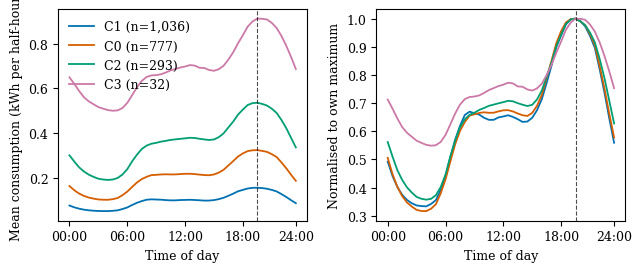

Saved figures/A0_cluster_profiles.pdf


In [100]:
# ============================================================
# Figure — Section 4.1: raw K-Means cluster mean profiles
# ============================================================
# Two-panel dissertation figure: (a) mean profiles in original units
# (kWh/half-hour), (b) the same profiles each normalised to its own maximum.
# Panel (b) is the key panel: the four curves nearly coincide once level is
# removed, i.e. the clusters differ in SCALE, not SHAPE (Result A).

import os
import numpy as np
import matplotlib.pyplot as plt

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')
T_STAR = 39                                          # system peak slot, 19:30

raw = profiles_original_clean.values.astype(float)   # kWh/half-hour, shape (n, 48)
labels = np.asarray(results_raw['K-Means'])
E = raw.sum(axis=1)                                  # daily kWh per household
# clusters ordered by ascending mean daily consumption: C1 < C0 < C2 < C3
cluster_ids = sorted(np.unique(labels), key=lambda c: E[labels == c].mean())

slots = np.arange(48)
tick_slots = [0, 12, 24, 36, 47]
tick_labels = ['00:00', '06:00', '12:00', '18:00', '24:00']

os.makedirs('figures', exist_ok=True)
with plt.rc_context({'font.family': 'serif', 'font.size': 9}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.5, 2.8))

    for i, c in enumerate(cluster_ids):
        mask = labels == c
        n_c = int(mask.sum())
        mean_profile = raw[mask].mean(axis=0)
        color = PALETTE[i % len(PALETTE)]
        label = f'C{int(c)} (n={n_c:,})'

        ax1.plot(slots, mean_profile, color=color, linewidth=1.3, label=label)
        ax2.plot(slots, mean_profile / mean_profile.max(), color=color,
                 linewidth=1.3, label=label)

    for ax in (ax1, ax2):
        ax.axvline(T_STAR, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
        ax.set_xticks(tick_slots)
        ax.set_xticklabels(tick_labels, fontsize=9)
        ax.set_xlabel('Time of day', fontsize=9)
        ax.tick_params(labelsize=9)

    ax1.set_ylabel('Mean consumption (kWh per half-hour)', fontsize=9)
    ax2.set_ylabel('Normalised to own maximum', fontsize=9)
    ax1.legend(fontsize=9, frameon=False)

    fig.tight_layout()
    fig.savefig('figures/A0_cluster_profiles.pdf')
    plt.show()

print('Saved figures/A0_cluster_profiles.pdf')


## Result A3i — cluster existence tests without outlier removal

In [101]:
# ============================================================
# Result A3i — cluster existence tests without outlier removal
# ============================================================
# The outlier filter removes households with any standardised first
# difference exceeding 4 sigma -- i.e. exactly the households with the
# SHARPEST profile transitions, who are the natural candidates for a
# SHAPE-based cluster. 293 of 2431 (12%) were removed before A3d concluded
# there is no shape structure (gap-optimal K=1, dip not rejected). This cell
# reruns those existence tests on the FULL 2431-household sample, before any
# outlier removal, and separately characterises the 293 removed households.
# Heavy step: gap statistic is ~8 K-values x 51 KMeans fits x 2 representations.

import os
import json
import subprocess
import sys
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, entropy
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, pairwise_distances

# --- persistent results container (reuse earlier definition) ----------------
try:
    RESULTS
except NameError:
    RESULTS = {}


def _jsonable(o):
    """Robust JSON fallback: numpy / pandas / datetime / set -> serialisable."""
    import datetime as _dt
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (_dt.date, _dt.datetime)):
        return o.isoformat()
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, 'to_dict'):
        return o.to_dict()
    if hasattr(o, 'item'):
        return o.item()
    return str(o)


try:
    save_result
except NameError:
    def save_result(path, value):
        """Store `value` in RESULTS at a dotted `path` and rewrite results.json."""
        node = RESULTS
        keys = path.split('.')
        for key in keys[:-1]:
            node = node.setdefault(key, {})
        node[keys[-1]] = value
        with open('results.json', 'w') as handle:
            json.dump(RESULTS, handle, indent=2, default=_jsonable)
        return value

try:
    from diptest import diptest
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'diptest'])
    from diptest import diptest

PALETTE = ('#0072B2', '#D55E00', '#009E73', '#CC79A7')
EPS = 1e-12
try:
    DATA_PATH
except NameError:
    DATA_PATH = '/content/drive/MyDrive/dissertation_data/'


# ============================================================
# 1. Load the FULL pre-outlier-removal sample
# ============================================================
profiles_full = pd.read_parquet(os.path.join(DATA_PATH, 'processed', 'profiles_48.parquet'))
outlier_ids = profiles_full.index.difference(profiles_original_clean.index)
n_full = int(len(profiles_full))
n_outliers = int(len(outlier_ids))
print(f'A3i -- full sample: {n_full} households ({n_outliers} removed as '
      f'outliers by the 4-sigma delta filter, {n_outliers / n_full * 100:.1f}%; '
      f'expected 293 of 2431, ~12.1%)')

raw_full = profiles_full.values.astype(float)                  # kWh/half-hour
E_full = raw_full.sum(axis=1)                                  # daily kWh


# ============================================================
# 2. Three representations on the full sample
# ============================================================
sum_norm_full = raw_full / np.clip(raw_full.sum(axis=1, keepdims=True), EPS, None)


def clr_transform(comp, floor=None):
    """Centred log-ratio of a composition matrix (optional clip floor)."""
    x = np.clip(comp, floor, None) if floor is not None else comp
    log_x = np.log(x)
    return log_x - log_x.mean(axis=1, keepdims=True)


def multiplicative_replacement(comp, dl):
    """Martin-Fernandez et al. (2003) multiplicative zero replacement (A3b)."""
    out = comp.astype(float).copy()
    for i in range(out.shape[0]):
        row = out[i]
        small = row < dl
        if not small.any():
            continue
        replaced_mass = int(small.sum()) * dl
        row[~small] = row[~small] * (1.0 - replaced_mass)
        row[small] = dl
        out[i] = row
    return out


n_hh_with_zero = int(np.any(raw_full == 0, axis=1).sum())
dl_full = 0.65 * float(sum_norm_full[sum_norm_full > 0].min())
n_rows_replaced = int(np.any(sum_norm_full < dl_full, axis=1).sum())
print(f'  households with >=1 zero half-hour (full sample) = {n_hh_with_zero}')
print(f'  detection limit dl = {dl_full:.3e}; rows affected by replacement = '
      f'{n_rows_replaced} ({n_rows_replaced / n_full * 100:.1f}%)')

sum_norm_full_mr = multiplicative_replacement(sum_norm_full, dl_full)
clr_full = clr_transform(sum_norm_full_mr)

x_std_raw_full = StandardScaler().fit_transform(raw_full)
x_std_clr_full = StandardScaler().fit_transform(clr_full)
reps_full = {'raw': x_std_raw_full, 'CLR': x_std_clr_full}


# --- helpers, same construction as A3d ---------------------------------------
def holm(pvals):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(pvals, dtype=float)
    m = p.size
    order = np.argsort(p)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adj[idx] = min(running, 1.0)
    return adj


def gap_statistic(mat, k_values=range(1, 9), n_ref=50, seed=42):
    """Gap statistic with a reference box aligned to the data's principal
    components (Tibshirani, Walther & Hastie 2001, variant b); same
    construction as A3d. Returns (table, chosen_K).
    """
    k_values = list(k_values)
    log_w = np.array([
        np.log(KMeans(n_clusters=k, n_init=10, random_state=42).fit(mat).inertia_)
        for k in k_values])
    centre = mat.mean(axis=0)
    centred = mat - centre
    _, _, vt = np.linalg.svd(centred, full_matrices=False)
    principal = centred @ vt.T
    lo, hi = principal.min(axis=0), principal.max(axis=0)
    rng = np.random.default_rng(seed)
    ref_log_w = np.empty((n_ref, len(k_values)))
    for b in range(n_ref):
        z_principal = rng.uniform(lo, hi, size=principal.shape)
        z = z_principal @ vt + centre
        for j, k in enumerate(k_values):
            ref_log_w[b, j] = np.log(
                KMeans(n_clusters=k, n_init=10, random_state=42).fit(z).inertia_)
    exp_log_w = ref_log_w.mean(axis=0)
    s_k = ref_log_w.std(axis=0) * np.sqrt(1.0 + 1.0 / n_ref)
    gap = exp_log_w - log_w
    chosen = k_values[-1]
    for j in range(len(k_values) - 1):
        if gap[j] >= gap[j + 1] - s_k[j + 1]:
            chosen = k_values[j]
            break
    table = pd.DataFrame({'K': k_values, 'logW': log_w.round(4),
                          'E*logW': exp_log_w.round(4), 'Gap': gap.round(4),
                          's_k': s_k.round(4)}).set_index('K')
    return table, int(chosen)


def dip_projections(mat):
    """Dip test on 5 PCs + the max-separation centroid axis; Holm over 6
    tests. Same construction as A3d.
    """
    pcs = PCA(n_components=5, random_state=42).fit_transform(mat)
    centres = KMeans(n_clusters=4, n_init=10, random_state=42).fit(mat).cluster_centers_
    d = pairwise_distances(centres)
    a, b = np.unravel_index(np.argmax(d), d.shape)
    axis = centres[a] - centres[b]
    axis = axis / np.linalg.norm(axis)
    projections = {f'PC{i + 1}': pcs[:, i] for i in range(5)}
    projections['centroid_axis'] = mat @ axis
    names = list(projections)
    stats_, raw_p = [], []
    for nm in names:
        dip_stat, p_val = diptest(np.asarray(projections[nm], dtype=float))
        stats_.append(float(dip_stat))
        raw_p.append(float(p_val))
    adj_p = holm(raw_p)
    table = pd.DataFrame({'projection': names, 'dip': np.round(stats_, 4),
                          'p_raw': np.round(raw_p, 4),
                          'p_holm': np.round(adj_p, 4)}).set_index('projection')
    best_idx = int(np.argmin(adj_p))
    return table, names[best_idx], float(adj_p[best_idx])


# ============================================================
# 3. Gap statistic, full sample vs the A3d 2138-household reference
# ============================================================
gap_full = {}
print('\nCHECK 1 -- gap statistic (PCA-aligned box, 50 references), '
      'FULL 2431-household sample:')
for name, mat in reps_full.items():
    table, chosen = gap_statistic(mat, range(1, 9), n_ref=50, seed=42)
    gap_full[name] = {'table': table, 'optimal_K': chosen}
    ref_k = RESULTS.get('A3d', {}).get('gap', {}).get(name, {}).get('optimal_K', 'n/a')
    print(f'\n  {name} (n=2431) -- gap-optimal K = {chosen} '
          f'(A3d reference, n=2138: K = {ref_k})')
    print(table.to_string())


# ============================================================
# 4. Dip test, full sample vs the A3d 2138-household reference
# ============================================================
dip_full = {}
print('\nCHECK 2 -- Hartigan dip test (Holm over 6 projections), FULL sample:')
for name, mat in reps_full.items():
    table, best_proj, best_p = dip_projections(mat)
    dip_full[name] = {'table': table, 'best_projection': best_proj, 'best_p_holm': best_p}
    ref_p = RESULTS.get('A3d', {}).get('dip', {}).get(name, {}).get('best_p_holm', 'n/a')
    ref_p_str = f'{ref_p:.4f}' if isinstance(ref_p, (int, float)) else str(ref_p)
    print(f'\n  {name} (n=2431) -- best direction {best_proj}, Holm p = '
          f'{best_p:.4f} (A3d reference, n=2138: p = {ref_p_str})')
    print(table.to_string())


# ============================================================
# 5. Does Result A (level == sorting) survive without outlier removal?
# ============================================================
def quantile_partition(e, sizes):
    """Consecutive ascending-E bands of the given sizes; label per household."""
    e = np.asarray(e)
    order_idx = np.argsort(e, kind='stable')
    labels = np.empty(e.shape[0], dtype=int)
    start = 0
    for band, size in enumerate(sizes):
        labels[order_idx[start:start + size]] = band
        start += size
    return labels


km4_full = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(x_std_raw_full)
order = sorted(np.unique(km4_full), key=lambda c: E_full[km4_full == c].mean())
sizes_asc = [int(np.sum(km4_full == c)) for c in order]
band_full = quantile_partition(E_full, sizes_asc)
ari_level_full = float(adjusted_rand_score(km4_full, band_full))
print(f'\nCHECK 3 -- Result A survival check: ARI(K-Means K=4, size-matched E) '
      f'on the full 2431-household sample = {ari_level_full:.4f} '
      f'(2138-household reference ~0.9620)')


# ============================================================
# 6. Characterise the 293 removed households: shape, not just amplitude?
# ============================================================
P_full = raw_full / np.clip(raw_full.sum(axis=1, keepdims=True), EPS, None)
outlier_mask_full = profiles_full.index.isin(outlier_ids)
peak = P_full.max(axis=1)
descriptors_full = {
    'load_factor': P_full.mean(axis=1) / np.clip(peak, EPS, None),
    'evening_share': P_full[:, 34:44].sum(axis=1),
    'night_share': P_full[:, 0:12].sum(axis=1),
    'peak_slot': P_full.argmax(axis=1).astype(float),
    'profile_entropy': entropy(P_full + EPS, axis=1),
}
n1, n2 = int(outlier_mask_full.sum()), int((~outlier_mask_full).sum())
desc_rows, raw_p_desc = [], []
for name, values in descriptors_full.items():
    x, y = values[outlier_mask_full], values[~outlier_mask_full]
    u_stat, p_val = mannwhitneyu(x, y, alternative='two-sided')
    cles = u_stat / (n1 * n2)                       # P(removed > kept)
    rbc = 2.0 * cles - 1.0                          # rank-biserial correlation
    raw_p_desc.append(p_val)
    desc_rows.append({'descriptor': name, 'median_removed': float(np.median(x)),
                      'median_kept': float(np.median(y)), 'U': float(u_stat),
                      'p_raw': float(p_val), 'rank_biserial': float(rbc)})
for row, ph in zip(desc_rows, holm(raw_p_desc)):
    row['p_holm'] = float(ph)
    row['significant'] = bool(ph < 0.05)
desc_table_removed = pd.DataFrame(desc_rows).set_index('descriptor')
print(f'\nCHECK 4 -- the {n1} removed households vs the {n2} kept, shape '
      f'descriptors (Mann-Whitney U, Holm over 5):')
print(desc_table_removed.round(4).to_string())

sig_removed = desc_table_removed[desc_table_removed['significant']]
if len(sig_removed):
    parts = [f'{nm} ({"higher" if r.median_removed > r.median_kept else "lower"} in removed)'
             for nm, r in sig_removed.iterrows()]
    removed_shape_verdict = ('the 293 removed households ARE shape-distinct: '
                             + ', '.join(parts))
else:
    removed_shape_verdict = ('the 293 removed households are NOT shape-distinct on '
                             'these descriptors after Holm correction -- their removal '
                             'is an amplitude/outlier cut, not a shape cut.')
print('  ->', removed_shape_verdict)


# ============================================================
# 7. VERDICT, chosen by the numbers
# ============================================================
gap_ones = all(v['optimal_K'] == 1 for v in gap_full.values())
dip_rejects = {name: v['best_p_holm'] < 0.05 for name, v in dip_full.items()}
any_dip_rejects = any(dip_rejects.values())
if gap_ones and not any_dip_rejects:
    verdict = ('the conclusion is unchanged without outlier removal: gap-optimal '
               'K = 1 and unimodality is not rejected in either representation on '
               'the full 2,431 households.')
else:
    rejected = [f'{name} (p={v["best_p_holm"]:.4f})'
                for name, v in dip_full.items() if v['best_p_holm'] < 0.05]
    ks = {name: v['optimal_K'] for name, v in gap_full.items()}
    verdict = (f'the conclusion CHANGES: on the full sample gap selects K = {ks}, '
               f'and the dip test rejects unimodality in '
               f'{", ".join(rejected) if rejected else "no"} projection(s). The '
               f'outlier filter was materially shaping the A3d result -- this must '
               f'be stated plainly in the text, not softened.')
print('\nVERDICT:')
print(' ', verdict)


# ============================================================
# PERSIST
# ============================================================
save_result('A3i.n_full', n_full)
save_result('A3i.n_outliers', n_outliers)
save_result('A3i.outlier_fraction', n_outliers / n_full)
save_result('A3i.n_households_with_zero_halfhour', n_hh_with_zero)
save_result('A3i.detection_limit', dl_full)
save_result('A3i.n_rows_replaced', n_rows_replaced)
for name, v in gap_full.items():
    save_result(f'A3i.gap.{name}.optimal_K', v['optimal_K'])
    save_result(f'A3i.gap.{name}.table', v['table'].reset_index().to_dict(orient='list'))
for name, v in dip_full.items():
    save_result(f'A3i.dip.{name}.best_projection', v['best_projection'])
    save_result(f'A3i.dip.{name}.best_p_holm', v['best_p_holm'])
    save_result(f'A3i.dip.{name}.table', v['table'].reset_index().to_dict(orient='list'))
save_result('A3i.ari_level_full', ari_level_full)
for name, r in desc_table_removed.iterrows():
    save_result(f'A3i.removed_vs_kept.{name}.median_removed', float(r['median_removed']))
    save_result(f'A3i.removed_vs_kept.{name}.median_kept', float(r['median_kept']))
    save_result(f'A3i.removed_vs_kept.{name}.p_raw', float(r['p_raw']))
    save_result(f'A3i.removed_vs_kept.{name}.p_holm', float(r['p_holm']))
    save_result(f'A3i.removed_vs_kept.{name}.rank_biserial', float(r['rank_biserial']))
    save_result(f'A3i.removed_vs_kept.{name}.significant', bool(r['significant']))
save_result('A3i.removed_shape_verdict', removed_shape_verdict)
save_result('A3i.verdict.gap_ones', bool(gap_ones))
save_result('A3i.verdict.any_dip_rejects', bool(any_dip_rejects))
save_result('A3i.verdict.text', verdict)


A3i -- full sample: 2431 households (293 removed as outliers by the 4-sigma delta filter, 12.1%; expected 293 of 2431, ~12.1%)
  households with >=1 zero half-hour (full sample) = 1
  detection limit dl = 7.917e-05; rows affected by replacement = 1 (0.0%)

CHECK 1 -- gap statistic (PCA-aligned box, 50 references), FULL 2431-household sample:

  raw (n=2431) -- gap-optimal K = 3 (A3d reference, n=2138: K = 1)
      logW   E*logW     Gap     s_k
K                                  
1  11.6673  14.3352  2.6679  0.0114
2  11.1528  13.9758  2.8231  0.0120
3  10.8688  13.7220  2.8532  0.0090
4  10.6570  13.5133  2.8562  0.0071
5  10.4832  13.4393  2.9561  0.0060
6  10.3586  13.3737  3.0152  0.0061
7  10.2742  13.3221  3.0479  0.0057
8  10.2045  13.2766  3.0722  0.0060

  CLR (n=2431) -- gap-optimal K = 1 (A3d reference, n=2138: K = 1)
      logW   E*logW     Gap     s_k
K                                  
1  11.6673  14.5192  2.8519  0.0093
2  11.4417  14.2646  2.8229  0.0091
3  11.2925  14.0

"the conclusion CHANGES: on the full sample gap selects K = {'raw': 3, 'CLR': 1}, and the dip test rejects unimodality in no projection(s). The outlier filter was materially shaping the A3d result -- this must be stated plainly in the text, not softened."